# D4 Medellín — ruteo con energía

Mismo método que `D4_grafo_ruteo.ipynb` de Bogotá, aplicado al grafo de Medellín. **No
modifica nada de Bogotá** ni reprocesa los bloques A y B: los lee y verifica por su huella.

**Qué es igual a Bogotá** (se toma de las mismas constantes de D4):

| Tema | Método |
|---|---|
| Consumo | Modelo de consumo, capa 1 (física del carro) + capa 2 (arrancar y frenar), sin modificar su código |
| Comparación central | Ruta más corta contra ruta de mínimo consumo (k = 0, sin castigo) |
| Tramos de más de 35 % | Se mantienen en la red. Escenario con restricción de pendiente: castigo k = 50 al rutear, el mismo de Bogotá. Sensibilidades: k = 1 (lo que da la regla con datos de Medellín) y bloquear los tramos de más de 35 % |
| Calles sin altura | No se quitan; su altura se estima desde las esquinas vecinas (opción 1) |
| Calles sin sentido conocido | Doble sentido |
| Red oficial | `sens_sin_altura_A`; los otros 4 escenarios como sensibilidad |
| Corridas | Muestra estratificada de 4.200 viajes (3 terrenos × 4 bandas × 350, semilla 20261026), 12 carros, 5 franjas, pendiente de esquina a esquina, longitud inclinada. Las corridas de 12 carros, franjas y alcanzabilidad se hacen con k = 50; las cifras con k = 0 salen de las celdas 13d y 20b. Las cifras de toda la ciudad se ponderan (celda 20b) |
| Alcanzabilidad | Batería 20 / 50 / 80 %, reserva 10 %. La versión pesimista (× 1,40 al consumo de los tramos que gastan) es solo sensibilidad |
| Segunda estratificación | Ascenso por km en línea recta de cada viaje (módulo de terreno). Tres grupos con los mismos cortes en las dos ciudades: bajo < 7,6, medio 7,6–30,3 y alto ≥ 30,3 m/km (terciles ponderados de las dos ciudades juntas; el cálculo usa los valores exactos de `CORTES_ASCENSO_M_KM`). Celda 20e |

**Qué cambia en Medellín:**

- **Insumos:** `entregables/D3_medellin/rama_med_sigma054/` (D3M, σz = 0,539 m, ancho de
  correlación 59,2 m) y las esquinas de `entregables/D2_medellin/nodos_medellin.csv`. Las
  esquinas de Medellín se unieron a 2 m en D2M, así que **no se recalculan**: se validan contra ese archivo.
- **Velocidad:** por tipo de vía (continuo / interrumpido) y franja, de
  `franjas_medellin.py` del modelo de consumo. El tipo de vía sale del **nombre** de la calle:
  los corredores continuos son los de `CORREDORES_CONTINUOS_MED` y el resto se trata como interrumpido.
- **Aire:** densidad de Medellín (1.495 m), `ciudad = "medellin"`.
- **Calle "rural":** jerarquía 6 o 7 (en Bogotá era `highway == "rural"`).
- **Puentes y túneles:** un tramo de más de 35 % sobre puente o túnel solo cuenta si su
  pendiente neta también pasa de 35 % (regla El Tambor).
- **Estaciones:** 19 de B2.1; se quita en D4M el cargador de bicicletas
  (`way/770877089`) → 18. Voltex Autopista Norte queda como B la dejó (dos puntos).
- **Salidas:** `entregables/D4_medellin/`. Nada se reescribe: si un archivo existe con
  otro contenido, el cuaderno se detiene.

In [1]:
# =============================================================================
# D4M — CELDA 1: INSUMOS Y VERIFICACION
# Lee de disco. Escribe SOLO en entregables/D4_medellin. No modifica D2M ni D3M.
# Ningun archivo se reescribe: si existe con otro contenido, se detiene.
# =============================================================================
import json, hashlib
from datetime import datetime

import numpy as np
import pandas as pd
import geopandas as gpd
import shapely

import constantes_d1 as K
import d2_medellin as d2m                    # la huella con la que D2M y D3M registraron el grafo
from d1_procedencia import sha256_archivo, ZONA_BOGOTA

SELLO = datetime.now(ZONA_BOGOTA).strftime("%Y%m%d_%H%M%S")
D4M = "D4_medellin"                          # carpeta de salidas (dentro de entregables)

# --- Utilidades --------------------------------------------------------------
def _a_bool(s):
    """Booleanos leidos de GPKG/CSV ('True'/'False', 1/0, bool) -> bool o NaN."""
    return s.map({True: True, False: False, "True": True, "False": False,
                  "true": True, "false": False, 1: True, 0: False})

def guardar_csv_sin_sobrescribir(df, ruta):
    """Escribe el CSV solo si no existe. Si existe e igual, no lo toca.
    Si existe y es distinto, se detiene: nada se reescribe en silencio."""
    contenido = df.to_csv(index=False, float_format="%.6f",
                          lineterminator="\n").encode("utf-8")
    nuevo = hashlib.sha256(contenido).hexdigest()
    if ruta.exists():
        viejo = sha256_archivo(ruta)
        if viejo == nuevo:
            print(f"  [ya existe, identico] {ruta.name}")
            return nuevo
        raise FileExistsError(
            f"{ruta.name} ya existe con OTRO contenido.\n"
            f"  en disco: {viejo[:12]}...  nuevo: {nuevo[:12]}...\n"
            "No se reescribe. Revise que cambio antes de moverlo a mano.")
    ruta.write_bytes(contenido)
    print(f"  [escrito] {ruta.name}  sha {nuevo[:12]}...")
    return nuevo

def guardar_texto_sin_sobrescribir(texto, ruta):
    """Igual que guardar_csv_sin_sobrescribir, para JSON u otro texto."""
    contenido = texto.encode("utf-8")
    nuevo = hashlib.sha256(contenido).hexdigest()
    if ruta.exists():
        viejo = sha256_archivo(ruta)
        if viejo == nuevo:
            print(f"  [ya existe, identico] {ruta.name}")
            return nuevo
        raise FileExistsError(f"{ruta.name} ya existe con OTRO contenido. No se reescribe.")
    ruta.write_bytes(contenido)
    print(f"  [escrito] {ruta.name}  sha {nuevo[:12]}...")
    return nuevo

# --- 0. La rama oficial de Medellin tiene que estar declarada en constantes_d1 ---
assert K.RAMA_OFICIAL_MED in K.RAMAS_PENDIENTE_MED, f"Rama desconocida: {K.RAMA_OFICIAL_MED}"
RAMA = K.RAMA_OFICIAL_MED
assert np.isclose(K.RAMAS_PENDIENTE_MED[RAMA]["sigma_z_m"], K.SIGMA_Z_ADOPTADO_MED_M), \
    "La rama de Medellin y SIGMA_Z_ADOPTADO_MED_M no coinciden."

# Rutas de LECTURA: se arman sin crear carpetas.
DIR_D2M = K.RUTA_ENTREGABLES / "D2_medellin"
DIR_D3M = K.RUTA_ENTREGABLES / "D3_medellin" / f"rama_{RAMA}"
RUTA_HUE_D2M = DIR_D2M / "D2M_huellas_salidas.json"
RUTA_NODOS   = DIR_D2M / "nodos_medellin.csv"
RUTA_GPKG_D3 = DIR_D3M / f"D3M_grafo_con_pendiente_{RAMA}.gpkg"
RUTA_CSV_D3  = DIR_D3M / f"D3M_grafo_con_pendiente_{RAMA}.csv"
RUTA_HUE_D3  = DIR_D3M / f"D3M_huellas_salidas_{RAMA}.json"
for _r in (RUTA_HUE_D2M, RUTA_NODOS, RUTA_GPKG_D3, RUTA_CSV_D3, RUTA_HUE_D3):
    assert _r.exists(), f"Falta insumo: {_r}"

hue_d2 = json.loads(RUTA_HUE_D2M.read_text(encoding="utf-8"))
hue_d3 = json.loads(RUTA_HUE_D3.read_text(encoding="utf-8"))

pr = []   # pruebas de insumos

# --- 1. Las huellas de D3M dicen lo que D4M espera -----------------------------
pr.append({"prueba": "huellas D3M: rama y sigma_z = los adoptados",
           "pasa": hue_d3["rama"] == RAMA
                   and np.isclose(hue_d3["sigma_z_m"], K.SIGMA_Z_ADOPTADO_MED_M)})

# --- 2. Cadena D2M -> D3M: D3M se hizo sobre el grafo que D2M registro ----------
_h_d2 = hue_d2["huella_segmentos_gpkg"]
pr.append({"prueba": "cadena D2M -> D3M (huella de segmentos)",
           "pasa": hue_d3["insumos"]["huella_segmentos_d2m"] == _h_d2})

# --- 3. El CSV de D3M es el que D3M registro (sha256 del archivo) ---------------
SHA_CSV_D3 = sha256_archivo(RUTA_CSV_D3)
pr.append({"prueba": "sha256 del CSV de D3M",
           "pasa": SHA_CSV_D3 == hue_d3["archivos"][RUTA_CSV_D3.name]})

# --- 4. Las esquinas son las que D2M registro ------------------------------------
SHA_NODOS = sha256_archivo(RUTA_NODOS)
pr.append({"prueba": "sha256 de nodos_medellin.csv = el registrado por D2M",
           "pasa": SHA_NODOS == hue_d2["sha256_archivos"][RUTA_NODOS.name]})

# --- 5. El GPKG de D3M es el que D3M registro (huella de contenido) --------------
g = gpd.read_file(RUTA_GPKG_D3, layer="grafo")
g["segmento_id"] = g["segmento_id"].astype("string")
HUELLA_D3 = d2m.huella_segmentos(g)
pr.append({"prueba": "huella de contenido del GPKG de D3M",
           "pasa": HUELLA_D3 == hue_d3["contenido"][RUTA_GPKG_D3.name]})
pr.append({"prueba": "CRS = CRS_METRICO",
           "pasa": g.crs is not None and g.crs.to_string() == K.CRS_METRICO})

# --- 6. Columnas necesarias ---------------------------------------------------
NECESARIAS = ["segmento_id", "id_eje", "parte", "sentido_arista", "u", "v", "nivel_u",
              "nivel_v", "longitud_m", "jerarquia_op", "jerarquia", "nombre",
              "en_componente_fuerte", "sentido_asumido", "es_elevado", "es_tunel",
              "paso_nivel", "pendiente_neta_pct", "pendiente_extrema", "fuera_cobertura_mdt",
              "z_inicio_m", "z_fin_m", "ganancia_elevacion_m", "perdida_elevacion_m"]
_faltan = [c for c in NECESARIAS if c not in g.columns]
pr.append({"prueba": "columnas necesarias presentes", "faltan": _faltan, "pasa": not _faltan})
assert not _faltan, f"Faltan columnas: {_faltan}\nColumnas: {list(g.columns)}"

# Banderas a booleano real
for _c in ["en_componente_fuerte", "sentido_asumido", "fuera_cobertura_mdt",
           "es_elevado", "es_tunel"]:
    g[_c] = _a_bool(g[_c])
    assert g[_c].notna().all(), f"{_c} tiene valores no booleanos"
g["pendiente_extrema"] = _a_bool(g["pendiente_extrema"])
for _c in ["id_eje", "parte", "u", "v", "nombre", "jerarquia"]:
    g[_c] = g[_c].astype("string")
# Mismos nombres de columna que el metodo de Bogota (solo alias; no cambia datos)
g["sentido_recorrido"] = g["sentido_arista"].astype("string")
g["sentido_supuesto"] = g["sentido_asumido"]

# --- 7. Segundo camino: GPKG y CSV de D3M dicen lo mismo -----------------------
_csv = (pd.read_csv(RUTA_CSV_D3,
                    dtype={"segmento_id": "string", "fuera_cobertura_mdt": "string",
                           "u": "string", "v": "string"},
                    usecols=["segmento_id", "u", "v", "pendiente_neta_pct",
                             "fuera_cobertura_mdt", "longitud_m"],
                    low_memory=False)
        .set_index("segmento_id").sort_index())
_gi = g.set_index("segmento_id").sort_index()
_ids_ok = _csv.index.equals(_gi.index)
_ok = (_ids_ok
       and np.allclose(_csv["pendiente_neta_pct"].fillna(-9999), _gi["pendiente_neta_pct"].fillna(-9999))
       and np.allclose(_csv["longitud_m"], _gi["longitud_m"])
       and (_csv["u"] == _gi["u"]).all() and (_csv["v"] == _gi["v"]).all()
       and (_a_bool(_csv["fuera_cobertura_mdt"]) == _gi["fuera_cobertura_mdt"]).all())
pr.append({"prueba": "GPKG = CSV de D3M (ids, u, v, longitud, pendiente, cobertura)",
           "pasa": bool(_ok)})

# --- 8. Segundo camino: longitud_m = largo de la geometria --------------------
assert (g.geom_type == "LineString").all(), "Hay geometrias que no son LineString"
_mal_long = int((~np.isclose(g.geometry.length, g["longitud_m"], atol=1e-3)).sum())
pr.append({"prueba": "longitud_m = largo de la geometria (EPSG:9377)",
           "n_distintas": _mal_long, "pasa": _mal_long == 0})

# --- 9. Esquinas: u, v existen en nodos_medellin.csv y todas se usan ------------
# En Medellin las esquinas se unieron a 2 m en D2M: NO se recalculan, se validan.
NODOS = (pd.read_csv(RUTA_NODOS, dtype={"node_id": "string"})
         .rename(columns={"node_id": "nodo"})[["nodo", "x", "y", "nivel"]]
         .sort_values("nodo").reset_index(drop=True))
N_NODOS_D4 = len(NODOS)
_usados = set(g["u"]) | set(g["v"])
pr.append({"prueba": "u, v de D3M = esquinas de nodos_medellin.csv (todas, sin sobrantes)",
           "n_nodos": N_NODOS_D4, "n_usados": len(_usados),
           "pasa": NODOS["nodo"].is_unique and _usados == set(NODOS["nodo"])})

# --- 10. Segundo camino: la geometria empieza en u y termina en v ---------------
# Cada extremo queda a menos de la tolerancia de fusion de D2M de su esquina.
TOL_FUSION_M = float(hue_d2["fusion_nodos"]["tolerancia_m"])
_xy = NODOS.set_index("nodo")[["x", "y"]]
_geoms = np.asarray(g.geometry.values)
_ini = np.c_[shapely.get_x(shapely.get_point(_geoms, 0)), shapely.get_y(shapely.get_point(_geoms, 0))]
_fin = np.c_[shapely.get_x(shapely.get_point(_geoms, -1)), shapely.get_y(shapely.get_point(_geoms, -1))]
_du = np.hypot(*(_ini - _xy.loc[g["u"]].to_numpy()).T)
_dv = np.hypot(*(_fin - _xy.loc[g["v"]].to_numpy()).T)
pr.append({"prueba": f"la geometria va de u a v (extremos a < {TOL_FUSION_M:g} m de su esquina)",
           "desfase_max_m": float(max(_du.max(), _dv.max())),
           "pasa": bool(max(_du.max(), _dv.max()) <= TOL_FUSION_M + 1e-6)})

# --- 11. Nivel de cada esquina = nivel_u / nivel_v de sus aristas ---------------
_niv = NODOS.set_index("nodo")["nivel"]
_mal_niv = int((g["u"].map(_niv) != g["nivel_u"]).sum() + (g["v"].map(_niv) != g["nivel_v"]).sum())
pr.append({"prueba": "nivel de la esquina = nivel_u / nivel_v de la arista",
           "n_distintas": _mal_niv, "pasa": _mal_niv == 0})

# --- Resumen ------------------------------------------------------------------
PRUEBAS_INSUMOS = pd.DataFrame(pr)
PRUEBAS_INSUMOS["resultado"] = np.where(PRUEBAS_INSUMOS["pasa"], "PASA", "FALLA")
print(PRUEBAS_INSUMOS[["prueba", "resultado"]].to_string(index=False))
print(f"\nRama: {RAMA}  (sigma_z = {K.SIGMA_Z_ADOPTADO_MED_M} m)")
print(f"Aristas: {len(g):,}   Esquinas: {N_NODOS_D4:,}   "
      f"km fisicos: {g.drop_duplicates(['id_eje', 'parte'])['longitud_m'].sum() / 1000:,.1f}")
_fallan = PRUEBAS_INSUMOS.loc[~PRUEBAS_INSUMOS["pasa"], "prueba"].tolist()
assert not _fallan, f"Insumos NO validos. Fallan: {_fallan}"

BITACORA = {"cuaderno": "D4 Medellin — ruteo con energia",
            "sello_ejecucion": SELLO,
            "rama": RAMA, "sigma_z_m": K.SIGMA_Z_ADOPTADO_MED_M,
            "insumos": {"huella_segmentos_d2m": _h_d2,
                        "huella_gpkg_d3m": HUELLA_D3,
                        "sha256_csv_d3m": SHA_CSV_D3,
                        "sha256_nodos": SHA_NODOS},
            "pruebas_insumos": pr}

                                                             prueba resultado
                        huellas D3M: rama y sigma_z = los adoptados      PASA
                            cadena D2M -> D3M (huella de segmentos)      PASA
                                              sha256 del CSV de D3M      PASA
               sha256 de nodos_medellin.csv = el registrado por D2M      PASA
                                huella de contenido del GPKG de D3M      PASA
                                                  CRS = CRS_METRICO      PASA
                                      columnas necesarias presentes      PASA
      GPKG = CSV de D3M (ids, u, v, longitud, pendiente, cobertura)      PASA
                     longitud_m = largo de la geometria (EPSG:9377)      PASA
u, v de D3M = esquinas de nodos_medellin.csv (todas, sin sobrantes)      PASA
          la geometria va de u a v (extremos a < 2 m de su esquina)      PASA
               nivel de la esquina = nivel_u / nivel_v de la ari

# Diagnóstico de la red, la altura y los tramos sin altura

In [2]:
# =============================================================================
# D4M — CELDA 2: DIAGNOSTICO (no decide nada)
#   a) Tramos sin altura (fuera del MDT) y altura de cada esquina
#   b) Componente fuerte recalculada = la de D2M (networkx y scipy)
#   c) Tres tratamientos de los tramos sin altura (A / B / E), como en Bogota
#   d) Tramos > 35 %, tuneles, elevados y paso_nivel 2
# =============================================================================
import networkx as nx
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components

DIAG = f"{D4M}/diagnosticos"
SIN = g["fuera_cobertura_mdt"]
assert (SIN == g["pendiente_neta_pct"].isna()).all(), \
    "fuera_cobertura_mdt y pendiente_neta_pct vacia no coinciden"
g["calle"] = g["id_eje"] + "_" + g["parte"]
fis = g.drop_duplicates("calle")
fis_sin = g[SIN].drop_duplicates("calle")
_col, _vals = K.CRITERIO_RURAL_SIN_ALTURA_MED
RURAL = g[_col].isin(list(_vals))

# --- a) Tramos sin altura y altura de cada esquina ------------------------------
print("TRAMOS SIN ALTURA")
print(f"  aristas: {int(SIN.sum()):,} de {len(g):,}   calles: {len(fis_sin):,}   "
      f"km: {fis_sin['longitud_m'].sum() / 1000:,.2f} de {fis['longitud_m'].sum() / 1000:,.1f}")
if len(fis_sin):
    print(fis_sin[["calle", "nombre", "jerarquia", "longitud_m", "en_componente_fuerte"]]
          .to_string(index=False))

_con = g[~SIN]
_alt = pd.concat([
    pd.DataFrame({"nodo": _con["u"], "z": _con["z_inicio_m"], "calle": _con["calle"]}),
    pd.DataFrame({"nodo": _con["v"], "z": _con["z_fin_m"], "calle": _con["calle"]})],
    ignore_index=True)
ALT_NODO = _alt.groupby("nodo").agg(n_calles=("calle", "nunique"), z_min=("z", "min"),
                                   z_max=("z", "max"), z_mediana=("z", "median"))
ALT_NODO["dispersion_m"] = ALT_NODO["z_max"] - ALT_NODO["z_min"]
assert ALT_NODO["z_mediana"].notna().all(), "Hay esquinas con calles medidas pero sin z"
_varias = ALT_NODO[ALT_NODO["n_calles"] >= 2]
print(f"\nALTURA POR ESQUINA: {len(ALT_NODO):,} de {N_NODOS_D4:,} esquinas con altura medida")
print(f"  con 2 o mas calles: {len(_varias):,}; dispersion (max - min), percentiles (m):")
print(_varias["dispersion_m"].quantile([.5, .9, .99, 1]).round(3).to_string())

# --- b) Componente fuerte: reproducir D2M con dos librerias ----------------------
def componente_mayor(df):
    """Aristas cuyas dos esquinas estan en la componente fuerte mas grande (networkx)."""
    G = nx.DiGraph()
    G.add_edges_from(zip(df["u"], df["v"]))
    S = max(nx.strongly_connected_components(G), key=len)
    return (df["u"].isin(S) & df["v"].isin(S)), len(S)

def componente_mayor_scipy(df):
    """Lo mismo con scipy (implementacion independiente)."""
    nod = pd.Index(sorted(set(df["u"]) | set(df["v"])))
    iu, iv = nod.get_indexer(df["u"]), nod.get_indexer(df["v"])
    M = csr_matrix((np.ones(len(df)), (iu, iv)), shape=(len(nod), len(nod)))
    _, lab = connected_components(M, directed=True, connection="strong")
    S = set(nod[lab == np.bincount(lab).argmax()])
    return (df["u"].isin(S) & df["v"].isin(S)), len(S)

_comp, _n = componente_mayor(g)
_comp_sp, _n_sp = componente_mayor_scipy(g)
_dif = int((_comp != g["en_componente_fuerte"]).sum())
print(f"\nCOMPONENTE FUERTE recalculada: {int(_comp.sum()):,} aristas, {_n:,} esquinas; "
      f"distintas de la marca de D2M: {_dif}")
assert _dif == 0, "La componente recalculada NO coincide con la de D2M"
assert _n_sp == _n and (_comp_sp == _comp).all(), "networkx y scipy no coinciden"

# --- c) Tratamientos de los tramos sin altura ------------------------------------
TRATAMIENTOS = {"A_todo_pendiente_0": SIN & False, "B_excluir_todo": SIN,
                "E_excluir_rurales": SIN & RURAL}
filas = []
for nombre, excluir in TRATAMIENTOS.items():
    sub = g[~excluir]
    comp, n_esq = componente_mayor(sub)
    c2, n2 = componente_mayor_scipy(sub)
    assert n2 == n_esq and (c2 == comp).all(), f"{nombre}: networkx y scipy no coinciden"
    assert not (comp & ~sub["en_componente_fuerte"]).any(), f"{nombre}: entraron aristas nuevas"
    col = sub[sub["en_componente_fuerte"] & ~comp & ~sub["fuera_cobertura_mdt"]]
    filas.append({"tratamiento": nombre, "aristas_excluidas": int(excluir.sum()),
                  "aristas_con_pendiente_0": int((sub["fuera_cobertura_mdt"] & comp).sum()),
                  "colateral_aristas_con_altura": len(col),
                  "aristas_en_red": int(comp.sum()), "esquinas_en_red": n_esq})
COMPARA_SIN_ALTURA = pd.DataFrame(filas)
print("\nTRATAMIENTOS DE LOS TRAMOS SIN ALTURA")
print(COMPARA_SIN_ALTURA.set_index("tratamiento").T.to_string())
assert COMPARA_SIN_ALTURA.set_index("tratamiento").loc["A_todo_pendiente_0", "aristas_en_red"] \
    == int(g["en_componente_fuerte"].sum())

# --- d) Tramos > 35 %, tuneles, elevados ------------------------------------------
EXT0 = g["pendiente_extrema"].fillna(False).astype(bool)
_pn = pd.to_numeric(g["paso_nivel"], errors="coerce")
print(f"\nTRAMOS > {K.UMBRAL_PENDIENTE_EXTREMA_PCT:g} %: {int(EXT0.sum()):,} aristas "
      f"({g.loc[EXT0, 'calle'].nunique():,} calles); en la componente fuerte: "
      f"{int((EXT0 & g['en_componente_fuerte']).sum()):,}")
print(f"  sin jerarquia: {int((EXT0 & g['jerarquia'].isna()).sum()):,}   "
      f"tuneles: {int((EXT0 & g['es_tunel']).sum())}   elevados: {int((EXT0 & g['es_elevado']).sum())}")
print(f"Tuneles: {int(g['es_tunel'].sum())} aristas   elevados: {int(g['es_elevado'].sum())}   "
      f"paso_nivel = 2: {int((_pn == 2).sum())}   esquinas de nivel != 0: "
      f"{int((NODOS['nivel'] != 0).sum())}")

# --- Salidas (sin sobrescribir) ----------------------------------------------
HASH_DIAG = {}
HASH_DIAG["D4M_diag_altura_por_esquina.csv"] = guardar_csv_sin_sobrescribir(
    ALT_NODO.reset_index().sort_values("nodo"),
    K.ruta_entregable(DIAG, "D4M_diag_altura_por_esquina.csv"))
HASH_DIAG["D4M_diag_sin_altura_comparacion.csv"] = guardar_csv_sin_sobrescribir(
    COMPARA_SIN_ALTURA, K.ruta_entregable(DIAG, "D4M_diag_sin_altura_comparacion.csv"))
HASH_DIAG["D4M_diag_tramos_extremos.csv"] = guardar_csv_sin_sobrescribir(
    g.loc[EXT0, ["segmento_id", "calle", "nombre", "jerarquia", "longitud_m",
                 "pendiente_neta_pct", "es_tunel", "es_elevado", "en_componente_fuerte"]]
    .sort_values("segmento_id").reset_index(drop=True),
    K.ruta_entregable(DIAG, "D4M_diag_tramos_extremos.csv"))
BITACORA["diagnosticos"] = HASH_DIAG
BITACORA["prueba_componente_d2m"] = {"aristas_dentro": int(_comp.sum()), "esquinas": _n}

TRAMOS SIN ALTURA
  aristas: 2 de 39,160   calles: 1   km: 4.76 de 2,232.4
   calle             nombre           jerarquia  longitud_m  en_componente_fuerte
119699_0 Antigua via al mar 2-Arteria Principal 4764.159437                  True

ALTURA POR ESQUINA: 16,396 de 16,396 esquinas con altura medida
  con 2 o mas calles: 14,518; dispersion (max - min), percentiles (m):
0.50    0.000
0.90    0.000
0.99    0.000
1.00    0.614

COMPONENTE FUERTE recalculada: 38,826 aristas, 16,156 esquinas; distintas de la marca de D2M: 0

TRATAMIENTOS DE LOS TRAMOS SIN ALTURA
tratamiento                   A_todo_pendiente_0  B_excluir_todo  E_excluir_rurales
aristas_excluidas                              0               2                  0
aristas_con_pendiente_0                        2               0                  2
colateral_aristas_con_altura                   0               0                  0
aristas_en_red                             38826           38824              38826
esquinas_en_r

# Estaciones de carga: insumos y revisión

In [3]:
# =============================================================================
# D4M — CELDA 3: ESTACIONES — insumos, union y enganche PARA REVISAR (no decide)
# Localiza los archivos de A y B por nombre y usa SOLO la copia con el hash
# registrado (B3). Coordenadas de OCM (A3) y OSM (A2) por registro de B2.1.
# =============================================================================
def localizar(nombre, sha_esperado=None):
    """Busca 'nombre' bajo las carpetas de los bloques A y B. Con hash, devuelve
    solo una copia con ese hash (la primera en orden alfabetico)."""
    hallados = []
    for base in K.CARPETAS_BLOQUES_AB:
        assert base.exists(), (f"No existe {base}. Revise CARPETAS_BLOQUES_AB en "
                               "constantes_d1.py (se asume carpeta hermana).")
        hallados += list(base.rglob(nombre))
    hallados = sorted(hallados, key=str)
    assert hallados, f"No se encontro {nombre} bajo {K.CARPETAS_BLOQUES_AB}"
    if sha_esperado is None:
        assert len(hallados) == 1, f"{nombre}: {len(hallados)} copias y sin hash para elegir"
        return hallados[0], hallados
    buenos = [p for p in hallados if sha256_archivo(p) == sha_esperado]
    assert buenos, (f"{nombre}: {len(hallados)} copia(s) en disco y NINGUNA con el "
                    f"hash registrado {sha_esperado[:12]}...")
    return buenos[0], hallados

# --- 1. Manifiesto de B3 = constantes_d1; localizar y verificar ----------------
RUTA_MAN_B3, _ = localizar(K.MANIFIESTO_REFERENCIA_ESTACIONES)
_man_b3 = json.loads(RUTA_MAN_B3.read_text(encoding="utf-8"))
for _n, _h in K.INSUMOS_ESTACIONES_D4M.items():
    assert _man_b3.get(_n) == _h, f"{_n}: constantes_d1 y el manifiesto de B3 no coinciden"
RUTAS_EST = {}
for _n, _h in K.INSUMOS_ESTACIONES_D4M.items():
    RUTAS_EST[_n], _todas = localizar(_n, _h)
    print(f"  [hash OK] {_n}" + (f"  ({len(_todas)} copias; se usa la de hash correcto)"
                                 if len(_todas) > 1 else ""))
BITACORA["insumos_estaciones"] = {n: {"sha256": h, "ruta": str(RUTAS_EST[n].relative_to(K.RUTA_TESIS))}
                                  for n, h in K.INSUMOS_ESTACIONES_D4M.items()}

INV = pd.read_csv(RUTAS_EST["B2_1_clasificacion_verificada.csv"], encoding="utf-8-sig",
                  dtype={"ocm_id": "string", "osm_uid": "string"})
RUTA_AUD_B21, _ = localizar("B2_1_auditoria_procesamiento.json")
_aud = json.loads(RUTA_AUD_B21.read_text(encoding="utf-8"))
N_FISICAS_MED = _aud["conteos"]["estaciones_fisicas_por_ciudad"]["Medellin"]

OSM_MED = gpd.read_file(RUTAS_EST["A2_estaciones_OSM_Medellin.geojson"])
OCM_MED = pd.read_csv(RUTAS_EST["A3_OpenChargeMap_Medellin_estaciones.csv"],
                      encoding="utf-8-sig", dtype=str)
OSM_T = OSM_MED[["osm_uid", "nombre", "latitud", "longitud"]].copy()
OSM_T["osm_uid"] = OSM_T["osm_uid"].astype("string")
OSM_T[["latitud", "longitud"]] = OSM_T[["latitud", "longitud"]].astype(float)
OCM_T = OCM_MED[["ocm_id", "nombre", "latitud", "longitud"]].copy()
OCM_T["ocm_id"] = OCM_T["ocm_id"].astype("string")
OCM_T[["latitud", "longitud"]] = OCM_T[["latitud", "longitud"]].astype(float)
assert OSM_T["osm_uid"].is_unique and OCM_T["ocm_id"].is_unique
# Segundo camino en OSM: latitud/longitud = geometria del GeoJSON (atrapa lat/lon cruzadas)
_p = gpd.GeoSeries(gpd.points_from_xy(OSM_T["longitud"], OSM_T["latitud"]),
                   crs="EPSG:4326").to_crs(K.CRS_METRICO)
_d = _p.distance(OSM_MED.geometry.to_crs(K.CRS_METRICO).centroid.reset_index(drop=True))
print(f"A2: lat/lon vs geometria, diferencia maxima {_d.max():.2f} m "
      "(los 'way' se comparan con su centroide)")

# --- 2. Inventario de Medellin y cruce con las fuentes --------------------------
E = INV[INV["ciudad"] == "Medellin"].copy()
E.index.name = "fila_inv"
E = E.reset_index()
E["es_secundario_C5"] = E["categoria"].str.startswith("C5")
_fis = int((~E["es_secundario_C5"]).sum())
print(f"\nInventario B2.1 Medellin: {len(E)} registros, {_fis} estaciones fisicas "
      f"(auditoria B2.1: {N_FISICAS_MED})")
assert _fis == N_FISICAS_MED, "Estaciones fisicas de Medellin != auditoria de B2.1"
print(E.groupby("categoria").size().to_string())
assert not (set(E["ocm_id"].dropna()) - set(OCM_T["ocm_id"])), "ocm_id sin coordenada en A3"
assert not (set(E["osm_uid"].dropna()) - set(OSM_T["osm_uid"])), "osm_uid sin coordenada en A2"
E = (E.merge(OCM_T.rename(columns={"nombre": "nombre_a3", "latitud": "lat_ocm", "longitud": "lon_ocm"}),
             on="ocm_id", how="left", validate="many_to_one")
       .merge(OSM_T.rename(columns={"nombre": "nombre_a2", "latitud": "lat_osm", "longitud": "lon_osm"}),
              on="osm_uid", how="left", validate="many_to_one"))

# Lo que falta del inventario = exactamente lo absorbido por B1 en Medellin
FUS = pd.read_csv(RUTAS_EST["B1_fusiones_internas.csv"], encoding="utf-8-sig", dtype=str)
_fm = FUS[FUS["ciudad"] == "Medellin"]
_osm_fuera = sorted(set(OSM_T["osm_uid"]) - set(E["osm_uid"].dropna()))
_ocm_fuera = sorted(set(OCM_T["ocm_id"]) - set(E["ocm_id"].dropna()))
assert _osm_fuera == sorted(_fm.loc[_fm["fuente"].str.upper() == "OSM", "id_absorbido"]), _osm_fuera
assert _ocm_fuera == sorted(_fm.loc[_fm["fuente"].str.upper() == "OCM", "id_absorbido"]), _ocm_fuera
print(f"  [OK] fuera del inventario = absorbido por B1: OSM {_osm_fuera}, OCM {_ocm_fuera}")
_mal_ocm = int((E["ocm_id"].notna() & (E["nombre_ocm"].fillna("") != E["nombre_a3"].fillna(""))).sum())
_mal_osm = int((E["osm_uid"].notna() & (E["nombre_osm"].fillna("") != E["nombre_a2"].fillna(""))).sum())
print(f"  nombres del inventario distintos a la fuente: OCM {_mal_ocm}, OSM {_mal_osm}")

# --- 3. Exclusiones de D4M (B no se toca) ------------------------------------------
_excl = list(K.ESTACIONES_EXCLUIDAS_D4M)
E["excluida_d4m"] = (E["osm_uid"].isin(_excl) | E["ocm_id"].isin(_excl)).astype(bool)
E["motivo_exclusion_d4m"] = (E["osm_uid"].map(K.ESTACIONES_EXCLUIDAS_D4M)
                             .fillna(E["ocm_id"].map(K.ESTACIONES_EXCLUIDAS_D4M)))
assert int(E["excluida_d4m"].sum()) == len(K.ESTACIONES_EXCLUIDAS_D4M), \
    "Alguna estacion excluida en constantes_d1 no esta en el inventario de Medellin"
# Segundo camino: el cargador excluido de verdad dice motorcar=no en A2
_tags = OSM_MED.set_index("osm_uid")["tags_json"] if "tags_json" in OSM_MED.columns else None
for _u in E.loc[E["excluida_d4m"], "osm_uid"].dropna():
    if _tags is not None:
        _t = _tags.loc[_u]
        _t = json.loads(_t) if isinstance(_t, str) else _t
        assert _t.get("motorcar") == "no", f"{_u}: A2 no dice motorcar=no"
print(f"Excluidas en D4M: {E.loc[E['excluida_d4m'], ['fila_inv', 'osm_uid', 'ocm_id']].values.tolist()}")

# --- 4. Coordenadas en EPSG:9377 y distancia entre fuentes ----------------------
for f in ("ocm", "osm"):
    _m = E[f"lat_{f}"].notna()
    _pt = gpd.GeoSeries(gpd.points_from_xy(E.loc[_m, f"lon_{f}"], E.loc[_m, f"lat_{f}"]),
                        index=E.index[_m], crs="EPSG:4326").to_crs(K.CRS_METRICO)
    E.loc[_m, f"x_{f}"] = _pt.x
    E.loc[_m, f"y_{f}"] = _pt.y
_ambas = E["x_ocm"].notna() & E["x_osm"].notna()
E["dist_osm_ocm_m"] = np.hypot(E["x_ocm"] - E["x_osm"], E["y_ocm"] - E["y_osm"])
_cmp = E.loc[_ambas & E["distancia_m"].notna(), ["dist_osm_ocm_m", "distancia_m"]]
_cmp = _cmp.astype(float)
print(f"Distancia OSM-OCM recalculada vs B1 ({len(_cmp)} registros): diferencia maxima "
      f"{(_cmp['dist_osm_ocm_m'] - _cmp['distancia_m']).abs().max():.3f} m")

# --- 5. Esquina mas cercana: toda la red y red base (E, con SD/N) ------------------
_sub_base = g[~(SIN & RURAL)]
_m_base, _ = componente_mayor(_sub_base)
NODOS_BASE = set(_sub_base.loc[_m_base, "u"]) | set(_sub_base.loc[_m_base, "v"])
assert len(NODOS_BASE) == int(COMPARA_SIN_ALTURA.set_index("tratamiento")
                              .loc["E_excluir_rurales", "esquinas_en_red"])

def enganchar(x, y, nodos):
    """Esquina mas cercana por fuerza bruta (distancia euclidiana en 9377).
    Empates: la de id menor (nodos viene ordenado por id)."""
    nx_, ny_ = nodos["x"].to_numpy(), nodos["y"].to_numpy()
    ids, dists = [], []
    for xi, yi in zip(x, y):
        d = np.hypot(nx_ - xi, ny_ - yi)
        k = int(np.argmin(d))
        ids.append(nodos["nodo"].iat[k]); dists.append(float(d[k]))
    return ids, dists

_NB = NODOS[NODOS["nodo"].isin(NODOS_BASE)].reset_index(drop=True)
_gnod = gpd.GeoDataFrame(NODOS, geometry=gpd.points_from_xy(NODOS["x"], NODOS["y"]), crs=K.CRS_METRICO)
for f in ("ocm", "osm"):
    _m = E[f"x_{f}"].notna()
    for nombre_red, tabla in (("red", NODOS), ("base", _NB)):
        ids, dists = enganchar(E.loc[_m, f"x_{f}"], E.loc[_m, f"y_{f}"], tabla)
        E.loc[_m, f"nodo_{f}_{nombre_red}"] = ids
        E.loc[_m, f"enganche_{f}_{nombre_red}_m"] = dists
    _pts = gpd.GeoDataFrame(E.loc[_m, []], geometry=gpd.points_from_xy(
        E.loc[_m, f"x_{f}"], E.loc[_m, f"y_{f}"]), crs=K.CRS_METRICO)
    _sj = gpd.sjoin_nearest(_pts, _gnod[["geometry"]], distance_col="d")
    _sj = _sj[~_sj.index.duplicated()]
    assert np.allclose(_sj["d"].sort_index(), E.loc[_m, f"enganche_{f}_red_m"].sort_index()), \
        f"{f}: fuerza bruta y sjoin_nearest no dan la misma distancia"

E["misma_esquina_ocm_osm_base"] = np.where(_ambas, E["nodo_ocm_base"] == E["nodo_osm_base"], pd.NA)
for f in ("ocm", "osm"):
    E[f"lejos_{f}_base"] = E[f"enganche_{f}_base_m"] > K.UMBRAL_ENGANCHE_LEJANO_M
COLS_REV = ["fila_inv", "categoria", "es_secundario_C5", "excluida_d4m", "motivo_exclusion_d4m",
            "origen", "ocm_id", "osm_uid", "nombre_ocm", "nombre_osm", "distancia_m",
            "dist_osm_ocm_m", "lat_ocm", "lon_ocm", "nodo_ocm_base", "enganche_ocm_base_m",
            "lat_osm", "lon_osm", "nodo_osm_base", "enganche_osm_base_m",
            "misma_esquina_ocm_osm_base", "lejos_ocm_base", "lejos_osm_base"]
REVISION_EST = E[COLS_REV].sort_values("fila_inv").reset_index(drop=True)
print("\nREGISTROS (enganche a la red base, m):")
print(REVISION_EST[["fila_inv", "categoria", "nombre_ocm", "nombre_osm", "dist_osm_ocm_m",
                    "enganche_ocm_base_m", "enganche_osm_base_m", "misma_esquina_ocm_osm_base",
                    "excluida_d4m"]].round(1).to_string(index=False))
HASH_DIAG["D4M_diag_estaciones_revision.csv"] = guardar_csv_sin_sobrescribir(
    REVISION_EST, K.ruta_entregable(DIAG, "D4M_diag_estaciones_revision.csv"))
BITACORA["diagnosticos"] = HASH_DIAG

# Mapa para revisar punto por punto (solo para mirar: se reescribe en cada corrida)
try:
    import folium
except ImportError:
    folium = None
    print("  (folium no esta instalado: no se hace el mapa)")
if folium is not None:
    _html = K.ruta_entregable(DIAG, "D4M_diag_estaciones_mapa.html")
    mapa = folium.Map(location=[6.245, -75.58], zoom_start=13, tiles=None)
    folium.TileLayer(tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
                     attr="Esri", name="Satelite", max_zoom=20).add_to(mapa)
    folium.TileLayer("cartodbpositron", name="Calles (claro)").add_to(mapa)
    _ll = gpd.GeoSeries(gpd.points_from_xy(_NB["x"], _NB["y"]), crs=K.CRS_METRICO).to_crs("EPSG:4326")
    _pos = dict(zip(_NB["nodo"], zip(_ll.y, _ll.x)))
    for f, col in (("ocm", "#FF00FF"), ("osm", "#FFFF00")):
        capa = folium.FeatureGroup(name=f"{f.upper()}").add_to(mapa)
        for _, r in E[E[f"lat_{f}"].notna()].iterrows():
            punto = [r[f"lat_{f}"], r[f"lon_{f}"]]
            folium.PolyLine([punto, list(_pos[r[f"nodo_{f}_base"]])], color=col, weight=4,
                            dash_array="8").add_to(capa)
            folium.CircleMarker(punto, radius=9, color="black", weight=2, fill=True,
                                fill_color=col, fill_opacity=1.0,
                                popup=f"fila {r['fila_inv']} | {r['categoria']}<br>OCM: {r['nombre_ocm']}"
                                      f"<br>OSM: {r['nombre_osm']}<br>enganche {r[f'enganche_{f}_base_m']:.1f} m"
                                      + ("<br><b>EXCLUIDA EN D4M</b>" if r["excluida_d4m"] else ""),
                                tooltip=str(r["fila_inv"])).add_to(capa)
    folium.LayerControl(collapsed=False).add_to(mapa)
    mapa.save(str(_html))
    print(f"  [mapa reescrito] {_html.name}")

  [hash OK] B2_1_clasificacion_verificada.csv
  [hash OK] A2_estaciones_OSM_Medellin.geojson
  [hash OK] A3_OpenChargeMap_Medellin_estaciones.csv
  [hash OK] B1_fusiones_internas.csv
A2: lat/lon vs geometria, diferencia maxima 0.00 m (los 'way' se comparan con su centroide)

Inventario B2.1 Medellin: 19 registros, 19 estaciones fisicas (auditoria B2.1: 19)
categoria
C1 Coincidencia confirmada       1
C2 Coincidencia probable         1
C4 Sin contraparte (solo OCM)    8
C4 Sin contraparte (solo OSM)    9
  [OK] fuera del inventario = absorbido por B1: OSM [], OCM ['485435']
  nombres del inventario distintos a la fuente: OCM 0, OSM 0
Excluidas en D4M: [[73, 'way/770877089', <NA>]]
Distancia OSM-OCM recalculada vs B1 (2 registros): diferencia maxima 0.044 m

REGISTROS (enganche a la red base, m):
 fila_inv                     categoria                     nombre_ocm                                   nombre_osm  dist_osm_ocm_m  enganche_ocm_base_m  enganche_osm_base_m misma_esquina_ocm_os

c:\Users\junio\miniconda3\envs\Tesis\Lib\site-packages\folium\raster_layers.py:130: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(fill_subdomain=False, scale_factor="{r}")  # type: ignore


# Escenarios de red y ruteo por distancia

In [4]:
# =============================================================================
# D4M — CELDA 4: CONSTRUCCION DE LOS ESCENARIOS DE RED (mismos 5 de Bogota)
#   1) excluir (extremas / sin altura rural / sentido asumido segun el escenario)
#   2) recalcular la componente fuerte sobre lo que queda
#   3) armar pendiente y subida/bajada para rutear
#   4) pruebas (pueden fallar) y salida en entregables/D4_medellin/esc_<nombre>/
# =============================================================================
# Fuente INDEPENDIENTE para las pruebas: el CSV de D3M (no la tabla en memoria).
_D3 = pd.read_csv(RUTA_CSV_D3,
                  dtype={"segmento_id": "string", "pendiente_extrema": "string",
                         "fuera_cobertura_mdt": "string", "sentido_asumido": "string",
                         "es_elevado": "string", "es_tunel": "string"},
                  usecols=["segmento_id", "pendiente_extrema", "fuera_cobertura_mdt",
                           "sentido_asumido", "es_elevado", "es_tunel", "pendiente_neta_pct", _col],
                  low_memory=False).set_index("segmento_id")
for _c in ["pendiente_extrema", "fuera_cobertura_mdt", "sentido_asumido", "es_elevado", "es_tunel"]:
    _D3[_c] = _a_bool(_D3[_c])
 
# --- Regla de puentes y tuneles (regla El Tambor) -----------------------------------------------
# En puentes y tuneles el terreno mide el suelo, no el tablero: alli la marca > 35 %
# de D3M solo cuenta si la pendiente NETA (de extremo a extremo) tambien pasa de 35 %.
# Vale para castigar (celda 11 en adelante) y para bloquear (escenarios que bloquean).
def extremas_d4m(ext, elevado, tunel, neta):
    ext = ext.fillna(False).astype(bool)                       # sin dato no es extrema
    if not K.EXTREMAS_ELEVADOS_SOLO_NETA_D4M:
        return ext
    puente_o_tunel = elevado.fillna(False).astype(bool) | tunel.fillna(False).astype(bool)
    neta_alta = neta.abs() > K.UMBRAL_PENDIENTE_EXTREMA_PCT
    return ext & ~(puente_o_tunel & ~neta_alta)
 
EXTREMA = extremas_d4m(g["pendiente_extrema"], g["es_elevado"], g["es_tunel"],
                       g["pendiente_neta_pct"])
EXTREMA.index = g.index
# Segundo camino: la misma regla sobre el CSV de D3M (fuente independiente)
_D3["extrema_d4m"] = extremas_d4m(_D3["pendiente_extrema"], _D3["es_elevado"], _D3["es_tunel"],
                                  pd.to_numeric(_D3["pendiente_neta_pct"]))
_quitadas = sorted(g.loc[g["pendiente_extrema"].fillna(False).astype(bool) & ~EXTREMA, "segmento_id"])
_quitadas_csv = sorted(_D3.index[_D3["pendiente_extrema"].fillna(False).astype(bool) & ~_D3["extrema_d4m"]])
assert _quitadas == _quitadas_csv, "La regla de puentes y tuneles no da lo mismo en el GPKG y en el CSV"
print(f"REGLA DE PUENTES Y TUNELES (El Tambor): {'activa' if K.EXTREMAS_ELEVADOS_SOLO_NETA_D4M else 'apagada'}. "
      f"Marcadas > 35 % por D3M: {int(g['pendiente_extrema'].fillna(False).astype(bool).sum())}; "
      f"dejan de contar: {len(_quitadas)} {_quitadas}; quedan {int(EXTREMA.sum())}")
_pt = g.loc[EXTREMA & (g["es_elevado"].fillna(False).astype(bool) | g["es_tunel"].fillna(False).astype(bool)),
            ["segmento_id", "es_elevado", "es_tunel", "pendiente_neta_pct"]]
if len(_pt):
    print("  Puentes/tuneles que SIGUEN contando (neta > 35 %):")
    print(_pt.to_string(index=False))
BITACORA["regla_puentes_tuneles"] = {
    "activa": bool(K.EXTREMAS_ELEVADOS_SOLO_NETA_D4M),
    "regla": "en es_elevado o es_tunel, la marca > 35 % solo cuenta si |pendiente neta| > 35 %",
    "marcadas_d3m": int(g["pendiente_extrema"].fillna(False).astype(bool).sum()),
    "dejan_de_contar": _quitadas, "quedan": int(EXTREMA.sum()),
    "puentes_tuneles_que_siguen": _pt["segmento_id"].tolist()}
SDN = g["sentido_supuesto"]
RURAL_SIN = SIN & RURAL
_dz = g["z_fin_m"] - g["z_inicio_m"]
_ninguna = pd.Series(False, index=g.index)

ESC_D4M = K.ESCENARIOS_D4M
RESUMEN_ESC = []
for nombre, cfg in ESC_D4M.items():
    print(f"\n=== {nombre}: {cfg['descripcion']} ===")
    m_ext = EXTREMA if cfg["bloquear_extremas"] else _ninguna
    assert cfg["tratamiento_sin_altura"] in ("E", "A")
    m_sin = RURAL_SIN if cfg["tratamiento_sin_altura"] == "E" else _ninguna
    m_sdn = _ninguna if cfg["incluir_sentido_supuesto"] else SDN
    excl = m_ext | m_sin | m_sdn

    sub = g[~excl]
    comp, n_esq = componente_mayor(sub)
    en_red = _ninguna.copy()
    en_red.loc[comp.index] = comp

    asumida0 = SIN & ~excl
    pend = g["pendiente_neta_pct"].where(~asumida0, 0.0)
    dz = _dz.where(~asumida0, 0.0)
    T = pd.DataFrame({
        "segmento_id": g["segmento_id"], "id_eje": g["id_eje"], "parte": g["parte"],
        "sentido_recorrido": g["sentido_recorrido"], "u": g["u"], "v": g["v"],
        "longitud_m": g["longitud_m"],
        "excluida": excl,
        "motivo_exclusion": (np.where(m_ext, "extrema", "")
                             + np.where(m_sin, "|sin_altura_rural", "")
                             + np.where(m_sdn, "|sentido_supuesto", "")),
        "en_red": en_red,
        "pendiente_ruteo_pct": pend,
        "pendiente_asumida_cero": asumida0,
        "subida_extremos_m": dz.clip(lower=0), "bajada_extremos_m": (-dz).clip(lower=0),
        "ganancia_acumulada_m": g["ganancia_elevacion_m"].where(~asumida0, 0.0),
        "perdida_acumulada_m": g["perdida_elevacion_m"].where(~asumida0, 0.0),
    })
    T["motivo_exclusion"] = T["motivo_exclusion"].str.lstrip("|")
    T = T.sort_values("segmento_id").reset_index(drop=True)
    R = T[T["en_red"]]

    pr_e = []
    _nod_red = set(T.loc[T["en_red"], "u"]) | set(T.loc[T["en_red"], "v"])
    _deberia = ~T["excluida"] & T["u"].isin(_nod_red) & T["v"].isin(_nod_red)
    pr_e.append({"prueba": "excluidas fuera de la red; en_red = esquinas de la red",
                 "pasa": not (T["excluida"] & T["en_red"]).any()
                         and bool((_deberia == T["en_red"]).all())})
    Gr = nx.DiGraph(); Gr.add_edges_from(zip(R["u"], R["v"]))
    pr_e.append({"prueba": "red fuertemente conexa",
                 "pasa": nx.is_strongly_connected(Gr) and Gr.number_of_nodes() == n_esq})
    _ids_red = set(R["segmento_id"])
    _ids_d2 = set(g.loc[g["en_componente_fuerte"], "segmento_id"])
    pr_e.append({"prueba": "red del escenario contenida en la de D2M", "pasa": _ids_red <= _ids_d2})
    _Dr = _D3.loc[list(_ids_red)]
    _viola = 0
    if cfg["bloquear_extremas"]:
        _viola += int((_Dr["extrema_d4m"] == True).sum())
    if cfg["tratamiento_sin_altura"] == "E":
        _viola += int(((_Dr["fuera_cobertura_mdt"] == True) & _Dr[_col].isin(list(_vals))).sum())
    if not cfg["incluir_sentido_supuesto"]:
        _viola += int((_Dr["sentido_asumido"] == True).sum())
    pr_e.append({"prueba": "ninguna arista prohibida en la red (segun CSV de D3M)",
                 "violaciones": _viola, "pasa": _viola == 0})
    pr_e.append({"prueba": "sin vacios en la red",
                 "pasa": not R[["pendiente_ruteo_pct", "subida_extremos_m", "bajada_extremos_m",
                                "ganancia_acumulada_m", "perdida_acumulada_m"]].isna().any().any()})
    _rec = 100 * (R["subida_extremos_m"] - R["bajada_extremos_m"]) / R["longitud_m"]
    pr_e.append({"prueba": "pendiente = (subida - bajada) / longitud",
                 "pasa": bool(np.allclose(_rec, R["pendiente_ruteo_pct"], rtol=1e-6, atol=1e-6))})
    _ft = R[R["sentido_recorrido"] == "FT"].set_index(["id_eje", "parte"])
    _tf = R[R["sentido_recorrido"] == "TF"].set_index(["id_eje", "parte"])
    _pp = _ft.join(_tf, lsuffix="_ft", rsuffix="_tf", how="inner")
    pr_e.append({"prueba": "simetria FT/TF (pendiente, subida<->bajada)", "n_pares": len(_pp),
                 "pasa": bool(np.allclose(_pp["pendiente_ruteo_pct_ft"], -_pp["pendiente_ruteo_pct_tf"], atol=1e-6)
                              and np.allclose(_pp["subida_extremos_m_ft"], _pp["bajada_extremos_m_tf"], atol=1e-6)
                              and np.allclose(_pp["ganancia_acumulada_m_ft"], _pp["perdida_acumulada_m_tf"], atol=1e-3))})
    if (not cfg["bloquear_extremas"] and cfg["tratamiento_sin_altura"] == "A"
            and cfg["incluir_sentido_supuesto"]):
        pr_e.append({"prueba": "condiciones de D2M -> red identica a la de D2M",
                     "pasa": _ids_red == _ids_d2})
    if nombre == "base":
        _esp = COMPARA_SIN_ALTURA.set_index("tratamiento").loc["E_excluir_rurales"]
        pr_e.append({"prueba": "base = lo medido para E en la celda 2",
                     "pasa": len(R) == int(_esp["aristas_en_red"])
                             and n_esq == int(_esp["esquinas_en_red"])})
    _df = pd.DataFrame(pr_e)
    _df["resultado"] = np.where(_df["pasa"], "PASA", "FALLA")
    print(_df[["prueba", "resultado"]].to_string(index=False))
    assert _df["pasa"].all(), f"{nombre}: fallan {_df.loc[~_df['pasa'], 'prueba'].tolist()}"

    carpeta = f"{D4M}/esc_{nombre}"
    _sha_tab = guardar_csv_sin_sobrescribir(T, K.ruta_entregable(carpeta, f"D4M_aristas_{nombre}.csv"))
    _fis_t = T.drop_duplicates(["id_eje", "parte"])
    _fis_red = R.drop_duplicates(["id_eje", "parte"])
    resumen = {
        "escenario": nombre, "rol": cfg["rol"],
        "aristas_excluidas": int(T["excluida"].sum()),
        "aristas_en_red": len(R),
        "aristas_no_evaluables": int((~T["excluida"] & ~T["en_red"]).sum()),
        "esquinas_en_red": n_esq,
        "km_fisicos_en_red": round(_fis_red["longitud_m"].sum() / 1000, 1),
        "pct_km_en_red": round(100 * _fis_red["longitud_m"].sum() / _fis_t["longitud_m"].sum(), 2),
        "aristas_pendiente_asumida_0_en_red": int(R["pendiente_asumida_cero"].sum()),
        "aristas_extremas_en_red": int(EXTREMA.loc[g["segmento_id"].isin(_ids_red)].sum()),
    }
    guardar_texto_sin_sobrescribir(json.dumps({
        "escenario": nombre, "configuracion": cfg,
        "criterio_rural": [_col, list(_vals)],
        "archivos": {f"D4M_aristas_{nombre}.csv": _sha_tab},
        "insumos": {"huella_gpkg_d3m": HUELLA_D3, "sha256_csv_d3m": SHA_CSV_D3, "rama": RAMA},
        "resumen": resumen}, indent=2, ensure_ascii=False, sort_keys=True),
        K.ruta_entregable(carpeta, f"D4M_huellas_{nombre}.json"))
    RESUMEN_ESC.append(resumen)
    BITACORA.setdefault("escenarios", {})[nombre] = {"pruebas": pr_e, "resumen": resumen,
                                                    "sha256_tabla": _sha_tab}
RESUMEN_ESC = pd.DataFrame(RESUMEN_ESC)
print("\nRESUMEN DE ESCENARIOS")
print(RESUMEN_ESC.set_index("escenario").T.to_string())
guardar_csv_sin_sobrescribir(RESUMEN_ESC, K.ruta_entregable(D4M, "D4M_resumen_escenarios.csv"))

REGLA DE PUENTES Y TUNELES (El Tambor): activa. Marcadas > 35 % por D3M: 189; dejan de contar: 2 ['MED_135445_0_FT', 'MED_135445_0_TF']; quedan 187
  Puentes/tuneles que SIGUEN contando (neta > 35 %):
    segmento_id  es_elevado  es_tunel  pendiente_neta_pct
MED_138418_0_FT        True      True           42.468512

=== base: sin bloquear >35 %, sin altura E, con SD/N ===
                                                prueba resultado
excluidas fuera de la red; en_red = esquinas de la red      PASA
                                red fuertemente conexa      PASA
              red del escenario contenida en la de D2M      PASA
 ninguna arista prohibida en la red (segun CSV de D3M)      PASA
                                  sin vacios en la red      PASA
              pendiente = (subida - bajada) / longitud      PASA
           simetria FT/TF (pendiente, subida<->bajada)      PASA
                 base = lo medido para E en la celda 2      PASA
  [escrito] D4M_aristas_base.csv  sha 83

'f63eaec9f896b0a6166023d92d24303376580adeb065d82869a77f0f110554cf'

In [5]:
# =============================================================================
# D4M — CELDA 5: RUTEO POR DISTANCIA EN UNA MUESTRA FIJA DE PARES (5 escenarios)
# Lee los escenarios desde disco (verificados contra sus huellas), sortea pares
# comunes a todos (misma semilla que Bogota) y calcula la ruta mas corta.
# =============================================================================
from scipy.sparse.csgraph import dijkstra

ESC = {}
for nombre in ESC_D4M:
    _car = K.RUTA_ENTREGABLES / D4M / f"esc_{nombre}"
    _hue = json.loads((_car / f"D4M_huellas_{nombre}.json").read_text(encoding="utf-8"))
    _ruta = _car / f"D4M_aristas_{nombre}.csv"
    assert sha256_archivo(_ruta) == _hue["archivos"][_ruta.name], f"{nombre}: tabla alterada"
    assert _hue["insumos"]["huella_gpkg_d3m"] == HUELLA_D3, f"{nombre}: otro insumo D3M"
    _t = pd.read_csv(_ruta, dtype={"segmento_id": "string", "u": "string", "v": "string",
                                   "id_eje": "string", "parte": "string",
                                   "motivo_exclusion": "string"})
    for _c in ["en_red", "excluida", "pendiente_asumida_cero"]:
        _t[_c] = _a_bool(_t[_c])
    ESC[nombre] = _t
print(f"Escenarios leidos y verificados: {list(ESC)}")

# --- 2. Pares origen-destino: MUESTRA ESTRATIFICADA (Medellin) ------------------
# Mismo metodo que Bogota (celda 5 de D4), con dos diferencias declaradas:
#   - BANDAS PROPIAS: <2, 2-5, 5-10 y >10 km (CORTES_BANDA_OD_M_MED). Medellin es mas
#     chica: con la muestra uniforme solo 2 de 5.000 pares pasaban de 20 km, asi que
#     la banda ">20 km" de Bogota no se podia llenar.
#   - TOPE de sorteos (N_SORTEOS_MAX_OD): si una casilla no llega al cupo, queda con
#     los pares que alcanzo y se declara (la prueba lo reporta, no se cuelga).
#   Terreno: esquina en ladera = altura MEDIDA > mediana de las esquinas + MARGEN.
#   Peso de cada par = (fraccion de todos los sorteos en su casilla) / (pares de la
#   casilla en la muestra). Suma 1.
_TERRENOS = ("plano", "cruzado", "ladera")

def sortear_pares_estratificados(nodos, x, y, z, semilla, cupo, cortes_m,
                                 nombres_bandas, margen_m, n_min, ronda, n_max):
    N = len(nodos)
    z_corte = float(np.median(z)) + margen_m
    lad = z > z_corte
    rng = np.random.default_rng(semilla)
    nb = len(cortes_m) + 1
    n_cas = len(_TERRENOS) * nb
    conteo_sorteos = np.zeros(n_cas, dtype=np.int64)
    llenos = np.zeros(n_cas, dtype=np.int64)
    acept, vistos, total = [], set(), 0
    while ((llenos < cupo).any() or total < n_min) and total < n_max:
        io = rng.integers(0, N, ronda)
        idd = (io + rng.integers(1, N, ronda)) % N            # nunca origen = destino
        d = np.hypot(x[io] - x[idd], y[io] - y[idd])
        cas = (lad[io].astype(int) + lad[idd].astype(int)) * nb + np.digitize(d, cortes_m)
        conteo_sorteos += np.bincount(cas, minlength=n_cas)
        for k in np.flatnonzero(llenos[cas] < cupo):
            c = cas[k]
            if llenos[c] >= cupo or (io[k], idd[k]) in vistos:
                continue
            vistos.add((io[k], idd[k])); llenos[c] += 1
            acept.append((total + k, io[k], idd[k], c, d[k]))
        total += ronda
    A = np.array(acept, dtype=float)
    o, de, c = A[:, 1].astype(int), A[:, 2].astype(int), A[:, 3].astype(int)
    OD = pd.DataFrame({"sorteo": A[:, 0].astype(np.int64),
                       "origen": nodos[o], "destino": nodos[de],
                       "recta_m": A[:, 4],
                       "terreno": [_TERRENOS[i // nb] for i in c],
                       "banda": [nombres_bandas[i % nb] for i in c],
                       "z_origen_m": z[o], "z_destino_m": z[de], "_c": c})
    frac = conteo_sorteos / total
    n_en = np.bincount(c, minlength=n_cas)
    OD["peso"] = frac[OD["_c"]] / n_en[OD["_c"]]
    OD = (OD.sort_values(["_c", "sorteo"]).drop(columns="_c").reset_index(drop=True))
    OD.insert(0, "par", np.arange(len(OD)))
    CAS = pd.DataFrame({"terreno": [_TERRENOS[i // nb] for i in range(n_cas)],
                        "banda": [nombres_bandas[i % nb] for i in range(n_cas)],
                        "sorteos_en_casilla": conteo_sorteos,
                        "fraccion_de_la_ciudad": frac,
                        "pares_en_muestra": n_en})
    CAS["peso_por_par"] = CAS["fraccion_de_la_ciudad"] / CAS["pares_en_muestra"].where(CAS["pares_en_muestra"] > 0)
    CAS.attrs.update(total_sorteos=int(total), z_corte_ladera_m=z_corte)
    return OD, CAS, z_corte

_sets = [set(t.loc[t["en_red"], "u"]) | set(t.loc[t["en_red"], "v"]) for t in ESC.values()]
COMUNES = sorted(set.intersection(*_sets))
print(f"Esquinas en la red de TODOS los escenarios: {len(COMUNES):,}")
_zmed = ALT_NODO["z_mediana"]
ELEGIBLES = np.array([n for n in COMUNES if n in _zmed.index], dtype=object)
print(f"  de ellas con altura MEDIDA (elegibles como origen/destino): {len(ELEGIBLES):,}")
_xy = NODOS.drop_duplicates("nodo").set_index("nodo")
_X = _xy.loc[ELEGIBLES, "x"].to_numpy(float); _Y = _xy.loc[ELEGIBLES, "y"].to_numpy(float)
_Z = _zmed.loc[ELEGIBLES].to_numpy(float)
_args = dict(semilla=K.SEMILLA_OD_ESTRAT_D4, cupo=K.N_PARES_POR_CASILLA_D4,
             cortes_m=K.CORTES_BANDA_OD_M_MED, nombres_bandas=K.NOMBRES_BANDA_OD_MED,
             margen_m=K.MARGEN_LADERA_M, n_min=K.N_SORTEOS_MIN_PESOS_OD,
             ronda=K.SORTEOS_POR_RONDA_OD, n_max=K.N_SORTEOS_MAX_OD)
OD, CASILLAS, Z_CORTE_LADERA = sortear_pares_estratificados(ELEGIBLES, _X, _Y, _Z, **_args)
print(f"Corte de ladera: {Z_CORTE_LADERA:,.1f} m (mediana {Z_CORTE_LADERA - K.MARGEN_LADERA_M:,.1f} "
      f"+ {K.MARGEN_LADERA_M:g} m); sorteos: {CASILLAS.attrs['total_sorteos']:,}")
_incompletas = CASILLAS[CASILLAS["pares_en_muestra"] < K.N_PARES_POR_CASILLA_D4]
if len(_incompletas):
    print("CASILLAS QUE NO LLEGARON AL CUPO (se declaran):")
    print(_incompletas[["terreno", "banda", "sorteos_en_casilla", "pares_en_muestra"]].to_string(index=False))

# Pruebas de la muestra (todas pueden fallar)
_OD2, _, _ = sortear_pares_estratificados(ELEGIBLES, _X, _Y, _Z, **_args)
_lad = lambda s: _zmed.loc[s].to_numpy() > Z_CORTE_LADERA
_n_lad = _lad(OD["origen"]).astype(int) + _lad(OD["destino"]).astype(int)
_rec = np.hypot(_xy.loc[OD["origen"], "x"].to_numpy() - _xy.loc[OD["destino"], "x"].to_numpy(),
                _xy.loc[OD["origen"], "y"].to_numpy() - _xy.loc[OD["destino"], "y"].to_numpy())
_banda_ind = np.array(K.NOMBRES_BANDA_OD_MED)[np.searchsorted(K.CORTES_BANDA_OD_M_MED, _rec, side="right")]
pr_od = [
    ("misma semilla -> misma muestra (reproducible)", OD.equals(_OD2)),
    ("cada casilla llena, o se agoto el tope de sorteos (declarado arriba)",
     bool((CASILLAS["pares_en_muestra"] == K.N_PARES_POR_CASILLA_D4).all()
          or CASILLAS.attrs["total_sorteos"] >= K.N_SORTEOS_MAX_OD)),
    ("ninguna casilla vacia", bool((CASILLAS["pares_en_muestra"] > 0).all())),
    ("origen distinto de destino", bool((OD["origen"] != OD["destino"]).all())),
    ("ningun par repetido", not OD.duplicated(["origen", "destino"]).any()),
    ("origen y destino en la red de todos los escenarios y con altura medida",
     bool(OD["origen"].isin(set(ELEGIBLES)).all() and OD["destino"].isin(set(ELEGIBLES)).all())),
    ("terreno recalculado por otro camino = el asignado",
     bool((np.array(_TERRENOS)[_n_lad] == OD["terreno"].to_numpy()).all())),
    ("banda recalculada por otro camino = la asignada",
     bool((_banda_ind == OD["banda"].to_numpy()).all() and np.allclose(_rec, OD["recta_m"]))),
    ("los pesos suman 1", bool(np.isclose(OD["peso"].sum(), 1.0))),
]
for _p, _ok in pr_od:
    print(f"  [{'PASA' if _ok else 'FALLA'}] {_p}")
assert all(ok for _, ok in pr_od), "Falla la muestra de pares"
print("\nCASILLAS: pares en la muestra")
print(CASILLAS.pivot(index="terreno", columns="banda", values="pares_en_muestra")
      .loc[list(_TERRENOS), list(K.NOMBRES_BANDA_OD_MED)].to_string())
print("\nCASILLAS: % de la ciudad")
print(CASILLAS.pivot(index="terreno", columns="banda", values="fraccion_de_la_ciudad")
      .loc[list(_TERRENOS), list(K.NOMBRES_BANDA_OD_MED)].mul(100).round(2).to_string())

guardar_csv_sin_sobrescribir(OD, K.ruta_entregable(f"{D4M}/rutas_distancia", "D4M_muestra_pares_od.csv"))
guardar_csv_sin_sobrescribir(CASILLAS, K.ruta_entregable(f"{D4M}/rutas_distancia", "D4M_muestra_casillas.csv"))
BITACORA["muestra_od"] = {
    "metodo": "estratificado: 3 terrenos x 4 bandas de distancia en linea recta (propias de Medellin), "
              "cupo fijo por casilla con tope de sorteos, sorteo uniforme entre esquinas comunes con altura medida",
    "semilla": K.SEMILLA_OD_ESTRAT_D4, "cupo_por_casilla": K.N_PARES_POR_CASILLA_D4,
    "n_pares": len(OD), "cortes_banda_m": list(K.CORTES_BANDA_OD_M_MED),
    "margen_ladera_m": K.MARGEN_LADERA_M, "z_corte_ladera_m": Z_CORTE_LADERA,
    "esquinas_comunes": len(COMUNES), "esquinas_elegibles": len(ELEGIBLES),
    "total_sorteos": CASILLAS.attrs["total_sorteos"], "tope_sorteos": K.N_SORTEOS_MAX_OD,
    "casillas": CASILLAS.to_dict(orient="records"),
    "pruebas": {p: bool(ok) for p, ok in pr_od}}
def rutear_distancia(t, od, lote=200):
    r = t[t["en_red"]]
    rr = r.sort_values(["u", "v", "longitud_m", "segmento_id"]).drop_duplicates(["u", "v"])
    assert (rr["longitud_m"] > 0).all(), "Hay tramos de longitud 0"
    nodos = pd.Index(sorted(set(rr["u"]) | set(rr["v"])))
    iu, iv = nodos.get_indexer(rr["u"]), nodos.get_indexer(rr["v"])
    M = csr_matrix((rr["longitud_m"].to_numpy(), (iu, iv)), shape=(len(nodos), len(nodos)))
    tramo = {(int(a), int(b)): s for a, b, s in zip(iu, iv, rr["segmento_id"])}
    io, idd = nodos.get_indexer(od["origen"]), nodos.get_indexer(od["destino"])
    assert (io >= 0).all() and (idd >= 0).all()
    dist = np.full(len(od), np.inf)
    rutas = [None] * len(od)
    for a in range(0, len(od), lote):
        src = io[a:a + lote]
        D, P = dijkstra(M, directed=True, indices=src, return_predecessors=True)
        for k in range(len(src)):
            j = int(idd[a + k]); dist[a + k] = D[k, j]
            if np.isfinite(D[k, j]):
                camino, x = [], j
                while x != int(src[k]):
                    p = int(P[k, x]); camino.append(tramo[(p, x)]); x = p
                rutas[a + k] = camino[::-1]
    return dist, rutas, len(r) - len(rr)

RUTAS = {}
_resumen = []
for nombre, t in ESC.items():
    cfg = ESC_D4M[nombre]
    dist, rutas, n_par = rutear_distancia(t, OD)
    ti = t.set_index("segmento_id")
    pr_r = []
    pr_r.append({"prueba": "todos los pares tienen ruta", "pasa": bool(np.isfinite(dist).all())})
    _cont = all(len(rt) > 0 and ti.at[rt[0], "u"] == o and ti.at[rt[-1], "v"] == d
                and all(ti.at[rt[i], "v"] == ti.at[rt[i + 1], "u"] for i in range(len(rt) - 1))
                for rt, o, d in zip(rutas, OD["origen"], OD["destino"]))
    pr_r.append({"prueba": "rutas continuas de origen a destino", "pasa": bool(_cont)})
    _suma = np.array([ti.loc[rt, "longitud_m"].sum() for rt in rutas])
    pr_r.append({"prueba": "suma de longitud_m = distancia de Dijkstra",
                 "pasa": bool(np.allclose(_suma, dist, rtol=1e-9, atol=1e-6))})
    # Nunca mas corta que la linea recta. Tolerancia: cada union de D2M movio la
    # esquina hasta TOL_FUSION_M, en el origen, el destino y cada cruce de la ruta.
    _n = np.array([len(rt) for rt in rutas])
    _tol = 2 * TOL_FUSION_M * (_n + 1)
    pr_r.append({"prueba": "ruta >= linea recta", "violaciones": int((dist + _tol < OD["recta_m"]).sum()),
                 "pasa": bool((dist + _tol >= OD["recta_m"]).all())})
    _usados = pd.Index(sorted({s for rt in rutas for s in rt}))
    _ok_red = bool(ti.loc[_usados, "en_red"].all() and not ti.loc[_usados, "excluida"].any())
    _D3u = _D3.loc[_usados]
    _viola = 0
    if cfg["bloquear_extremas"]:
        _viola += int((_D3u["extrema_d4m"] == True).sum())
    if cfg["tratamiento_sin_altura"] == "E":
        _viola += int(((_D3u["fuera_cobertura_mdt"] == True) & _D3u[_col].isin(list(_vals))).sum())
    if not cfg["incluir_sentido_supuesto"]:
        _viola += int((_D3u["sentido_asumido"] == True).sum())
    pr_r.append({"prueba": "ninguna ruta usa tramos prohibidos", "violaciones": _viola,
                 "pasa": _ok_red and _viola == 0})
    _df = pd.DataFrame(pr_r)
    _df["resultado"] = np.where(_df["pasa"], "PASA", "FALLA")
    print(f"\n=== {nombre} ===  (tramos paralelos descartados: {n_par:,})")
    print(_df[["prueba", "resultado"]].to_string(index=False))
    assert _df["pasa"].all(), f"{nombre}: fallan {_df.loc[~_df['pasa'], 'prueba'].tolist()}"
    RUTAS[nombre] = dist
    _sal = OD[["par", "origen", "destino", "recta_m"]].copy()
    _sal["distancia_m"] = dist
    _sal["n_tramos"] = _n
    _sal["sinuosidad"] = dist / OD["recta_m"]
    _sal["tramos"] = [";".join(rt) for rt in rutas]
    guardar_csv_sin_sobrescribir(_sal, K.ruta_entregable(f"{D4M}/esc_{nombre}",
                                                         f"D4M_rutas_distancia_{nombre}.csv"))
    _lejos = OD["recta_m"] > 500
    _resumen.append({"escenario": nombre,
                     "distancia_mediana_km": round(np.median(dist) / 1000, 3),
                     "sinuosidad_mediana": round(float(np.median(_sal.loc[_lejos, "sinuosidad"])), 3),
                     "sinuosidad_p99": round(float(_sal.loc[_lejos, "sinuosidad"].quantile(.99)), 3),
                     "pares_sinuosidad_>3": int((_sal.loc[_lejos, "sinuosidad"] > 3).sum()),
                     "tramos_paralelos_descartados": n_par})
    BITACORA.setdefault("ruteo_distancia", {})[nombre] = pr_r

_eps = 1e-6
print("\nQUITAR CALLES NUNCA ACORTA (red mas grande <= red mas chica, par a par):")
for a, b in [("sens_sin_altura_A", "base"), ("base", "sens_bloquear_extremas"),
             ("base", "sens_sin_SDN"), ("sens_bloquear_extremas", "sens_bloquear_y_sin_SDN"),
             ("sens_sin_SDN", "sens_bloquear_y_sin_SDN")]:
    _mal = int((RUTAS[a] > RUTAS[b] + _eps).sum())
    print(f"  {a:<24} <= {b:<26}: violaciones {_mal}")
    assert _mal == 0, f"{a} deberia ser <= {b} en todos los pares"
RES_RUTEO = pd.DataFrame(_resumen).set_index("escenario")
_b = RUTAS["base"]
RES_RUTEO["pares_mas_largos_que_base"] = [int((RUTAS[n] > _b + _eps).sum()) for n in RES_RUTEO.index]
RES_RUTEO["alargamiento_medio_vs_base_pct"] = [round(100 * float(np.mean(RUTAS[n] / _b - 1)), 3)
                                               for n in RES_RUTEO.index]
print("\nRESUMEN DEL RUTEO POR DISTANCIA")
print(RES_RUTEO.T.to_string())
guardar_csv_sin_sobrescribir(RES_RUTEO.reset_index(),
                             K.ruta_entregable(f"{D4M}/rutas_distancia", "D4M_resumen_ruteo_distancia.csv"))

Escenarios leidos y verificados: ['base', 'sens_bloquear_extremas', 'sens_sin_altura_A', 'sens_sin_SDN', 'sens_bloquear_y_sin_SDN']
Esquinas en la red de TODOS los escenarios: 16,106
  de ellas con altura MEDIDA (elegibles como origen/destino): 16,106
Corte de ladera: 1,600.4 m (mediana 1,550.4 + 50 m); sorteos: 2,000,000
  [PASA] misma semilla -> misma muestra (reproducible)
  [PASA] cada casilla llena, o se agoto el tope de sorteos (declarado arriba)
  [PASA] ninguna casilla vacia
  [PASA] origen distinto de destino
  [PASA] ningun par repetido
  [PASA] origen y destino en la red de todos los escenarios y con altura medida
  [PASA] terreno recalculado por otro camino = el asignado
  [PASA] banda recalculada por otro camino = la asignada
  [PASA] los pesos suman 1

CASILLAS: pares en la muestra
banda    <2 km  2-5 km  5-10 km  >10 km
terreno                                
plano      350     350      350     350
cruzado    350     350      350     350
ladera     350     350      350  

'b6e6248a306ca7af683ae5fe02caad4615a0119f8f228bc02e0270f76ae06e80'

# Método de energía y altura de cada esquina

In [6]:
# =============================================================================
# D4M — CELDA 6: METODO PARA PESOS DE ENERGIA CON REGENERACION (valores de PRUEBA)
# Copia exacta del metodo de D4 Bogota (celda 6), con las mismas pruebas.
# - consumo(): espacio para la formula del modelo de consumo; falla hasta que exista.
# - consumo_de_prueba(): SOLO para probar el metodo. Numeros inventados.
# - Johnson: una pasada de Bellman-Ford da "alturas" por esquina que dejan
#   todos los pesos >= 0; luego Dijkstra; se deshace el cambio al final.
# - Verificado contra fuerza bruta y Bellman-Ford puro. NO escribe archivos.
# =============================================================================
import time
from scipy.sparse.csgraph import bellman_ford, NegativeCycleError

def consumo(longitud_m, subida_m, bajada_m):
    raise NotImplementedError(
        "consumo(): la formula de consumo la entrega el modulo de consumo y "
        "todavia no existe. Firma acordada: consumo(longitud_m, subida_m, "
        "bajada_m) -> energia por tramo, puede ser negativa en bajada. "
        "Para probar el metodo use consumo_de_prueba (NO para resultados).")

def consumo_de_prueba(longitud_m, subida_m, bajada_m):
    """SOLO PARA PROBAR EL METODO. Numeros inventados, NO usar en resultados.
    Wh = 0,12 Wh/m (plano) + 3,27 Wh por m subido (1.200 kg * g / 3.600)
         - 60 % de eso recuperado por m bajado."""
    return 0.12 * longitud_m + 3.27 * subida_m - 0.6 * 3.27 * bajada_m

# --- Funciones del metodo (se reusan con la formula real) ---------------------
def preparar_grafo(tabla, pesos):
    """Un tramo por par (u, v): el de MENOR peso (empate: segmento_id)."""
    r = (tabla[["u", "v", "segmento_id"]].assign(w=np.asarray(pesos, float))
         .sort_values(["u", "v", "w", "segmento_id"]).drop_duplicates(["u", "v"]))
    nodos = pd.Index(sorted(set(r["u"]) | set(r["v"])))
    return (nodos, nodos.get_indexer(r["u"]), nodos.get_indexer(r["v"]),
            r["w"].to_numpy(float), r["segmento_id"].to_numpy())

def matriz(n, iu, iv, w):
    return csr_matrix((w, (iu, iv)), shape=(n, n))

class CicloEnergiaError(Exception):
    """Ciclo que genera energia. Es el UNICO error que significa 'hay ciclo';
    cualquier otro error debe verse como error, no como ciclo."""

def potenciales_johnson(n, iu, iv, w, M=1.0):
    """Alturas de energia por esquina (una pasada de Bellman-Ford desde un nodo
    imaginario unido a todas con peso M; M se cancela). Si hay un ciclo que
    genera energia, se detiene con un mensaje claro."""
    assert isinstance(n, (int, np.integer)), \
        f"n debe ser el NUMERO de esquinas, llego {type(n).__name__}"
    iu2 = np.concatenate([iu, np.full(n, n)])
    iv2 = np.concatenate([iv, np.arange(n)])
    w2 = np.concatenate([w, np.full(n, M)])
    try:
        h = bellman_ford(matriz(n + 1, iu2, iv2, w2), directed=True, indices=n)
    except NegativeCycleError as e:
        raise CicloEnergiaError("Hay un CICLO QUE GENERA ENERGIA: con estos pesos, dar "
                         "una vuelta cerrada devuelve bateria. Es un error de "
                         "datos o de la formula; no se puede rutear.") from e
    h = h[:n]
    assert np.isfinite(h).all(), "Potenciales infinitos: el nodo imaginario no conecto"
    return h

def rutear_johnson(n, iu, iv, w, seg, orig, dest, h, lote=200):
    """Energia minima y tramos de cada par (orig[k] -> dest[k])."""
    wr = w + h[iu] - h[iv]
    assert wr.min() > -1e-7, f"Peso enderezado negativo: {wr.min()}"
    wr = np.maximum(wr, 0.0)
    Mr = matriz(n, iu, iv, wr)
    tramo = {(int(a), int(b)): s for a, b, s in zip(iu, iv, seg)}
    peso = {(int(a), int(b)): x for a, b, x in zip(iu, iv, w)}
    ener = np.full(len(orig), np.inf); rutas = [None] * len(orig); suma = np.full(len(orig), np.nan)
    for a in range(0, len(orig), lote):
        src = orig[a:a + lote]
        D, P = dijkstra(Mr, directed=True, indices=src, return_predecessors=True)
        for k in range(len(src)):
            s, j = int(src[k]), int(dest[a + k])
            if not np.isfinite(D[k, j]):
                continue
            ener[a + k] = D[k, j] - h[s] + h[j]          # se deshace el cambio
            camino, x = [], j
            while x != s:
                p = int(P[k, x]); camino.append((p, x)); x = p
            camino = camino[::-1]
            rutas[a + k] = [tramo[c] for c in camino]
            suma[a + k] = sum(peso[c] for c in camino)    # segundo camino
    return ener, rutas, suma

pr_m = []

# =============================================================================
# 1) GRAFO DE JUGUETE
# =============================================================================
_z = {"A": 2600, "B": 2640, "C": 2600, "D": 2605, "E": 2580, "F": 2620, "G": 2590}
_ar = [("A", "B", 300), ("B", "C", 300), ("A", "D", 500), ("D", "C", 500),
       ("C", "E", 400), ("E", "G", 350), ("B", "F", 200), ("F", "C", 250),
       ("D", "E", 700), ("G", "A", 900)]
def _juguete(aristas, z):
    filas = []
    for a, b, L in aristas:
        for u, v in ((a, b), (b, a)):
            dz = z[v] - z[u]
            filas.append({"u": u, "v": v, "segmento_id": f"{u}{v}", "longitud_m": L,
                          "subida": max(dz, 0), "bajada": max(-dz, 0)})
    return pd.DataFrame(filas)
TJ = _juguete(_ar, _z)
wJ = consumo_de_prueba(TJ["longitud_m"], TJ["subida"], TJ["bajada"])
nJ, iuJ, ivJ, wJ2, sJ = preparar_grafo(TJ, wJ)
hJ = potenciales_johnson(len(nJ), iuJ, ivJ, wJ2)
_pares = [(i, j) for i in range(len(nJ)) for j in range(len(nJ)) if i != j]
_oJ = np.array([p[0] for p in _pares]); _dJ = np.array([p[1] for p in _pares])
eJ, rJ, sumJ = rutear_johnson(len(nJ), iuJ, ivJ, wJ2, sJ, _oJ, _dJ, hJ)

# Fuerza bruta: todos los caminos simples (valido si no hay ciclos que generen)
_GJ = nx.DiGraph()
for a, b, x in zip(iuJ, ivJ, wJ2):
    _GJ.add_edge(int(a), int(b), w=float(x))
_fb = np.array([min(nx.path_weight(_GJ, p, "w") for p in nx.all_simple_paths(_GJ, i, j))
                for i, j in _pares])
_bf = bellman_ford(matriz(len(nJ), iuJ, ivJ, wJ2), directed=True, indices=list(range(len(nJ))))
_bfJ = np.array([_bf[i, j] for i, j in _pares])
_wrJ = wJ2 + hJ[iuJ] - hJ[ivJ]
pr_m.append({"prueba": "juguete: hay pesos negativos (la prueba tiene sentido)",
             "pasa": bool((wJ2 < 0).any())})
pr_m.append({"prueba": "juguete: hay pesos enderezados = 0 (caso de ceros cubierto)",
             "pasa": bool((np.abs(_wrJ) < 1e-9).any())})
pr_m.append({"prueba": "juguete: Johnson = fuerza bruta (42 pares)",
             "pasa": bool(np.allclose(eJ, _fb))})
pr_m.append({"prueba": "juguete: Johnson = Bellman-Ford puro (42 pares)",
             "pasa": bool(np.allclose(eJ, _bfJ))})
pr_m.append({"prueba": "juguete: energia = suma de pesos de la ruta",
             "pasa": bool(np.allclose(eJ, sumJ))})

# Ciclo que genera energia a proposito: un tramo corto con alturas incoherentes
_mal = pd.concat([TJ, pd.DataFrame([
    {"u": "P", "v": "Q", "segmento_id": "PQ", "longitud_m": 10, "subida": 0, "bajada": 20},
    {"u": "Q", "v": "P", "segmento_id": "QP", "longitud_m": 10, "subida": 2, "bajada": 0},
    {"u": "A", "v": "P", "segmento_id": "AP", "longitud_m": 50, "subida": 0, "bajada": 0},
    {"u": "P", "v": "A", "segmento_id": "PA", "longitud_m": 50, "subida": 0, "bajada": 0}])],
    ignore_index=True)
_nm, _ium, _ivm, _wm, _ = preparar_grafo(
    _mal, consumo_de_prueba(_mal["longitud_m"], _mal["subida"], _mal["bajada"]))
try:
    potenciales_johnson(len(_nm), _ium, _ivm, _wm)
    _detecta = False
except CicloEnergiaError:
    _detecta = True
pr_m.append({"prueba": "juguete: detecta el ciclo que genera energia", "pasa": _detecta})

# consumo() sin formula falla con mensaje claro
try:
    consumo(100, 1, 0); _falla = False
except NotImplementedError:
    _falla = True
pr_m.append({"prueba": "consumo() falla mientras no exista la formula", "pasa": _falla})

# =============================================================================
# 2) RED BASE REAL DE MEDELLIN, CON VALORES DE PRUEBA (solo en memoria)
# =============================================================================
TB = ESC["base"][ESC["base"]["en_red"]]
wB = consumo_de_prueba(TB["longitud_m"], TB["subida_extremos_m"], TB["bajada_extremos_m"])
_tmp = TB.assign(w=wB)
_ft = _tmp[_tmp["sentido_recorrido"] == "FT"].set_index(["id_eje", "parte"])["w"]
_tf = _tmp[_tmp["sentido_recorrido"] == "TF"].set_index(["id_eje", "parte"])["w"]
_iv = (_ft + _tf).dropna()
pr_m.append({"prueba": "base: ir y volver por la misma calle cuesta > 0",
             "pares": len(_iv), "violaciones": int((_iv <= 0).sum()),
             "pasa": bool((_iv > 0).all())})
nB, iuB, ivB, wB2, sB = preparar_grafo(TB, wB)
print(f"Red base: {len(nB):,} esquinas, {len(wB2):,} tramos ({int((wB2 < 0).sum()):,} con peso negativo)")
_t0 = time.time()
try:
    hB = potenciales_johnson(len(nB), iuB, ivB, wB2)
    CICLO_EN_BASE_PRUEBA = False
except CicloEnergiaError:
    CICLO_EN_BASE_PRUEBA = True
print(f"  Bellman-Ford sobre la red base (sin corregir alturas): {time.time() - _t0:,.0f} s "
      f"-> ciclo que genera energia: {'SI' if CICLO_EN_BASE_PRUEBA else 'no'}")
BITACORA["hallazgo_ciclo_base_pendiente0"] = CICLO_EN_BASE_PRUEBA

# --- Resumen -------------------------------------------------------------------
_df = pd.DataFrame(pr_m)
_df["resultado"] = np.where(_df["pasa"], "PASA", "FALLA")
print("\nMETODO DE PESOS DE ENERGIA (valores de PRUEBA, no son resultados)")
print(_df[["prueba", "resultado"]].to_string(index=False))
BITACORA["metodo_energia"] = {"pruebas": pr_m,
                              "nota": "consumo_de_prueba con valores inventados; "
                                      "no se escriben salidas de energia"}
assert _df["pasa"].all(), f"Fallan: {_df.loc[~_df['pasa'], 'prueba'].tolist()}"

Red base: 16,156 esquinas, 38,760 tramos (8,014 con peso negativo)
  Bellman-Ford sobre la red base (sin corregir alturas): 6 s -> ciclo que genera energia: no

METODO DE PESOS DE ENERGIA (valores de PRUEBA, no son resultados)
                                                     prueba resultado
     juguete: hay pesos negativos (la prueba tiene sentido)      PASA
juguete: hay pesos enderezados = 0 (caso de ceros cubierto)      PASA
                 juguete: Johnson = fuerza bruta (42 pares)      PASA
            juguete: Johnson = Bellman-Ford puro (42 pares)      PASA
                juguete: energia = suma de pesos de la ruta      PASA
               juguete: detecta el ciclo que genera energia      PASA
              consumo() falla mientras no exista la formula      PASA
            base: ir y volver por la misma calle cuesta > 0      PASA


In [7]:
# =============================================================================
# D4M — CELDA 7: ALTURA UNICA POR ESQUINA (opcion 1, el mismo metodo de Bogota)
# Medida = mediana de las calles con dato; estimada = promedio ponderado de sus
# vecinas (peso 1 / longitud). Grupos de esquinas sin altura y sus "anclas"
# (vecinas con altura) sobre la red COMPLETA sin sentido, como en Bogota.
# Escribe SOLO en entregables/D4_medellin/alturas_esquinas/.
# =============================================================================
from scipy.sparse import coo_matrix
from scipy.sparse.linalg import spsolve

# --- Grupos de esquinas sin altura (celda 7f de Bogota) -----------------------------
CON_ALTURA = set(ALT_NODO.index)
SIN_ALT_NODOS = set(NODOS["nodo"]) - CON_ALTURA
print(f"Esquinas sin altura: {len(SIN_ALT_NODOS):,} de {len(NODOS):,}")
_ud = g.loc[g["u"] != g["v"]]
HU = nx.Graph()
HU.add_edges_from(zip(_ud["u"], _ud["v"]))
HU.add_nodes_from(NODOS["nodo"])
filas = []
for k, c in enumerate(sorted(nx.connected_components(HU.subgraph(SIN_ALT_NODOS)), key=min)):
    anclas = sorted({nb for n_ in c for nb in HU.neighbors(n_) if nb in CON_ALTURA})
    z = ALT_NODO.loc[anclas, "z_mediana"] if anclas else pd.Series(dtype=float)
    filas.append({"grupo": k,
                  "tipo": ("sin_anclas" if not anclas else "una_ancla" if len(anclas) == 1
                           else "varias_anclas"),
                  "n_esquinas": len(c), "n_anclas": len(anclas),
                  "desnivel_entre_anclas_m": round(float(z.max() - z.min()), 3) if len(anclas) >= 2 else 0.0,
                  "esquinas": ";".join(sorted(c)), "anclas": ";".join(anclas)})
GRUPOS = pd.DataFrame(filas, columns=["grupo", "tipo", "n_esquinas", "n_anclas",
                                      "desnivel_entre_anclas_m", "esquinas", "anclas"])
assert GRUPOS["n_esquinas"].sum() == len(SIN_ALT_NODOS)
print(GRUPOS.drop(columns=["esquinas", "anclas"]).to_string(index=False) if len(GRUPOS) else "  (ninguna)")

# --- Sistema: para cada esquina estimada, sum w*(z_i - z_j) = 0 -----------------------
PROP_ALT = f"{D4M}/alturas_esquinas"
Z_MED = ALT_NODO["z_mediana"].to_dict()
_tipo_de = {n_: t for s, t in zip(GRUPOS["esquinas"], GRUPOS["tipo"]) for n_ in s.split(";")}
INCOG = sorted(n_ for n_ in SIN_ALT_NODOS if _tipo_de[n_] != "sin_anclas")
_idx = {n_: i for i, n_ in enumerate(INCOG)}
_c = g.drop_duplicates(["id_eje", "parte"])
_c = _c[_c["u"] != _c["v"]]
_a = np.where(_c["u"] < _c["v"], _c["u"], _c["v"])
_b = np.where(_c["u"] < _c["v"], _c["v"], _c["u"])
PARES = (pd.DataFrame({"a": _a, "b": _b, "w": 1.0 / _c["longitud_m"].to_numpy()})
         .groupby(["a", "b"], as_index=False)["w"].sum())
_est = {}
if INCOG:
    filas_, cols_, vals_ = [], [], []
    rhs = np.zeros(len(INCOG))
    for a_, b_, w_ in zip(PARES["a"], PARES["b"], PARES["w"]):
        for p, q in ((a_, b_), (b_, a_)):
            ip = _idx.get(p)
            if ip is None:
                continue
            filas_.append(ip); cols_.append(ip); vals_.append(w_)
            iq = _idx.get(q)
            if iq is not None:
                filas_.append(ip); cols_.append(iq); vals_.append(-w_)
            elif q in Z_MED:
                rhs[ip] += w_ * Z_MED[q]
    A = coo_matrix((vals_, (filas_, cols_)), shape=(len(INCOG), len(INCOG))).tocsr()
    _est = dict(zip(INCOG, np.atleast_1d(spsolve(A, rhs))))

ALTURAS = NODOS[["nodo", "x", "y"]].copy()
ALTURAS["z_m"] = ALTURAS["nodo"].map(Z_MED)
_m_est = ALTURAS["nodo"].isin(_est)
ALTURAS.loc[_m_est, "z_m"] = ALTURAS.loc[_m_est, "nodo"].map(_est)
ALTURAS["origen"] = np.select([ALTURAS["nodo"].isin(Z_MED), _m_est], ["medida", "estimada"], "sin_anclas")
ALTURAS = ALTURAS.merge(ALT_NODO[["n_calles", "dispersion_m"]], left_on="nodo",
                        right_index=True, how="left")

pr_8 = []
pr_8.append({"prueba": "estimadas finitas; solo las sin anclas quedan vacias",
             "pasa": bool(np.isfinite(ALTURAS.loc[_m_est, "z_m"]).all()
                          and ALTURAS.loc[ALTURAS["origen"] == "sin_anclas", "z_m"].isna().all())})
_zmap = dict(zip(ALTURAS["nodo"], ALTURAS["z_m"]))
_num, _den = {}, {}
for a_, b_, w_ in zip(PARES["a"], PARES["b"], PARES["w"]):
    for p, q in ((a_, b_), (b_, a_)):
        if p in _est:
            _num[p] = _num.get(p, 0.0) + w_ * _zmap[q]
            _den[p] = _den.get(p, 0.0) + w_
_resid = max([abs(_num[n_] / _den[n_] - _est[n_]) for n_ in _est], default=0.0)
pr_8.append({"prueba": "cada estimada = promedio ponderado de sus vecinas",
             "residuo_max_m": _resid, "pasa": _resid < 1e-6})
_fuera = 0
for s, anc in zip(GRUPOS["esquinas"], GRUPOS["anclas"]):
    if anc:
        za = [Z_MED[x] for x in anc.split(";")]
        _fuera += sum(_est[x] < min(za) - 1e-6 or _est[x] > max(za) + 1e-6 for x in s.split(";"))
pr_8.append({"prueba": "estimadas dentro del rango de sus anclas", "fuera": _fuera, "pasa": _fuera == 0})
_sin = set(ALTURAS.loc[ALTURAS["origen"] == "sin_anclas", "nodo"])
_en_redes = set().union(*[set(t.loc[t["en_red"], "u"]) | set(t.loc[t["en_red"], "v"]) for t in ESC.values()])
pr_8.append({"prueba": "ninguna esquina de ninguna red queda sin altura", "pasa": not (_sin & _en_redes)})

# --- Tramos con pendiente asumida 0, con la altura de sus esquinas ----------------------
_zB = dict(zip(ALTURAS["nodo"], ALTURAS["z_m"]))
TB2 = TB.copy()
TB2["dz_esquinas"] = TB2["v"].map(_zB) - TB2["u"].map(_zB)
TB2["pend_esquinas_pct"] = 100 * TB2["dz_esquinas"] / TB2["longitud_m"]
print("\nTramos con pendiente asumida 0 en la red base -> pendiente estimada:")
print(TB2.loc[TB2["pendiente_asumida_cero"], ["segmento_id", "longitud_m", "dz_esquinas",
                                              "pend_esquinas_pct"]].round(2).to_string(index=False))
EXT_ESTIMADAS = {}
for _n, _t in ESC.items():
    _r = _t[_t["en_red"] & _t["pendiente_asumida_cero"]]
    _pe = 100 * (_r["v"].map(_zB) - _r["u"].map(_zB)) / _r["longitud_m"]
    EXT_ESTIMADAS[_n] = sorted(_r.loc[_pe.abs() > K.UMBRAL_PENDIENTE_EXTREMA_PCT, "segmento_id"])
print(f"Tramos sin dato con |pendiente estimada| > {K.UMBRAL_PENDIENTE_EXTREMA_PCT:g} %: "
      f"{ {k: len(v) for k, v in EXT_ESTIMADAS.items()} }")
BITACORA["extremas_por_altura_estimada"] = EXT_ESTIMADAS
_con = TB2[~TB2["pendiente_asumida_cero"]]
_dif = (_con["dz_esquinas"] - (_con["subida_extremos_m"] - _con["bajada_extremos_m"])).abs()
print(f"Tramos con dato: desnivel por esquinas = desnivel del tramo en "
      f"{100 * (_dif < 1e-6).mean():.2f} %, diferencia max {_dif.max():.3f} m")

# --- Prueba decisiva: con alturas unicas NO hay ciclos que generen energia ---------------
_wP = consumo_de_prueba(TB2["longitud_m"], TB2["dz_esquinas"].clip(lower=0),
                        (-TB2["dz_esquinas"]).clip(lower=0))
_nP, _iuP, _ivP, _wP2, _ = preparar_grafo(TB2, _wP)
try:
    _hP = potenciales_johnson(len(_nP), _iuP, _ivP, _wP2)
    _ok_ciclo = True
except CicloEnergiaError:
    _ok_ciclo = False
pr_8.append({"prueba": "red base con alturas unicas: sin ciclos que generen energia", "pasa": _ok_ciclo})

_df = pd.DataFrame(pr_8)
_df["resultado"] = np.where(_df["pasa"], "PASA", "FALLA")
print("\nALTURA UNICA POR ESQUINA (opcion 1)")
print(_df[["prueba", "resultado"]].to_string(index=False))
assert _df["pasa"].all(), f"Fallan: {_df.loc[~_df['pasa'], 'prueba'].tolist()}"
print(ALTURAS["origen"].value_counts().to_string())

_sha_alt = guardar_csv_sin_sobrescribir(ALTURAS.sort_values("nodo").reset_index(drop=True),
                                        K.ruta_entregable(PROP_ALT, "D4M_alturas_esquinas.csv"))
guardar_texto_sin_sobrescribir(json.dumps({
    "estado": "opcion 1 (el mismo metodo de Bogota)",
    "metodo": "altura medida = mediana de las calles con dato; altura estimada = promedio "
              "ponderado de vecinas (peso 1/longitud, calles fisicas, sin sentido)",
    "archivos": {"D4M_alturas_esquinas.csv": _sha_alt},
    "insumos": {"huella_gpkg_d3m": HUELLA_D3, "sha256_csv_d3m": SHA_CSV_D3, "rama": RAMA},
    "conteos": ALTURAS["origen"].value_counts().to_dict()},
    indent=2, ensure_ascii=False, sort_keys=True),
    K.ruta_entregable(PROP_ALT, "D4M_huellas_alturas_esquinas.json"))
BITACORA["alturas_esquinas"] = {"pruebas": pr_8, "sha256": _sha_alt}

Esquinas sin altura: 0 de 16,396
  (ninguna)

Tramos con pendiente asumida 0 en la red base -> pendiente estimada:
    segmento_id  longitud_m  dz_esquinas  pend_esquinas_pct
MED_119699_0_FT     4764.16      -240.55              -5.05
MED_119699_0_TF     4764.16       240.55               5.05
Tramos sin dato con |pendiente estimada| > 35 %: {'base': 0, 'sens_bloquear_extremas': 0, 'sens_sin_altura_A': 0, 'sens_sin_SDN': 0, 'sens_bloquear_y_sin_SDN': 0}
Tramos con dato: desnivel por esquinas = desnivel del tramo en 99.80 %, diferencia max 0.362 m

ALTURA UNICA POR ESQUINA (opcion 1)
                                                     prueba resultado
       estimadas finitas; solo las sin anclas quedan vacias      PASA
          cada estimada = promedio ponderado de sus vecinas      PASA
                   estimadas dentro del rango de sus anclas      PASA
            ninguna esquina de ninguna red queda sin altura      PASA
red base con alturas unicas: sin ciclos que generen energia 

In [8]:
# =============================================================================
# D4M — CELDA 8: ALTURAS DE ENERGIA DESDE LA ALTURA DE CADA ESQUINA (sin Bellman-Ford)
# Requiere alturas coherentes (opcion 1). Valores de PRUEBA.
# Verificado contra el Bellman-Ford de la celda 7 (en memoria). NO escribe.
# =============================================================================
def potenciales_por_altura(nodos, iu, iv, w, z_por_nodo, tol=1e-9):
    """h = C * z, con C = maxima recuperacion por metro de bajada observada en
    los propios pesos. Devuelve (h, C) si deja todos los pesos >= 0;
    si no, (None, C): la formula no cumple la garantia -> usar Bellman-Ford."""
    z = np.asarray(nodos.map(z_por_nodo), float)
    assert np.isfinite(z).all(), "Hay esquinas sin altura en la red"
    baja = np.clip(z[iu] - z[iv], 0, None)
    neg = (w < 0) & (baja > 0)
    C = float(np.max(-w[neg] / baja[neg])) if neg.any() else 0.0
    h = C * z
    wr = w + h[iu] - h[iv]
    return (h, C) if wr.min() >= -tol * max(1.0, np.abs(w).max()) else (None, C)

def potenciales(nodos, iu, iv, w, z_por_nodo):
    """Rapido si se puede; si no, Bellman-Ford (que ademas detecta ciclos)."""
    h, C = potenciales_por_altura(nodos, iu, iv, w, z_por_nodo)
    if h is not None:
        return h, "por_altura", C
    return potenciales_johnson(len(nodos), iu, iv, w), "bellman_ford", C

pr_9 = []
# Mismo grafo y mismos pesos que la celda 7 (red base, alturas de la opcion 1)
nE, iuE, ivE, wE, sE = preparar_grafo(TB2, _wP)
assert np.array_equal(wE, _wP2) and len(nE) == len(_nP), "No es el mismo grafo de la celda 7"

_t0 = time.time()
hA, _metodo, C_obs = potenciales(nE, iuE, ivE, wE, _zB)
print(f"Metodo: {_metodo}   C = {C_obs:.4f} Wh por m de bajada   ({time.time() - _t0:.1f} s)")
pr_9.append({"prueba": "funciona sin Bellman-Ford (todos los pesos enderezados >= 0)",
             "pasa": _metodo == "por_altura"})
# Con la formula de prueba, C tiene que ser 0,6 * 3,27 (lo que recupera por metro)
# C nunca supera lo que la formula recupera por metro (0,6 * 3,27), y es
# exactamente la recuperacion NETA del tramo de bajada mas empinado:
# 1,962 - 0,12 / pendiente_max (segundo camino, desde las alturas)
_zE = np.asarray(nE.map(_zB), float)
_baja = np.clip(_zE[iuE] - _zE[ivE], 0, None)
_Lg = pd.Series(TB2["longitud_m"].to_numpy(),
                index=pd.MultiIndex.from_arrays([TB2["u"], TB2["v"]]))
_Lded = _Lg.groupby(level=[0, 1]).min().reindex(
    pd.MultiIndex.from_arrays([nE[iuE], nE[ivE]])).to_numpy()
_pmax = float(np.max(_baja / _Lded))
_C_esperado = 0.6 * 3.27 - 0.12 / _pmax
pr_9.append({"prueba": "C <= 0,6 * 3,27 y C = 1,962 - 0,12 / pendiente de bajada max",
             "C": C_obs, "C_esperado": _C_esperado, "pendiente_max": _pmax,
             "pasa": bool(C_obs <= 0.6 * 3.27 + 1e-12
                          and np.isclose(C_obs, _C_esperado, rtol=1e-9))})
print(f"Pendiente de bajada maxima: {100 * _pmax:.1f} %   C esperado: {_C_esperado:.4f}")

# Mismas energias minimas con las dos alturas de energia (todos los pares de la muestra)
_oE = nE.get_indexer(OD["origen"]); _dE = nE.get_indexer(OD["destino"])
assert (_oE >= 0).all() and (_dE >= 0).all()
_t0 = time.time()
eA, rA, sumA = rutear_johnson(len(nE), iuE, ivE, wE, sE, _oE, _dE, hA)
print(f"Rutas de minima energia (alturas por esquina): {time.time() - _t0:,.0f} s")
_t0 = time.time()
eB, _, _ = rutear_johnson(len(nE), iuE, ivE, wE, sE, _oE, _dE, _hP)
print(f"Rutas de minima energia (alturas de Bellman-Ford): {time.time() - _t0:,.0f} s")
pr_9.append({"prueba": "misma energia minima con ambas alturas (todos los pares de la muestra)",
             "dif_max_Wh": float(np.max(np.abs(eA - eB))),
             "pasa": bool(np.allclose(eA, eB, rtol=1e-9, atol=1e-6))})
pr_9.append({"prueba": "energia = suma de pesos de la ruta",
             "pasa": bool(np.allclose(eA, sumA, rtol=1e-9, atol=1e-6))})

_df = pd.DataFrame(pr_9)
_df["resultado"] = np.where(_df["pasa"], "PASA", "FALLA")
print("\nALTURAS DE ENERGIA SIN BELLMAN-FORD (valores de PRUEBA)")
print(_df[["prueba", "resultado"]].to_string(index=False))
BITACORA["metodo_potencial_por_altura"] = {"pruebas": pr_9, "C": C_obs}
assert _df["pasa"].all(), f"Fallan: {_df.loc[~_df['pasa'], 'prueba'].tolist()}"

Metodo: por_altura   C = 1.7945 Wh por m de bajada   (0.0 s)
Pendiente de bajada maxima: 71.7 %   C esperado: 1.7945
Rutas de minima energia (alturas por esquina): 8 s
Rutas de minima energia (alturas de Bellman-Ford): 8 s

ALTURAS DE ENERGIA SIN BELLMAN-FORD (valores de PRUEBA)
                                                                prueba resultado
          funciona sin Bellman-Ford (todos los pesos enderezados >= 0)      PASA
          C <= 0,6 * 3,27 y C = 1,962 - 0,12 / pendiente de bajada max      PASA
misma energia minima con ambas alturas (todos los pares de la muestra)      PASA
                                    energia = suma de pesos de la ruta      PASA


In [9]:
# =============================================================================
# D4M — CELDA 9: RUTA MAS CORTA vs RUTA DE MINIMA ENERGIA (red base, valores de PRUEBA)
# Rutas cortas: leidas de disco (celda 5). Rutas eficientes: celda 8.
# NO escribe archivos: la formula es de prueba.
# =============================================================================
pr_10 = []
_rd = pd.read_csv(K.RUTA_ENTREGABLES / D4M / "esc_base" / "D4M_rutas_distancia_base.csv",
                  dtype={"origen": "string", "destino": "string", "tramos": "string"})
assert _rd["par"].tolist() == OD["par"].tolist()
assert (_rd["origen"].to_numpy() == OD["origen"].to_numpy()).all()
assert (_rd["destino"].to_numpy() == OD["destino"].to_numpy()).all()

_L = pd.Series(TB2["longitud_m"].to_numpy(), index=TB2["segmento_id"])
_W = pd.Series(np.asarray(_wP, float), index=TB2["segmento_id"])
_tr_corta = [s.split(";") for s in _rd["tramos"]]

# Segundo camino: la distancia guardada = suma de los tramos guardados
_Lc = np.array([_L.loc[t].sum() for t in _tr_corta])
pr_10.append({"prueba": "distancia en disco = suma de sus tramos",
              "pasa": bool(np.allclose(_Lc, _rd["distancia_m"], rtol=1e-9, atol=1e-6))})

E_corta = np.array([_W.loc[t].sum() for t in _tr_corta])
E_efic = eA
L_efic = np.array([_L.loc[r].sum() for r in rA])
L_corta = _rd["distancia_m"].to_numpy()

pr_10.append({"prueba": "la eficiente nunca gasta mas energia que la corta",
              "violaciones": int((E_efic > E_corta + 1e-6).sum()),
              "pasa": bool((E_efic <= E_corta + 1e-6).all())})
pr_10.append({"prueba": "la eficiente nunca es mas corta en distancia",
              "violaciones": int((L_efic < L_corta - 1e-6).sum()),
              "pasa": bool((L_efic >= L_corta - 1e-6).all())})
_ti = TB2.set_index("segmento_id")
_cont = all(len(r) > 0 and _ti.at[r[0], "u"] == o and _ti.at[r[-1], "v"] == d
            and all(_ti.at[r[i], "v"] == _ti.at[r[i + 1], "u"] for i in range(len(r) - 1))
            for r, o, d in zip(rA, OD["origen"], OD["destino"]))
pr_10.append({"prueba": "rutas eficientes continuas de origen a destino", "pasa": bool(_cont)})
_usados = {s for r in rA for s in r}
pr_10.append({"prueba": "rutas eficientes solo por tramos de la red base",
              "pasa": _usados <= set(TB2["segmento_id"])})

_df = pd.DataFrame(pr_10)
_df["resultado"] = np.where(_df["pasa"], "PASA", "FALLA")
print("RUTA CORTA vs RUTA EFICIENTE (valores de PRUEBA)")
print(_df[["prueba", "resultado"]].to_string(index=False))
assert _df["pasa"].all(), f"Fallan: {_df.loc[~_df['pasa'], 'prueba'].tolist()}"

# --- Resumen (solo para ver que la maquinaria da cosas con sentido) ------------
_misma = np.array([r == t for r, t in zip(rA, _tr_corta)])
_ahorro = 100 * (E_corta - E_efic) / np.abs(E_corta)
_extra = 100 * (L_efic / L_corta - 1)
print(f"\nPares donde la ruta eficiente es la misma que la corta: "
      f"{int(_misma.sum()):,} de {len(_misma):,} ({100 * _misma.mean():.1f} %)")
_dist = ~_misma
if _dist.any():
    print("Cuando son distintas:")
    print(f"  ahorro de energia (%):  mediana {np.median(_ahorro[_dist]):.2f}  "
          f"p90 {np.percentile(_ahorro[_dist], 90):.2f}  max {_ahorro[_dist].max():.2f}")
    print(f"  distancia extra (%):    mediana {np.median(_extra[_dist]):.2f}  "
          f"p90 {np.percentile(_extra[_dist], 90):.2f}  max {_extra[_dist].max():.2f}")
print("\n(Con la formula de PRUEBA: estos numeros NO son resultados de la tesis.)")
BITACORA["comparacion_corta_eficiente_prueba"] = {"pruebas": pr_10,
    "pares_misma_ruta": int(_misma.sum())}

RUTA CORTA vs RUTA EFICIENTE (valores de PRUEBA)
                                           prueba resultado
          distancia en disco = suma de sus tramos      PASA
la eficiente nunca gasta mas energia que la corta      PASA
     la eficiente nunca es mas corta en distancia      PASA
   rutas eficientes continuas de origen a destino      PASA
  rutas eficientes solo por tramos de la red base      PASA

Pares donde la ruta eficiente es la misma que la corta: 1,256 de 4,200 (29.9 %)
Cuando son distintas:
  ahorro de energia (%):  mediana 1.03  p90 5.29  max 415.18
  distancia extra (%):    mediana 0.44  p90 2.70  max 19.92

(Con la formula de PRUEBA: estos numeros NO son resultados de la tesis.)


# Modelo de consumo (Medellín) y corridas

In [10]:
# =============================================================================
# D4M — CELDA 10: INTEGRACION DEL MODELO DE CONSUMO (red base)
# Capa 1 con ciudad = "medellin" (densidad del aire). Velocidad por tipo de via
# (continuo / interrumpido) y franja, de franjas_medellin.py del modelo de consumo. Pendiente
# de extremo a extremo desde las alturas de la opcion 1. Mismas pruebas que Bogota.
# =============================================================================
import sys, warnings
from pathlib import Path

_car = Path(K.CARPETA_MODELO_CONSUMO_MED)
assert _car.exists(), f"No existe {_car}"

# --- 1. Hashes de los archivos del modelo de consumo --------------------------------------
_hs = {n: sha256_archivo(_car / n) for n in K.ARCHIVOS_MODELO_CONSUMO_MED}
_mal = [n for n, h in K.ARCHIVOS_MODELO_CONSUMO_MED.items() if _hs[n] != h]
for n in _mal:
    print(f"NO COINCIDE {n}\n  registrado: {K.ARCHIVOS_MODELO_CONSUMO_MED[n]}\n  calculado : {_hs[n]}")
assert not _mal, f"Archivos del modelo de consumo MODIFICADOS desde el registro: {_mal}"

# --- 2. Importar desde SU carpeta ----------------------------------------------
_car2, _car3 = _car / "capa2_paradas", _car / "medellin"
for _p in (_car, _car2, _car3):
    if str(_p) not in sys.path:
        sys.path.insert(0, str(_p))
import interfaz_grafo as IG, vehiculos_flota as VF, modelo as MOD, parametros as PAR
import capa_paradas as CP
import franjas_medellin as FM, interfaz_medellin as IM
pr_11 = []
pr_11.append({"prueba": "capa 1 (4 modulos) viene de la carpeta del modelo de consumo v2",
              "pasa": all(Path(m.__file__).resolve().parent == _car.resolve()
                          for m in (IG, VF, MOD, PAR))})
pr_11.append({"prueba": "capa 2 viene de su carpeta capa2_paradas",
              "pasa": Path(CP.__file__).resolve().parent == _car2.resolve()})
pr_11.append({"prueba": "modulo de Medellin viene de su carpeta medellin",
              "pasa": all(Path(m.__file__).resolve().parent == _car3.resolve() for m in (FM, IM))})

# --- 3. Tipo de via por nombre (continuo / interrumpido) -------------------------
_continuos = set(K.CORREDORES_CONTINUOS_MED)
if K.VIAS_SIN_MEDICION_COMO_CONTINUAS_MED:
    _continuos |= set(K.VIAS_RAPIDAS_SIN_MEDICION_MED)
_nom = g.set_index("segmento_id")["nombre"]
TIPO_VIA = pd.Series(np.where(_nom.isin(_continuos), "continuo", "interrumpido"), index=_nom.index)
_no_existen = sorted(set(K.CORREDORES_CONTINUOS_MED) | set(K.VIAS_RAPIDAS_SIN_MEDICION_MED))
_no_existen = [n_ for n_ in _no_existen if n_ not in set(_nom.dropna())]
pr_11.append({"prueba": "todo nombre declarado en constantes existe en el grafo",
              "no_existen": _no_existen, "pasa": not _no_existen})
_fis_t = g.drop_duplicates(["id_eje", "parte"]).assign(tipo=lambda d: d["segmento_id"].map(TIPO_VIA))
print("TIPO DE VIA (calles fisicas, km):")
print((_fis_t.groupby("tipo")["longitud_m"].sum() / 1000).round(1).to_string())
print(f"  vias rapidas sin medicion como continuas: {K.VIAS_SIN_MEDICION_COMO_CONTINUAS_MED}")

def velocidades(T, hora):
    """v_kmh por tramo con la tabla del modelo de consumo (tipo de via y franja). Misma firma que
    en Bogota: (v, tramos sin dato, zonas con respaldo) -> en Medellin no hay respaldo."""
    tipo = T["segmento_id"].map(TIPO_VIA)
    assert tipo.notna().all(), "Hay tramos sin tipo de via"
    vmap = {t: FM.velocidad_kmh(t, hora, madrugada=K.MADRUGADA_D4M) for t in ("continuo", "interrumpido")}
    return tipo.map(vmap).to_numpy(float), 0, []

# --- 4. Pesos con la formula del modelo de consumo ---------------------------------------------
def pesos_consumo(T, dz, v, vehiculo_id, forma_longitud):
    L = T["longitud_m"].to_numpy(float)
    dzv = np.asarray(dz, float)
    pend = 100.0 * dzv / L
    Lc = L * np.sqrt(1.0 + (pend / 100.0) ** 2) if forma_longitud == "inclinada" else L
    w = np.empty(len(L))
    with warnings.catch_warnings(record=True) as W:
        warnings.simplefilter("always")
        for i, (a, b, c) in enumerate(zip(Lc, pend, v)):
            w[i] = IG.consumo_arco_kwh(vehiculo_id, a, b, c, K.CIUDAD_CONSUMO_D4M)
    n_warn = sum("arco largo y empinado" in str(x.message) for x in W)
    return w, pend, Lc, n_warn

def consumo_vectorizado(Lc, pend, v_kmh, p, rho):
    """Segundo camino: la misma fisica de modelo.consumo_por_arco, vectorizada."""
    v = v_kmh / 3.6
    th = np.arctan(pend / 100.0)
    m = p.m_ensayo
    f = p.crr(v) * m * PAR.G * np.cos(th) + 0.5 * rho * p.cd * p.area_frontal * v ** 2 \
        + m * PAR.G * np.sin(th)
    pr = f * v
    pb = np.where(pr >= 0, pr / p.eta_traccion,
                  np.where(v >= p.v_min_regen,
                           -np.minimum(-pr * p.frac_regen, p.p_regen_max) * p.eta_regen, 0.0))
    return (pb + p.p_aux) * np.where(v > 0, Lc / v, 0.0) / 3.6e6

VEH, HORA = K.VEHICULO_BASE_D4, K.HORA_BASE_D4
_v, _, _ = velocidades(TB2, HORA)
_t0 = time.time()
wK, pendK, LcK, n_warn = pesos_consumo(TB2, TB2["dz_esquinas"], _v, VEH, K.LONGITUD_CONSUMO_D4)
print(f"\nPesos de {len(wK):,} tramos ({VEH}, {HORA:g} h = {FM.franja_de(HORA)}): {time.time() - _t0:,.0f} s")
_p = VF.vehiculo(VEH)
_rho = PAR.densidad_ciudad(K.CIUDAD_CONSUMO_D4M)
print(f"Densidad del aire ({K.CIUDAD_CONSUMO_D4M}): {_rho:.4f} kg/m3")
pr_11.append({"prueba": "densidad del aire de Medellin != Bogota",
              "pasa": not np.isclose(_rho, PAR.densidad_ciudad("bogota"))})
pr_11.append({"prueba": "todos los pesos son numeros finitos", "pasa": bool(np.isfinite(wK).all())})
_wv = consumo_vectorizado(LcK, pendK, _v, _p, _rho)
pr_11.append({"prueba": "funcion del modelo de consumo = calculo independiente (todos los tramos)",
              "dif_max_kWh": float(np.max(np.abs(wK - _wv))),
              "pasa": bool(np.allclose(wK, _wv, rtol=1e-12, atol=1e-15))})
_warn_calc = int(((LcK > 1000) & (np.abs(pendK) > 4)).sum())
pr_11.append({"prueba": "avisos de tramo largo y empinado = conteo propio",
              "avisos": n_warn, "conteo": _warn_calc, "pasa": n_warn == _warn_calc})
_tw = TB2.assign(w=wK)
_ft = _tw[_tw["sentido_recorrido"] == "FT"].set_index(["id_eje", "parte"])["w"]
_tf = _tw[_tw["sentido_recorrido"] == "TF"].set_index(["id_eje", "parte"])["w"]
_iv = (_ft + _tf).dropna()
pr_11.append({"prueba": "ida y vuelta por la misma calle cuesta > 0",
              "pares": len(_iv), "violaciones": int((_iv <= 0).sum()), "pasa": bool((_iv > 0).all())})
_tope = _p.frac_regen * _p.eta_regen * _p.m_ensayo * PAR.G * np.clip(-TB2["dz_esquinas"].to_numpy(), 0, None) / 3.6e6
pr_11.append({"prueba": f"nunca recupera mas del {100*_p.frac_regen*_p.eta_regen:.1f} % de la potencial",
              "pasa": bool((wK >= -_tope - 1e-12).all())})
nK, iuK, ivK, wK2, sK = preparar_grafo(TB2, wK)
hK, metodoK, CK = potenciales(nK, iuK, ivK, wK2, _zB)
pr_11.append({"prueba": "sin ciclos que generen energia (potencial por altura valido)",
              "metodo": metodoK, "pasa": metodoK == "por_altura"})

# --- 5. Rutas: corta vs minima energia -----------------------------------------------
_oK = nK.get_indexer(OD["origen"]); _dK = nK.get_indexer(OD["destino"])
eK, rK, sumK = rutear_johnson(len(nK), iuK, ivK, wK2, sK, _oK, _dK, hK)
_Wk = pd.Series(wK, index=TB2["segmento_id"])
E_cortaK = np.array([_Wk.loc[t].sum() for t in _tr_corta])
L_eficK = np.array([_L.loc[r].sum() for r in rK])
pr_11.append({"prueba": "energia de la ruta = suma de sus pesos",
              "pasa": bool(np.allclose(eK, sumK, rtol=1e-9, atol=1e-12))})
pr_11.append({"prueba": "la eficiente nunca gasta mas que la corta", "pasa": bool((eK <= E_cortaK + 1e-12).all())})
pr_11.append({"prueba": "la eficiente nunca es mas corta en distancia", "pasa": bool((L_eficK >= L_corta - 1e-6).all())})
# Segundo camino: consumo_ruta_medellin_kwh del modelo de consumo (su modulo de Medellin, que
# calcula la velocidad por su cuenta desde el tipo de via y la hora) en 200 rutas
_rng11 = np.random.default_rng(K.SEMILLA_OD_D4)
_idx_seg = pd.Series(np.arange(len(TB2)), index=TB2["segmento_id"])
_tipo_tb = TB2["segmento_id"].map(TIPO_VIA).to_numpy()
_ok_ruta = True
for k in _rng11.choice(len(rK), size=200, replace=False):
    ii = _idx_seg.loc[rK[k]].to_numpy()
    arcos = [{"longitud_m": LcK[i], "pendiente_pct": pendK[i], "tipo_via": _tipo_tb[i]} for i in ii]
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        _res = IM.consumo_ruta_medellin_kwh(VEH, arcos, HORA, con_capa2=False, madrugada=K.MADRUGADA_D4M)
    _ok_ruta &= bool(np.isclose(_res.consumo_total_kwh, eK[k], rtol=1e-9, atol=1e-12))
pr_11.append({"prueba": "nuestra energia = consumo_ruta_medellin_kwh del modelo de consumo (200 rutas)", "pasa": _ok_ruta})

_df = pd.DataFrame(pr_11)
_df["resultado"] = np.where(_df["pasa"], "PASA", "FALLA")
print("\nINTEGRACION DEL MODELO DE CONSUMO (MEDELLIN)")
print(_df[["prueba", "resultado"]].to_string(index=False))
assert _df["pasa"].all(), f"Fallan: {_df.loc[~_df['pasa'], 'prueba'].tolist()}"

_misma = np.array([r == t for r, t in zip(rK, _tr_corta)])
_ahorro = 100 * (E_cortaK - eK) / np.abs(E_cortaK)
_extra = 100 * (L_eficK / L_corta - 1)
print(f"\nConsumo de la red: mediana {np.median(1e5 * wK / TB2['longitud_m']):.2f} kWh/100 km por tramo; "
      f"tramos que recargan la bateria: {100 * (wK < 0).mean():.1f} %")
print(f"Pares con la misma ruta: {int(_misma.sum()):,} de {len(_misma):,}")
if (~_misma).any():
    print(f"Cuando cambian: ahorro mediana {np.median(_ahorro[~_misma]):.2f} % (p90 "
          f"{np.percentile(_ahorro[~_misma], 90):.2f}); distancia extra mediana "
          f"{np.median(_extra[~_misma]):.2f} % (p90 {np.percentile(_extra[~_misma], 90):.2f})")

_tag = f"esc_base__{VEH}__h{HORA:g}__extremos__long_{K.LONGITUD_CONSUMO_D4}__sin_paradas"
_dirE = f"{D4M}/energia/{_tag}"
_sha_p = guardar_csv_sin_sobrescribir(pd.DataFrame({
    "segmento_id": TB2["segmento_id"].to_numpy(), "tipo_via": _tipo_tb, "v_kmh": _v,
    "pendiente_pct": pendK, "longitud_consumo_m": LcK, "consumo_kwh": wK}).sort_values("segmento_id"),
    K.ruta_entregable(_dirE, "D4M_pesos_energia.csv"))
_sha_c = guardar_csv_sin_sobrescribir(pd.DataFrame({
    "par": OD["par"], "distancia_corta_m": L_corta, "energia_corta_kwh": E_cortaK,
    "distancia_eficiente_m": L_eficK, "energia_eficiente_kwh": eK, "misma_ruta": _misma,
    "tramos_eficiente": [";".join(r) for r in rK]}),
    K.ruta_entregable(_dirE, "D4M_comparacion_rutas.csv"))
guardar_texto_sin_sobrescribir(json.dumps({
    "estado": "version oficial", "vehiculo": VEH, "hora": HORA, "franja": FM.franja_de(HORA),
    "ciudad": K.CIUDAD_CONSUMO_D4M, "pendiente": "extremos", "longitud": K.LONGITUD_CONSUMO_D4,
    "velocidad": {"corredores_continuos": sorted(K.CORREDORES_CONTINUOS_MED),
                  "vias_sin_medicion_como_continuas": K.VIAS_SIN_MEDICION_COMO_CONTINUAS_MED,
                  "madrugada": K.MADRUGADA_D4M},
    "archivos": {"D4M_pesos_energia.csv": _sha_p, "D4M_comparacion_rutas.csv": _sha_c},
    "insumos": {"modelo_consumo_sha256": _hs, "alturas_esquinas_sha256": _sha_alt,
                "huella_gpkg_d3m": HUELLA_D3},
    "pruebas": pr_11}, indent=2, ensure_ascii=False, sort_keys=True, default=str),
    K.ruta_entregable(_dirE, "D4M_huellas_energia.json"))
BITACORA["integracion_modelo_consumo"] = {"tag": _tag, "pruebas": pr_11, "hashes": _hs}

TIPO DE VIA (calles fisicas, km):
tipo
continuo          55.6
interrumpido    2176.8
  vias rapidas sin medicion como continuas: False

Pesos de 38,826 tramos (byd_dolphin_449, 12 h = valle_dia): 1 s
Densidad del aire (medellin): 0.9986 kg/m3

INTEGRACION DEL MODELO DE CONSUMO (MEDELLIN)
                                                                       prueba resultado
              capa 1 (4 modulos) viene de la carpeta del modelo de consumo v2      PASA
                                     capa 2 viene de su carpeta capa2_paradas      PASA
                              modulo de Medellin viene de su carpeta medellin      PASA
                       todo nombre declarado en constantes existe en el grafo      PASA
                                      densidad del aire de Medellin != Bogota      PASA
                                          todos los pesos son numeros finitos      PASA
     funcion del modelo de consumo = calculo independiente (todos los tramos)      PASA
       

Tramos extremos en la red: 184 marcados y 0 estimados ([]); se castigan 184
  sin castigo:   1.8 % de rutas con tramo extremo
  k =     1:   0.8 % de rutas con tramo extremo  (2 s)
  k =     2:   0.2 % de rutas con tramo extremo  (5 s)
  k =     5:   0.2 % de rutas con tramo extremo  (7 s)
  k =    10:   0.2 % de rutas con tramo extremo  (9 s)
  k =    20:   0.2 % de rutas con tramo extremo  (12 s)
  k =    50:   0.2 % de rutas con tramo extremo  (14 s)
  k =   100:   0.2 % de rutas con tramo extremo  (16 s)
OJO: la regla da k = 1; se usa k = 50 (fijado en constantes_d1)
BLOQUEAR los extremos en la red oficial: quedan 16,115 de 16,156 esquinas (41 sin ruta); de los 500 pares, 1 quedan sin ruta

ELEGIR k — pruebas
                                                   prueba resultado
                 consumo en plano = calculo independiente      PASA
               sin castigo: costo de ruteo = energia real      PASA
  k=1: alturas de energia validas y costo = suma de pesos      PASA
  k=2

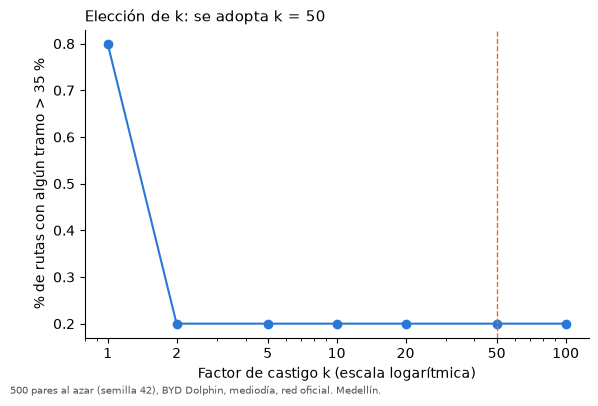


Corridas: 39  (pendiente extremos; capa 2 si; k = 50; sensibilidades: acumulada, capa 2 no, k = 0)
  [escrito] D4M_pesos_energia.csv  sha bb334f9301e4...
  [escrito] D4M_comparacion_rutas.csv  sha 95907060c483...
  [escrito] D4M_huellas_energia.json  sha 6ef854811e71...
   1/39  base                     byd_dolphin_449              12 h  extremos  con paradas  k=50   38 s
  [escrito] D4M_pesos_energia.csv  sha a900c782fb27...
  [escrito] D4M_comparacion_rutas.csv  sha 079544677356...
  [escrito] D4M_huellas_energia.json  sha a4f9a005134e...
   2/39  base                     byd_seagull_dolphin_mini     12 h  extremos  con paradas  k=50   36 s
  [escrito] D4M_pesos_energia.csv  sha 6ead4b9a4fef...
  [escrito] D4M_comparacion_rutas.csv  sha 12e72c8eb5ce...
  [escrito] D4M_huellas_energia.json  sha 99348b668291...
   3/39  base                     byd_tang_gs                  12 h  extremos  con paradas  k=50   35 s
  [escrito] D4M_pesos_energia.csv  sha 4958fd407f68...
  [escrito] D4M_c

F:\Tesis\Grafo Bogotá\modelo_consumo_v2\interfaz_grafo.py:169: UserWarning: consumo_por_arco(): arco largo y empinado (longitud=1030 m, pendiente=-8.4%) con velocidad constante asumida. El término de inercia (frenados/aceleraciones en curva) queda apagado por este supuesto y el consumo real puede ser mayor al estimado — ver bitácora §22-25.
  return consumo_por_arco(
F:\Tesis\Grafo Bogotá\modelo_consumo_v2\interfaz_grafo.py:169: UserWarning: consumo_por_arco(): arco largo y empinado (longitud=1573 m, pendiente=16.5%) con velocidad constante asumida. El término de inercia (frenados/aceleraciones en curva) queda apagado por este supuesto y el consumo real puede ser mayor al estimado — ver bitácora §22-25.
  return consumo_por_arco(


  [escrito] D4M_pesos_energia.csv  sha 891a69a246a0...
  [escrito] D4M_comparacion_rutas.csv  sha 2ebacd6b6ceb...
  [escrito] D4M_huellas_energia.json  sha 4471cee292b9...
  34/39  sens_sin_SDN             byd_dolphin_449              12 h  extremos  con paradas  k=50   39 s


F:\Tesis\Grafo Bogotá\modelo_consumo_v2\interfaz_grafo.py:169: UserWarning: consumo_por_arco(): arco largo y empinado (longitud=5559 m, pendiente=8.9%) con velocidad constante asumida. El término de inercia (frenados/aceleraciones en curva) queda apagado por este supuesto y el consumo real puede ser mayor al estimado — ver bitácora §22-25.
  return consumo_por_arco(


  [escrito] D4M_pesos_energia.csv  sha fc7871f77c7d...
  [escrito] D4M_comparacion_rutas.csv  sha 738e131d4662...
  [escrito] D4M_huellas_energia.json  sha 2b4d512e5350...
  35/39  sens_bloquear_y_sin_SDN  byd_dolphin_449              12 h  extremos  con paradas  k=50   36 s
  [escrito] D4M_pesos_energia.csv  sha c21c7d6a22ff...
  [escrito] D4M_comparacion_rutas.csv  sha 981bb2d16b43...
  [escrito] D4M_huellas_energia.json  sha bd442882a65c...
  36/39  sens_sin_altura_A        byd_dolphin_449              12 h  acumulada con paradas  k=50   35 s
  [escrito] D4M_pesos_energia.csv  sha e4e721888c9e...
  [escrito] D4M_comparacion_rutas.csv  sha c6bc1279997a...
  [escrito] D4M_huellas_energia.json  sha 958254065cbd...
  37/39  sens_sin_altura_A        byd_dolphin_449              12 h  extremos  sin paradas  k=50   32 s
  [escrito] D4M_pesos_energia.csv  sha cc1d4ae58e9c...
  [escrito] D4M_comparacion_rutas.csv  sha 0d084636a06e...
  [escrito] D4M_huellas_energia.json  sha e7acfa89a853...


In [11]:
# =============================================================================
# D4M — CELDA 11: CORRIDAS DE ENERGIA (12 vehiculos, 5 franjas, 5 escenarios de red)
# Copia del metodo de la celda 12 de Bogota; solo cambian ciudad, velocidad y
# carpeta de salida. Mismas pruebas que la celda 10. Cada corrida en su carpeta.
# =============================================================================
import matplotlib.pyplot as plt
_cache_corta = {}
def rutas_cortas(scen):
    if scen not in _cache_corta:
        rd = pd.read_csv(K.RUTA_ENTREGABLES / D4M / f"esc_{scen}" / f"D4M_rutas_distancia_{scen}.csv",
                         dtype={"origen": "string", "destino": "string", "tramos": "string"})
        assert (rd["origen"].to_numpy() == OD["origen"].to_numpy()).all()
        assert (rd["destino"].to_numpy() == OD["destino"].to_numpy()).all()
        _cache_corta[scen] = ([s.split(";") for s in rd["tramos"]], rd["distancia_m"].to_numpy())
    return _cache_corta[scen]

_seg_flota = VF.segmentos_flota()

# --- Capa 2 del modelo de consumo (arrancar y frenar), leida de SUS tablas para el segundo camino
_TAB_PKE = pd.read_csv(_car2 / "capa_paradas_tabla_pke.csv")
_K_FLOTA = (pd.read_csv(_car2 / "capa_paradas_coef_flota.csv")
            .set_index("vehiculo")["k_wh_km_por_Jkgkm"])

def consumo_sin_regen_vectorizado(Lc, pend, v_kmh, p, rho):
    """Segundo camino del costo SIN recuperar: la misma fisica de consumo_vectorizado
    pero con la regeneracion apagada (en bajada la bateria solo paga auxiliares)."""
    v = v_kmh / 3.6
    th = np.arctan(pend / 100.0)
    m = p.m_ensayo
    f = (p.crr(v) * m * PAR.G * np.cos(th) + 0.5 * rho * p.cd * p.area_frontal * v ** 2
         + m * PAR.G * np.sin(th))
    pb = np.where(f * v >= 0, f * v / p.eta_traccion, 0.0)
    return (pb + p.p_aux) * np.where(v > 0, Lc / v, 0.0) / 3.6e6

def extra_paradas(Lc, v, vehiculo_id):
    """Capa 2 por tramo (kWh): con la funcion del modelo de consumo (extra_arco_kwh) y, aparte,
    con la formula de su guia: k_vehiculo * PKE(v) * L_inclinada_km / 1000."""
    ex = np.array([CP.extra_arco_kwh(vehiculo_id, a, b) for a, b in zip(Lc, v)])
    ex_ind = (float(_K_FLOTA[vehiculo_id])
              * np.interp(v, _TAB_PKE["vprom"].to_numpy(), _TAB_PKE["pke_mediana"].to_numpy())
              * (np.asarray(Lc, float) / 1000.0) / 1000.0)
    return ex, ex_ind

def pesos_red(T, dz, v, vehiculo_id, modo, paradas=None):
    """Pesos de energia por tramo. paradas=None usa constantes_d1.CAPA_PARADAS_D4.
    Con paradas=True se suma la capa 2 del modelo de consumo (extra por arrancar y frenar)
    sobre la longitud inclinada del tramo; el dict trae ademas 'extra'."""
    if paradas is None:
        paradas = K.CAPA_PARADAS_D4
    r = _pesos_capa1(T, dz, v, vehiculo_id, modo)
    if paradas:
        ex, ex_ind = extra_paradas(r["Lc"], v, vehiculo_id)
        r["w"], r["w_indep"] = r["w"] + ex, r["w_indep"] + ex_ind
        r["w_sin_regen"] = r["w_sin_regen"] + ex
        r["w_sin_regen_indep"] = r["w_sin_regen_indep"] + ex_ind
        r["extra"] = ex
    else:
        r["extra"] = np.zeros(len(r["w"]))
    return r

def _pesos_capa1(T, dz, v, vehiculo_id, modo):
    """Pesos de energia de cada tramo segun la forma de pendiente.
    modo = "extremos": un solo trozo con el desnivel entre esquinas (celda 11).
    modo = "acumulada": el tramo se parte en un trozo que SUBE G metros y otro
      que BAJA P metros (ganancia y perdida del modulo de terreno), los dos con la pendiente
      acumulada 100 * (G + P) / L. G y P se corrigen para que G - P = desnivel
      entre esquinas: asi las alturas por esquina siguen sirviendo para Johnson.
      En los tramos sin dato del modulo de terreno (G = P = 0) queda igual que "extremos".
    Devuelve un dict: w (kWh, funcion del modelo de consumo), w_indep (misma fisica calculada
    aparte), pend (pendiente NETA, %), Lc (longitud usada, m), bajada (m que
    baja en total), avisos (tramos largos y empinados)."""
    p = VF.vehiculo(vehiculo_id)
    L = T["longitud_m"].to_numpy(float)
    dz = np.asarray(dz, float)
    if modo == "extremos":
        w, pend, Lc, n_warn = pesos_consumo(T, dz, v, vehiculo_id, K.LONGITUD_CONSUMO_D4)
        # Sin recuperar: cuando la bajada recargaria, la bateria solo paga los
        # auxiliares durante el tramo -> max(consumo, auxiliares * tiempo)
        aux = p.p_aux * (Lc / (np.asarray(v, float) / 3.6)) / 3.6e6
        return {"w": w, "w_indep": consumo_vectorizado(Lc, pend, v, p, _rho),
                "w_sin_regen": np.maximum(w, aux),
                "w_sin_regen_indep": consumo_sin_regen_vectorizado(Lc, pend, v, p, _rho),
                "pend": pend, "Lc": Lc, "bajada": np.clip(-dz, 0, None), "avisos": n_warn}
    assert modo == "acumulada", f"Forma de pendiente desconocida: {modo}"
    G = T["ganancia_acumulada_m"].to_numpy(float)
    P = T["perdida_acumulada_m"].to_numpy(float)
    _aj = dz - (G - P)                          # 0 salvo junto a las 3 esquinas incoherentes
    G = G + np.clip(_aj, 0, None)
    P = P + np.clip(-_aj, 0, None)
    GP = G + P
    _hay = GP > 0
    s = np.where(_hay, 100.0 * GP / L, 0.0)                    # pendiente acumulada (%)
    L_sube = np.where(_hay, L * G / np.where(_hay, GP, 1.0), 0.0)
    L_baja = np.where(_hay, L * P / np.where(_hay, GP, 1.0), 0.0)
    L_plano = np.where(_hay, 0.0, L)
    w, w_ind, Lc, n_warn = np.zeros(len(L)), np.zeros(len(L)), np.zeros(len(L)), 0
    w_sr, w_sr_ind = np.zeros(len(L)), np.zeros(len(L))       # sin recuperar, trozo por trozo
    v = np.asarray(v, float)
    for Lt, st in ((L_sube, s), (L_baja, -s), (L_plano, np.zeros(len(L)))):
        m = Lt > 0
        Lct = Lt * np.sqrt(1.0 + (st / 100.0) ** 2) if K.LONGITUD_CONSUMO_D4 == "inclinada" else Lt
        wt = np.zeros(len(L))
        with warnings.catch_warnings(record=True) as W:
            warnings.simplefilter("always")
            for i in np.flatnonzero(m):
                wt[i] = IG.consumo_arco_kwh(vehiculo_id, Lct[i], st[i], v[i], K.CIUDAD_CONSUMO_D4M)
        n_warn += sum("arco largo y empinado" in str(x.message) for x in W)
        w[m] += wt[m]
        aux = p.p_aux * (Lct[m] / (v[m] / 3.6)) / 3.6e6
        w_sr[m] += np.maximum(wt[m], aux)
        w_ind[m] += consumo_vectorizado(Lct[m], st[m], v[m], p, _rho)
        w_sr_ind[m] += consumo_sin_regen_vectorizado(Lct[m], st[m], v[m], p, _rho)
        Lc[m] += Lct[m]
    return {"w": w, "w_indep": w_ind, "w_sin_regen": w_sr, "w_sin_regen_indep": w_sr_ind,
            "pend": 100.0 * dz / L, "Lc": Lc, "bajada": P, "avisos": n_warn}

# --- Pendientes extremas: castigo k (escenario con restriccion de pendiente) ---
# Los tramos extremos NO se quitan: su peso de RUTEO es k * max(consumo, consumo en
# plano), nunca negativo. La energia que se REPORTA es siempre la real (sin castigo).
_EXT_ID = pd.Series(EXTREMA.to_numpy(bool), index=g["segmento_id"].to_numpy())

def marca_extremas_partes(T, dz):
    """(extrema_revision, extrema_estimada): la marca del modulo de terreno, y la misma regla del
    umbral aplicada a los tramos SIN dato del modulo de terreno con la altura estimada (celda 8)."""
    revision = T["segmento_id"].map(_EXT_ID).fillna(False).to_numpy(bool)
    pe = 100.0 * np.asarray(dz, float) / T["longitud_m"].to_numpy(float)
    estimada = (T["pendiente_asumida_cero"].to_numpy(bool)
                & (np.abs(pe) > K.UMBRAL_PENDIENTE_EXTREMA_PCT))
    return revision, estimada

def marca_extremas(T, dz):
    """Tramos que se castigan: los marcados por el modulo de terreno y, si la constante lo pide, los estimados."""
    revision, estimada = marca_extremas_partes(T, dz)
    return revision | estimada if K.EXTREMAS_POR_ALTURA_ESTIMADA_D4 else revision

def plano_extremas(Lc, v, vehiculo_id, paradas, ext):
    """Consumo del MISMO tramo (misma longitud recorrida) con pendiente 0, solo en los
    extremos: con la funcion del modelo de consumo y, aparte, con la fisica vectorizada."""
    Lc, v = np.asarray(Lc, float), np.asarray(v, float)
    pl, pl_ind = np.zeros(len(Lc)), np.zeros(len(Lc))
    i = np.flatnonzero(ext)
    if len(i):
        pl[i] = [IG.consumo_arco_kwh(vehiculo_id, a, 0.0, b, K.CIUDAD_CONSUMO_D4M)
                 for a, b in zip(Lc[i], v[i])]
        pl_ind[i] = consumo_vectorizado(Lc[i], np.zeros(len(i)), v[i],
                                        VF.vehiculo(vehiculo_id), _rho)
        if paradas:
            ex, ex_ind = extra_paradas(Lc[i], v[i], vehiculo_id)
            pl[i] += ex
            pl_ind[i] += ex_ind
    return pl, pl_ind

def castigar(w, w_sin_regen, w_plano, ext, k):
    """Peso de RUTEO del escenario con restriccion de pendiente. En los extremos:
    k * max(consumo SIN recuperar en la bajada, consumo del tramo en plano); en el
    resto, el consumo. Nunca negativo en los extremos. k = 0 significa SIN castigo
    (ojo: k = 1 ya no es "sin castigo": quita la recuperacion en las bajadas
    extremas y pone el piso del consumo en plano)."""
    if k == 0:                                     # k = 0: SIN castigo (peso = consumo)
        return np.array(w, dtype=float)
    return np.where(ext, k * np.maximum(w_sin_regen, w_plano), w)

def suma_en_arbol(padre, val, es_raiz):
    """S[x] = val[x] + S[padre[x]], con S = 0 en las raices (NaN si no se alcanza)."""
    S = np.full(len(padre), np.nan)
    S[es_raiz] = 0.0
    pend = np.flatnonzero(~es_raiz & (padre >= 0))
    while len(pend):
        p = padre[pend]
        listo = ~np.isnan(S[p])
        assert listo.any(), "El arbol de rutas tiene un ciclo o un padre invalido"
        S[pend[listo]] = val[pend[listo]] + S[p[listo]]
        pend = pend[~listo]
    return S

def peso_de_arista(iu, iv, w, a, b, n):
    """Peso de las aristas a -> b del grafo ya deduplicado (iu, iv, w)."""
    cod = iu.astype(np.int64) * n + iv
    o = np.argsort(cod)
    cs = cod[o]
    q = np.asarray(a, np.int64) * n + np.asarray(b, np.int64)
    j = np.minimum(np.searchsorted(cs, q), len(cs) - 1)
    assert (cs[j] == q).all(), "Una arista del arbol no existe en el grafo"
    return w[o[j]]

def real_hacia_estacion(P, iu, iv, w):
    """Suma de w por la ruta ELEGIDA desde cada esquina hasta su estacion. P es el
    arbol de la busqueda al reves desde el nodo imaginario n (P == n: estacion)."""
    n = len(P)
    raiz = P == n
    padre = np.where(raiz | (P < 0), -1, P).astype(np.int64)
    val = np.zeros(n)
    m = padre >= 0
    val[m] = peso_de_arista(iu, iv, w, np.flatnonzero(m), padre[m], n)
    return suma_en_arbol(padre, val, raiz)

def real_desde_origen(P, s, iu, iv, w):
    """Suma de w por la ruta ELEGIDA desde el origen s hasta cada esquina (arbol de
    una busqueda hacia adelante: P[j] es la esquina anterior)."""
    n = len(P)
    raiz = np.zeros(n, bool)
    raiz[s] = True
    padre = np.where(raiz | (P < 0), -1, P).astype(np.int64)
    val = np.zeros(n)
    m = padre >= 0
    val[m] = peso_de_arista(iu, iv, w, padre[m], np.flatnonzero(m), n)
    return suma_en_arbol(padre, val, raiz)

def correr_energia(scen, veh, hora, modo, paradas, k):
    T = ESC[scen]
    T = T[T["en_red"]].reset_index(drop=True)
    dz = (T["v"].map(_zB) - T["u"].map(_zB)).to_numpy(float)
    assert np.isfinite(dz).all(), f"{scen}: esquinas sin altura en la red"
    T = T.assign(dz_esquinas=dz)
    v, _, _ = velocidades(T, hora)
    n_cont = int((T["segmento_id"].map(TIPO_VIA) == "continuo").sum())
    _pw = pesos_red(T, dz, v, veh, modo, paradas)
    w, pend, Lc, n_warn = _pw["w"], _pw["pend"], _pw["Lc"], _pw["avisos"]
    ext_rev, ext_estim = marca_extremas_partes(T, dz)
    es_ext = marca_extremas(T, dz)
    w_pl, w_pl_ind = plano_extremas(Lc, v, veh, paradas, es_ext)
    w_rt = castigar(w, _pw["w_sin_regen"], w_pl, es_ext, k)   # peso de RUTEO (w = energia REAL)
    p = VF.vehiculo(veh)
    pr = []
    pr.append(("castigo: consumo sin recuperar = calculo independiente",
               bool(np.allclose(_pw["w_sin_regen"], _pw["w_sin_regen_indep"], rtol=1e-12, atol=1e-15))))
    pr.append(("castigo: consumo en plano = calculo independiente",
               bool(np.allclose(w_pl, w_pl_ind, rtol=1e-12, atol=1e-15))))
    # Con k = 0 no hay castigo: el peso es el consumo real, que en una bajada extrema
    # puede ser negativo (recupera). La regla "nunca negativo" solo aplica con castigo.
    pr.append(("castigo: ruteo >= real en todo tramo y >= 0 en los extremos (si k > 0)",
               bool((w_rt >= w - 1e-15).all() and (k == 0 or (w_rt[es_ext] >= 0).all()))))
    if paradas:
        pr.append(("capa 2: extra > 0 en todo tramo", bool((_pw["extra"] > 0).all())))
        _i = np.random.default_rng(K.SEMILLA_OD_D4).choice(len(T), size=300, replace=False)
        pr.append(("capa 2: = consumo_arco_con_paradas_kwh del modelo de consumo (300 tramos)",
                   bool(modo != "extremos" or np.allclose(
                       [CP.consumo_arco_con_paradas_kwh(veh, Lc[i], pend[i], v[i], K.CIUDAD_CONSUMO_D4M)
                        for i in _i], w[_i], rtol=1e-12, atol=1e-15))))
        pr.append(("capa 2: = consumo_arco_medellin_kwh del modelo de consumo (su modulo de Medellin, 300 tramos)",
                   bool(modo != "extremos" or np.allclose(
                       [IM.consumo_arco_medellin_kwh(veh, Lc[i], pend[i], v[i], con_capa2=True)
                        for i in _i], w[_i], rtol=1e-12, atol=1e-15))))
    pr.append(("pesos finitos", bool(np.isfinite(w).all())))
    pr.append(("modelo de consumo = calculo independiente",
               bool(np.allclose(w, _pw["w_indep"], rtol=1e-12, atol=1e-15))))
    tw = T.assign(w=w)
    _f = tw[tw["sentido_recorrido"] == "FT"].set_index(["id_eje", "parte"])["w"]
    _t = tw[tw["sentido_recorrido"] == "TF"].set_index(["id_eje", "parte"])["w"]
    pr.append(("ida y vuelta > 0", bool(((_f + _t).dropna() > 0).all())))
    tope = p.frac_regen * p.eta_regen * p.m_ensayo * PAR.G * _pw["bajada"] / 3.6e6
    pr.append(("nunca recupera mas del tope", bool((w >= -tope - 1e-12).all())))
    n_, iu_, iv_, w2, s_ = preparar_grafo(T, w_rt)
    _n0, _iu0, _, _, _ = preparar_grafo(T, w)
    pr.append(("castigo: mismas esquinas y tramos que sin castigo",
               len(_n0) == len(n_) and len(_iu0) == len(iu_)))
    h, met, _C = potenciales(n_, iu_, iv_, w2, _zB)
    pr.append(("sin ciclos (potencial por altura)", met == "por_altura"))
    o = n_.get_indexer(OD["origen"]); d = n_.get_indexer(OD["destino"])
    assert (o >= 0).all() and (d >= 0).all()
    e, r, s = rutear_johnson(len(n_), iu_, iv_, w2, s_, o, d, h)
    tr_c, L_c = rutas_cortas(scen)
    Ws = pd.Series(w, index=T["segmento_id"])           # energia REAL
    Wr = pd.Series(w_rt, index=T["segmento_id"])        # peso de RUTEO
    Ls = pd.Series(T["longitud_m"].to_numpy(), index=T["segmento_id"])
    pr.append(("distancia corta en disco = suma de tramos",
               bool(np.allclose([Ls.loc[t].sum() for t in tr_c], L_c, rtol=1e-9, atol=1e-6))))
    Ec = np.array([Ws.loc[t].sum() for t in tr_c])
    Ec_rt = np.array([Wr.loc[t].sum() for t in tr_c])
    Le = np.array([Ls.loc[x].sum() for x in r])
    e_real = np.array([Ws.loc[x].sum() for x in r])
    pr.append(("costo de ruteo = suma de pesos de ruteo", bool(np.allclose(e, s, rtol=1e-9, atol=1e-12))))
    pr.append(("eficiente <= corta en costo de ruteo", bool((e <= Ec_rt + 1e-12).all())))
    pr.append(("eficiente >= corta en distancia", bool((Le >= L_c - 1e-6).all())))
    if k == 0:
        pr.append(("sin castigo: costo de ruteo = energia real",
                   bool(np.allclose(e, e_real, rtol=1e-9, atol=1e-12))))
    fallan = [n for n, ok in pr if not ok]
    assert not fallan, f"{scen} / {veh} / {hora} h / k={k}: fallan {fallan}"
    e_ruteo, e = e, e_real              # desde aqui, e es la energia REAL de la ruta elegida

    # --- metricas ---
    misma = np.array([a == b for a, b in zip(r, tr_c)])
    # Ahorro sobre TODOS los viajes con energia corta > 0; donde la ruta es la
    # misma el ahorro es 0. (Antes los percentiles se tomaban solo entre los
    # viajes cuya ruta cambia; esa version queda como "_si_cambia".)
    pos = Ec > 0
    ahorro = np.full(len(Ec), np.nan)
    ahorro[pos] = 100 * (Ec[pos] - e[pos]) / Ec[pos]
    ahorro[pos & misma] = 0.0
    extra = 100 * (Le / L_c - 1)
    ext = set(T.loc[es_ext, "segmento_id"])
    cambia = ~misma & pos
    res = {
        "escenario": scen, "vehiculo": veh,
        "validado": veh in K.VEHICULOS_VALIDADOS_D4,
        "segmento": _seg_flota[veh][0], "bateria_kwh": p.bateria_util,
        "hora": hora, "franja": FM.franja_de(hora),
        "tramos_continuos_en_red": n_cont, "madrugada": K.MADRUGADA_D4M,
        "tramos_que_recargan_pct": round(100 * float((w < 0).mean()), 2),
        "avisos_largo_empinado": n_warn,
        "consumo_corta_kwh_100km": round(1e5 * Ec.sum() / L_c.sum(), 3),
        "consumo_eficiente_kwh_100km": round(1e5 * e.sum() / Le.sum(), 3),
        "pares_misma_ruta": int(misma.sum()),
        "pares_energia_corta_no_positiva": int((~pos).sum()),
        "pendiente": modo, "paradas": bool(paradas), "k": k,
        "tramos_extremos_en_red": int(es_ext.sum()),
        "tramos_extremos_estimados_en_red": int(ext_estim.sum()),
        "viajes_eficiente_gasta_mas_pct": round(100 * float((e > Ec + 1e-12).mean()), 2),
        "ahorro_mediana_pct": round(float(np.median(ahorro[pos])), 3),
        "ahorro_p90_pct": round(float(np.percentile(ahorro[pos], 90)), 3),
        "viajes_ahorro_mayor_5pct": round(100 * float((ahorro[pos] > 5).mean()), 2),
        "viajes_ahorro_mayor_10pct": round(100 * float((ahorro[pos] > 10).mean()), 2),
        "ahorro_mediana_si_cambia_pct": round(float(np.median(ahorro[cambia])), 3) if cambia.any() else 0.0,
        "ahorro_p90_si_cambia_pct": round(float(np.percentile(ahorro[cambia], 90)), 3) if cambia.any() else 0.0,
        "extra_distancia_mediana_pct": round(float(np.median(extra[~misma])), 3) if (~misma).any() else 0.0,
        "extra_distancia_p90_pct": round(float(np.percentile(extra[~misma], 90)), 3) if (~misma).any() else 0.0,
        "rutas_eficientes_con_tramo_extremo": int(sum(any(x in ext for x in rr) for rr in r)),
        "rutas_cortas_con_tramo_extremo": int(sum(any(x in ext for x in rr) for rr in tr_c)),
    }

    # --- salidas (mismo formato que la celda 11) ---
    tag = (f"esc_{scen}__{veh}__h{hora:g}__{modo}__long_{K.LONGITUD_CONSUMO_D4}"
           f"__{'con' if paradas else 'sin'}_paradas__k{k:g}")
    dirE = f"{D4M}/energia/{tag}"
    sha_p = guardar_csv_sin_sobrescribir(pd.DataFrame({
        "segmento_id": T["segmento_id"].to_numpy(), "v_kmh": v, "pendiente_pct": pend,
        "longitud_consumo_m": Lc, "consumo_kwh": w, "extrema_revision_terreno": ext_rev,
        "extrema_estimada": ext_estim, "castigada": es_ext,
        "peso_ruteo_kwh": w_rt}).sort_values("segmento_id"),
        K.ruta_entregable(dirE, "D4M_pesos_energia.csv"))
    sha_c = guardar_csv_sin_sobrescribir(pd.DataFrame({
        "par": OD["par"], "distancia_corta_m": L_c, "energia_corta_kwh": Ec,
        "distancia_eficiente_m": Le, "energia_eficiente_kwh": e, "misma_ruta": misma,
        "costo_ruteo_corta_kwh": Ec_rt, "costo_ruteo_eficiente_kwh": e_ruteo,
        "tramos_eficiente": [";".join(x) for x in r]}),
        K.ruta_entregable(dirE, "D4M_comparacion_rutas.csv"))
    ruta_h = K.ruta_entregable(dirE, "D4M_huellas_energia.json")
    if ruta_h.exists():   # corrida ya hecha: comprobar que es identica
        prev = json.loads(ruta_h.read_text(encoding="utf-8"))["archivos"]
        assert prev == {"D4M_pesos_energia.csv": sha_p, "D4M_comparacion_rutas.csv": sha_c}, \
            f"{tag}: la corrida NO reproduce los archivos ya registrados"
        print(f"  [reproducida identica] {tag}")
    else:
        guardar_texto_sin_sobrescribir(json.dumps({
            "estado": "version oficial", "vehiculo": veh, "hora": hora,
            "franja": FM.franja_de(hora), "escenario": scen, "ciudad": K.CIUDAD_CONSUMO_D4M,
            "pendiente": modo, "longitud": K.LONGITUD_CONSUMO_D4, "capa_paradas": bool(paradas),
            "k_extremas": k,
            "archivos": {"D4M_pesos_energia.csv": sha_p, "D4M_comparacion_rutas.csv": sha_c},
            "insumos": {"modelo_consumo_sha256": _hs, "alturas_esquinas_sha256": _sha_alt,
                        "huella_gpkg_d3m": HUELLA_D3},
            "pruebas": [{"prueba": n, "pasa": ok} for n, ok in pr]},
            indent=2, ensure_ascii=False, sort_keys=True, default=str), ruta_h)
    return res

# --- Lista de corridas ------------------------------------------------------------
# Vehiculos y franjas: en "base" (red de septiembre, se conserva como registro)
# y en el escenario OFICIAL (sens_sin_altura_A). Todo con
# la forma de pendiente principal (PENDIENTE_CONSUMO_D4); la otra forma se
# corre una vez (Dolphin, mediodia, red oficial) como sensibilidad.
MODO = K.PENDIENTE_CONSUMO_D4
OTRO_MODO = {"extremos": "acumulada", "acumulada": "extremos"}[MODO]
PARADAS = bool(K.CAPA_PARADAS_D4)          # capa 2 del modelo de consumo (arrancar y frenar)
_V0, _H0, _P0 = K.VEHICULO_BASE_D4, K.HORA_BASE_D4, K.ESCENARIO_OFICIAL_D4M

# --- ELEGIR k CON DATOS (misma regla de Bogota) ------------------------------------------
# Escenario oficial, Dolphin, mediodia, forma de pendiente y capa 2 principales.
# 500 pares al azar (semilla 42) entre las esquinas de la red (componente fuerte).
# Regla: el menor k a partir del cual el % de rutas con algun tramo extremo deja de
# bajar (baja menos de 1 punto frente al k siguiente, y asi hasta el final).
import networkx as nx
_TK = ESC[_P0]
_TK = _TK[_TK["en_red"]].reset_index(drop=True)
_dzK = (_TK["v"].map(_zB) - _TK["u"].map(_zB)).to_numpy(float)
_vK, _, _ = velocidades(_TK, _H0)
_pwK = pesos_red(_TK, _dzK, _vK, _V0, MODO, PARADAS)
_extK = marca_extremas(_TK, _dzK)
_extK_d, _extK_e = marca_extremas_partes(_TK, _dzK)
_wsrK = _pwK["w_sin_regen"]
_wplK, _wplK_ind = plano_extremas(_pwK["Lc"], _vK, _V0, PARADAS, _extK)
print(f"Tramos extremos en la red: {int(_extK_d.sum()):,} marcados y {int(_extK_e.sum())} "
      f"estimados ({sorted(_TK.loc[_extK_e, 'segmento_id'])}); se castigan {int(_extK.sum()):,}")
_nodos_red = sorted(set(_TK["u"]) | set(_TK["v"]))
_rngK = np.random.default_rng(K.SEMILLA_ELEGIR_K_D4)
PARES_K = [tuple(_rngK.choice(_nodos_red, 2, replace=False)) for _ in range(K.N_PARES_ELEGIR_K_D4)]
_WsK = pd.Series(_pwK["w"], index=_TK["segmento_id"])
_LsK = pd.Series(_TK["longitud_m"].to_numpy(), index=_TK["segmento_id"])
_ext_ids = set(_TK.loc[_extK, "segmento_id"])
pr_k, filas_k, _r1 = [], [], None
pr_k.append({"prueba": "consumo en plano = calculo independiente",
             "pasa": bool(np.allclose(_wplK, _wplK_ind, rtol=1e-12, atol=1e-15))})
# Referencia SIN castigo (k = 0): cuantas rutas usan tramos extremos hoy
_n, _iu, _iv, _w2, _s = preparar_grafo(_TK, castigar(_pwK["w"], _wsrK, _wplK, _extK, 0))
_h, _, _ = potenciales(_n, _iu, _iv, _w2, _zB)
_o = _n.get_indexer([a for a, _ in PARES_K]); _d = _n.get_indexer([b for _, b in PARES_K])
_e, _rr, _ = rutear_johnson(len(_n), _iu, _iv, _w2, _s, _o, _d, _h)
pr_k.append({"prueba": "sin castigo: costo de ruteo = energia real",
             "pasa": bool(np.allclose(_e, [_WsK.loc[x].sum() for x in _rr], rtol=1e-9, atol=1e-12))})
PCT_SIN_CASTIGO = 100 * np.mean([any(t in _ext_ids for t in x) for x in _rr])
print(f"  sin castigo: {PCT_SIN_CASTIGO:5.1f} % de rutas con tramo extremo")
_t0 = time.time()
for kk in K.FACTORES_EXTREMAS_CANDIDATOS_D4:
    _wrt = castigar(_pwK["w"], _wsrK, _wplK, _extK, kk)
    _n, _iu, _iv, _w2, _s = preparar_grafo(_TK, _wrt)
    _h, _met, _ = potenciales(_n, _iu, _iv, _w2, _zB)
    _o = _n.get_indexer([a for a, _ in PARES_K]); _d = _n.get_indexer([b for _, b in PARES_K])
    assert (_o >= 0).all() and (_d >= 0).all()
    _e, _rr, _sm = rutear_johnson(len(_n), _iu, _iv, _w2, _s, _o, _d, _h)
    _er = np.array([_WsK.loc[x].sum() for x in _rr])
    _lr = np.array([_LsK.loc[x].sum() for x in _rr])
    _usa = np.array([any(t in _ext_ids for t in x) for x in _rr])
    pr_k.append({"prueba": f"k={kk:g}: alturas de energia validas y costo = suma de pesos",
                 "pasa": _met == "por_altura" and bool(np.allclose(_e, _sm, rtol=1e-9, atol=1e-12))})
    if _r1 is None:
        _r1, _er1, _lr1 = _rr, _er, _lr
    filas_k.append({"k": kk, "pct_rutas_con_tramo_extremo": 100 * _usa.mean(),
                    "rutas_con_tramo_extremo": int(_usa.sum()),
                    "energia_real_media_kwh": _er.mean(),
                    "pct_rutas_cambian_vs_k1": 100 * np.mean([a != b for a, b in zip(_rr, _r1)]),
                    "energia_real_extra_vs_k1_pct": 100 * (_er.sum() / _er1.sum() - 1),
                    "distancia_extra_vs_k1_pct": 100 * (_lr.sum() / _lr1.sum() - 1)})
    print(f"  k = {kk:>5g}: {100 * _usa.mean():5.1f} % de rutas con tramo extremo  "
          f"({time.time() - _t0:,.0f} s)")
TAB_K = pd.DataFrame(filas_k)
_pct = TAB_K["pct_rutas_con_tramo_extremo"].to_numpy()
_baja = _pct[:-1] - _pct[1:]
_i = next((i for i in range(len(_baja))
           if (_baja[i:] < K.UMBRAL_CAMBIO_K_PUNTOS_D4).all()), len(_pct) - 1)
K_REGLA = float(TAB_K["k"].iat[_i])        # lo que da la regla con datos de Medellin
# Si constantes_d1 fija un k (FACTOR_EXTREMAS_D4M = 50, el mismo de Bogota), ese es el del
# escenario con restriccion de pendiente; el de la regla se guarda y se corre como sensibilidad.
K_ADOPTADO = K_REGLA if K.FACTOR_EXTREMAS_D4M is None else float(K.FACTOR_EXTREMAS_D4M)
assert np.isclose(TAB_K["k"], K_ADOPTADO).any(), f"k = {K_ADOPTADO:g} no esta en la tabla de k"
if K_ADOPTADO != K_REGLA:
    print(f"OJO: la regla da k = {K_REGLA:g}; se usa k = {K_ADOPTADO:g} (fijado en constantes_d1)")
# K_PRINCIPAL = k con el que se hacen las corridas completas (12 carros, franjas y
# alcanzabilidad). La comparacion central es k = 0 (ruta de minimo consumo): sus
# cifras salen de las celdas 13d y 20b.
K_PRINCIPAL = K_ADOPTADO if K.CASTIGO_EXTREMAS_PRINCIPAL_D4 else 0.0   # 0 = sin castigo

# Segundo camino: con el k adoptado, Bellman-Ford puro (networkx) da el mismo costo
_wrt = castigar(_pwK["w"], _wsrK, _wplK, _extK, K_ADOPTADO)
_n, _iu, _iv, _w2, _s = preparar_grafo(_TK, _wrt)
_h, _, _ = potenciales(_n, _iu, _iv, _w2, _zB)
_GK = nx.DiGraph()
_GK.add_weighted_edges_from(zip(_iu.tolist(), _iv.tolist(), _w2.tolist()), weight="w")
_ok_bf = True
for a, b in PARES_K[:3]:
    _o, _d = _n.get_loc(a), _n.get_loc(b)
    _eJ, _, _ = rutear_johnson(len(_n), _iu, _iv, _w2, _s, np.array([_o]), np.array([_d]), _h)
    _ok_bf &= bool(np.isclose(nx.single_source_bellman_ford_path_length(_GK, _o, weight="w")[_d],
                              _eJ[0], rtol=1e-9, atol=1e-9))
pr_k.append({"prueba": f"k={K_ADOPTADO:g}: Johnson = Bellman-Ford puro de networkx (3 pares)",
             "pasa": _ok_bf})
# Sensibilidad "bloquear" sobre la MISMA red oficial: se quitan los tramos
# extremos, se recalcula la componente fuerte y se cuenta que queda sin ruta.
_TKb = _TK[~_extK]
_comp_b, _n_esq_b = componente_mayor(_TKb)
_nod_b = set(_TKb.loc[_comp_b, "u"]) | set(_TKb.loc[_comp_b, "v"])
BLOQUEAR = {"esquinas_red_oficial": len(_nodos_red), "esquinas_que_quedan": _n_esq_b,
            "esquinas_sin_ruta": len(_nodos_red) - _n_esq_b,
            "pares_sin_ruta": int(sum(a not in _nod_b or b not in _nod_b for a, b in PARES_K)),
            "n_pares": len(PARES_K)}
pr_k.append({"prueba": "bloquear: la red que queda es fuertemente conexa",
             "pasa": len(_nod_b) == _n_esq_b})
print(f"BLOQUEAR los extremos en la red oficial: quedan {_n_esq_b:,} de {len(_nodos_red):,} "
      f"esquinas ({BLOQUEAR['esquinas_sin_ruta']:,} sin ruta); de los {len(PARES_K)} pares, "
      f"{BLOQUEAR['pares_sin_ruta']} quedan sin ruta")
_df = pd.DataFrame(pr_k)
_df["resultado"] = np.where(_df["pasa"], "PASA", "FALLA")
print("\nELEGIR k — pruebas")
print(_df[["prueba", "resultado"]].to_string(index=False))
assert _df["pasa"].all(), f"Fallan: {_df.loc[~_df['pasa'], 'prueba'].tolist()}"
print(f"\nTABLA DE k ({K.N_PARES_ELEGIR_K_D4} pares, semilla {K.SEMILLA_ELEGIR_K_D4}; "
      f"{len(_ext_ids):,} tramos extremos en la red)")
print(TAB_K.round(3).to_string(index=False))
_fila = TAB_K.loc[np.isclose(TAB_K["k"], K_ADOPTADO)].iloc[0]
print(f"\nk ADOPTADO: {K_ADOPTADO:g}.  Con ese k, {int(_fila['rutas_con_tramo_extremo'])} de "
      f"{K.N_PARES_ELEGIR_K_D4} rutas ({_fila['pct_rutas_con_tramo_extremo']:.1f} %) siguen usando "
      "algun tramo extremo: no tienen otra alternativa razonable.")
print(f"k de las corridas completas (escenario con restriccion de pendiente): {K_PRINCIPAL:g}. "
      "La comparacion central es k = 0 (ruta de minimo consumo, celdas 13d y 20b).")

_dirK = f"{D4M}/elegir_k"
_sha_k = guardar_csv_sin_sobrescribir(TAB_K, K.ruta_entregable(_dirK, "D4M_tabla_k.csv"))
guardar_texto_sin_sobrescribir(json.dumps({
    "k_adoptado": K_ADOPTADO, "k_principal": K_PRINCIPAL, "k_0_significa": "sin castigo",
    "k_regla": K_REGLA, "k_fijado_en_constantes": K.FACTOR_EXTREMAS_D4M,
    "pct_rutas_con_extremo_sin_castigo": PCT_SIN_CASTIGO,
    "castigo_principal": bool(K.CASTIGO_EXTREMAS_PRINCIPAL_D4),
    "extremas_por_altura_estimada": bool(K.EXTREMAS_POR_ALTURA_ESTIMADA_D4),
    "candidatos": list(K.FACTORES_EXTREMAS_CANDIDATOS_D4),
    "n_pares": K.N_PARES_ELEGIR_K_D4, "semilla": K.SEMILLA_ELEGIR_K_D4,
    "regla": "menor k desde el cual el % de rutas con tramo extremo baja menos de "
             f"{K.UMBRAL_CAMBIO_K_PUNTOS_D4:g} punto frente al k siguiente, hasta el final",
    "red": {"escenario": _P0, "vehiculo": _V0, "hora": _H0, "pendiente": MODO,
            "capa_paradas": PARADAS, "tramos_extremos": len(_ext_ids)},
    "rutas_que_siguen_con_extremo": int(_fila["rutas_con_tramo_extremo"]),
    "tramos_extremos": {"revision_terreno": int(_extK_d.sum()), "estimados": int(_extK_e.sum()),
                        "estimados_ids": sorted(_TK.loc[_extK_e, "segmento_id"])},
    "bloquear_en_red_oficial": BLOQUEAR,
    "archivos": {"D4M_tabla_k.csv": _sha_k}, "pruebas": pr_k},
    indent=2, ensure_ascii=False, sort_keys=True, default=str),
    K.ruta_entregable(_dirK, "D4M_k_adoptado.json"))
_figk = K.ruta_entregable(_dirK, "D4M_fig_elegir_k.png")
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(TAB_K["k"], TAB_K["pct_rutas_con_tramo_extremo"], marker="o", color="#2a78d6")
ax.axvline(K_ADOPTADO, color="#eb6834", linestyle="--", linewidth=1)
ax.set_xscale("log"); ax.set_xticks(TAB_K["k"]); ax.set_xticklabels([f"{x:g}" for x in TAB_K["k"]])
ax.set_xlabel("Factor de castigo k (escala logarítmica)")
ax.set_ylabel("% de rutas con algún tramo > 35 %")
ax.set_title(f"Elección de k: se adopta k = {K_ADOPTADO:g}", loc="left", fontsize=11)
ax.spines[["top", "right"]].set_visible(False)
fig.text(0.01, -0.03, f"{K.N_PARES_ELEGIR_K_D4} pares al azar (semilla {K.SEMILLA_ELEGIR_K_D4}), "
         "BYD Dolphin, mediodía, red oficial. Medellín.", fontsize=7, color="#52514e")
if _figk.exists():
    print(f"  [figura ya existe, no se reescribe] {_figk.name}")
else:
    fig.savefig(_figk, dpi=200, bbox_inches="tight", facecolor="white")
    print(f"  [figura escrita] {_figk.name}")
plt.show()
BITACORA["elegir_k"] = {"k_adoptado": K_ADOPTADO, "k_principal": K_PRINCIPAL, "k_regla": K_REGLA,
                        "tabla": TAB_K.to_dict(orient="records"), "pruebas": pr_k}

# --- Lista de corridas (todas con k) ----------------------------------------------------
_K_OTRO = 0.0 if K_PRINCIPAL != 0 else K_ADOPTADO
CORRIDAS = []
for _esc in dict.fromkeys(["base", _P0]):
    CORRIDAS += [(_esc, vh, _H0, MODO, PARADAS, K_PRINCIPAL) for vh in sorted(VF.FLOTA)]
    CORRIDAS += [(_esc, _V0, hh, MODO, PARADAS, K_PRINCIPAL) for hh in K.HORAS_POR_FRANJA_D4.values()
                 if hh != _H0]
CORRIDAS += [(esc, _V0, _H0, MODO, PARADAS, K_PRINCIPAL) for esc in ESC_D4M
             if (esc, _V0, _H0, MODO, PARADAS, K_PRINCIPAL) not in CORRIDAS]
# Sensibilidades (Dolphin, mediodia, red oficial): la otra forma de pendiente, la otra
# opcion de capa 2 y la otra opcion de castigo (k = 0 = sin castigo, o el k adoptado)
CORRIDAS += [(_P0, _V0, _H0, OTRO_MODO, PARADAS, K_PRINCIPAL),
             (_P0, _V0, _H0, MODO, not PARADAS, K_PRINCIPAL)]
if _K_OTRO != K_PRINCIPAL:
    CORRIDAS += [(_P0, _V0, _H0, MODO, PARADAS, _K_OTRO)]
# Medellin: tambien el k que dio la regla en Bogota, para comparar las dos ciudades
_K_BOG = float(K.K_REFERENCIA_BOGOTA_D4M)
if _K_BOG not in (K_PRINCIPAL, _K_OTRO):
    CORRIDAS += [(_P0, _V0, _H0, MODO, PARADAS, _K_BOG)]
# Y el k de la regla de Medellin, si no es el de las corridas completas (sensibilidad)
if K_REGLA not in (K_PRINCIPAL, _K_OTRO, _K_BOG):
    CORRIDAS += [(_P0, _V0, _H0, MODO, PARADAS, K_REGLA)]
assert len(CORRIDAS) == len(set(CORRIDAS))
print(f"\nCorridas: {len(CORRIDAS)}  (pendiente {MODO}; capa 2 {'si' if PARADAS else 'no'}; "
      f"k = {K_PRINCIPAL:g}; sensibilidades: {OTRO_MODO}, capa 2 {'no' if PARADAS else 'si'}, k = {_K_OTRO:g})")

RES_ENERGIA = []
_t0 = time.time()
for i, (esc, vh, hh, md, pa, kk) in enumerate(CORRIDAS, 1):
    t1 = time.time()
    RES_ENERGIA.append(correr_energia(esc, vh, hh, md, pa, kk))
    print(f"  {i:>2}/{len(CORRIDAS)}  {esc:<24} {vh:<26} {hh:>4g} h  {md:<9} "
          f"{'con' if pa else 'sin'} paradas  k={kk:<4g} {time.time() - t1:,.0f} s")
print(f"Total: {(time.time() - _t0) / 60:,.1f} min")

RES_ENERGIA = pd.DataFrame(RES_ENERGIA)
guardar_csv_sin_sobrescribir(RES_ENERGIA, K.ruta_entregable(f"{D4M}/energia", "D4M_resumen_energia.csv"))

_cols = ["consumo_corta_kwh_100km", "consumo_eficiente_kwh_100km", "pares_misma_ruta",
         "ahorro_mediana_pct", "ahorro_p90_pct", "viajes_ahorro_mayor_5pct",
         "viajes_ahorro_mayor_10pct", "viajes_eficiente_gasta_mas_pct", "extra_distancia_p90_pct",
         "rutas_eficientes_con_tramo_extremo", "rutas_cortas_con_tramo_extremo"]
_R = RES_ENERGIA[(RES_ENERGIA["pendiente"] == MODO) & (RES_ENERGIA["paradas"] == PARADAS)
                 & (RES_ENERGIA["k"] == K_PRINCIPAL)]
print(f"\n1) LOS 12 VEHICULOS ({K.ESCENARIO_OFICIAL_D4M}, mediodia, pendiente {MODO})")
print(_R[(_R["escenario"] == K.ESCENARIO_OFICIAL_D4M) & (_R["hora"] == K.HORA_BASE_D4)]
      .set_index("vehiculo")[["validado", "segmento"] + _cols].to_string())
print(f"\n2) DOLPHIN POR FRANJA ({K.ESCENARIO_OFICIAL_D4M})")
print(_R[(_R["escenario"] == K.ESCENARIO_OFICIAL_D4M) & (_R["vehiculo"] == K.VEHICULO_BASE_D4)]
      .set_index("franja")[["tramos_continuos_en_red"] + _cols].to_string())
print("\n3) DOLPHIN POR ESCENARIO DE RED (mediodia)")
print(_R[(_R["vehiculo"] == K.VEHICULO_BASE_D4) & (_R["hora"] == K.HORA_BASE_D4)]
      .set_index("escenario")[_cols].to_string())
print(f"\n4) PENDIENTE, CAPA 2 Y CASTIGO k (Dolphin, mediodia, {K.ESCENARIO_OFICIAL_D4M})")
print(RES_ENERGIA[(RES_ENERGIA["escenario"] == K.ESCENARIO_OFICIAL_D4M)
                  & (RES_ENERGIA["vehiculo"] == K.VEHICULO_BASE_D4)
                  & (RES_ENERGIA["hora"] == K.HORA_BASE_D4)]
      .set_index(["pendiente", "paradas", "k"])[_cols].to_string())
BITACORA["corridas_energia"] = RES_ENERGIA.to_dict(orient="records")

In [12]:
# D4M — CELDA 11b: REVISION EN STREET VIEW DE LOS TRAMOS > 35 % (registro, verificacion
# y sensibilidad sin escaleras ni senderos). Equivale a la celda 13 de Bogota.
# Lee el archivo intacto de datos_crudos/recibidos y lo cruza con el CSV de D3M.
# La red oficial NO cambia (se mantiene el metodo y la comparacion con Bogota).
# Sensibilidad: la red oficial SIN las calles que la revision en Street View marco como
# escalera o sendero; 12 carros, mediodia, mismo k de las corridas completas, misma muestra.
# Escribe en entregables/D4_medellin/revision_extremas/ sin sobrescribir.
# =============================================================================
PROP, VEH0, HORA0 = K.ESCENARIO_OFICIAL_D4M, K.VEHICULO_BASE_D4, K.HORA_BASE_D4
DIR_RV = f"{D4M}/revision_extremas"
_rv = K.RUTA_DATOS_CRUDOS / "recibidos" / K.ARCHIVO_REVISION_EXTREMAS_MED
assert _rv.exists(), f"Falta {_rv}: guardarlo tal cual en datos_crudos/recibidos"
_sha_rv = sha256_archivo(_rv)
assert _sha_rv == K.SHA256_REVISION_EXTREMAS_MED, "El archivo de la revision cambio desde su registro"
REV = pd.read_csv(_rv, encoding="utf-8-sig", dtype={"segmento_id": "string", "id_eje": "string",
                                                    "parte": "string", "categoria": "string"})
_d3r = pd.read_csv(RUTA_CSV_D3, dtype={"segmento_id": "string", "pendiente_extrema": "string"},
                   usecols=["segmento_id", "longitud_m", "pendiente_neta_pct", "pendiente_extrema",
                            "paso_nivel"], low_memory=False).set_index("segmento_id")
_d3r["pendiente_extrema"] = _a_bool(_d3r["pendiente_extrema"])
 
# --- 1. Registro y verificacion ---------------------------------------------------
pr_rv = []
pr_rv.append(("104 tramos, sin repetir, uno por calle fisica",
              len(REV) == 104 and REV["segmento_id"].is_unique
              and not REV.duplicated(["id_eje", "parte"]).any()))
pr_rv.append(("todos existen en D3M", bool(REV["segmento_id"].isin(_d3r.index).all())))
_x = _d3r.loc[REV["segmento_id"]]
_ex, _pn = (REV["motivo"] == "extrema").to_numpy(), (REV["motivo"] == "paso_nivel_2").to_numpy()
pr_rv.append(("95 marcados > 35 % en D3M y 9 con paso_nivel 2",
              int(_ex.sum()) == 95 and int(_pn.sum()) == 9
              and bool(_x["pendiente_extrema"].to_numpy()[_ex].all())
              and bool((pd.to_numeric(_x["paso_nivel"]).to_numpy()[_pn] == 2).all())))
pr_rv.append(("pendiente y longitud = D3M",
              bool(np.allclose(REV["pendiente_neta_pct"], _x["pendiente_neta_pct"], atol=1e-9)
                   and np.allclose(REV["longitud_m"], _x["longitud_m"], atol=1e-9))))
_cats = REV["categoria"].value_counts()
pr_rv.append(("solo categorias declaradas", set(_cats.index) <= {"Calle_normal", "Calle_abierta", "Escalera",
                                                                  "Sendero_o_paso_angosto", "No_se_ve"}))
pr_rv.append(("recuento = lo reportado (38 normal, 1 abierta, 31 escalera, 12 sendero, 22 no se ve)",
              _cats.to_dict() == {"Calle_normal": 38, "Escalera": 31, "No_se_ve": 22,
                                  "Sendero_o_paso_angosto": 12, "Calle_abierta": 1}))
_sv = {"Calle_normal": "si", "Calle_abierta": "si", "Escalera": "no",
       "Sendero_o_paso_angosto": "no", "No_se_ve": "no se ve"}
pr_rv.append(("'se ve calle para carros' coincide con la categoria",
              bool((REV["categoria"].map(_sv) == REV["se_ve_calle_para_carros"].str.strip()).all())))
RESUMEN_RV = pd.crosstab(REV["categoria"], REV["motivo"]).reset_index()
print("QUE SE VE EN STREET VIEW (tramos de la lista revisada)")
print(pd.crosstab(REV["categoria"], REV["motivo"], margins=True).to_string())
_pt = REV[(REV["es_elevado"].astype(str) == "True") | REV["nombre"].fillna("").str.contains("(?i)t[uú]nel")]
print("\nPuentes y tuneles en la lista:")
print(_pt[["segmento_id", "nombre", "pendiente_neta_pct", "categoria", "observacion"]].to_string(index=False))
print(f"  En la red oficial cuentan como > 35 %: "
      f"{sorted(set(_pt['segmento_id']) & set(g.loc[EXTREMA, 'segmento_id']))}")
 
# --- 2. Sensibilidad: red oficial sin escaleras ni senderos -------------------------
NOVEH = REV[REV["categoria"].isin(K.CATEGORIAS_NO_VEHICULARES_MED)]
_llave = set(zip(NOVEH["id_eje"], NOVEH["parte"]))
T0 = ESC[PROP]
_quitar = np.array([(str(a), str(b)) in _llave for a, b in zip(T0["id_eje"], T0["parte"])])
Q_IDS = set(T0.loc[_quitar, "segmento_id"])
pr_rv.append(("cada calle quitada aparece en los dos sentidos (o en el unico que tiene)",
              set(NOVEH["segmento_id"]) <= Q_IDS))
_cand = T0[T0["en_red"] & ~_quitar]
_comp, _ = componente_mayor(_cand)
T1 = T0.copy()
T1["en_red"] = False
T1.loc[_cand.index[_comp.to_numpy()], "en_red"] = True
_n0 = set(T0.loc[T0["en_red"], "u"]) | set(T0.loc[T0["en_red"], "v"])
_n1 = set(T1.loc[T1["en_red"], "u"]) | set(T1.loc[T1["en_red"], "v"])
_sin_ruta = sorted(_n0 - _n1)
pr_rv.append(("la red sin escaleras es fuertemente conexa y esta dentro de la oficial",
              _n1 <= _n0 and componente_mayor(T1[T1["en_red"]])[1] == len(_n1)))
_ok_od = OD["origen"].isin(_n1) & OD["destino"].isin(_n1)
OD_S = OD[_ok_od].reset_index(drop=True)
 
# Uso en la corrida oficial (Dolphin)
_tag0 = (f"esc_{PROP}__{VEH0}__h{HORA0:g}__{K.PENDIENTE_CONSUMO_D4}__long_{K.LONGITUD_CONSUMO_D4}"
         f"__{'con' if PARADAS else 'sin'}_paradas__k{K_PRINCIPAL:g}")
_pw0 = pd.read_csv(K.RUTA_ENTREGABLES / D4M / "energia" / _tag0 / "D4M_pesos_energia.csv",
                   dtype={"segmento_id": "string", "castigada": "string"})
_EXT = set(_pw0.loc[_pw0["castigada"] == "True", "segmento_id"])
_cmp0 = pd.read_csv(K.RUTA_ENTREGABLES / D4M / "energia" / _tag0 / "D4M_comparacion_rutas.csv",
                    dtype={"tramos_eficiente": "string"})
_tc0, _ = rutas_cortas(PROP)
_usa = lambda rutas, S: np.array([any(t in S for t in r) for r in rutas])
_re0 = [x.split(";") if isinstance(x, str) and x else [] for x in _cmp0["tramos_eficiente"]]
_w = OD["peso"].to_numpy()
USO = pd.DataFrame([{"ruta": nom, "usan_tramo_mas_35": int(_usa(rr, _EXT).sum()),
                     "usan_escalera_o_sendero": int(_usa(rr, Q_IDS).sum()),
                     "pct_viajes_ciudad_escalera_o_sendero": round(100 * float(_w[_usa(rr, Q_IDS)].sum()), 2)}
                    for nom, rr in (("corta", _tc0), ("eficiente", _re0))])
pr_rv.append(("toda ruta que usa una escalera/sendero usa un tramo > 35 % (todas lo son)",
              bool((~_usa(_tc0, Q_IDS) | _usa(_tc0, _EXT)).all())
              and len(Q_IDS - set(g.loc[EXTREMA, "segmento_id"])) == 0))
 
def _corrida(T, veh, od):
    T = T[T["en_red"]].reset_index(drop=True)
    dz = (T["v"].map(_zB) - T["u"].map(_zB)).to_numpy(float)
    v, _, _ = velocidades(T, HORA0)
    pw = pesos_red(T, dz, v, veh, MODO, PARADAS)
    w = pw["w"]; ext = marca_extremas(T, dz)
    wpl, _ = plano_extremas(pw["Lc"], v, veh, PARADAS, ext)
    n, iu, iv, w2, s = preparar_grafo(T, castigar(w, pw["w_sin_regen"], wpl, ext, K_PRINCIPAL))
    h, met, _ = potenciales(n, iu, iv, w2, _zB)
    assert met == "por_altura"
    o, d = n.get_indexer(od["origen"]), n.get_indexer(od["destino"])
    assert (o >= 0).all() and (d >= 0).all()
    _, r, _ = rutear_johnson(len(n), iu, iv, w2, s, o, d, h)
    dist, rc, _ = rutear_distancia(T, od)
    Ws = pd.Series(w, index=T["segmento_id"]); Ls = pd.Series(T["longitud_m"].to_numpy(), index=T["segmento_id"])
    return pd.DataFrame({"distancia_corta_m": dist,
                         "energia_corta_kwh": [Ws.loc[x].sum() for x in rc],
                         "distancia_eficiente_m": [Ls.loc[x].sum() for x in r],
                         "energia_eficiente_kwh": [Ws.loc[x].sum() for x in r],
                         "misma": [a == b for a, b in zip(r, rc)]})
 
def _ind(c, w):
    v = (c["energia_corta_kwh"] > 0).to_numpy(); c, w = c[v], np.asarray(w, float)[v]
    a = np.where(c["misma"], 0.0, 100 * (c["energia_corta_kwh"] - c["energia_eficiente_kwh"]) / c["energia_corta_kwh"])
    o = np.argsort(a, kind="stable"); cw = np.cumsum(w[o]) / w.sum()
    return {"consumo_corta_kwh_100km": round(1e5 * float((w * c["energia_corta_kwh"]).sum() / (w * c["distancia_corta_m"]).sum()), 3),
            "consumo_eficiente_kwh_100km": round(1e5 * float((w * c["energia_eficiente_kwh"]).sum() / (w * c["distancia_eficiente_m"]).sum()), 3),
            "pct_ahorro_mayor_5": round(100 * float(w[a > 5].sum() / w.sum()), 2),
            "ahorro_p90_pct": round(float(a[o][np.searchsorted(cw, .9)]), 3)}
 
_t0 = time.time()
filas_s = []
_wS = OD_S["peso"].to_numpy()
for vh in sorted(VF.FLOTA):
    _tg = _tag0.replace(f"__{VEH0}__", f"__{vh}__")
    c_of = pd.read_csv(K.RUTA_ENTREGABLES / D4M / "energia" / _tg / "D4M_comparacion_rutas.csv")
    c_of["misma"] = c_of["misma_ruta"].astype(str) == "True"
    c_of = c_of[_ok_od.to_numpy()].reset_index(drop=True)
    c_sin = _corrida(T1, vh, OD_S)
    if vh == VEH0:   # segundo camino: la misma funcion sobre la red oficial = corrida oficial
        c_chk = _corrida(T0, vh, OD_S)
        pr_rv.append(("red oficial recalculada aqui = corrida oficial en disco (Dolphin, cada viaje)",
                      bool(np.allclose(c_chk["energia_corta_kwh"], c_of["energia_corta_kwh"], atol=1e-6)
                           and np.allclose(c_chk["energia_eficiente_kwh"], c_of["energia_eficiente_kwh"], atol=1e-6))))
    pr_rv.append((f"{vh}: sin esas calles nunca es mas corto", bool((c_sin["distancia_corta_m"] >= c_of["distancia_corta_m"] - 1e-6).all())))
    a, b = _ind(c_of, _wS), _ind(c_sin, _wS)
    filas_s.append({"vehiculo": vh, **{f"{k}_oficial": v for k, v in a.items()},
                    **{f"{k}_sin_escaleras": v for k, v in b.items()}})
SENS_ESC = pd.DataFrame(filas_s)
SENS_ESC["cambio_consumo_eficiente_pct"] = (100 * (SENS_ESC["consumo_eficiente_kwh_100km_sin_escaleras"]
                                                   / SENS_ESC["consumo_eficiente_kwh_100km_oficial"] - 1)).round(3)
print(f"\nSensibilidad: {(time.time() - _t0) / 60:,.1f} min")
 
_df = pd.DataFrame(pr_rv, columns=["prueba", "pasa"])
_df["resultado"] = np.where(_df["pasa"], "PASA", "FALLA")
print("\nREVISION EN STREET VIEW — pruebas")
print(_df[["prueba", "resultado"]].to_string(index=False))
assert _df["pasa"].all(), f"Fallan: {_df.loc[~_df['pasa'], 'prueba'].tolist()}"
 
print(f"\nSIN ESCALERAS NI SENDEROS ({len(NOVEH)} calles = {len(Q_IDS)} tramos; "
      f"{len(Q_IDS & _EXT)} de los {len(_EXT)} tramos > 35 % de la red oficial)")
print(f"  esquinas sin ruta: {len(_sin_ruta)} de {len(_n0):,}; viajes de la muestra sin ruta: "
      f"{int((~_ok_od).sum())} de {len(OD):,}")
print(USO.to_string(index=False))
print(SENS_ESC[["vehiculo", "consumo_eficiente_kwh_100km_oficial", "consumo_eficiente_kwh_100km_sin_escaleras",
                "cambio_consumo_eficiente_pct", "pct_ahorro_mayor_5_oficial", "pct_ahorro_mayor_5_sin_escaleras",
                "ahorro_p90_pct_oficial", "ahorro_p90_pct_sin_escaleras"]].to_string(index=False))
 
_sha_s = {
    "D4M_revision_street_view_resumen.csv": guardar_csv_sin_sobrescribir(RESUMEN_RV, K.ruta_entregable(DIR_RV, "D4M_revision_street_view_resumen.csv")),
    "D4M_sens_sin_escaleras_uso.csv": guardar_csv_sin_sobrescribir(USO, K.ruta_entregable(DIR_RV, "D4M_sens_sin_escaleras_uso.csv")),
    "D4M_sens_sin_escaleras_por_carro.csv": guardar_csv_sin_sobrescribir(SENS_ESC, K.ruta_entregable(DIR_RV, "D4M_sens_sin_escaleras_por_carro.csv")),
}
guardar_texto_sin_sobrescribir(json.dumps({
    "archivo_revision": K.ARCHIVO_REVISION_EXTREMAS_MED, "sha256": _sha_rv, "conteo": _cats.to_dict(),
    "sensibilidad": {"quita": list(K.CATEGORIAS_NO_VEHICULARES_MED), "calles": len(NOVEH),
                     "tramos": len(Q_IDS), "esquinas_sin_ruta": _sin_ruta,
                     "viajes_sin_ruta": int((~_ok_od).sum()), "k": K_PRINCIPAL, "hora": HORA0},
    "archivos": _sha_s, "pruebas": {p: bool(ok) for p, ok in pr_rv}},
    indent=2, ensure_ascii=False, sort_keys=True, default=str),
    K.ruta_entregable(DIR_RV, "D4M_huellas_revision_extremas.json"))
BITACORA["revision_street_view"] = {"sha256": _sha_rv, "conteo": _cats.to_dict(),
                                       "archivos": _sha_s, "pruebas": pr_rv}

QUE SE VE EN STREET VIEW (tramos de la lista revisada)
motivo                  extrema  paso_nivel_2  All
categoria                                         
Calle_abierta                 1             0    1
Calle_normal                 29             9   38
Escalera                     31             0   31
No_se_ve                     22             0   22
Sendero_o_paso_angosto       12             0   12
All                          95             9  104

Puentes y tuneles en la lista:
    segmento_id                               nombre  pendiente_neta_pct    categoria           observacion
MED_138418_0_FT                     Tunel de Oriente           42.468512 Calle_normal           Es un tunel
MED_135445_0_FT                  Via finca El Tambor            3.381474 Calle_normal Puente sobre un tunel
MED_138386_0_FT Av. Las Palmas >Occidente - Calle 19           -3.709411 Calle_normal                   NaN
  En la red oficial cuentan como > 35 %: ['MED_138418_0_FT']

Sensibilida

# Estaciones enganchadas y alcanzabilidad

In [13]:
# =============================================================================
# D4M — CELDA 12: ESTACIONES DE CARGA ENGANCHADAS A LA RED (todos los escenarios)
# Reglas (constantes_d1): veredicto por fila cuando hay dos coordenadas en
# esquinas distintas; un punto por estacion (sin C5); esquina mas cercana de
# la red del escenario; > UMBRAL_ENGANCHE_LEJANO_M solo se marca.
# =============================================================================
assert not K.USAR_PUNTOS_SECUNDARIOS_C5
EST = E[~E["es_secundario_C5"] & ~E["excluida_d4m"]].copy().reset_index(drop=True)
assert len(EST) == N_FISICAS_MED - len(K.ESTACIONES_EXCLUIDAS_D4M), \
    "El numero de estaciones no coincide con la auditoria de B2.1 menos las excluidas en D4M"
VER = K.VEREDICTOS_COORDENADA_D4M

# --- 1. Que coordenada usa cada estacion -------------------------------------
fuente, motivo, usados = [], [], set()
for _, r in EST.iterrows():
    hay_ocm, hay_osm = pd.notna(r["x_ocm"]), pd.notna(r["x_osm"])
    assert hay_ocm or hay_osm, f"fila {r['fila_inv']} sin coordenada"
    if hay_ocm and not hay_osm:
        fuente.append("ocm"); motivo.append("unica fuente (solo OCM)")
    elif hay_osm and not hay_ocm:
        fuente.append("osm"); motivo.append("unica fuente (solo OSM)")
    elif r["ocm_id"] in VER:
        fila, osm, f, m = VER[r["ocm_id"]]
        assert fila == r["fila_inv"] and osm == r["osm_uid"], \
            f"El veredicto de {r['ocm_id']} no corresponde a la fila {r['fila_inv']}"
        assert f in ("ocm", "osm")
        fuente.append(f); motivo.append(m); usados.add(r["ocm_id"])
    else:
        assert bool(r["misma_esquina_ocm_osm_base"]), \
            f"fila {r['fila_inv']}: dos coordenadas en esquinas distintas y sin veredicto"
        fuente.append("ocm" if r["enganche_ocm_base_m"] <= r["enganche_osm_base_m"] else "osm")
        motivo.append("ambas caen en la misma esquina; se usa la mas cercana a la red")
assert usados == set(VER), f"Veredictos sin usar: {set(VER) - usados}"
EST["fuente_coordenada"] = fuente
EST["motivo_coordenada"] = motivo

pr_14 = []
# Los desempates declarados son de verdad los mas cercanos (segundo camino)
_ok_des = True
for oc, (fila, osm, f, m) in VER.items():
    if m.startswith("desempate"):
        r = EST[EST["ocm_id"] == oc].iloc[0]
        _ok_des &= f == ("ocm" if r["enganche_ocm_base_m"] <= r["enganche_osm_base_m"] else "osm")
pr_14.append({"prueba": "desempates = punto mas cercano a la red base", "pasa": bool(_ok_des)})

_o = EST["fuente_coordenada"] == "ocm"
for c in ("lat", "lon", "x", "y"):
    EST[c] = np.where(_o, EST[f"{c}_ocm"], EST[f"{c}_osm"])
# Segundo camino: la coordenada elegida = la que declara su fuente (A2/A3)
_lat_src = np.where(_o, EST["ocm_id"].map(OCM_T.set_index("ocm_id")["latitud"]),
                    EST["osm_uid"].map(OSM_T.set_index("osm_uid")["latitud"]))
_lon_src = np.where(_o, EST["ocm_id"].map(OCM_T.set_index("ocm_id")["longitud"]),
                    EST["osm_uid"].map(OSM_T.set_index("osm_uid")["longitud"]))
pr_14.append({"prueba": "coordenada elegida = la de su fuente",
              "pasa": bool(np.allclose(EST["lat"], _lat_src) and np.allclose(EST["lon"], _lon_src))})
pr_14.append({"prueba": "ninguna estacion repetida (ocm_id y osm_uid unicos)",
              "pasa": EST["ocm_id"].dropna().is_unique and EST["osm_uid"].dropna().is_unique})

# --- 2. Enganche en la red de cada escenario ---------------------------------
_pts = gpd.GeoDataFrame(EST[[]], geometry=gpd.points_from_xy(EST["x"], EST["y"]), crs=K.CRS_METRICO)
_sin_ver = EST["x_ocm"].notna() & EST["x_osm"].notna() & ~EST["ocm_id"].isin(list(VER))
_ok_sj, _ok_misma = True, True
for esc, t in ESC.items():
    nod = set(t.loc[t["en_red"], "u"]) | set(t.loc[t["en_red"], "v"])
    tab = NODOS[NODOS["nodo"].isin(nod)].reset_index(drop=True)
    ids, d = enganchar(EST["x"], EST["y"], tab)
    EST[f"nodo_{esc}"] = ids
    EST[f"enganche_{esc}_m"] = d
    EST[f"lejos_{esc}"] = EST[f"enganche_{esc}_m"] > K.UMBRAL_ENGANCHE_LEJANO_M
    _g = gpd.GeoDataFrame(tab, geometry=gpd.points_from_xy(tab["x"], tab["y"]), crs=K.CRS_METRICO)
    _sj = gpd.sjoin_nearest(_pts, _g[["geometry"]], distance_col="d")
    _sj = _sj[~_sj.index.duplicated()]
    _ok_sj &= bool(np.allclose(_sj["d"].sort_index(), EST[f"enganche_{esc}_m"]))
    if _sin_ver.any():
        i1, _ = enganchar(EST.loc[_sin_ver, "x_ocm"], EST.loc[_sin_ver, "y_ocm"], tab)
        i2, _ = enganchar(EST.loc[_sin_ver, "x_osm"], EST.loc[_sin_ver, "y_osm"], tab)
        _ok_misma &= (i1 == i2)
pr_14.append({"prueba": "enganche por fuerza bruta = sjoin_nearest (5 escenarios)", "pasa": _ok_sj})
pr_14.append({"prueba": "estaciones sin veredicto caen en la misma esquina con ambas fuentes (5 escenarios)",
              "pasa": bool(_ok_misma)})

_df = pd.DataFrame(pr_14)
_df["resultado"] = np.where(_df["pasa"], "PASA", "FALLA")
print("ESTACIONES ENGANCHADAS")
print(_df[["prueba", "resultado"]].to_string(index=False))
assert _df["pasa"].all(), f"Fallan: {_df.loc[~_df['pasa'], 'prueba'].tolist()}"

print(f"\nEstaciones: {len(EST)}   coordenada: "
      f"{EST['fuente_coordenada'].value_counts().to_dict()}")
print("\nEnganche por escenario (m):")
for esc in ESC:
    s = EST[f"enganche_{esc}_m"]
    print(f"  {esc:<26} mediana {s.median():5.1f}  max {s.max():6.1f}  "
          f"> {K.UMBRAL_ENGANCHE_LEJANO_M:.0f} m: {int(EST[f'lejos_{esc}'].sum())}")
_p = K.ESCENARIO_OFICIAL_D4M
print(f"\nEnganches lejanos en la red oficial ({_p}):")
print(EST.loc[EST[f"lejos_{_p}"], ["fila_inv", "nombre_ocm", "nombre_osm",
                                   "fuente_coordenada", f"enganche_{_p}_m"]]
      .round(1).to_string(index=False))

# --- 3. Salidas (sin sobrescribir) --------------------------------------------
_cols = (["fila_inv", "categoria", "origen", "ocm_id", "osm_uid", "nombre_ocm", "nombre_osm",
          "fuente_coordenada", "motivo_coordenada", "lat", "lon", "x", "y"]
         + [f"{k}_{esc}" for esc in ESC for k in ("nodo", "enganche", "lejos")])
_cols = [c if not c.startswith("enganche_") else c + "_m" for c in _cols]
_sha_est = guardar_csv_sin_sobrescribir(
    EST[_cols].sort_values("fila_inv").reset_index(drop=True),
    K.ruta_entregable(f"{D4M}/estaciones", "D4M_estaciones_enganche.csv"))
guardar_texto_sin_sobrescribir(json.dumps({
    "archivos": {"D4M_estaciones_enganche.csv": _sha_est},
    "reglas": {"veredictos_coordenada": VER,
               "usar_puntos_secundarios_c5": K.USAR_PUNTOS_SECUNDARIOS_C5,
               "umbral_enganche_lejano_m": K.UMBRAL_ENGANCHE_LEJANO_M,
               "escenario_oficial": K.ESCENARIO_OFICIAL_D4M,
               "excluidas_d4m": K.ESTACIONES_EXCLUIDAS_D4M},
    "insumos": {"estaciones_sha256": K.INSUMOS_ESTACIONES_D4M,
                "huella_gpkg_d3m": HUELLA_D3},
    "pruebas": pr_14}, indent=2, ensure_ascii=False, sort_keys=True, default=str),
    K.ruta_entregable(f"{D4M}/estaciones", "D4M_huellas_estaciones.json"))
BITACORA["estaciones_enganche"] = {"sha256": _sha_est, "pruebas": pr_14}

ESTACIONES ENGANCHADAS
                                                                            prueba resultado
                                      desempates = punto mas cercano a la red base      PASA
                                              coordenada elegida = la de su fuente      PASA
                               ninguna estacion repetida (ocm_id y osm_uid unicos)      PASA
                          enganche por fuerza bruta = sjoin_nearest (5 escenarios)      PASA
estaciones sin veredicto caen en la misma esquina con ambas fuentes (5 escenarios)      PASA

Estaciones: 18   coordenada: {'osm': 10, 'ocm': 8}

Enganche por escenario (m):
  base                       mediana  53.2  max  209.1  > 100 m: 4
  sens_bloquear_extremas     mediana  53.2  max  209.1  > 100 m: 4
  sens_sin_altura_A          mediana  53.2  max  209.1  > 100 m: 4
  sens_sin_SDN               mediana  53.2  max  209.1  > 100 m: 4
  sens_bloquear_y_sin_SDN    mediana  53.2  max  209.1  > 100 m: 4

En

In [14]:
# =============================================================================
# D4M — CELDA 13: ALCANZABILIDAD — energia minima desde cada esquina hasta ALGUNA
# estacion de carga (toda la red, sin muestra)
# Una sola busqueda de Dijkstra al reves desde las estaciones, con los pesos
# enderezados por las alturas de energia (mismo metodo verificado en 8 y 10).
# Verificada contra busquedas hacia adelante desde esquinas al azar.
# =============================================================================
def energia_a_estacion(nodos, iu, iv, w, h, nodos_est, semilla, devolver_padres=False):
    """Costo minimo (kWh) desde cada esquina hasta la estacion mas barata, con los
    pesos w. Devuelve (E, raiz, verificado) y, si se pide, el arbol de rutas P."""
    n = len(nodos)
    wr = np.maximum(w + h[iu] - h[iv], 0.0)
    ie = np.unique(nodos.get_indexer(nodos_est))
    assert (ie >= 0).all(), "Hay estaciones enganchadas fuera de la red del escenario"
    # Nodo imaginario T -> cada estacion, con peso h(s) - hmin + 1 (>= 1, sin ceros).
    # Grafo AL REVES: el tramo u->v se recorre como v->u.
    hmin = h[ie].min()
    M = csr_matrix((np.concatenate([wr, h[ie] - hmin + 1.0]),
                    (np.concatenate([iv, np.full(len(ie), n)]),
                     np.concatenate([iu, ie]))), shape=(n + 1, n + 1))
    D, P = dijkstra(M, directed=True, indices=n, return_predecessors=True)
    D, P = D[:n], P[:n]
    E = D - h + hmin - 1.0                    # se deshace el enderezado
    # Estacion elegida por cada esquina (se sube por el arbol hasta T)
    raiz = np.full(n, -1, dtype=np.int64)
    for i in range(n):
        if raiz[i] >= 0 or not np.isfinite(D[i]):
            continue
        camino, x = [], i
        while raiz[x] < 0 and P[x] != n:
            camino.append(x); x = int(P[x])
        r = raiz[x] if raiz[x] >= 0 else x
        raiz[x] = r
        for y in camino:
            raiz[y] = r
    # Segundo camino: hacia adelante desde esquinas al azar, a TODAS las estaciones
    rng = np.random.default_rng(semilla)
    mu = rng.choice(n, size=K.N_ESQUINAS_VERIFICACION_D4, replace=False)
    Df = dijkstra(csr_matrix((wr, (iu, iv)), shape=(n, n)), directed=True, indices=mu)
    Ef = Df[:, ie] - h[mu][:, None] + h[ie][None, :]
    ok_min = bool(np.allclose(Ef.min(axis=1), E[mu], rtol=1e-9, atol=1e-9))
    ok_raiz = bool(np.allclose(Df[np.arange(len(mu)), raiz[mu]] - h[mu] + h[raiz[mu]],
                               E[mu], rtol=1e-9, atol=1e-9))
    if devolver_padres:
        return E, raiz, ok_min and ok_raiz, P
    return E, raiz, ok_min and ok_raiz

def alcance(T, w_real, w_rt, nodos_est, zmap=None):
    """Llegar a cargar eligiendo la ruta con el peso de RUTEO (castigo k) y midiendo
    la energia REAL de esa ruta. Segundo camino: sumar el peso de ruteo por el arbol
    de rutas tiene que dar el costo minimo."""
    zmap = _zB if zmap is None else zmap
    nodos, iu, iv, w2, seg = preparar_grafo(T, w_rt)
    h, met, _ = potenciales(nodos, iu, iv, w2, zmap)
    assert met == "por_altura", "potenciales por altura no validos"
    E_rt, raiz, verif, P = energia_a_estacion(nodos, iu, iv, w2, h, nodos_est,
                                              K.SEMILLA_OD_D4, devolver_padres=True)
    wr = pd.Series(w_real, index=T["segmento_id"].to_numpy()).loc[seg].to_numpy()
    E = real_hacia_estacion(P, iu, iv, wr)
    ok_arbol = bool(np.allclose(real_hacia_estacion(P, iu, iv, w2), E_rt, rtol=1e-9, atol=1e-9))
    return E, E_rt, raiz, bool(verif and ok_arbol), {
        "nodos": nodos, "iu": iu, "iv": iv, "w_ruteo": w2, "w_real": wr, "h": h, "seg": seg}

def correr_alcanzabilidad(esc, veh, hora, guardar_esquinas):
    T = ESC[esc]
    T = T[T["en_red"]].reset_index(drop=True)
    dz = (T["v"].map(_zB) - T["u"].map(_zB)).to_numpy(float)
    assert np.isfinite(dz).all()
    v, _, _ = velocidades(T, hora)
    _pw = pesos_red(T, dz, v, veh, K.PENDIENTE_CONSUMO_D4)
    w = _pw["w"]
    es_ext = marca_extremas(T, dz)
    w_pl, _ = plano_extremas(_pw["Lc"], v, veh, K.CAPA_PARADAS_D4, es_ext)
    E, E_rt, raiz, verif, info = alcance(T, w, castigar(w, _pw["w_sin_regen"], w_pl, es_ext, K_PRINCIPAL),
                                         EST[f"nodo_{esc}"])
    nodos = info["nodos"]
    # Version PESIMISTA (solo sensibilidad): el consumo de cada tramo que GASTA se multiplica por el
    # factor; lo que recuperan las bajadas no cambia; y se vuelve a buscar la
    # estacion mas barata (con el mismo castigo k).
    wp = np.where(w > 0, w * K.FACTOR_SUBESTIMACION_D4, w)
    Ep, Ep_rt, _, verif_p, info_p = alcance(
        T, wp, castigar(wp, _pw["w_sin_regen"] * K.FACTOR_SUBESTIMACION_D4,
                        w_pl * K.FACTOR_SUBESTIMACION_D4, es_ext, K_PRINCIPAL),
        EST[f"nodo_{esc}"])
    assert info_p["nodos"].equals(nodos), "La version pesimista cambio las esquinas"
    p = VF.vehiculo(veh)
    cap = p.bateria_util
    _ie = np.unique(nodos.get_indexer(EST[f"nodo_{esc}"]))
    pr = [("todas las esquinas llegan a alguna estacion", bool(np.isfinite(E).all())),
          ("costo minimo = busqueda hacia adelante; arbol de rutas = costo", verif),
          ("toda esquina elige una estacion real", bool(np.isin(raiz, _ie).all())),
          ("sin castigo: energia real = costo de ruteo",
           bool(K_PRINCIPAL != 0 or np.allclose(E, E_rt, rtol=1e-9, atol=1e-9))),
          ("pesimista: verificada (y sin castigo, nunca mas barata)",
           bool(verif_p and np.isfinite(Ep).all()
                and (K_PRINCIPAL != 0 or (Ep >= E - 1e-9).all())))]
    fallan = [n_ for n_, ok in pr if not ok]
    assert not fallan, f"{esc}/{veh}: fallan {fallan}"
    res = {"escenario": esc, "vehiculo": veh, "validado": veh in K.VEHICULOS_VALIDADOS_D4,
           "bateria_kwh": cap, "hora": hora,
           "esquinas_en_red": len(nodos), "esquinas_no_evaluables": N_NODOS_D4 - len(nodos),
           "estaciones": len(EST),
           "energia_p50_kwh": round(float(np.median(E)), 4),
           "energia_p90_kwh": round(float(np.percentile(E, 90)), 4),
           "energia_p99_kwh": round(float(np.percentile(E, 99)), 4),
           "energia_max_kwh": round(float(E.max()), 4),
           "pct_bateria_max": round(100 * float(E.max()) / cap, 2)}
    for b in K.NIVELES_BATERIA_D4:
        disp = (b - K.RESERVA_BATERIA_D4) * cap
        res[f"alcanzable_{int(b*100)}pct"] = round(100 * float((E <= disp).mean()), 3)
        res[f"alcanzable_{int(b*100)}pct_pesimista"] = round(100 * float((Ep <= disp).mean()), 3)
    curva = pd.DataFrame({"pct_bateria_disponible": K.CURVA_BATERIA_PCT_D4})
    curva["pct_esquinas"] = [round(100 * float((E <= q / 100 * cap).mean()), 3)
                             for q in K.CURVA_BATERIA_PCT_D4]
    curva["pct_esquinas_pesimista"] = [round(100 * float((Ep <= q / 100 * cap).mean()), 3)
                                       for q in K.CURVA_BATERIA_PCT_D4]

    tag = (f"esc_{esc}__{veh}__h{hora:g}__{K.PENDIENTE_CONSUMO_D4}"
           f"__{'con' if K.CAPA_PARADAS_D4 else 'sin'}_paradas__k{K_PRINCIPAL:g}")
    carpeta = f"{D4M}/alcanzabilidad/{tag}"
    sha = {"D4M_curva_alcanzabilidad.csv": guardar_csv_sin_sobrescribir(
        curva, K.ruta_entregable(carpeta, "D4M_curva_alcanzabilidad.csv"))}
    if guardar_esquinas:
        _filas = EST.groupby(f"nodo_{esc}")["fila_inv"].apply(
            lambda s: ";".join(map(str, sorted(s))))
        tab = pd.DataFrame({"nodo": nodos, "energia_kwh": E,
                            "pct_bateria": 100 * E / cap,
                            "energia_pesimista_kwh": Ep, "costo_ruteo_kwh": E_rt,
                            "nodo_estacion": nodos[raiz]})
        tab["filas_estacion"] = tab["nodo_estacion"].map(_filas)
        sha["D4M_alcanzabilidad_esquinas.csv"] = guardar_csv_sin_sobrescribir(
            tab.sort_values("nodo").reset_index(drop=True),
            K.ruta_entregable(carpeta, "D4M_alcanzabilidad_esquinas.csv"))
    guardar_texto_sin_sobrescribir(json.dumps({
        "estado": "version oficial", "escenario": esc, "vehiculo": veh, "hora": hora,
        "niveles_bateria": K.NIVELES_BATERIA_D4, "reserva": K.RESERVA_BATERIA_D4,
        "factor_subestimacion": K.FACTOR_SUBESTIMACION_D4,
        "factor_aplicado": "por tramo, solo a los tramos que gastan",
        "pendiente": K.PENDIENTE_CONSUMO_D4, "capa_paradas": bool(K.CAPA_PARADAS_D4),
        "k_extremas": K_PRINCIPAL,
        "archivos": sha, "resumen": res,
        "insumos": {"estaciones_sha256": _sha_est, "alturas_esquinas_sha256": _sha_alt,
                    "modelo_consumo_sha256": _hs, "huella_gpkg_d3m": HUELLA_D3},
        "pruebas": [{"prueba": n_, "pasa": ok} for n_, ok in pr]},
        indent=2, ensure_ascii=False, sort_keys=True, default=str),
        K.ruta_entregable(carpeta, "D4M_huellas_alcanzabilidad.json"))
    return res, pd.Series(E, index=nodos), pd.Series(E_rt, index=nodos)

# --- Corridas ---------------------------------------------------------------------
VEH0, HORA0, PROP = K.VEHICULO_BASE_D4, K.HORA_BASE_D4, K.ESCENARIO_OFICIAL_D4M
CORR_A = [(esc, VEH0, HORA0, True) for esc in ESC_D4M]
CORR_A += [(PROP, vh, HORA0, False) for vh in sorted(VF.FLOTA) if vh != VEH0]
RES_ALC, E_DOLPHIN, E_DOLPHIN_RT = [], {}, {}
_t0 = time.time()
for i, (esc, vh, hh, guardar) in enumerate(CORR_A, 1):
    t1 = time.time()
    r, Es, Es_rt = correr_alcanzabilidad(esc, vh, hh, guardar)
    RES_ALC.append(r)
    if vh == VEH0:
        E_DOLPHIN[esc], E_DOLPHIN_RT[esc] = Es, Es_rt
    print(f"  {i:>2}/{len(CORR_A)}  {esc:<24} {vh:<26} {time.time() - t1:,.0f} s")
print(f"Total: {(time.time() - _t0) / 60:,.1f} min")

# --- Prueba entre escenarios: quitar calles nunca abarata llegar a cargar --------
# Solo es comparable si las estaciones quedaron en las MISMAS esquinas en ambos.
# (Con castigo, la prueba vale para el COSTO de ruteo: la energia real de la ruta
# elegida puede bajar al quitar calles, porque cambia la ruta.)
print("\nQUITAR CALLES NUNCA ABARATA LLEGAR A CARGAR (Dolphin, costo de ruteo, esquinas comunes):")
for a, b in [("sens_sin_altura_A", "base"), ("base", "sens_bloquear_extremas"),
             ("base", "sens_sin_SDN"), ("sens_bloquear_extremas", "sens_bloquear_y_sin_SDN"),
             ("sens_sin_SDN", "sens_bloquear_y_sin_SDN")]:
    if not (EST[f"nodo_{a}"] == EST[f"nodo_{b}"]).all():
        print(f"  {a} vs {b}: no comparable (alguna estacion cambio de esquina)")
        continue
    com = E_DOLPHIN_RT[a].index.intersection(E_DOLPHIN_RT[b].index)
    mal = int((E_DOLPHIN_RT[a].loc[com] > E_DOLPHIN_RT[b].loc[com] + 1e-9).sum())
    print(f"  {a:<24} <= {b:<26}: violaciones {mal} de {len(com):,}")
    assert mal == 0, f"{a} deberia costar <= {b} en todas las esquinas comunes"

RES_ALC = pd.DataFrame(RES_ALC)
guardar_csv_sin_sobrescribir(RES_ALC, K.ruta_entregable(f"{D4M}/alcanzabilidad",
                                                        "D4M_resumen_alcanzabilidad.csv"))
_c = ["esquinas_en_red", "esquinas_no_evaluables", "energia_p50_kwh", "energia_p99_kwh",
      "pct_bateria_max"] + [c for c in RES_ALC.columns if c.startswith("alcanzable_")]
print("\n1) DOLPHIN POR ESCENARIO (mediodia)")
print(RES_ALC[RES_ALC["vehiculo"] == VEH0].set_index("escenario")[_c].T.to_string())
print(f"\n2) 12 VEHICULOS EN LA RED OFICIAL ({PROP})")
print(RES_ALC[RES_ALC["escenario"] == PROP].set_index("vehiculo")
      [["validado", "bateria_kwh", "energia_p99_kwh", "pct_bateria_max"]
       + [c for c in RES_ALC.columns if c.startswith("alcanzable_20")]].to_string())
print("\n(Red oficial, opcion 1 de alturas. La version pesimista x1,40 es solo sensibilidad.)")
BITACORA["alcanzabilidad"] = RES_ALC.to_dict(orient="records")

  [escrito] D4M_curva_alcanzabilidad.csv  sha d64d3df41f15...
  [escrito] D4M_alcanzabilidad_esquinas.csv  sha 060c162bb9b3...
  [escrito] D4M_huellas_alcanzabilidad.json  sha 2797397cf2f6...
   1/16  base                     byd_dolphin_449            6 s
  [escrito] D4M_curva_alcanzabilidad.csv  sha a4a0a2937365...
  [escrito] D4M_alcanzabilidad_esquinas.csv  sha 5eeb4b42b176...
  [escrito] D4M_huellas_alcanzabilidad.json  sha af2c0c6d3e57...
   2/16  sens_bloquear_extremas   byd_dolphin_449            6 s
  [escrito] D4M_curva_alcanzabilidad.csv  sha d64d3df41f15...
  [escrito] D4M_alcanzabilidad_esquinas.csv  sha 060c162bb9b3...
  [escrito] D4M_huellas_alcanzabilidad.json  sha 37a9f854c58f...
   3/16  sens_sin_altura_A        byd_dolphin_449            5 s
  [escrito] D4M_curva_alcanzabilidad.csv  sha eae89605963d...
  [escrito] D4M_alcanzabilidad_esquinas.csv  sha d67a31bf71a0...
  [escrito] D4M_huellas_alcanzabilidad.json  sha 2037b0024307...
   4/16  sens_sin_SDN             byd

In [15]:
# =============================================================================
# D4M — CELDA 13b: ALCANZABILIDAD — dos miradas mas (Dolphin, mediodia, red oficial)
#  a) SALIR de una estacion: energia minima desde la estacion mas conveniente
#     hasta cada esquina (el viaje despues de cargar). Por la pendiente no es
#     igual a LLEGAR: en ladera, bajar a cargar es barato y volver cuesta mas.
#  b) ESTACION CRITICA: se quita una estacion a la vez (las que comparten
#     esquina se quitan juntas) y se mide cuanto empeora llegar a cargar.
# =============================================================================
PROP, VEH0, HORA0 = K.ESCENARIO_OFICIAL_D4M, K.VEHICULO_BASE_D4, K.HORA_BASE_D4
_T = ESC[PROP]
_T = _T[_T["en_red"]].reset_index(drop=True)
_dz = (_T["v"].map(_zB) - _T["u"].map(_zB)).to_numpy(float)
_v, _, _ = velocidades(_T, HORA0)
_pwA = pesos_red(_T, _dz, _v, VEH0, K.PENDIENTE_CONSUMO_D4)
_w = _pwA["w"]
_extA = marca_extremas(_T, _dz)
_wplA, _ = plano_extremas(_pwA["Lc"], _v, VEH0, K.CAPA_PARADAS_D4, _extA)
nA, iuA, ivA, wA, segA = preparar_grafo(_T, castigar(_w, _pwA["w_sin_regen"], _wplA, _extA, K_PRINCIPAL))  # wA: RUTEO
wRA = pd.Series(_w, index=_T["segmento_id"].to_numpy()).loc[segA].to_numpy()          # wRA: REAL
hA, _met, _ = potenciales(nA, iuA, ivA, wA, _zB)
assert _met == "por_altura"
CAP = VF.vehiculo(VEH0).bateria_util
N_A = len(nA)
wrA = np.maximum(wA + hA[iuA] - hA[ivA], 0.0)
ST = (EST[["fila_inv", "nombre_ocm", "nombre_osm", f"nodo_{PROP}"]]
      .rename(columns={f"nodo_{PROP}": "nodo"}))
ieA = np.unique(nA.get_indexer(ST["nodo"]))
assert (ieA >= 0).all()
pr_15b = []

# --- Llegar (con todas las estaciones); segundo camino: = celda 15 -------------
E_in_rt, raiz_in, _ok, P_in = energia_a_estacion(nA, iuA, ivA, wA, hA, ST["nodo"],
                                                 K.SEMILLA_OD_D4, devolver_padres=True)
E_in = real_hacia_estacion(P_in, iuA, ivA, wRA)          # energia REAL de la ruta elegida
pr_15b.append({"prueba": "llegar: igual a la celda 15 y verificado hacia adelante",
               "pasa": _ok and bool(np.allclose(E_in, E_DOLPHIN[PROP].reindex(nA).to_numpy(),
                                                rtol=1e-12, atol=1e-12))})

# --- a) Salir: busqueda hacia adelante desde un nodo imaginario unido a las
#        estaciones con peso hmax - h(s) + 1 (>= 1); luego se deshace el enderezado
hmax = hA[ieA].max()
M_out = csr_matrix((np.concatenate([wrA, hmax - hA[ieA] + 1.0]),
                    (np.concatenate([iuA, np.full(len(ieA), N_A)]),
                     np.concatenate([ivA, ieA]))), shape=(N_A + 1, N_A + 1))
E_out_rt = dijkstra(M_out, directed=True, indices=N_A)[:N_A] - hmax - 1.0 + hA
# Segundo camino: desde CADA estacion por separado, y el minimo
_Df, _Pf = dijkstra(csr_matrix((wrA, (iuA, ivA)), shape=(N_A, N_A)), directed=True,
                    indices=ieA, return_predecessors=True)
_Cf = _Df - hA[ieA][:, None] + hA[None, :]               # costo de ruteo desde cada estacion
_E_dir = _Cf.min(axis=0)
pr_15b.append({"prueba": "salir: nodo imaginario = minimo sobre cada estacion (todas las esquinas)",
               "pasa": bool(np.isfinite(E_out_rt).all() and np.allclose(E_out_rt, _E_dir, rtol=1e-9, atol=1e-9))})
# Energia REAL de la ruta elegida desde cada estacion (arbol de cada busqueda)
_Rf = np.vstack([real_desde_origen(_Pf[j], ieA[j], iuA, ivA, wRA) for j in range(len(ieA))])
_ok_arb = all(np.allclose(real_desde_origen(_Pf[j], ieA[j], iuA, ivA, wA), _Cf[j],
                          rtol=1e-9, atol=1e-9) for j in range(min(3, len(ieA))))
pr_15b.append({"prueba": "arbol desde cada estacion: suma del peso de ruteo = costo (3 estaciones)",
               "pasa": bool(_ok_arb)})
E_out = _Rf[_Cf.argmin(axis=0), np.arange(N_A)]          # real, saliendo de la mas conveniente
# VOLVER a la MISMA estacion a la que se llego (raiz_in): la ida y vuelta real.
# _Df tiene una fila por esquina-estacion (ieA, en orden); se toma la fila de
# la estacion elegida por cada esquina. (Antes "salir" podia ser desde otra
# estacion: correccion de la revision de codigo. "Salir de la mas conveniente"
# se conserva como columna aparte.)
_fila_est = np.searchsorted(ieA, raiz_in)
pr_15b.append({"prueba": "toda esquina elige una estacion real",
               "pasa": bool(np.isin(raiz_in, ieA).all()
                            and (ieA[np.minimum(_fila_est, len(ieA) - 1)] == raiz_in).all())})
E_back_rt = _Cf[_fila_est, np.arange(N_A)]
E_back = _Rf[_fila_est, np.arange(N_A)]                  # energia REAL de volver
pr_15b.append({"prueba": "volver a la misma estacion >= salir de la mas conveniente (costo)",
               "pasa": bool(np.isfinite(E_back).all() and (E_back_rt >= E_out_rt - 1e-9).all())})
pr_15b.append({"prueba": "ir y volver a la misma estacion nunca genera energia",
               "pasa": bool((E_in + E_back >= -1e-9).all())})

# Medellin no tiene localidad en el grafo: se agrupa por FRANJA DE ALTURA de la
# esquina (100 m), que es lo que importa para la pendiente (valle contra ladera).
# Solo sirve para resumir en tablas y figuras: no cambia ningun calculo.
ANCHO_FRANJA_ALTURA_M = 100
def franja_altura(nodos):
    z = pd.Index(nodos).map(_zB).to_numpy(float)
    b = (np.floor(z / ANCHO_FRANJA_ALTURA_M) * ANCHO_FRANJA_ALTURA_M).astype(int)
    return pd.Series([f"{x:,}-{x + ANCHO_FRANJA_ALTURA_M:,} m".replace(",", ".") for x in b],
                     index=pd.Index(nodos))
_loc_nodo = franja_altura(nA)
LL = pd.DataFrame({"nodo": nA, "franja_altura": _loc_nodo.to_numpy(),
                   "z_m": pd.Index(nA).map(_zB).to_numpy(float),
                   "nodo_estacion": nA[raiz_in],
                   "energia_llegar_kwh": E_in, "energia_volver_kwh": E_back,
                   "energia_salir_mas_conveniente_kwh": E_out})
LL["diferencia_kwh"] = LL["energia_volver_kwh"] - LL["energia_llegar_kwh"]
POR_LOC = (LL.groupby("franja_altura", dropna=False)
           .agg(esquinas=("nodo", "size"),
                llegar_mediana_kwh=("energia_llegar_kwh", "median"),
                volver_mediana_kwh=("energia_volver_kwh", "median"),
                diferencia_mediana_kwh=("diferencia_kwh", "median"),
                volver_max_kwh=("energia_volver_kwh", "max"),
                z_media_m=("z_m", "mean"))
           .reset_index())
POR_LOC["volver_max_pct_bateria"] = 100 * POR_LOC["volver_max_kwh"] / CAP
POR_LOC = POR_LOC.sort_values("z_media_m").round(4)

# --- b) Estacion critica -----------------------------------------------------------
crit, ok_verif, ok_nunca, ok_igual = [], True, True, True
for nodo_k, grupo in ST.groupby("nodo", sort=True):
    E_k_rt, _, ok_k, P_k = energia_a_estacion(nA, iuA, ivA, wA, hA,
                                              ST.loc[ST["nodo"] != nodo_k, "nodo"],
                                              K.SEMILLA_OD_D4, devolver_padres=True)
    E_k = real_hacia_estacion(P_k, iuA, ivA, wRA)
    ok_verif &= ok_k
    delta = E_k - E_in
    ok_nunca &= bool((E_k_rt - E_in_rt >= -1e-9).all())
    servidas = raiz_in == nA.get_loc(nodo_k)
    ok_igual &= bool(np.allclose(E_k_rt[~servidas], E_in_rt[~servidas], rtol=1e-12, atol=1e-9))
    crit.append({
        "nodo": nodo_k, "filas": ";".join(map(str, sorted(grupo["fila_inv"]))),
        "nombres": " | ".join(grupo["nombre_ocm"].fillna(grupo["nombre_osm"])
                              .fillna("(sin nombre)").astype(str)),
        "esquinas_servidas": int(servidas.sum()),
        "esquinas_que_empeoran": int((delta > 1e-9).sum()),
        "aumento_max_kwh": round(float(delta.max()), 4),
        "aumento_mediano_en_servidas_kwh": round(float(np.median(delta[servidas])), 4) if servidas.any() else 0.0,
        "peor_esquina_pct_bateria_sin_ella": round(100 * float(E_k.max()) / CAP, 2),
        "alcanzable_20pct_sin_ella": round(100 * float((E_k <= (0.20 - K.RESERVA_BATERIA_D4) * CAP).mean()), 3)})
CRIT = pd.DataFrame(crit).sort_values(["aumento_max_kwh", "nodo"], ascending=[False, True]).reset_index(drop=True)
pr_15b.append({"prueba": "quitar una estacion nunca abarata llegar a cargar (costo)", "pasa": ok_nunca})
pr_15b.append({"prueba": "solo empeoran las esquinas que esa estacion servia", "pasa": ok_igual})
_vc = pd.Series(nA[raiz_in]).value_counts()
pr_15b.append({"prueba": "esquinas servidas = las que eligen esa estacion (conteo aparte)",
               "pasa": all(int(_vc.get(r["nodo"], 0)) == int(r["esquinas_servidas"])
                           for _, r in CRIT.iterrows())})
pr_15b.append({"prueba": "sin estacion: verificado hacia adelante en cada corrida", "pasa": bool(ok_verif)})

_df = pd.DataFrame(pr_15b)
_df["resultado"] = np.where(_df["pasa"], "PASA", "FALLA")
print("ALCANZABILIDAD: SALIR DE UNA ESTACION Y ESTACION CRITICA")
print(_df[["prueba", "resultado"]].to_string(index=False))
assert _df["pasa"].all(), f"Fallan: {_df.loc[~_df['pasa'], 'prueba'].tolist()}"

print(f"\na) LLEGAR vs SALIR ({VEH0}, {HORA0:g} h, {PROP}; bateria {CAP} kWh)")
print(f"  llegar: mediana {np.median(E_in):.3f} kWh, max {E_in.max():.3f} kWh "
      f"({100 * E_in.max() / CAP:.2f} % de bateria)")
print(f"  volver a la misma estacion: mediana {np.median(E_back):.3f} kWh, max {E_back.max():.3f} kWh "
      f"({100 * E_back.max() / CAP:.2f} % de bateria)")
print(f"  salir de la mas conveniente: mediana {np.median(E_out):.3f} kWh, max {E_out.max():.3f} kWh "
      f"({100 * E_out.max() / CAP:.2f} % de bateria)")
print(f"  esquinas donde volver cuesta mas que llegar: {100 * (LL['diferencia_kwh'] > 0).mean():.1f} %")
print("\n  Por franja de altura de la esquina (de abajo hacia arriba):")
print(POR_LOC.to_string(index=False))

print(f"\nb) ESTACION CRITICA ({len(CRIT)} esquinas-estacion)")
print(CRIT.head(10)[["filas", "nombres", "esquinas_servidas", "aumento_max_kwh",
                     "peor_esquina_pct_bateria_sin_ella", "alcanzable_20pct_sin_ella"]]
      .to_string(index=False))
print(f"\n  Peor caso quitando cualquier estacion: {CRIT['peor_esquina_pct_bateria_sin_ella'].max():.2f} % "
      f"de bateria; alcanzable con 20 %: minimo {CRIT['alcanzable_20pct_sin_ella'].min():.3f} %")

# --- Salidas (sin sobrescribir) -------------------------------------------------
_dir = f"{D4M}/alcanzabilidad/extra"
_sha15b = {
    "D4M_llegar_vs_salir_esquinas.csv": guardar_csv_sin_sobrescribir(
        LL.sort_values("nodo").reset_index(drop=True),
        K.ruta_entregable(_dir, "D4M_llegar_vs_salir_esquinas.csv")),
    "D4M_llegar_vs_salir_por_franja_altura.csv": guardar_csv_sin_sobrescribir(
        POR_LOC, K.ruta_entregable(_dir, "D4M_llegar_vs_salir_por_franja_altura.csv")),
    "D4M_estacion_critica.csv": guardar_csv_sin_sobrescribir(
        CRIT, K.ruta_entregable(_dir, "D4M_estacion_critica.csv")),
}
guardar_texto_sin_sobrescribir(json.dumps({
    "estado": "version oficial", "escenario": PROP, "vehiculo": VEH0, "hora": HORA0,
    "archivos": _sha15b, "pruebas": pr_15b,
    "insumos": {"estaciones_sha256": _sha_est, "alturas_esquinas_sha256": _sha_alt,
                "modelo_consumo_sha256": _hs, "huella_gpkg_d3m": HUELLA_D3}},
    indent=2, ensure_ascii=False, sort_keys=True, default=str),
    K.ruta_entregable(_dir, "D4M_huellas_alcanzabilidad_extra.json"))
BITACORA["alcanzabilidad_extra"] = {"pruebas": pr_15b, "archivos": _sha15b}

ALCANZABILIDAD: SALIR DE UNA ESTACION Y ESTACION CRITICA
                                                                  prueba resultado
                 llegar: igual a la celda 15 y verificado hacia adelante      PASA
salir: nodo imaginario = minimo sobre cada estacion (todas las esquinas)      PASA
arbol desde cada estacion: suma del peso de ruteo = costo (3 estaciones)      PASA
                                    toda esquina elige una estacion real      PASA
       volver a la misma estacion >= salir de la mas conveniente (costo)      PASA
                    ir y volver a la misma estacion nunca genera energia      PASA
               quitar una estacion nunca abarata llegar a cargar (costo)      PASA
                      solo empeoran las esquinas que esa estacion servia      PASA
         esquinas servidas = las que eligen esa estacion (conteo aparte)      PASA
                 sin estacion: verificado hacia adelante en cada corrida      PASA

a) LLEGAR vs SALIR (byd_dolph

In [16]:
# =============================================================================
# D4M — CELDA 13c: DIAGNOSTICO de las esquinas mas caras para llegar a cargar
# (solo diagnostico). Dolphin, mediodia, red oficial. Pregunta: la peor esquina
# es real (subir mucho / estar lejos) o sale de un dato raro?
#  1) las 15 esquinas mas caras: franja de altura, subida hasta su estacion,
#     distancia, tramos extremos en el camino
#  2) cuanto de esa energia es SOLO subir (fisica minima)
# En Medellin todas las esquinas tienen altura MEDIDA, asi que el segundo camino
# de Bogota (otro metodo de estimar alturas) no aplica: se comprueba que es asi.
# Usa nA, iuA, ivA, wA, hA, ST, E_in, raiz_in, P_in de la celda 13b.
# =============================================================================
PROP, VEH0 = K.ESCENARIO_OFICIAL_D4M, K.VEHICULO_BASE_D4
_p = VF.vehiculo(VEH0)
CAP = _p.bateria_util
_alt = ALTURAS.set_index("nodo")
_xy = NODOS.set_index("nodo")[["x", "y"]]
_nombre_fila = [o if isinstance(o, str) and o.strip() else
                (s if isinstance(s, str) and s.strip() else "(sin nombre)")
                for o, s in zip(EST["nombre_ocm"], EST["nombre_osm"])]
_nom = (pd.Series(_nombre_fila, index=EST.index)
        .groupby(EST[f"nodo_{PROP}"]).apply(lambda s: "; ".join(sorted(set(s)))))
pr_15c = []
pr_15c.append(("todas las esquinas de la red tienen altura MEDIDA",
               bool((pd.Index(nA).map(_alt["origen"]) == "medida").all())))

# --- 1. Las 15 esquinas mas caras -------------------------------------------------
_ix = np.argsort(-E_in, kind="stable")[:15]
PEORES = pd.DataFrame({"nodo": nA[_ix], "energia_kwh": E_in[_ix],
                       "pct_bateria": 100 * E_in[_ix] / CAP,
                       "nodo_estacion": nA[raiz_in[_ix]]})
PEORES["estacion"] = PEORES["nodo_estacion"].map(_nom)
PEORES["franja_altura"] = PEORES["nodo"].map(_loc_nodo)
PEORES["z_esquina_m"] = PEORES["nodo"].map(_alt["z_m"])
PEORES["z_estacion_m"] = PEORES["nodo_estacion"].map(_alt["z_m"])
PEORES["subida_neta_m"] = PEORES["z_estacion_m"] - PEORES["z_esquina_m"]
_a = _xy.loc[PEORES["nodo"]].to_numpy(); _b = _xy.loc[PEORES["nodo_estacion"]].to_numpy()
PEORES["distancia_recta_km"] = np.hypot(*(_a - _b).T) / 1000

# Tramos extremos en la ruta elegida (se sube por el arbol de la celda 13b)
_seg_de = {(int(a), int(b)): s for a, b, s in zip(iuA, ivA, segA)}
_ext_ids = set(_T.loc[_extA, "segmento_id"])
def ruta_a_estacion(i):
    tr, x = [], int(i)
    while P_in[x] != N_A and P_in[x] >= 0:
        y = int(P_in[x]); tr.append(_seg_de[(x, y)]); x = y
    return tr
_rutas = [ruta_a_estacion(i) for i in _ix]
PEORES["tramos_ruta"] = [len(r) for r in _rutas]
PEORES["tramos_extremos_en_ruta"] = [sum(t in _ext_ids for t in r) for r in _rutas]
# Segundo camino: la energia real de la ruta = suma de sus tramos
_Wr = pd.Series(_w, index=_T["segmento_id"].to_numpy())
pr_15c.append(("energia de las 15 = suma de los tramos de su ruta",
               bool(np.allclose([_Wr.loc[r].sum() for r in _rutas], E_in[_ix], rtol=1e-9, atol=1e-9))))
pr_15c.append(("cada ruta termina en la estacion elegida",
               all(_T.set_index("segmento_id").at[r[-1], "v"] == e for r, e in
                   zip(_rutas, PEORES["nodo_estacion"]) if r)))

# --- 2. Cuanto es solo subir: m * g * subida / eficiencia (minimo fisico) -----------
PEORES["energia_solo_subir_kwh"] = (_p.m_ensayo * PAR.G * PEORES["subida_neta_m"].clip(lower=0)
                                    / _p.eta_traccion / 3.6e6)
PEORES["pct_que_es_subir"] = 100 * PEORES["energia_solo_subir_kwh"] / PEORES["energia_kwh"]
pr_15c.append(("la energia nunca es menor que el minimo fisico de subir",
               bool((PEORES["energia_kwh"] >= PEORES["energia_solo_subir_kwh"] - 1e-9).all())))

_df = pd.DataFrame(pr_15c, columns=["prueba", "pasa"])
_df["resultado"] = np.where(_df["pasa"], "PASA", "FALLA")
print(_df[["prueba", "resultado"]].to_string(index=False))
assert _df["pasa"].all(), f"Fallan: {_df.loc[~_df['pasa'], 'prueba'].tolist()}"

print(f"\nLAS 15 ESQUINAS MAS CARAS PARA LLEGAR A CARGAR ({VEH0}, {PROP}, bateria {CAP} kWh)")
print(PEORES[["nodo", "pct_bateria", "energia_kwh", "franja_altura", "subida_neta_m",
              "distancia_recta_km", "pct_que_es_subir", "tramos_extremos_en_ruta", "estacion"]]
      .round(2).to_string(index=False))

HASH_DIAG["D4M_diag_peores_esquinas_alcanzabilidad.csv"] = guardar_csv_sin_sobrescribir(
    PEORES, K.ruta_entregable(f"{D4M}/alcanzabilidad/extra",
                              "D4M_diag_peores_esquinas_alcanzabilidad.csv"))
BITACORA["diag_peores_esquinas"] = {"peor_pct": float(100 * E_in.max() / CAP),
                                    "pruebas": [{"prueba": n, "pasa": ok} for n, ok in pr_15c]}

                                                 prueba resultado
      todas las esquinas de la red tienen altura MEDIDA      PASA
      energia de las 15 = suma de los tramos de su ruta      PASA
               cada ruta termina en la estacion elegida      PASA
la energia nunca es menor que el minimo fisico de subir      PASA

LAS 15 ESQUINAS MAS CARAS PARA LLEGAR A CARGAR (byd_dolphin_449, sens_sin_altura_A, bateria 44.9 kWh)
       nodo  pct_bateria  energia_kwh franja_altura  subida_neta_m  distancia_recta_km  pct_que_es_subir  tramos_extremos_en_ruta                     estacion
MED_N000001         7.83         3.51 1.400-1.500 m         -27.24               18.19               0.0                        0         Estacion de gasolina
MED_N000000         7.73         3.47 1.400-1.500 m         -31.93               18.36               0.0                        0         Estacion de gasolina
MED_N000002         7.31         3.28 1.600-1.700 m        -229.02               19.28    

Corridas de energia: 36 en total, 22 nuevas
  [escrito] D4M_pesos_energia.csv  sha 9c6bc0561a7c...
  [escrito] D4M_comparacion_rutas.csv  sha 2c076b66d4b5...
  [escrito] D4M_huellas_energia.json  sha 35d75254ffce...
  byd_seagull_dolphin_mini   k=0    35 s
  [escrito] D4M_pesos_energia.csv  sha 9b4146dba0da...
  [escrito] D4M_comparacion_rutas.csv  sha 6f5e3b916b86...
  [escrito] D4M_huellas_energia.json  sha efae436c939f...
  byd_tang_gs                k=0    34 s
  [escrito] D4M_pesos_energia.csv  sha d03a0c24bec2...
  [escrito] D4M_comparacion_rutas.csv  sha 81e2e9faaea0...
  [escrito] D4M_huellas_energia.json  sha faeb674d9d8e...
  byd_yuan_up                k=0    33 s
  [escrito] D4M_pesos_energia.csv  sha d9846eb1c289...
  [escrito] D4M_comparacion_rutas.csv  sha b7c3fb3c8119...
  [escrito] D4M_huellas_energia.json  sha 2d6a7a22a57b...
  chery_icar_03              k=0    32 s
  [escrito] D4M_pesos_energia.csv  sha 9fbe3a9436f0...
  [escrito] D4M_comparacion_rutas.csv  sha c97717

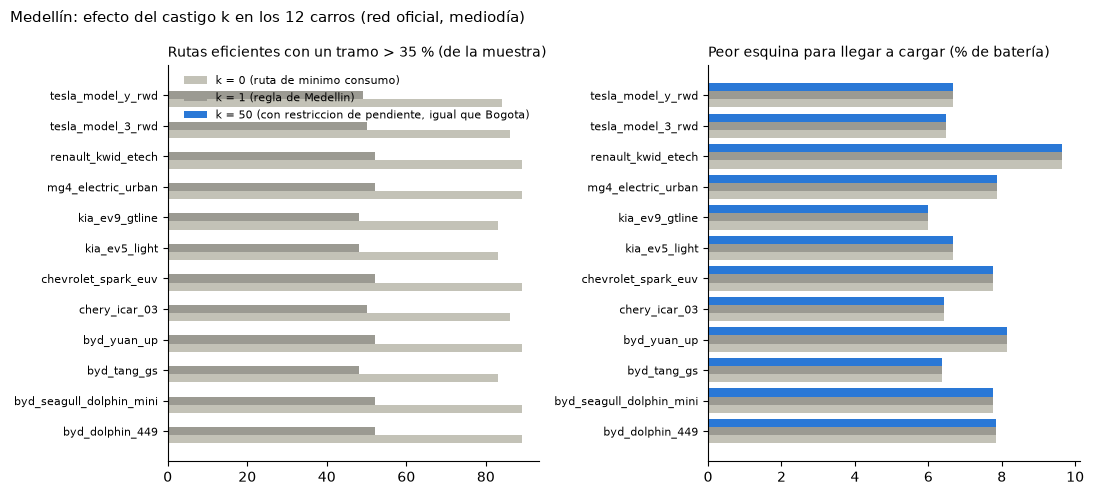

  [escrito] D4M_huellas_comparacion_k.json  sha 9886321a0b00...


In [17]:
# D4M — CELDA 13d: COMPARACION DEL CASTIGO k PARA LOS 12 CARROS
# Los 12 carros (red oficial, mediodia) con: k = 0 (ruta de minimo consumo, la comparacion
# central), el k de la regla de Medellin (1, sensibilidad) y el k del escenario con
# restriccion de pendiente (50, el mismo de Bogota). Las cifras de consumo y ahorro de esta
# celda son de la muestra SIN ponderar; las de toda la ciudad (ponderadas) estan en la 20b.
# Energia (la muestra de viajes) y alcanzabilidad
# (todas las esquinas). Lo ya corrido se toma de las celdas 11 y 13; lo nuevo se
# corre con las MISMAS funciones (correr_energia escribe su carpeta como siempre).
# Escribe en entregables/D4_medellin/comparacion_k/ sin sobrescribir.
# =============================================================================
PROP, VEH0, HORA0 = K.ESCENARIO_OFICIAL_D4M, K.VEHICULO_BASE_D4, K.HORA_BASE_D4
KS = sorted({0.0, float(K_PRINCIPAL), float(K_REGLA), float(K.K_REFERENCIA_BOGOTA_D4M)})
VEHS = sorted(VF.FLOTA)
DIR_K = f"{D4M}/comparacion_k"
 
# --- 1. Energia: reutiliza las corridas que ya existen; corre las que faltan ----------
_RE = RES_ENERGIA[(RES_ENERGIA["escenario"] == PROP) & (RES_ENERGIA["hora"] == HORA0)
                  & (RES_ENERGIA["pendiente"] == MODO) & (RES_ENERGIA["paradas"] == PARADAS)]
filas_e, _t0 = [], time.time()
_faltan = [(vh, kk) for kk in KS for vh in VEHS
           if not ((_RE["vehiculo"] == vh) & np.isclose(_RE["k"], kk)).any()]
print(f"Corridas de energia: {len(VEHS) * len(KS)} en total, {len(_faltan)} nuevas")
for kk in KS:
    for vh in VEHS:
        _f = _RE[(_RE["vehiculo"] == vh) & np.isclose(_RE["k"], kk)]
        if len(_f):
            filas_e.append(_f.iloc[0].to_dict())
        else:
            t1 = time.time()
            filas_e.append(correr_energia(PROP, vh, HORA0, MODO, PARADAS, kk))
            print(f"  {vh:<26} k={kk:<4g} {time.time() - t1:,.0f} s")
ENE_K = pd.DataFrame(filas_e)
print(f"Energia lista: {(time.time() - _t0) / 60:,.1f} min")
 
# --- 2. Alcanzabilidad con cada k (misma logica de la celda 13, k como parametro) ------
def alcanzabilidad_k(veh, k):
    T = ESC[PROP]
    T = T[T["en_red"]].reset_index(drop=True)
    dz = (T["v"].map(_zB) - T["u"].map(_zB)).to_numpy(float)
    v, _, _ = velocidades(T, HORA0)
    _pw = pesos_red(T, dz, v, veh, K.PENDIENTE_CONSUMO_D4)
    w = _pw["w"]
    es_ext = marca_extremas(T, dz)
    w_pl, _ = plano_extremas(_pw["Lc"], v, veh, K.CAPA_PARADAS_D4, es_ext)
    E, E_rt, raiz, verif, info = alcance(T, w, castigar(w, _pw["w_sin_regen"], w_pl, es_ext, k),
                                         EST[f"nodo_{PROP}"])
    f = K.FACTOR_SUBESTIMACION_D4
    wp = np.where(w > 0, w * f, w)
    Ep, _, _, verif_p, _ = alcance(T, wp, castigar(wp, _pw["w_sin_regen"] * f, w_pl * f, es_ext, k),
                                   EST[f"nodo_{PROP}"])
    assert verif and verif_p and np.isfinite(E).all() and np.isfinite(Ep).all(), f"{veh} k={k}"
    if k == 0:
        assert np.allclose(E, E_rt, rtol=1e-9, atol=1e-9), "sin castigo: energia real != costo"
    cap = VF.vehiculo(veh).bateria_util
    disp = (0.20 - K.RESERVA_BATERIA_D4) * cap
    return {"vehiculo": veh, "k": k, "peor_esquina_pct_bateria": round(100 * float(E.max()) / cap, 2),
            "energia_p50_kwh": round(float(np.median(E)), 4),
            "alcanzable_20pct": round(100 * float((E <= disp).mean()), 3),
            "alcanzable_20pct_pesimista": round(100 * float((Ep <= disp).mean()), 3)}
 
filas_a, _t0 = [], time.time()
for kk in KS:
    for vh in VEHS:
        filas_a.append(alcanzabilidad_k(vh, kk))
ALC_K = pd.DataFrame(filas_a)
print(f"Alcanzabilidad lista: {(time.time() - _t0) / 60:,.1f} min")
 
# --- 3. Pruebas (segundo camino) ------------------------------------------------------
pr_k2 = []
_a1 = ALC_K[np.isclose(ALC_K["k"], K_PRINCIPAL)].set_index("vehiculo")
_r1 = RES_ALC[RES_ALC["escenario"] == PROP].set_index("vehiculo")
pr_k2.append(("k de la regla: peor esquina = celda 13 (12 carros)",
              bool(np.allclose(_a1.loc[VEHS, "peor_esquina_pct_bateria"], _r1.loc[VEHS, "pct_bateria_max"], atol=0.006))))
pr_k2.append(("k de la regla: alcanzable 20 % = celda 13 (12 carros)",
              bool(np.allclose(_a1.loc[VEHS, "alcanzable_20pct"], _r1.loc[VEHS, "alcanzable_20pct"], atol=1e-3))))
_ext = ENE_K.pivot(index="vehiculo", columns="k", values="rutas_eficientes_con_tramo_extremo")
pr_k2.append(("mas castigo nunca aumenta las rutas con tramo extremo (12 carros)",
              bool(all((np.diff(_ext.loc[vh, KS].to_numpy()) <= 0).all() for vh in VEHS))))
_cor = ENE_K.pivot(index="vehiculo", columns="k", values="rutas_cortas_con_tramo_extremo")
pr_k2.append(("las rutas cortas no dependen de k", bool((_cor.nunique(axis=1) == 1).all())))
_df = pd.DataFrame(pr_k2, columns=["prueba", "pasa"])
_df["resultado"] = np.where(_df["pasa"], "PASA", "FALLA")
print("\nCOMPARACION DE k — pruebas")
print(_df[["prueba", "resultado"]].to_string(index=False))
assert _df["pasa"].all(), f"Fallan: {_df.loc[~_df['pasa'], 'prueba'].tolist()}"
 
# --- 4. Tabla y figura -------------------------------------------------------------------
_cols_e = ["vehiculo", "k", "consumo_corta_kwh_100km", "consumo_eficiente_kwh_100km",
           "ahorro_p90_pct", "viajes_ahorro_mayor_5pct", "extra_distancia_p90_pct",
           "rutas_eficientes_con_tramo_extremo", "rutas_cortas_con_tramo_extremo"]
COMP_K = (ENE_K[_cols_e].merge(ALC_K, on=["vehiculo", "k"], validate="one_to_one")
          .sort_values(["vehiculo", "k"]).reset_index(drop=True))
COMP_K.insert(1, "validado", COMP_K["vehiculo"].isin(K.VEHICULOS_VALIDADOS_D4))
_sha_ck = guardar_csv_sin_sobrescribir(COMP_K, K.ruta_entregable(DIR_K, "D4M_comparacion_k_por_carro.csv"))
for col, tit in (("consumo_eficiente_kwh_100km", "Consumo de la ruta eficiente (kWh/100 km, muestra sin ponderar)"),
                 ("ahorro_p90_pct", "Ahorro del 10 % de viajes que mas ahorra (%, muestra sin ponderar)"),
                 ("rutas_eficientes_con_tramo_extremo", "Rutas eficientes con un tramo > 35 % (de la muestra)"),
                 ("peor_esquina_pct_bateria", "Peor esquina para llegar a cargar (% de bateria)")):
    print(f"\n{tit}")
    print(COMP_K.pivot(index="vehiculo", columns="k", values=col)
          .rename(columns=lambda x: f"k={x:g}").to_string())
 
fig, axs = plt.subplots(1, 2, figsize=(11, 5))
_y = np.arange(len(VEHS)); _h = 0.8 / len(KS)
_col = {0.0: "#c3c2b7", float(K_REGLA): "#9b9a92", float(K.K_REFERENCIA_BOGOTA_D4M): "#eb6834",
        float(K_PRINCIPAL): "#2a78d6"}
for j, kk in enumerate(KS):
    _s = COMP_K[np.isclose(COMP_K["k"], kk)].set_index("vehiculo").loc[VEHS]
    _lab = ("k = 0 (ruta de minimo consumo)" if kk == 0 else
            f"k = {kk:g} (con restriccion de pendiente{', igual que Bogota' if kk == K.K_REFERENCIA_BOGOTA_D4M else ''})"
            if kk == K_PRINCIPAL else
            f"k = {kk:g} (regla de Medellin)" if kk == K_REGLA else f"k = {kk:g} (Bogota)")
    axs[0].barh(_y + j * _h, _s["rutas_eficientes_con_tramo_extremo"], height=_h, color=_col[kk], label=_lab)
    axs[1].barh(_y + j * _h, _s["peor_esquina_pct_bateria"], height=_h, color=_col[kk], label=_lab)
for a, t in zip(axs, ("Rutas eficientes con un tramo > 35 % (de la muestra)",
                      "Peor esquina para llegar a cargar (% de batería)")):
    a.set_yticks(_y + _h * (len(KS) - 1) / 2, VEHS, fontsize=8)
    a.set_title(t, loc="left", fontsize=10); a.spines[["top", "right"]].set_visible(False)
axs[0].legend(frameon=False, fontsize=8)
fig.suptitle("Medellín: efecto del castigo k en los 12 carros (red oficial, mediodía)",
             x=0.01, ha="left", fontsize=11)
fig.tight_layout()
_fk = K.ruta_entregable(DIR_K, "D4M_fig_comparacion_k.png")
if _fk.exists():
    print(f"  [figura ya existe, no se reescribe] {_fk.name}")
else:
    fig.savefig(_fk, dpi=200, bbox_inches="tight", facecolor="white"); print(f"  [figura escrita] {_fk.name}")
plt.show()
guardar_texto_sin_sobrescribir(json.dumps({
    "ks": KS, "k_principal": float(K_PRINCIPAL), "k_regla": float(K_REGLA),
    "k_bogota": float(K.K_REFERENCIA_BOGOTA_D4M),
    "escenario": PROP, "hora": HORA0, "vehiculos": VEHS,
    "archivos": {"D4M_comparacion_k_por_carro.csv": _sha_ck},
    "pruebas": [{"prueba": n, "pasa": ok} for n, ok in pr_k2]},
    indent=2, ensure_ascii=False, sort_keys=True, default=str),
    K.ruta_entregable(DIR_K, "D4M_huellas_comparacion_k.json"))
BITACORA["comparacion_k"] = {"sha256": _sha_ck, "pruebas": pr_k2}

In [18]:
# D4M — CELDA 13e: IR A CARGAR Y PODER VOLVER, con reserva declarada (por esquina)
# Complementa la celda 15e, que mira cada VIAJE.
# Pregunta: desde cada esquina, ¿con cuanta bateria hay que salir para ir a la
# estacion mas conveniente y, si alli NO se puede cargar (ocupada, incompatible o
# sin potencia declarada), volver a la esquina sin bajar de la reserva?
#   bateria necesaria = max(ir, ir + volver) + reserva
# (ir puede ser negativo: bajar a cargar recarga; por eso el max). Se mira al llegar
# a la estacion y al volver a la esquina, no calle por calle.
# 12 carros, red oficial, mediodia, con los mismos k de la celda 13d. Las rutas se
# eligen con el peso de ruteo (castigo k) y la energia que se reporta es la real.
# Misma logica que la celda 13b, con el carro y el k como parametros.
# Escribe en entregables/D4_medellin/alcanzabilidad/ir_a_cargar_y_volver/ sin sobrescribir.
# =============================================================================
PROP, VEH0, HORA0 = K.ESCENARIO_OFICIAL_D4M, K.VEHICULO_BASE_D4, K.HORA_BASE_D4
RES = K.RESERVA_BATERIA_D4
NIVELES = list(K.NIVELES_BATERIA_D4)
DIR_TC = f"{D4M}/alcanzabilidad/ir_a_cargar_y_volver"
_T = ESC[PROP]
_T = _T[_T["en_red"]].reset_index(drop=True)
_dz = (_T["v"].map(_zB) - _T["u"].map(_zB)).to_numpy(float)
_v, _, _ = velocidades(_T, HORA0)
_ext = marca_extremas(_T, _dz)
ST = (EST[["fila_inv", f"nodo_{PROP}"]].rename(columns={f"nodo_{PROP}": "nodo"}))
 
def ir_y_volver(veh, k):
    """Por esquina: energia REAL de ir a la estacion elegida y de volver desde ESA
    misma estacion (rutas elegidas con el peso de ruteo). Devuelve (nodos, ir, volver, ok)."""
    pw = pesos_red(_T, _dz, _v, veh, K.PENDIENTE_CONSUMO_D4)
    w = pw["w"]
    w_pl, _ = plano_extremas(pw["Lc"], _v, veh, K.CAPA_PARADAS_D4, _ext)
    n, iu, iv, wrt, seg = preparar_grafo(_T, castigar(w, pw["w_sin_regen"], w_pl, _ext, k))
    wreal = pd.Series(w, index=_T["segmento_id"].to_numpy()).loc[seg].to_numpy()
    h, met, _ = potenciales(n, iu, iv, wrt, _zB)
    assert met == "por_altura"
    E_rt, raiz, ok, P = energia_a_estacion(n, iu, iv, wrt, h, ST["nodo"], K.SEMILLA_OD_D4,
                                           devolver_padres=True)
    ir = real_hacia_estacion(P, iu, iv, wreal)
    ie = np.unique(n.get_indexer(ST["nodo"]))
    wr = np.maximum(wrt + h[iu] - h[iv], 0.0)
    _, Pf = dijkstra(csr_matrix((wr, (iu, iv)), shape=(len(n), len(n))), directed=True,
                     indices=ie, return_predecessors=True)
    Rf = np.vstack([real_desde_origen(Pf[j], ie[j], iu, iv, wreal) for j in range(len(ie))])
    fila = np.searchsorted(ie, raiz)
    ok &= bool(np.isin(raiz, ie).all() and (ie[np.minimum(fila, len(ie) - 1)] == raiz).all())
    volver = Rf[fila, np.arange(len(n))]
    return n, ir, volver, ok and bool(np.isfinite(ir).all() and np.isfinite(volver).all())
 
filas, por_ter, ok_todas, _t0 = [], [], True, time.time()
for kk in KS:
    for vh in VEHS:
        n, ir, vu, ok = ir_y_volver(vh, kk)
        ok_todas &= ok
        cap = VF.vehiculo(vh).bateria_util
        nec = 100 * (np.maximum(ir, ir + vu) / cap) + 100 * RES       # % de bateria al salir
        if vh == VEH0 and np.isclose(kk, K_PRINCIPAL):
            IR0, VU0, N0, NEC0 = ir, vu, n, nec
        fila = {"vehiculo": vh, "k": kk, "bateria_kwh": cap,
                "ir_mediana_kwh": round(float(np.median(ir)), 4),
                "volver_mediana_kwh": round(float(np.median(vu)), 4),
                "necesaria_mediana_pct": round(float(np.median(nec)), 2),
                "necesaria_p95_pct": round(float(np.percentile(nec, 95)), 2),
                "necesaria_peor_esquina_pct": round(float(nec.max()), 2),
                "solo_ir_peor_esquina_pct": round(float(100 * ir.max() / cap + 100 * RES), 2)}
        for b in NIVELES:
            fila[f"esquinas_ok_con_{round(100 * b)}pct"] = round(100 * float((nec <= 100 * b + 1e-9).mean()), 3)
        filas.append(fila)
        _z = pd.Index(n).map(_zB).to_numpy(float)
        _ladera = _z > Z_CORTE_LADERA
        for t, m in (("plano (valle)", ~_ladera), ("ladera", _ladera), ("Medellin", np.ones(len(n), bool))):
            por_ter.append({"vehiculo": vh, "k": kk, "terreno_esquina": t, "esquinas": int(m.sum()),
                            "necesaria_mediana_pct": round(float(np.median(nec[m])), 2),
                            "necesaria_peor_esquina_pct": round(float(nec[m].max()), 2),
                            **{f"esquinas_ok_con_{round(100 * b)}pct":
                               round(100 * float((nec[m] <= 100 * b + 1e-9).mean()), 3) for b in NIVELES}})
TC = pd.DataFrame(filas)
TC_TER = pd.DataFrame(por_ter)
print(f"Trayecto completo: {len(TC)} corridas en {(time.time() - _t0) / 60:,.1f} min")
 
# --- Pruebas (segundo camino) ----------------------------------------------------------
pr_tc = [("cada corrida: arbol verificado hacia adelante y toda esquina con ida y vuelta", ok_todas)]
_ll = LL.set_index("nodo")
pr_tc.append(("Dolphin, k de la regla: ir y volver = celda 13b (todas las esquinas)",
              bool(np.allclose(IR0, _ll.loc[N0, "energia_llegar_kwh"], rtol=1e-12, atol=1e-12)
                   and np.allclose(VU0, _ll.loc[N0, "energia_volver_kwh"], rtol=1e-12, atol=1e-12))))
_a = ALC_K.set_index(["vehiculo", "k"])
pr_tc.append(("solo ir: peor esquina = celda 13d (12 carros x cada k)",
              all(np.isclose(r["solo_ir_peor_esquina_pct"] - 100 * RES,
                             _a.loc[(r["vehiculo"], r["k"]), "peor_esquina_pct_bateria"], atol=0.011)
                  for _, r in TC.iterrows())))
pr_tc.append(("ida y vuelta nunca necesita menos que solo ir",
              bool((TC["necesaria_peor_esquina_pct"] >= TC["solo_ir_peor_esquina_pct"] - 1e-9).all())))
_ok_niv = TC[[f"esquinas_ok_con_{round(100 * b)}pct" for b in NIVELES]].to_numpy()
pr_tc.append(("mas bateria nunca deja menos esquinas cubiertas", bool((np.diff(_ok_niv, axis=1) >= 0).all())))
_rec = 100 * (np.maximum(IR0, IR0 + VU0) + RES * VF.vehiculo(VEH0).bateria_util) / VF.vehiculo(VEH0).bateria_util
pr_tc.append(("bateria necesaria recalculada por otro camino (Dolphin)", bool(np.allclose(_rec, NEC0))))
_df = pd.DataFrame(pr_tc, columns=["prueba", "pasa"])
_df["resultado"] = np.where(_df["pasa"], "PASA", "FALLA")
print("\nTRAYECTO COMPLETO — pruebas")
print(_df[["prueba", "resultado"]].to_string(index=False))
assert _df["pasa"].all(), f"Fallan: {_df.loc[~_df['pasa'], 'prueba'].tolist()}"
 
_c = ["vehiculo", "k", "necesaria_mediana_pct", "necesaria_p95_pct", "necesaria_peor_esquina_pct",
      "solo_ir_peor_esquina_pct"] + [f"esquinas_ok_con_{round(100 * b)}pct" for b in NIVELES]
print(f"\nBATERIA NECESARIA PARA IR A CARGAR Y PODER VOLVER, con reserva de {100 * RES:g} % "
      f"({PROP}, {HORA0:g} h)")
for kk in KS:
    print(f"\n  k = {kk:g}")
    print(TC[np.isclose(TC["k"], kk)][_c].drop(columns="k").to_string(index=False))
print(f"\n  Por terreno de la esquina (k = {K_PRINCIPAL:g}; ladera = altura > {Z_CORTE_LADERA:,.0f} m, "
      "el mismo corte de la muestra)")
print(TC_TER[np.isclose(TC_TER["k"], K_PRINCIPAL)].pivot(index="vehiculo", columns="terreno_esquina",
                                                       values="esquinas_ok_con_20pct").to_string())
 
_sha_tc = {
    "D4M_ir_a_cargar_y_volver_por_carro.csv":
        guardar_csv_sin_sobrescribir(TC, K.ruta_entregable(DIR_TC, "D4M_ir_a_cargar_y_volver_por_carro.csv")),
    "D4M_ir_a_cargar_y_volver_por_terreno.csv":
        guardar_csv_sin_sobrescribir(TC_TER, K.ruta_entregable(DIR_TC, "D4M_ir_a_cargar_y_volver_por_terreno.csv")),
}
guardar_texto_sin_sobrescribir(json.dumps({
    "estado": "version oficial", "escenario": PROP, "hora": HORA0, "k": KS,
    "definicion": "bateria al salir = max(ir, ir + volver a la esquina desde la misma estacion) + reserva",
    "reserva": RES, "niveles_bateria": NIVELES, "z_corte_ladera_m": Z_CORTE_LADERA,
    "archivos": _sha_tc, "pruebas": {p: bool(ok) for p, ok in pr_tc}},
    indent=2, ensure_ascii=False, sort_keys=True, default=str),
    K.ruta_entregable(DIR_TC, "D4M_huellas_ir_a_cargar_y_volver.json"))
BITACORA["ir_a_cargar_y_volver"] = {"sha256": _sha_tc, "pruebas": pr_tc}

Trayecto completo: 36 corridas en 2.9 min

TRAYECTO COMPLETO — pruebas
                                                                       prueba resultado
cada corrida: arbol verificado hacia adelante y toda esquina con ida y vuelta      PASA
         Dolphin, k de la regla: ir y volver = celda 13b (todas las esquinas)      PASA
                       solo ir: peor esquina = celda 13d (12 carros x cada k)      PASA
                                ida y vuelta nunca necesita menos que solo ir      PASA
                              mas bateria nunca deja menos esquinas cubiertas      PASA
                      bateria necesaria recalculada por otro camino (Dolphin)      PASA

BATERIA NECESARIA PARA IR A CARGAR Y PODER VOLVER, con reserva de 10 % (sens_sin_altura_A, 12 h)

  k = 0
                vehiculo  necesaria_mediana_pct  necesaria_p95_pct  necesaria_peor_esquina_pct  solo_ir_peor_esquina_pct  esquinas_ok_con_20pct  esquinas_ok_con_50pct  esquinas_ok_con_80pct
         byd_dol

# Validación independiente

Red: 38,826 tramos, 16,156 esquinas
  origen  1/10: 1 s
  origen  2/10: 3 s
  origen  3/10: 4 s
  origen  4/10: 4 s
  origen  5/10: 6 s
  origen  6/10: 8 s
  origen  7/10: 9 s
  origen  8/10: 10 s
  origen  9/10: 12 s
  origen 10/10: 13 s

PRUEBA 1 — misma energia con un algoritmo y una libreria distintos
 par  energia_D4_kwh  energia_networkx_kwh  dif_Wh
4080         1.71507               1.71508   0.005
3661         1.75011               1.75010  -0.004
2558         4.34717               4.34717  -0.001
2136         2.38128               2.38128  -0.005
3326         0.38682               0.38683   0.006
 324         0.25156               0.25156   0.000
3463         1.32061               1.32060  -0.002
3523         2.45066               2.45066  -0.003
4035         4.01048               4.01048  -0.001
3511         1.99313               1.99313   0.002

PRUEBA 2 — fisica de ida y vuelta (161,550 parejas)
  asimetria = 7.594 Wh por metro de desnivel  (R² = 0.998)
  rango fisico esper

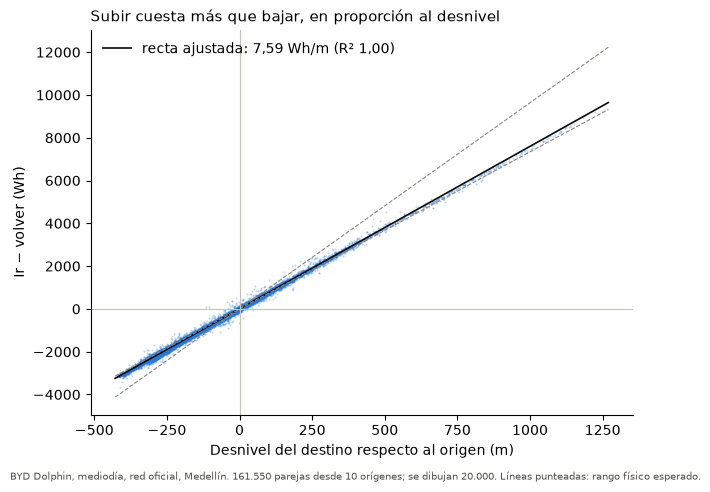

  [escrito] D4M_validacion_bellman_ford_networkx.csv
  [escrito] D4M_validacion_ruteo_pruebas.csv


In [19]:
# =============================================================================
# D4M — CELDA 14: VALIDACION INDEPENDIENTE DEL RUTEO POR ENERGIA (solo lee de disco)
# Prueba 1: networkx + Bellman-Ford puro (sin alturas de energia, sin Johnson)
#           debe dar las mismas energias minimas que guardo D4.
# Prueba 2: fisica de ida y vuelta: A->B->A nunca genera energia; subir cuesta
#           mas que bajar; la asimetria crece con el desnivel.
# Dolphin, mediodia, red oficial. Escribe solo en D4_medellin/validacion_ruteo/.
# =============================================================================
import time, hashlib, json
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import constantes_d1 as K
from d1_procedencia import sha256_archivo

D4M = "D4_medellin"

PROP, VEH0, HORA0 = K.ESCENARIO_OFICIAL_D4M, K.VEHICULO_BASE_D4, K.HORA_BASE_D4
E = K.RUTA_ENTREGABLES / D4M
N_ORIGENES = 10                      # origenes con Bellman-Ford completo (cada uno: toda la red)
rng19 = np.random.default_rng(K.SEMILLA_OD_D4)

# --- Lectura de disco ----------------------------------------------------------------
_KP = json.loads((E / "elegir_k" / "D4M_k_adoptado.json").read_text(encoding="utf-8"))["k_principal"]
_tag = (f"esc_{PROP}__{VEH0}__h{HORA0:g}__{K.PENDIENTE_CONSUMO_D4}__long_{K.LONGITUD_CONSUMO_D4}"
        f"__{'con' if K.CAPA_PARADAS_D4 else 'sin'}_paradas__k{_KP:g}")
_dE = E / "energia" / _tag
PES = pd.read_csv(_dE / "D4M_pesos_energia.csv", dtype={"segmento_id": "string"})
CMP = pd.read_csv(_dE / "D4M_comparacion_rutas.csv", dtype={"tramos_eficiente": "string"})
ARI = pd.read_csv(E / f"esc_{PROP}" / f"D4M_aristas_{PROP}.csv",
                  dtype={"segmento_id": "string", "u": "string", "v": "string"},
                  usecols=["segmento_id", "u", "v", "en_red"], low_memory=False)
ARI = ARI[ARI["en_red"].astype(str) == "True"]
RD = pd.read_csv(E / f"esc_{PROP}" / f"D4M_rutas_distancia_{PROP}.csv",
                 dtype={"origen": "string", "destino": "string"}, usecols=["origen", "destino"])
Z = (pd.read_csv(E / "alturas_esquinas" / "D4M_alturas_esquinas.csv",
                 dtype={"nodo": "string"}, usecols=["nodo", "z_m"]).set_index("nodo")["z_m"])
assert len(RD) == len(CMP), "Muestra de pares y comparacion no tienen el mismo largo"
T = ARI.merge(PES[["segmento_id", "consumo_kwh", "peso_ruteo_kwh"]], on="segmento_id",
              validate="one_to_one")
assert len(T) == len(ARI), "Hay tramos de la red sin peso de energia"
print(f"Red: {len(T):,} tramos, {T[['u','v']].stack().nunique():,} esquinas")

# Grafo independiente: entre dos esquinas con varias calles, la mas barata
_m = T.groupby(["u", "v"], as_index=False)["consumo_kwh"].min()
G = nx.DiGraph()
G.add_weighted_edges_from(zip(_m["u"], _m["v"], _m["consumo_kwh"]), weight="w")
GR = G.reverse(copy=False)
# La prueba 1 compara la RUTA ELEGIDA: con el peso de ruteo (castigo k). La prueba 2
# (fisica de ida y vuelta) sigue con la energia real.
_mr = T.groupby(["u", "v"], as_index=False)["peso_ruteo_kwh"].min()
G_RT = nx.DiGraph()
G_RT.add_weighted_edges_from(zip(_mr["u"], _mr["v"], _mr["peso_ruteo_kwh"]), weight="w")
pr_19 = []

# --- Segundo camino previo: energia de cada ruta guardada = suma de sus tramos -------
_W = PES.set_index("segmento_id")["consumo_kwh"]
_suma = np.array([_W.loc[t.split(";")].sum() for t in CMP["tramos_eficiente"]])
_d0 = float(np.max(np.abs(_suma - CMP["energia_eficiente_kwh"])))
pr_19.append({"prueba": "energia guardada = suma de los pesos de sus tramos (todas las rutas)",
              "dif_max_kWh": _d0, "pasa": _d0 < 5e-4})

# --- PRUEBA 1: Bellman-Ford puro (networkx) vs lo que guardo D4 -----------------------
_idx = rng19.choice(len(RD), size=N_ORIGENES, replace=False)
filas1, IDA, VUELTA, t0 = [], {}, {}, time.time()
for k in _idx:
    o, d = RD.at[k, "origen"], RD.at[k, "destino"]
    ida = nx.single_source_bellman_ford_path_length(G, o, weight="w")      # o -> todas
    vuelta = nx.single_source_bellman_ford_path_length(GR, o, weight="w")  # todas -> o
    IDA[o], VUELTA[o] = ida, vuelta
    ida_rt = ida if _KP == 0 else nx.single_source_bellman_ford_path_length(G_RT, o, weight="w")
    filas1.append({"par": int(CMP.at[k, "par"]), "origen": o, "destino": d,
                   "energia_D4_kwh": float(CMP.at[k, "costo_ruteo_eficiente_kwh"]),
                   "energia_networkx_kwh": float(ida_rt[d])})
    print(f"  origen {len(filas1):>2}/{N_ORIGENES}: {time.time() - t0:,.0f} s")
P1 = pd.DataFrame(filas1)
P1["dif_Wh"] = 1000 * (P1["energia_networkx_kwh"] - P1["energia_D4_kwh"])
_d1 = float(P1["dif_Wh"].abs().max())
pr_19.append({"prueba": f"Bellman-Ford puro (networkx) = energia de D4 ({N_ORIGENES} pares)",
              "dif_max_Wh": _d1, "pasa": _d1 < 0.5})
print("\nPRUEBA 1 — misma energia con un algoritmo y una libreria distintos")
print(P1[["par", "energia_D4_kwh", "energia_networkx_kwh", "dif_Wh"]].round(5).to_string(index=False))

# --- PRUEBA 2: fisica de ida y vuelta (todas las esquinas, desde cada origen) --------
f = []
for o in IDA:
    comunes = [v for v in IDA[o] if v in VUELTA[o] and v != o]
    a = np.array([IDA[o][v] for v in comunes]); b = np.array([VUELTA[o][v] for v in comunes])
    dz = Z.reindex(comunes).to_numpy() - Z.get(o, np.nan)
    f.append(pd.DataFrame({"origen": o, "destino": comunes, "ida_kwh": a, "vuelta_kwh": b, "dz_m": dz}))
P2 = pd.concat(f, ignore_index=True).dropna(subset=["dz_m"])
P2["vuelta_completa_kwh"] = P2["ida_kwh"] + P2["vuelta_kwh"]
P2["asimetria_kwh"] = P2["ida_kwh"] - P2["vuelta_kwh"]          # ir (o->v) menos volver (v->o)

# a) Teorema: dar la vuelta A -> B -> A nunca genera energia
_neg = int((P2["vuelta_completa_kwh"] <= 0).sum())
pr_19.append({"prueba": "ir y volver nunca genera energia (todas las parejas)",
              "parejas": len(P2), "negativas": _neg, "pasa": _neg == 0})
# b) Subir cuesta mas que bajar: con mas de 20 m de desnivel, la asimetria tiene el signo del desnivel
_g = P2[P2["dz_m"].abs() > 20]
_sig = float(100 * (np.sign(_g["asimetria_kwh"]) == np.sign(_g["dz_m"])).mean())
pr_19.append({"prueba": "con > 20 m de desnivel, subir cuesta mas que bajar",
              "parejas": len(_g), "pct_cumple": round(_sig, 3), "pasa": _sig > 99.0})
# c) La asimetria crece con el desnivel: recta y comparacion con la fisica
pend, inter = np.polyfit(P2["dz_m"], P2["asimetria_kwh"], 1)
r2 = float(np.corrcoef(P2["dz_m"], P2["asimetria_kwh"])[0, 1] ** 2)
import sys
if str(K.CARPETA_MODELO_CONSUMO_MED) not in sys.path:      # los modulos del modelo de consumo viven en su carpeta
    sys.path.insert(0, str(K.CARPETA_MODELO_CONSUMO_MED))
import vehiculos_flota as VF, parametros as PAR
_p = VF.vehiculo(VEH0)
_mg = _p.m_ensayo * PAR.G / 3.6e6                                 # kWh por metro de subida (sin perdidas)
lim_bajo = _mg * (1 / _p.eta_traccion + _p.frac_regen * _p.eta_regen)
lim_alto = _mg * 2 / _p.eta_traccion
print(f"\nPRUEBA 2 — fisica de ida y vuelta ({len(P2):,} parejas)")
print(f"  asimetria = {1000 * pend:.3f} Wh por metro de desnivel  (R² = {r2:.3f})")
print(f"  rango fisico esperado: {1000 * lim_bajo:.3f} a {1000 * lim_alto:.3f} Wh/m "
      "(bajadas con regeneracion ... bajadas suaves sin regenerar)")
pr_19.append({"prueba": "la asimetria crece con el desnivel (R² > 0,9)",
              "R2": round(r2, 4), "pasa": r2 > 0.9})
pr_19.append({"prueba": "pendiente de la recta dentro del rango fisico",
              "Wh_por_m": round(1000 * pend, 4), "pasa": bool(lim_bajo * 0.95 <= pend <= lim_alto * 1.05)})

_df = pd.DataFrame(pr_19)
_df["resultado"] = np.where(_df["pasa"], "PASA", "FALLA")
print("\nVALIDACION INDEPENDIENTE DEL RUTEO")
print(_df[["prueba", "resultado"]].to_string(index=False))

# --- Figura de la prueba 2 -----------------------------------------------------------
_s = P2.sample(min(20000, len(P2)), random_state=1)
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(_s["dz_m"], 1000 * _s["asimetria_kwh"], s=2, alpha=0.3, color="#2a78d6", linewidths=0)
_x = np.array([P2["dz_m"].min(), P2["dz_m"].max()])
ax.plot(_x, 1000 * (pend * _x + inter), color="#0b0b0b", linewidth=1.2,
        label=f"recta ajustada: {1000 * pend:.2f} Wh/m (R² {r2:.2f})".replace(".", ","))
for lim, txt in ((lim_bajo, "límite físico inferior"), (lim_alto, "límite físico superior")):
    ax.plot(_x, 1000 * lim * _x, color="#898781", linewidth=0.8, linestyle="--")
ax.axhline(0, color="#c3c2b7", linewidth=0.8); ax.axvline(0, color="#c3c2b7", linewidth=0.8)
ax.set_xlabel("Desnivel del destino respecto al origen (m)")
ax.set_ylabel("Ir − volver (Wh)")
ax.set_title("Subir cuesta más que bajar, en proporción al desnivel", loc="left", fontsize=11)
ax.legend(frameon=False, loc="upper left")
ax.spines[["top", "right"]].set_visible(False)
_n_txt = f"{len(P2):,}".replace(",", ".")          # 877.510 con punto de miles
fig.text(0.01, -0.02, f"BYD Dolphin, mediodía, red oficial, Medellín. {_n_txt} parejas desde "
         f"{N_ORIGENES} orígenes; se dibujan 20.000. Líneas punteadas: rango físico esperado.",
         fontsize=7, color="#52514e")
_fig = K.ruta_entregable(f"{D4M}/validacion_ruteo", "D4M_fig_fisica_ida_y_vuelta.png")
if _fig.exists():
    print(f"  [figura ya existe, no se reescribe] {_fig.name}")
else:
    fig.savefig(_fig, dpi=200, bbox_inches="tight", facecolor="white")
    print(f"  [figura escrita] {_fig.name}")
plt.show()

# --- Salidas (sin sobrescribir) -------------------------------------------------------
def _guardar(df, nombre):
    ruta = K.ruta_entregable(f"{D4M}/validacion_ruteo", nombre)
    b = df.to_csv(index=False, float_format="%.6f", lineterminator="\n").encode("utf-8")
    h = hashlib.sha256(b).hexdigest()
    if ruta.exists():
        assert sha256_archivo(ruta) == h, f"{nombre} ya existe con otro contenido. No se reescribe."
        print(f"  [ya existe, identico] {nombre}")
    else:
        ruta.write_bytes(b); print(f"  [escrito] {nombre}")
_guardar(P1, "D4M_validacion_bellman_ford_networkx.csv")
_guardar(_df.drop(columns="resultado"), "D4M_validacion_ruteo_pruebas.csv")
assert _df["pasa"].all(), f"Fallan: {_df.loc[~_df['pasa'], 'prueba'].tolist()}"

# Figuras, ahorro, rutas a ojo y archivo para el modulo de consumo (solo leen de disco)

Esquinas: 16,156   calles fisicas: 23,405   bateria: 44.9 kWh
                                                    prueba resultado
                  peor esquina = resumen de alcanzabilidad      PASA
llegar (15b) = energia de la celda 15, esquina por esquina      PASA
                            toda esquina tiene coordenadas      PASA
               toda estacion esta en una esquina de la red      PASA
               franjas de altura: suman todas las esquinas      PASA
                                todo carro tiene su nombre      PASA
  [figura escrita] D4M_fig1_mapa_llegar_a_cargar_v1.png


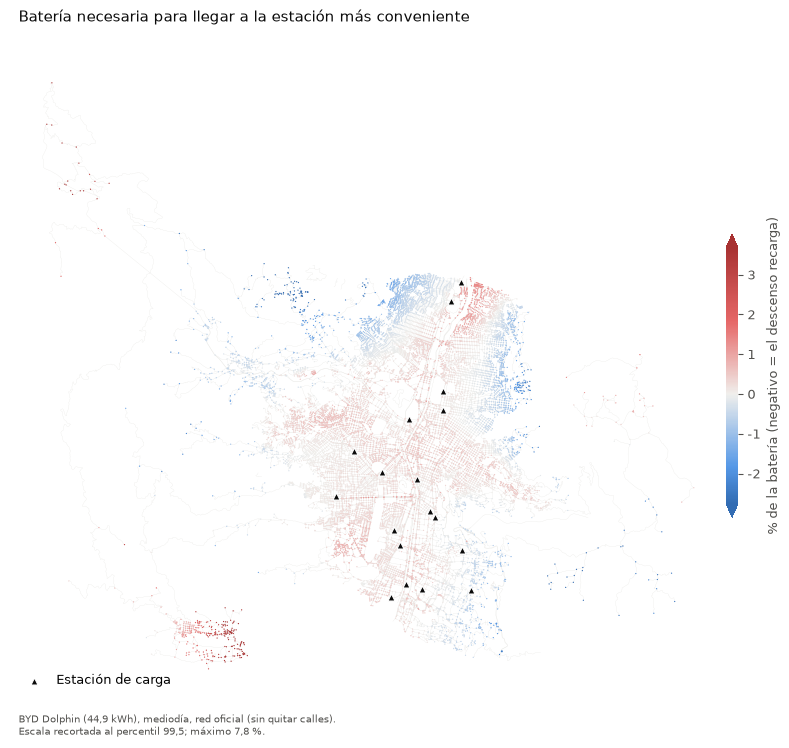

  [figura escrita] D4M_fig2_mapa_volver_menos_llegar_v1.png


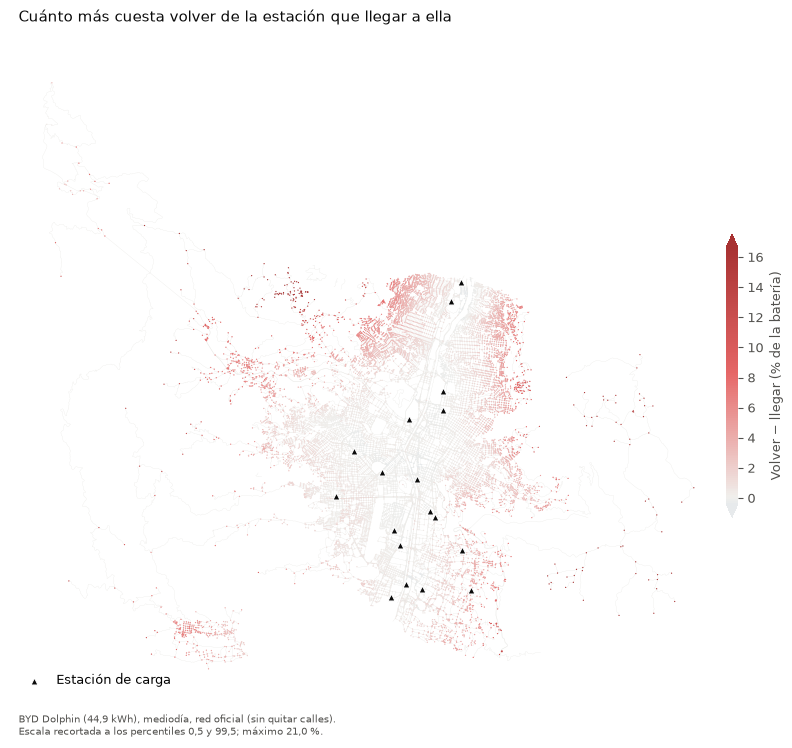

  [figura escrita] D4M_fig3_llegar_vs_volver_por_altura_v1.png


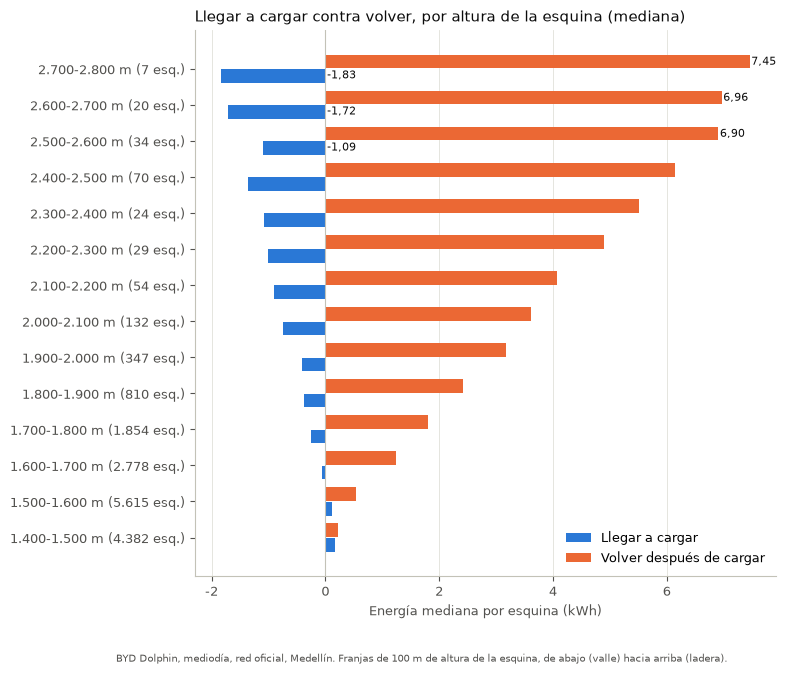

  [figura escrita] D4M_fig4_peor_esquina_por_carro_v1.png


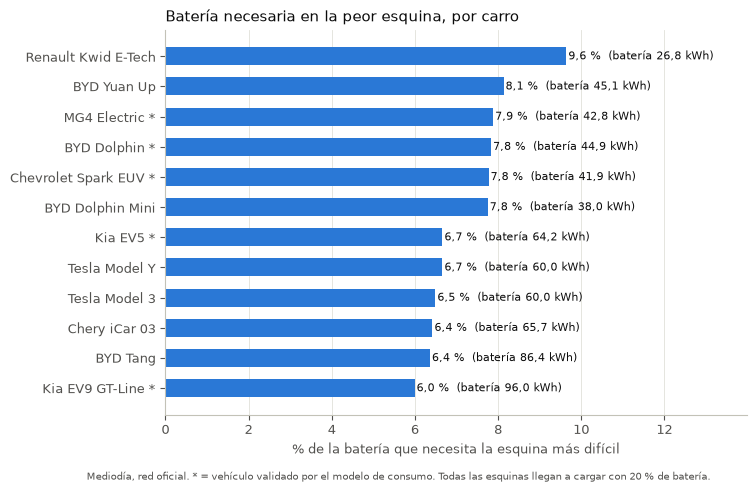

  [figura escrita] D4M_fig5_ahorro_ruta_eficiente_v1.png


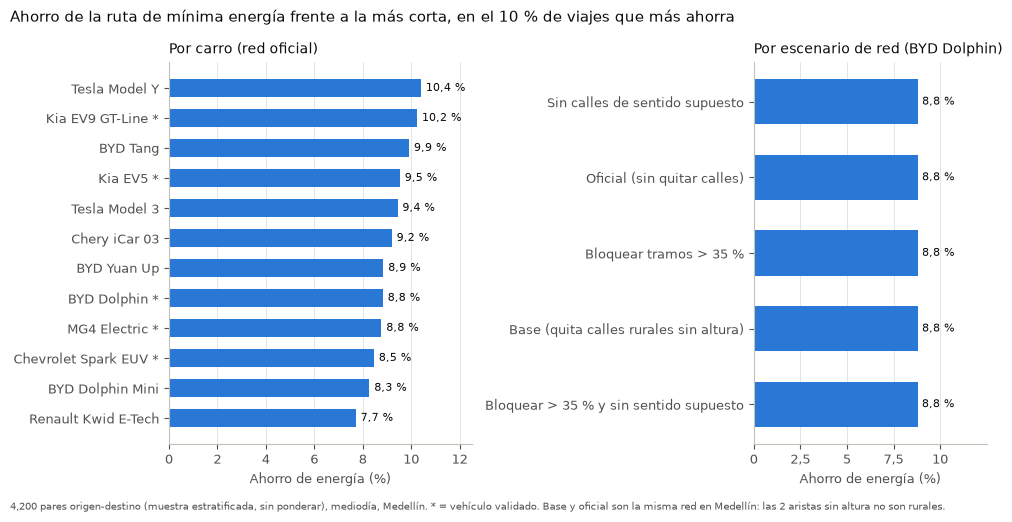

In [20]:
# =============================================================================
# D4M — CELDA 17: FIGURAS PARA LA TESIS — MEDELLIN (lee todo de disco; no recalcula nada)
# Dolphin, mediodia, red oficial. Cada figura comprueba sus numeros
# contra las tablas resumen antes de guardarse. Escribe en D4_medellin/figuras/
# y no sobrescribe. Mismo estilo que las figuras de Bogota; en vez de localidad
# se agrupa por franja de altura de la esquina (celda 13b).
# =============================================================================
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.ticker import FuncFormatter
import constantes_d1 as K

PROP, VEH0, HORA0 = K.ESCENARIO_OFICIAL_D4M, K.VEHICULO_BASE_D4, K.HORA_BASE_D4
E = K.RUTA_ENTREGABLES / "D4_medellin"
FIG, VERSION = "D4_medellin/figuras", "v1"

# Paleta (validada): azul y naranja para 2 series; divergente azul-gris-rojo
AZUL, NARANJA = "#2a78d6", "#eb6834"
TINTA, TINTA2, EJE, REJILLA = "#0b0b0b", "#52514e", "#c3c2b7", "#e1e0d9"
DIVERGENTE = LinearSegmentedColormap.from_list(
    "azul_gris_rojo", ["#104281", "#5598e7", "#f0efec", "#e66767", "#a83232"])
plt.rcParams.update({"font.family": "sans-serif", "font.size": 9,
                     "axes.edgecolor": EJE, "axes.labelcolor": TINTA2,
                     "xtick.color": TINTA2, "ytick.color": TINTA2,
                     "axes.spines.top": False, "axes.spines.right": False})

def coma(x, decimales=1):
    """Numero con coma decimal (espanol)."""
    return f"{x:.{decimales}f}".replace(".", ",")

FMT_COMA = FuncFormatter(lambda x, _: f"{x:g}".replace(".", ","))

CARROS = {"byd_dolphin_449": "BYD Dolphin", "byd_seagull_dolphin_mini": "BYD Dolphin Mini",
          "byd_tang_gs": "BYD Tang", "byd_yuan_up": "BYD Yuan Up",
          "chery_icar_03": "Chery iCar 03", "chevrolet_spark_euv": "Chevrolet Spark EUV",
          "kia_ev5_light": "Kia EV5", "kia_ev9_gtline": "Kia EV9 GT-Line",
          "mg4_electric_urban": "MG4 Electric", "renault_kwid_etech": "Renault Kwid E-Tech",
          "tesla_model_3_rwd": "Tesla Model 3", "tesla_model_y_rwd": "Tesla Model Y"}

def etiqueta_carro(v, validado):
    return CARROS.get(v, v) + (" *" if validado else "")

def guardar_figura(fig, nombre, version=VERSION):
    nombre = nombre.replace(".png", f"_{version}.png")
    ruta = K.ruta_entregable(FIG, nombre)
    if ruta.exists():
        print(f"  [figura ya existe, no se reescribe] {nombre}")
    else:
        fig.savefig(ruta, dpi=200, bbox_inches="tight", facecolor="white")
        print(f"  [figura escrita] {nombre}")
    plt.show()

# --- Lectura de disco -------------------------------------------------------------
import json
_KP = json.loads((E / "elegir_k" / "D4M_k_adoptado.json").read_text(encoding="utf-8"))["k_principal"]
_carp = (E / "alcanzabilidad" / f"esc_{PROP}__{VEH0}__h{HORA0:g}__{K.PENDIENTE_CONSUMO_D4}"
         f"__{'con' if K.CAPA_PARADAS_D4 else 'sin'}_paradas__k{_KP:g}")
ALC = pd.read_csv(_carp / "D4M_alcanzabilidad_esquinas.csv", dtype={"nodo": "string"})
LLS = pd.read_csv(E / "alcanzabilidad" / "extra" / "D4M_llegar_vs_salir_esquinas.csv",
                  dtype={"nodo": "string"})
PLOC = pd.read_csv(E / "alcanzabilidad" / "extra" / "D4M_llegar_vs_salir_por_franja_altura.csv")
RALC = pd.read_csv(E / "alcanzabilidad" / "D4M_resumen_alcanzabilidad.csv")
RENE = pd.read_csv(E / "energia" / "D4M_resumen_energia.csv")
XY = (pd.read_csv(E / "alturas_esquinas" / "D4M_alturas_esquinas.csv",
                  dtype={"nodo": "string"}, usecols=["nodo", "x", "y"]).set_index("nodo"))
ESTF = pd.read_csv(E / "estaciones" / "D4M_estaciones_enganche.csv",
                   dtype={f"nodo_{PROP}": "string"})
_gp = (K.RUTA_ENTREGABLES / "D3_medellin" / f"rama_{K.RAMA_OFICIAL_MED}"
       / f"D3M_grafo_con_pendiente_{K.RAMA_OFICIAL_MED}.gpkg")
CALLES = (gpd.read_file(_gp, layer="grafo", columns=["id_eje", "parte"])
          .drop_duplicates(["id_eje", "parte"]))
CAP = float(RALC.loc[(RALC["escenario"] == PROP) & (RALC["vehiculo"] == VEH0), "bateria_kwh"].iat[0])
print(f"Esquinas: {len(ALC):,}   calles fisicas: {len(CALLES):,}   bateria: {CAP} kWh")

# --- Pruebas: los archivos dicen lo mismo entre si (segundo camino) ---------------
pr_17 = []
_r = RALC[(RALC["escenario"] == PROP) & (RALC["vehiculo"] == VEH0)].iloc[0]
pr_17.append(("peor esquina = resumen de alcanzabilidad",
              np.isclose(round(ALC["pct_bateria"].max(), 2), _r["pct_bateria_max"], atol=0.006)))
_m = ALC.merge(LLS, on="nodo", validate="one_to_one")
pr_17.append(("llegar (15b) = energia de la celda 15, esquina por esquina",
              bool(len(_m) == len(ALC) and np.allclose(_m["energia_kwh"], _m["energia_llegar_kwh"],
                                                       rtol=1e-6, atol=1e-6))))
pr_17.append(("toda esquina tiene coordenadas", bool(ALC["nodo"].isin(XY.index).all())))
pr_17.append(("toda estacion esta en una esquina de la red",
              bool(ESTF[f"nodo_{PROP}"].isin(set(ALC["nodo"])).all())))
pr_17.append(("franjas de altura: suman todas las esquinas", int(PLOC["esquinas"].sum()) == len(ALC)))
_car_falta = sorted(set(RALC["vehiculo"]) - set(CARROS))
pr_17.append(("todo carro tiene su nombre", not _car_falta))
_df = pd.DataFrame(pr_17, columns=["prueba", "pasa"])
_df["resultado"] = np.where(_df["pasa"], "PASA", "FALLA")
print(_df[["prueba", "resultado"]].to_string(index=False))
assert _df["pasa"].all(), (f"Fallan: {_df.loc[~_df['pasa'], 'prueba'].tolist()} "
                           f"carros: {_car_falta}")

_xy = XY.loc[ALC["nodo"]]
_est_xy = XY.loc[ESTF[f"nodo_{PROP}"].unique()]

def mapa(valores, titulo, etiqueta, nota, nombre):
    """Mapa de esquinas. La escala se ajusta a los datos (percentiles 0,5 y 99,5):
    si casi no hay negativos, el lado azul se achica en vez de quedar vacio."""
    v = np.asarray(valores, float)
    alto = np.percentile(v, 99.5)
    bajo = min(np.percentile(v, 0.5), 0.0)
    # Escala HONESTA: un punto porcentual cambia el color lo mismo hacia los dos
    # lados (como una escala simetrica de -M a +M), pero la paleta se recorta al
    # rango que existe en los datos. Asi lo casi nulo se ve gris, no azul fuerte.
    M = max(alto, -bajo)
    f0 = (bajo + M) / (2 * M)                         # donde empieza 'bajo' en la paleta simetrica
    f1 = (alto + M) / (2 * M)                         # donde termina 'alto' (1 si alto >= -bajo)
    cmap = LinearSegmentedColormap.from_list("recortada", DIVERGENTE(np.linspace(f0, f1, 256)))
    norm = Normalize(vmin=bajo, vmax=alto)
    orden = np.argsort(np.abs(v))                    # los extremos se dibujan encima
    fig, ax = plt.subplots(figsize=(8.6, 7.4))
    CALLES.plot(ax=ax, color="#d9d8d2", linewidth=0.12, zorder=1)
    sc = ax.scatter(_xy["x"].to_numpy()[orden], _xy["y"].to_numpy()[orden], c=v[orden],
                    s=0.8, cmap=cmap, norm=norm, linewidths=0, zorder=2)
    ax.scatter(_est_xy["x"], _est_xy["y"], s=26, marker="^", facecolor=TINTA,
               edgecolor="white", linewidth=0.8, zorder=3, label="Estación de carga")
    cb = fig.colorbar(sc, ax=ax, shrink=0.42, pad=0.0, aspect=25,
                      extend="both" if bajo < 0 else "max")
    cb.set_label(etiqueta, color=TINTA2); cb.outline.set_visible(False)
    cb.ax.yaxis.set_major_formatter(FMT_COMA)
    ax.legend(loc="lower left", frameon=False, borderaxespad=0.5)
    ax.set_axis_off(); ax.set_aspect("equal")
    fig.suptitle(titulo, x=0.02, y=0.99, ha="left", fontsize=11, color=TINTA)
    fig.text(0.02, 0.01, nota, fontsize=7, color=TINTA2, wrap=True)
    fig.subplots_adjust(left=0.01, right=0.99, top=0.95, bottom=0.04)
    guardar_figura(fig, nombre)

_base_nota = f"BYD Dolphin ({coma(CAP)} kWh), mediodía, red oficial (sin quitar calles)."

# --- Figura 1: bateria para llegar a cargar ---------------------------------------
_pmax = ALC["pct_bateria"].max()
mapa(ALC["pct_bateria"],
     "Batería necesaria para llegar a la estación más conveniente",
     "% de la batería (negativo = el descenso recarga)",
     _base_nota + f"\nEscala recortada al percentil 99,5; máximo {coma(_pmax)} %.",
     "D4M_fig1_mapa_llegar_a_cargar.png")

# --- Figura 2: cuanto mas cuesta volver que ir --------------------------------------
_dif = 100 * _m["diferencia_kwh"].to_numpy() / CAP
mapa(_dif,
     "Cuánto más cuesta volver de la estación que llegar a ella",
     "Volver − llegar (% de la batería)",
     _base_nota + f"\nEscala recortada a los percentiles 0,5 y 99,5; máximo {coma(_dif.max())} %.",
     "D4M_fig2_mapa_volver_menos_llegar.png")

# --- Figura 3: llegar vs volver por franja de altura --------------------------------------
P = PLOC.sort_values("z_media_m").reset_index(drop=True)
fig, ax = plt.subplots(figsize=(7.5, max(4, 0.4 * len(P) + 1.5)))
yy = np.arange(len(P)); h = 0.38
ax.barh(yy - h / 2 - 0.01, P["llegar_mediana_kwh"], height=h, color=AZUL, label="Llegar a cargar")
ax.barh(yy + h / 2 + 0.01, P["volver_mediana_kwh"], height=h, color=NARANJA, label="Volver después de cargar")
ax.set_yticks(yy, [f"{s} ({n:,} esq.)".replace(",", ".") for s, n in zip(P["franja_altura"], P["esquinas"])])
ax.axvline(0, color=EJE, linewidth=0.8)
ax.xaxis.grid(True, color=REJILLA, linewidth=0.6); ax.set_axisbelow(True)
ax.xaxis.set_major_formatter(FMT_COMA)
ax.set_xlabel("Energía mediana por esquina (kWh)")
for i in P["diferencia_mediana_kwh"].nlargest(3).index:   # rotulos solo en las 3 mas desiguales
    ax.text(P.at[i, "volver_mediana_kwh"] + 0.03, i + h / 2, coma(P.at[i, "volver_mediana_kwh"], 2),
            va="center", fontsize=8, color=TINTA)
    ax.text(max(P.at[i, "llegar_mediana_kwh"], 0) + 0.03, i - h / 2,
            coma(P.at[i, "llegar_mediana_kwh"], 2), va="center", fontsize=8, color=TINTA)
ax.legend(loc="lower right", frameon=False)
ax.set_title("Llegar a cargar contra volver, por altura de la esquina (mediana)", loc="left",
             fontsize=11, color=TINTA)
fig.text(0.02, -0.01, "BYD Dolphin, mediodía, red oficial, Medellín. Franjas de 100 m "
         "de altura de la esquina, de abajo (valle) hacia arriba (ladera).",
         fontsize=7, color=TINTA2)
guardar_figura(fig, "D4M_fig3_llegar_vs_volver_por_altura.png")

# --- Figura 4: peor esquina por carro -----------------------------------------------
V = RALC[RALC["escenario"] == PROP].sort_values("pct_bateria_max").reset_index(drop=True)
assert len(V) == 12, f"Se esperaban 12 carros, hay {len(V)}"
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.barh(V.index, V["pct_bateria_max"], height=0.6, color=AZUL)
ax.set_yticks(V.index, [etiqueta_carro(v, ok) for v, ok in zip(V["vehiculo"], V["validado"])])
for i, (p, b) in enumerate(zip(V["pct_bateria_max"], V["bateria_kwh"])):
    ax.text(p + 0.05, i, f"{coma(p)} %  (batería {coma(b)} kWh)", va="center", fontsize=8, color=TINTA)
ax.xaxis.grid(True, color=REJILLA, linewidth=0.6); ax.set_axisbelow(True)
ax.xaxis.set_major_formatter(FMT_COMA)
ax.set_xlim(0, V["pct_bateria_max"].max() * 1.45)
ax.set_xlabel("% de la batería que necesita la esquina más difícil")
ax.set_title("Batería necesaria en la peor esquina, por carro", loc="left", fontsize=11, color=TINTA)
fig.text(0.02, -0.02, "Mediodía, red oficial. * = vehículo validado por el modelo de consumo. "
         "Todas las esquinas llegan a cargar con 20 % de batería.", fontsize=7, color=TINTA2)
guardar_figura(fig, "D4M_fig4_peor_esquina_por_carro.png")

# --- Figura 5: ahorro de la ruta eficiente ------------------------------------------
RENE = RENE[(RENE["pendiente"] == K.PENDIENTE_CONSUMO_D4)
            & (RENE["paradas"].astype(str) == str(bool(K.CAPA_PARADAS_D4)))
            & np.isclose(RENE["k"], _KP)]
A = (RENE[(RENE["escenario"] == PROP) & (RENE["hora"] == HORA0)]
     .sort_values("ahorro_p90_pct").reset_index(drop=True))
S = (RENE[(RENE["vehiculo"] == VEH0) & (RENE["hora"] == HORA0)]
     .drop_duplicates("escenario").sort_values("ahorro_p90_pct").reset_index(drop=True))
assert len(A) == 12 and len(S) == 5, f"Carros {len(A)}, escenarios {len(S)}"
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 5), gridspec_kw={"width_ratios": [1.3, 1]})
a1.barh(A.index, A["ahorro_p90_pct"], height=0.6, color=AZUL)
a1.set_yticks(A.index, [etiqueta_carro(v, ok) for v, ok in zip(A["vehiculo"], A["validado"])])
for i, p in enumerate(A["ahorro_p90_pct"]):
    a1.text(p + 0.2, i, f"{coma(p)} %", va="center", fontsize=8, color=TINTA)
a1.set_title("Por carro (red oficial)", loc="left", fontsize=10, color=TINTA)
_nom_esc = {"base": "Base (quita calles rurales sin altura)",
            "sens_sin_altura_A": "Oficial (sin quitar calles)",
            "sens_bloquear_extremas": "Bloquear tramos > 35 %",
            "sens_sin_SDN": "Sin calles de sentido supuesto",
            "sens_bloquear_y_sin_SDN": "Bloquear > 35 % y sin sentido supuesto"}
a2.barh(S.index, S["ahorro_p90_pct"], height=0.6, color=AZUL)
a2.set_yticks(S.index, [_nom_esc.get(e, e) for e in S["escenario"]])
for i, p in enumerate(S["ahorro_p90_pct"]):
    a2.text(p + 0.2, i, f"{coma(p)} %", va="center", fontsize=8, color=TINTA)
a2.set_title("Por escenario de red (BYD Dolphin)", loc="left", fontsize=10, color=TINTA)
for a in (a1, a2):
    a.xaxis.grid(True, color=REJILLA, linewidth=0.6); a.set_axisbelow(True)
    a.xaxis.set_major_formatter(FMT_COMA)
    a.set_xlim(0, max(A["ahorro_p90_pct"].max(), S["ahorro_p90_pct"].max()) * 1.2)
    a.set_xlabel("Ahorro de energía (%)")
fig.suptitle("Ahorro de la ruta de mínima energía frente a la más corta, "
             "en el 10 % de viajes que más ahorra", x=0.01, ha="left", fontsize=11, color=TINTA)
fig.text(0.01, -0.02, f"{len(pd.read_csv(E / 'rutas_distancia' / 'D4M_muestra_pares_od.csv', usecols=['par'])):,} pares origen-destino (muestra estratificada, sin ponderar), mediodía, Medellín."
         " * = vehículo validado. Base y oficial "
         "son la misma red en Medellín: las 2 aristas sin altura no son rurales.",
         fontsize=7, color=TINTA2)
fig.tight_layout()
guardar_figura(fig, "D4M_fig5_ahorro_ruta_eficiente.png")

In [21]:
# =============================================================================
# D4M — CELDA 20: AHORRO DE LA RUTA EFICIENTE — dos definiciones (solo lee de disco)
# (a) entre los viajes cuya ruta cambia (columna _si_cambia de la celda 12)
# (b) entre TODOS los viajes (ahorro 0 donde la ruta es la misma)
# =============================================================================
import numpy as np, pandas as pd, constantes_d1 as K
E = K.RUTA_ENTREGABLES / "D4_medellin" / "energia"
def ahorros(carpeta):
    c = pd.read_csv(E / carpeta / "D4M_comparacion_rutas.csv", usecols=[
        "energia_corta_kwh", "energia_eficiente_kwh", "misma_ruta"])
    pos = c["energia_corta_kwh"] > 0
    a = 100 * (c["energia_corta_kwh"] - c["energia_eficiente_kwh"]) / c["energia_corta_kwh"]
    cambia = (c["misma_ruta"].astype(str) != "True") & pos
    return {"pct_viajes_que_cambian": round(100 * cambia.mean(), 1),
            "p90_solo_los_que_cambian": round(float(np.percentile(a[cambia], 90)), 2),
            "p90_todos_los_viajes": round(float(np.percentile(a[pos].where(cambia[pos], 0), 90)), 2),
            "pct_viajes_ahorro_mayor_5": round(float(100 * (a[pos].where(cambia[pos], 0) > 5).mean()), 1),
            "pct_viajes_ahorro_mayor_10": round(float(100 * (a[pos].where(cambia[pos], 0) > 10).mean()), 1)}
# La celda 12 ya reporta las dos definiciones; aqui se recalculan desde los
# archivos de cada corrida (segundo camino).
R = pd.read_csv(E / "D4M_resumen_energia.csv")
filas = []
for _, r in R.iterrows():
    _pa = str(r["paradas"]) == "True"
    tag = (f"esc_{r['escenario']}__{r['vehiculo']}__h{r['hora']:g}__"
           f"{r['pendiente']}__long_{K.LONGITUD_CONSUMO_D4}__{'con' if _pa else 'sin'}_paradas"
           f"__k{r['k']:g}")
    d = ahorros(tag)
    assert np.isclose(d["p90_solo_los_que_cambian"], r["ahorro_p90_si_cambia_pct"], atol=0.01), tag
    assert np.isclose(d["p90_todos_los_viajes"], r["ahorro_p90_pct"], atol=0.01), tag
    assert np.isclose(d["pct_viajes_ahorro_mayor_5"], r["viajes_ahorro_mayor_5pct"], atol=0.06), tag
    assert np.isclose(d["pct_viajes_ahorro_mayor_10"], r["viajes_ahorro_mayor_10pct"], atol=0.06), tag
    filas.append({"escenario": r["escenario"], "vehiculo": r["vehiculo"], "hora": r["hora"],
                  "pendiente": r["pendiente"], "paradas": _pa, "k": r["k"], **d})
print(f"Las cifras de ahorro coinciden con la celda 12 en las {len(filas)} corridas.\n")
import json
_KP = json.loads((K.RUTA_ENTREGABLES / "D4_medellin" / "elegir_k" / "D4M_k_adoptado.json")
                 .read_text(encoding="utf-8"))["k_principal"]
A = pd.DataFrame(filas).drop_duplicates(["escenario", "vehiculo", "hora", "pendiente", "paradas", "k"])
A = A[(A["pendiente"] == K.PENDIENTE_CONSUMO_D4) & (A["paradas"] == bool(K.CAPA_PARADAS_D4))
      & np.isclose(A["k"], _KP)].drop(columns=["pendiente", "paradas", "k"])
P = K.ESCENARIO_OFICIAL_D4M
print("12 CARROS (red oficial, mediodia)")
print(A[(A.escenario == P) & (A.hora == K.HORA_BASE_D4)].set_index("vehiculo").drop(columns=["escenario", "hora"]).to_string())
print("\nDOLPHIN POR ESCENARIO (mediodia)")
print(A[(A.vehiculo == K.VEHICULO_BASE_D4) & (A.hora == K.HORA_BASE_D4)].set_index("escenario").drop(columns=["vehiculo", "hora"]).to_string())

Las cifras de ahorro coinciden con la celda 12 en las 39 corridas.

12 CARROS (red oficial, mediodia)
                          pct_viajes_que_cambian  p90_solo_los_que_cambian  p90_todos_los_viajes  pct_viajes_ahorro_mayor_5  pct_viajes_ahorro_mayor_10
vehiculo                                                                                                                                               
byd_dolphin_449                             70.1                     10.78                  8.83                       19.7                         8.3
byd_seagull_dolphin_mini                    69.6                     10.16                  8.28                       18.3                         7.9
byd_tang_gs                                 70.2                     11.75                  9.92                       21.9                         9.8
byd_yuan_up                                 70.0                     10.74                  8.85                       19.7               

In [22]:
# =============================================================================
# D4M — CELDA 20b: RESULTADOS POR ESTRATO Y CIFRAS DE TODA LA CIUDAD
# Solo lee de disco. Muestra estratificada: 3 terrenos x 4 bandas (propias de
# Medellin), mismo numero de pares por casilla. Por eso:
#   - las cifras POR CASILLA salen directas (cada casilla pesa igual dentro de si);
#   - las cifras de TODA LA CIUDAD se ponderan con la columna "peso" de la muestra
#     (fraccion de la ciudad que representa la casilla / pares de la casilla).
# Denominador unico en todo el informe: TODOS los viajes
# validos de la casilla o de la ciudad; si la ruta no cambia, el ahorro es 0.
# Se excluyen (y se cuentan) los viajes cuya ruta corta tiene energia <= 0
# (bajada neta): el porcentaje de ahorro no tiene sentido ahi.
# OJO con el castigo k: la ruta de minimo consumo minimiza energia + castigo a
# las calles > 35 %. Si la ruta corta usa una de esas calles, la otra puede
# gastar un poco MAS de energia real para evitarla: ahorro negativo. Es correcto
# y se reporta (columna pct_ahorro_negativo); lo que nunca pasa es que su
# COSTO DE RUTEO supere al de la ruta corta.
# Escribe en entregables/D4_medellin/estratos/ sin sobrescribir.
# =============================================================================
import json, hashlib
import numpy as np, pandas as pd
import constantes_d1 as K
import importlib; K = importlib.reload(K)

E = K.RUTA_ENTREGABLES / "D4_medellin"
_TER = ["plano", "cruzado", "ladera"]
_BAN = list(K.NOMBRES_BANDA_OD_MED)      # bandas propias de Medellin

def _sha(ruta):
    h = hashlib.sha256()
    with open(ruta, "rb") as f:
        for b in iter(lambda: f.read(1 << 20), b""):
            h.update(b)
    return h.hexdigest()

def guardar_sin_sobrescribir(df, ruta):
    ruta.parent.mkdir(parents=True, exist_ok=True)
    txt = df.to_csv(index=False, lineterminator="\n")
    if ruta.exists():
        assert ruta.read_text(encoding="utf-8") == txt, f"{ruta.name} ya existe y es DISTINTO"
        print(f"  {ruta.name}: ya existe, identico")
    else:
        ruta.write_text(txt, encoding="utf-8"); print(f"  [escrito] {ruta.name}")
    return _sha(ruta)

def cuantil_pond(v, w, q):
    """Cuantil con pesos: el menor valor donde el peso acumulado llega a q."""
    o = np.argsort(v, kind="stable"); v, w = np.asarray(v)[o], np.asarray(w)[o]
    c = np.cumsum(w) / w.sum()
    return float(v[np.searchsorted(c, q)])

def indicadores(d, w):
    """d: viajes validos con columnas de la comparacion; w: pesos (1 = sin ponderar)."""
    w = np.asarray(w, float); W = w.sum()
    pct = lambda m: 100 * float(w[np.asarray(m)].sum() / W)
    a, dx = d["ahorro_pct"].to_numpy(), d["dist_extra_pct"].to_numpy()
    i_c = 1e5 * float((w * d["energia_corta_kwh"]).sum() / (w * d["distancia_corta_m"]).sum())
    i_e = 1e5 * float((w * d["energia_eficiente_kwh"]).sum() / (w * d["distancia_eficiente_m"]).sum())
    return {"viajes": len(d),
            "pct_ruta_cambia": round(pct(~d["misma"].to_numpy()), 1),
            "ahorro_mediana_pct": round(cuantil_pond(a, w, .5), 2),
            "ahorro_p90_pct": round(cuantil_pond(a, w, .9), 2),
            "pct_ahorro_mayor_5": round(pct(a > 5), 1),
            "pct_ahorro_mayor_10": round(pct(a > 10), 1),
            "pct_ahorro_negativo": round(pct(a < 0), 1),
            "dist_extra_mediana_pct": round(cuantil_pond(dx, w, .5), 2),
            "dist_extra_p90_pct": round(cuantil_pond(dx, w, .9), 2),
            "intensidad_corta_kwh_100km": round(i_c, 3),
            "intensidad_eficiente_kwh_100km": round(i_e, 3),
            "baja_intensidad_pct": round(100 * (1 - i_e / i_c), 2)}

# --- Muestra de pares (con terreno, banda y peso) --------------------------------
_rm = E / "rutas_distancia" / "D4M_muestra_pares_od.csv"
_rc = E / "rutas_distancia" / "D4M_muestra_casillas.csv"
OD_ = pd.read_csv(_rm, dtype={"origen": "string", "destino": "string"})
CAS_ = pd.read_csv(_rc)
assert {"terreno", "banda", "peso"} <= set(OD_.columns), "La muestra no es la estratificada"
# El CSV guarda "peso" redondeado (suma ~0,99995). Se recalcula EXACTO desde los
# conteos enteros del sorteo y se comprueba que el del CSV corresponde a su casilla.
_frac = (CAS_.set_index(["terreno", "banda"])["sorteos_en_casilla"]
         / CAS_["sorteos_en_casilla"].sum())
_n = OD_.groupby(["terreno", "banda"]).size()
assert len(_n) == len(CAS_) and (_n <= K.N_PARES_POR_CASILLA_D4).all(), "casilla vacia o con mas del cupo"
_peso = (_frac / _n).reindex(pd.MultiIndex.from_frame(OD_[["terreno", "banda"]])).to_numpy()
print(f"Peso: suma en el CSV {OD_['peso'].sum():.6f} -> recalculado {_peso.sum():.6f}; "
      f"diferencia maxima por par {np.abs(OD_['peso'].to_numpy() - _peso).max():.1e}")
assert np.isclose(_peso.sum(), 1.0)
assert np.allclose(OD_["peso"], _peso, rtol=0.02, atol=1e-6), "el peso del CSV no corresponde a su casilla"
OD_["peso"] = _peso

def leer_corrida(tag):
    c = pd.read_csv(E / "energia" / tag / "D4M_comparacion_rutas.csv",
                    usecols=["par", "distancia_corta_m", "energia_corta_kwh",
                             "distancia_eficiente_m", "energia_eficiente_kwh", "misma_ruta",
                             "costo_ruteo_corta_kwh", "costo_ruteo_eficiente_kwh"])
    assert c["par"].tolist() == OD_["par"].tolist(), f"{tag}: otros pares"
    c = c.merge(OD_[["par", "terreno", "banda", "peso"]], on="par", validate="1:1")
    c["misma"] = c["misma_ruta"].astype(str) == "True"
    valido = c["energia_corta_kwh"] > 0
    c["ahorro_pct"] = np.where(c["misma"], 0.0, 100 * (c["energia_corta_kwh"]
                               - c["energia_eficiente_kwh"]) / c["energia_corta_kwh"])
    c["dist_extra_pct"] = 100 * (c["distancia_eficiente_m"] / c["distancia_corta_m"] - 1)
    return c[valido].reset_index(drop=True), int((~valido).sum())

def tag_de(r):
    pa = str(r["paradas"]) == "True"
    return (f"esc_{r['escenario']}__{r['vehiculo']}__h{r['hora']:g}__{r['pendiente']}"
            f"__long_{K.LONGITUD_CONSUMO_D4}__{'con' if pa else 'sin'}_paradas__k{r['k']:g}")

# --- 1. Cifras de toda la ciudad (ponderadas) para TODAS las corridas -----------
R = pd.read_csv(E / "energia" / "D4M_resumen_energia.csv")
filas, pr_t = [], []
for _, r in R.iterrows():
    c, n_excl = leer_corrida(tag_de(r))
    pond, simple = indicadores(c, c["peso"]), indicadores(c, np.ones(len(c)))
    filas.append({**{k: r[k] for k in ["escenario", "vehiculo", "hora", "pendiente", "paradas", "k"]},
                  "viajes_excluidos_energia_corta_no_positiva": n_excl,
                  **{f"{k}": v for k, v in pond.items()},
                  "pct_ahorro_mayor_5_sin_ponderar": simple["pct_ahorro_mayor_5"],
                  "baja_intensidad_pct_sin_ponderar": simple["baja_intensidad_pct"]})
CIUDAD = pd.DataFrame(filas).drop_duplicates(["escenario", "vehiculo", "hora", "pendiente", "paradas", "k"])

# --- 2. Tabla por casilla (corrida de referencia: Dolphin, mediodia, red oficial) --
_KP = json.loads((E / "elegir_k" / "D4M_k_adoptado.json").read_text(encoding="utf-8"))["k_principal"]
OFI = {"escenario": K.ESCENARIO_OFICIAL_D4M, "vehiculo": K.VEHICULO_BASE_D4,
       "hora": K.HORA_BASE_D4, "pendiente": K.PENDIENTE_CONSUMO_D4,
       "paradas": bool(K.CAPA_PARADAS_D4), "k": _KP}
# k = 0  -> "ruta de minimo consumo" (minimiza la energia real): COMPARACION PRINCIPAL
# k = _KP -> "ruta de minimo consumo con restriccion de pendiente" (evita calles > 35 %)
# K_EXTRA: k de Bogota (50), para comparar las dos ciudades con el mismo castigo
K_EXTRA = (K.K_REFERENCIA_BOGOTA_D4M,)
KS = sorted({0.0, float(_KP)} | {float(x) for x in K_EXTRA})
C_OF, EXCL_OF = leer_corrida(tag_de(OFI))
C_K0, EXCL_K0 = leer_corrida(tag_de({**OFI, "k": 0.0}))
cas = []
for kk in KS:
    Ck, Ek = leer_corrida(tag_de({**OFI, "k": kk}))
    for t in _TER:
        for b in _BAN:
            s = Ck[(Ck["terreno"] == t) & (Ck["banda"] == b)]
            cas.append({"k": kk, "terreno": t, "banda": b, **indicadores(s, np.ones(len(s)))})
        s = Ck[Ck["terreno"] == t]                       # fila "todas las bandas" del terreno
        cas.append({"k": kk, "terreno": t, "banda": "todas (ponderado)", **indicadores(s, s["peso"])})
    cas.append({"k": kk, "terreno": "Medellin", "banda": "todas (ponderado)", **indicadores(Ck, Ck["peso"])})
TABLA = pd.DataFrame(cas)

# --- 3. Los 12 carros por terreno (escenario oficial, mediodia) -----------------
veh = []
_R12 = R[(R["escenario"] == OFI["escenario"]) & np.isclose(R["hora"], OFI["hora"])
         & (R["pendiente"] == OFI["pendiente"]) & (R["paradas"].astype(str) == str(OFI["paradas"]))
         & np.isclose(R["k"], _KP)]
for _, r in _R12.iterrows():
    c, _ = leer_corrida(tag_de(r))
    for t in _TER + ["Medellin"]:
        s = c if t == "Medellin" else c[c["terreno"] == t]
        veh.append({"vehiculo": r["vehiculo"], "terreno": t, **indicadores(s, s["peso"])})
VEH = pd.DataFrame(veh)

# --- Pruebas (pueden fallar) -------------------------------------------------------
_base = CIUDAD[(CIUDAD["escenario"] == OFI["escenario"]) & (CIUDAD["vehiculo"] == OFI["vehiculo"])
               & np.isclose(CIUDAD["hora"], OFI["hora"]) & (CIUDAD["pendiente"] == OFI["pendiente"])
               & (CIUDAD["paradas"].astype(str) == str(OFI["paradas"])) & np.isclose(CIUDAD["k"], _KP)]
_fila = TABLA[(TABLA["terreno"] == "Medellin") & np.isclose(TABLA["k"], _KP)].iloc[0]
pr_t.append(("la corrida oficial esta en el resumen y aparece una sola vez", len(_base) == 1))
pr_t.append(("fila Medellin de la tabla = cifra de ciudad de la corrida oficial",
             len(_base) == 1 and np.isclose(_fila["baja_intensidad_pct"], _base["baja_intensidad_pct"].iloc[0])))
pr_t.append(("cada casilla tiene los viajes de su cupo menos los excluidos",
             int(TABLA.loc[~TABLA["banda"].str.startswith("todas") & np.isclose(TABLA["k"], _KP), "viajes"].sum())
             + EXCL_OF == len(OD_)))
pr_t.append(("k = 0: la ruta de minimo consumo nunca gasta mas energia real que la corta",
             bool((C_K0["ahorro_pct"] >= -1e-6).all())))
pr_t.append(("costo de ruteo: la ruta de minimo consumo nunca supera a la corta",
             bool((C_OF["costo_ruteo_eficiente_kwh"] <= C_OF["costo_ruteo_corta_kwh"] + 1e-9).all())))
_neg = C_OF["ahorro_pct"] < -1e-9
_cast = (C_OF["costo_ruteo_corta_kwh"] - C_OF["energia_corta_kwh"]) > 1e-9
pr_t.append(("ahorro negativo SOLO donde la ruta corta tiene castigo (calle > 35 %)",
             bool((~_neg | _cast).all())))
print(f"Viajes con ahorro negativo por el castigo: {int(_neg.sum())} de {len(C_OF):,} "
      f"(mediana {C_OF.loc[_neg, 'ahorro_pct'].median():.2f} %)")
_ic = 1e5 * C_OF["energia_corta_kwh"].sum() / C_OF["distancia_corta_m"].sum()
pr_t.append(("intensidad sin ponderar recalculada por otro camino",
             np.isclose(_ic, indicadores(C_OF, np.ones(len(C_OF)))["intensidad_corta_kwh_100km"], atol=5e-4)))
for p, ok in pr_t:
    print(f"  [{'PASA' if ok else 'FALLA'}] {p}")
assert all(ok for _, ok in pr_t), "Fallan las pruebas de la tabla por estrato"

print(f"\nCORRIDA DE REFERENCIA ({OFI['vehiculo']}, {OFI['escenario']}, h{OFI['hora']:g}); tablas con "
      f"k = 0 (comparacion central) y k = {_KP:g} (con restriccion de pendiente); "
      f"excluidos por energia corta <= 0: {EXCL_OF} de {len(OD_):,}")
_cols = ["viajes", "pct_ruta_cambia", "ahorro_mediana_pct", "ahorro_p90_pct",
         "pct_ahorro_mayor_5", "pct_ahorro_mayor_10", "pct_ahorro_negativo", "baja_intensidad_pct"]
for kk in KS:
    print(f"\n--- k = {kk:g} " + ("(COMPARACION PRINCIPAL: ruta de minimo consumo)" if kk == 0
          else "(ruta de minimo consumo con restriccion de pendiente)"))
    print(TABLA[np.isclose(TABLA["k"], kk)].set_index(["terreno", "banda"])[_cols].to_string())
print("\n12 CARROS POR TERRENO (% de viajes que ahorran > 5 %, ponderado)")
print(VEH.pivot(index="vehiculo", columns="terreno", values="pct_ahorro_mayor_5")[_TER + ["Medellin"]].to_string())

_dir = E / "estratos"
HASH_EST = {
    "D4M_tabla_estratos_k0_k1_k50.csv": guardar_sin_sobrescribir(TABLA, _dir / "D4M_tabla_estratos_k0_k1_k50.csv"),
    "D4M_resumen_energia_ponderado.csv": guardar_sin_sobrescribir(CIUDAD, _dir / "D4M_resumen_energia_ponderado.csv"),
    "D4M_vehiculos_por_terreno.csv": guardar_sin_sobrescribir(VEH, _dir / "D4M_vehiculos_por_terreno.csv"),
}
_hue = json.dumps({"muestra_sha256": _sha(_rm), "archivos": HASH_EST,
                   "corrida_oficial": OFI, "excluidos_energia_no_positiva": EXCL_OF,
                   "denominador": "todos los viajes validos; ahorro 0 si la ruta no cambia",
                   "pruebas": {p: bool(ok) for p, ok in pr_t}},
                  indent=2, ensure_ascii=False, sort_keys=True, default=str)
_rh = _dir / "D4M_huellas_estratos.json"
if _rh.exists():
    assert _rh.read_text(encoding="utf-8") == _hue, "D4M_huellas_estratos.json ya existe y es DISTINTO"
else:
    _rh.write_text(_hue, encoding="utf-8")

Peso: suma en el CSV 0.999600 -> recalculado 1.000000; diferencia maxima por par 4.9e-07
Viajes con ahorro negativo por el castigo: 33 de 3,872 (mediana -0.83 %)
  [PASA] la corrida oficial esta en el resumen y aparece una sola vez
  [PASA] fila Medellin de la tabla = cifra de ciudad de la corrida oficial
  [PASA] cada casilla tiene los viajes de su cupo menos los excluidos
  [PASA] k = 0: la ruta de minimo consumo nunca gasta mas energia real que la corta
  [PASA] costo de ruteo: la ruta de minimo consumo nunca supera a la corta
  [PASA] ahorro negativo SOLO donde la ruta corta tiene castigo (calle > 35 %)
  [PASA] intensidad sin ponderar recalculada por otro camino

CORRIDA DE REFERENCIA (byd_dolphin_449, sens_sin_altura_A, h12); tablas con k = 0 (comparacion central) y k = 50 (con restriccion de pendiente); excluidos por energia corta <= 0: 328 de 4,200

--- k = 0 (COMPARACION PRINCIPAL: ruta de minimo consumo)
                            viajes  pct_ruta_cambia  ahorro_mediana_pct 

In [23]:
# D4M — CELDA 20c: SENSIBILIDAD DE LA MUESTRA — 5 bandas (como Bogota) vs 4 bandas
# La muestra principal de Medellin usa 4 bandas propias (<2, 2-5, 5-10, >10 km).
# Aqui se sortea, con la MISMA funcion y la MISMA semilla de la celda 5, la muestra
# con las 5 bandas de Bogota (<2, 2-5, 5-10, 10-20, >20 km). Los viajes de > 20 km
# son muy raros en Medellin, asi que se sortean mas pares (N_SORTEOS_MIN_PESOS_OD_D4M)
# para que esa casilla tenga >= 1.000 sorteos y su peso sea estable.
# Se rutea el BYD Dolphin (red oficial, mediodia) con k = 0 y con el k de las corridas completas (50),
# y se comparan las cifras de toda la ciudad y por terreno con las de 4 bandas.
# Necesita las celdas 5, 11 y 20b corridas antes. No cambia nada de lo anterior.
# Escribe en entregables/D4_medellin/estratos/sens_5_bandas/ sin sobrescribir.
# =============================================================================
PROP, VEH0, HORA0 = K.ESCENARIO_OFICIAL_D4M, K.VEHICULO_BASE_D4, K.HORA_BASE_D4
DIR_5B = f"{D4M}/estratos/sens_5_bandas"
_t0 = time.time()
_args5 = dict(semilla=K.SEMILLA_OD_ESTRAT_D4, cupo=K.N_PARES_POR_CASILLA_D4,
              cortes_m=K.CORTES_BANDA_OD_M, nombres_bandas=K.NOMBRES_BANDA_OD,
              margen_m=K.MARGEN_LADERA_M, n_min=K.N_SORTEOS_MIN_PESOS_OD_D4M,
              ronda=K.SORTEOS_POR_RONDA_OD, n_max=K.N_SORTEOS_MAX_OD_D4M)
OD5, CAS5, _zc5 = sortear_pares_estratificados(ELEGIBLES, _X, _Y, _Z, **_args5)
print(f"Muestra de 5 bandas: {len(OD5):,} pares, {CAS5.attrs['total_sorteos']:,} sorteos "
      f"({time.time() - _t0:,.0f} s)")
 
# --- Pruebas de la muestra --------------------------------------------------------
pr_5b = []
pr_5b.append(("misma semilla -> misma muestra (reproducible)",
              OD5.equals(sortear_pares_estratificados(ELEGIBLES, _X, _Y, _Z, **_args5)[0])))
pr_5b.append(("cada casilla tiene exactamente el cupo",
              bool((CAS5["pares_en_muestra"] == K.N_PARES_POR_CASILLA_D4).all())))
pr_5b.append(("los pesos suman 1", bool(np.isclose(OD5["peso"].sum(), 1.0, rtol=1e-9))))
pr_5b.append(("casilla mas escasa con >= 1.000 sorteos (peso estable)",
              bool(CAS5["sorteos_en_casilla"].min() >= 1000)))
pr_5b.append(("mismo corte de ladera que la muestra principal", bool(np.isclose(_zc5, Z_CORTE_LADERA))))
# Segundo camino: con la misma semilla, las 9 casillas de menos de 10 km reciben
# exactamente los mismos viajes que en la muestra de 4 bandas.
_cmn = [b for b in K.NOMBRES_BANDA_OD if b in K.NOMBRES_BANDA_OD_MED]
_a = OD5[OD5["banda"].isin(_cmn)][["origen", "destino", "terreno", "banda"]].reset_index(drop=True)
_b = OD[OD["banda"].isin(_cmn)][["origen", "destino", "terreno", "banda"]].reset_index(drop=True)
pr_5b.append((f"casillas {_cmn}: mismos viajes que la muestra de 4 bandas", _a.equals(_b)))
 
# --- Ruteo del Dolphin en la muestra de 5 bandas ------------------------------------
_T5 = ESC[PROP]
_T5 = _T5[_T5["en_red"]].reset_index(drop=True)
_dz5 = (_T5["v"].map(_zB) - _T5["u"].map(_zB)).to_numpy(float)
_v5, _, _ = velocidades(_T5, HORA0)
_pw5 = pesos_red(_T5, _dz5, _v5, VEH0, MODO, PARADAS)
_ext5 = marca_extremas(_T5, _dz5)
_wpl5, _ = plano_extremas(_pw5["Lc"], _v5, VEH0, PARADAS, _ext5)
_Ws5 = pd.Series(_pw5["w"], index=_T5["segmento_id"])
_Ls5 = pd.Series(_T5["longitud_m"].to_numpy(), index=_T5["segmento_id"])
_dist5, _rc5, _ = rutear_distancia(ESC[PROP], OD5)
_Ec5 = np.array([_Ws5.loc[x].sum() for x in _rc5])
 
def _comparacion_5b(k):
    n, iu, iv, w2, s = preparar_grafo(_T5, castigar(_pw5["w"], _pw5["w_sin_regen"], _wpl5, _ext5, k))
    h, met, _ = potenciales(n, iu, iv, w2, _zB)
    assert met == "por_altura"
    o, d = n.get_indexer(OD5["origen"]), n.get_indexer(OD5["destino"])
    assert (o >= 0).all() and (d >= 0).all()
    _, r, _ = rutear_johnson(len(n), iu, iv, w2, s, o, d, h)
    c = pd.DataFrame({"par": OD5["par"], "terreno": OD5["terreno"], "banda": OD5["banda"],
                      "peso": OD5["peso"], "distancia_corta_m": _dist5, "energia_corta_kwh": _Ec5,
                      "distancia_eficiente_m": [_Ls5.loc[x].sum() for x in r],
                      "energia_eficiente_kwh": [_Ws5.loc[x].sum() for x in r]})
    c["misma"] = [a == b for a, b in zip(r, _rc5)]
    valido = c["energia_corta_kwh"] > 0
    c["ahorro_pct"] = np.where(c["misma"], 0.0, 100 * (c["energia_corta_kwh"]
                               - c["energia_eficiente_kwh"]) / c["energia_corta_kwh"])
    c["dist_extra_pct"] = 100 * (c["distancia_eficiente_m"] / c["distancia_corta_m"] - 1)
    return c[valido].reset_index(drop=True)
 
_KS5 = sorted({0.0, float(K_PRINCIPAL)})
filas_5b = []
for kk in _KS5:
    c5 = _comparacion_5b(kk)
    c4, _ = leer_corrida(tag_de({**OFI, "k": kk}))        # muestra principal (4 bandas), de disco
    # Segundo camino: en los viajes comunes (< 10 km) la energia es la misma en las dos muestras
    _e5 = c5[c5["banda"].isin(_cmn)][["terreno", "banda", "energia_corta_kwh", "energia_eficiente_kwh"]].reset_index(drop=True)
    _e4 = c4[c4["banda"].isin(_cmn)][["terreno", "banda", "energia_corta_kwh", "energia_eficiente_kwh"]].reset_index(drop=True)
    pr_5b.append((f"k={kk:g}: viajes < 10 km con la misma energia en las dos muestras",
                  len(_e5) == len(_e4) and bool(np.allclose(_e5[["energia_corta_kwh", "energia_eficiente_kwh"]],
                                                            _e4[["energia_corta_kwh", "energia_eficiente_kwh"]], atol=1e-5))))
    for grupo in _TER + ["Medellin"]:
        s4 = c4 if grupo == "Medellin" else c4[c4["terreno"] == grupo]
        s5 = c5 if grupo == "Medellin" else c5[c5["terreno"] == grupo]
        for nom, s in (("4 bandas (principal)", s4), ("5 bandas (como Bogota)", s5)):
            filas_5b.append({"k": kk, "grupo": grupo, "muestra": nom, **indicadores(s, s["peso"])})
COMP_5B = pd.DataFrame(filas_5b)
TABLA_5B = pd.DataFrame([{"terreno": t, "banda": b, **indicadores(s, np.ones(len(s)))}
                         for t in _TER for b in K.NOMBRES_BANDA_OD
                         for s in [c5[(c5["terreno"] == t) & (c5["banda"] == b)]]])
 
_df = pd.DataFrame(pr_5b, columns=["prueba", "pasa"])
_df["resultado"] = np.where(_df["pasa"], "PASA", "FALLA")
print("\nMUESTRA DE 5 BANDAS — pruebas")
print(_df[["prueba", "resultado"]].to_string(index=False))
assert _df["pasa"].all(), f"Fallan: {_df.loc[~_df['pasa'], 'prueba'].tolist()}"
 
print("\nCASILLAS DE LA MUESTRA DE 5 BANDAS (% de la ciudad)")
print(CAS5.pivot(index="terreno", columns="banda", values="fraccion_de_la_ciudad")
      .loc[_TER, list(K.NOMBRES_BANDA_OD)].mul(100).round(3).to_string())
_c = ["viajes", "pct_ruta_cambia", "ahorro_p90_pct", "pct_ahorro_mayor_5", "baja_intensidad_pct"]
for kk in _KS5:
    print(f"\n4 BANDAS vs 5 BANDAS (Dolphin, {PROP}, mediodia, k = {kk:g}, ponderado)")
    print(COMP_5B[np.isclose(COMP_5B["k"], kk)].set_index(["grupo", "muestra"])[_c].to_string())
print(f"\nTabla por casilla con 5 bandas (k = {_KS5[-1]:g}, sin ponderar)")
print(TABLA_5B.set_index(["terreno", "banda"])[_c].to_string())
print(f"({(time.time() - _t0) / 60:,.1f} min)")
 
_sha5 = {
    "D4M_muestra_pares_od_5_bandas.csv": guardar_texto_sin_sobrescribir(
        OD5.to_csv(index=False, float_format="%.12g", lineterminator="\n"),
        K.ruta_entregable(DIR_5B, "D4M_muestra_pares_od_5_bandas.csv")),
    "D4M_muestra_casillas_5_bandas.csv": guardar_texto_sin_sobrescribir(
        CAS5.to_csv(index=False, float_format="%.12g", lineterminator="\n"),
        K.ruta_entregable(DIR_5B, "D4M_muestra_casillas_5_bandas.csv")),
    "D4M_comparacion_4_vs_5_bandas.csv": guardar_csv_sin_sobrescribir(
        COMP_5B, K.ruta_entregable(DIR_5B, "D4M_comparacion_4_vs_5_bandas.csv")),
    "D4M_tabla_estratos_5_bandas.csv": guardar_csv_sin_sobrescribir(
        TABLA_5B, K.ruta_entregable(DIR_5B, "D4M_tabla_estratos_5_bandas.csv")),
}
guardar_texto_sin_sobrescribir(json.dumps({
    "metodo": "misma funcion y semilla de la celda 5, con las 5 bandas de Bogota",
    "cortes_banda_m": list(K.CORTES_BANDA_OD_M), "sorteos": CAS5.attrs["total_sorteos"],
    "vehiculo": VEH0, "escenario": PROP, "hora": HORA0, "k": _KS5,
    "archivos": _sha5, "pruebas": {p: bool(ok) for p, ok in pr_5b}},
    indent=2, ensure_ascii=False, sort_keys=True, default=str),
    K.ruta_entregable(DIR_5B, "D4M_huellas_sens_5_bandas.json"))
BITACORA["sens_5_bandas"] = {"archivos": _sha5, "pruebas": pr_5b}

Muestra de 5 bandas: 5,250 pares, 30,000,000 sorteos (3 s)

MUESTRA DE 5 BANDAS — pruebas
                                                                           prueba resultado
                                    misma semilla -> misma muestra (reproducible)      PASA
                                           cada casilla tiene exactamente el cupo      PASA
                                                                los pesos suman 1      PASA
                           casilla mas escasa con >= 1.000 sorteos (peso estable)      PASA
                                   mismo corte de ladera que la muestra principal      PASA
casillas ['<2 km', '2-5 km', '5-10 km']: mismos viajes que la muestra de 4 bandas      PASA
                     k=0: viajes < 10 km con la misma energia en las dos muestras      PASA
                    k=50: viajes < 10 km con la misma energia en las dos muestras      PASA

CASILLAS DE LA MUESTRA DE 5 BANDAS (% de la ciudad)
banda    <2 km  2-5 km  5-10 

In [24]:
# =============================================================================
# D4M — CELDA 21: PRUEBA 3 — REVISAR RUTAS A OJO (solo lee de disco)
# 10 viajes: los 5 con mas ahorro y 5 al azar entre los que cambian de ruta.
# Mapa HTML (diagnostico, se puede reescribir) + tabla con enlaces a Google Maps.
# =============================================================================
import hashlib
import numpy as np, pandas as pd, geopandas as gpd, folium
from pyproj import Transformer
import constantes_d1 as K
from d1_procedencia import sha256_archivo

PROP, VEH0, HORA0 = K.ESCENARIO_OFICIAL_D4M, K.VEHICULO_BASE_D4, K.HORA_BASE_D4
E = K.RUTA_ENTREGABLES / "D4_medellin"
import json
_KP = json.loads((E / "elegir_k" / "D4M_k_adoptado.json").read_text(encoding="utf-8"))["k_principal"]
_tag = (f"esc_{PROP}__{VEH0}__h{HORA0:g}__{K.PENDIENTE_CONSUMO_D4}__long_{K.LONGITUD_CONSUMO_D4}"
        f"__{'con' if K.CAPA_PARADAS_D4 else 'sin'}_paradas__k{_KP:g}")
CMP = pd.read_csv(E / "energia" / _tag / "D4M_comparacion_rutas.csv", dtype={"tramos_eficiente": "string"})
RDF = pd.read_csv(E / f"esc_{PROP}" / f"D4M_rutas_distancia_{PROP}.csv",
                  dtype={"origen": "string", "destino": "string", "tramos": "string"})
assert len(CMP) == len(RDF)
CMP["origen"], CMP["destino"], CMP["tramos_corta"] = RDF["origen"], RDF["destino"], RDF["tramos"]
ALT = pd.read_csv(E / "alturas_esquinas" / "D4M_alturas_esquinas.csv",
                  dtype={"nodo": "string"}, usecols=["nodo", "x", "y", "z_m"]).set_index("nodo")
ARI = pd.read_csv(E / f"esc_{PROP}" / f"D4M_aristas_{PROP}.csv", usecols=["segmento_id", "u", "v"],
                  dtype={"segmento_id": "string", "u": "string", "v": "string"}).set_index("segmento_id")

# --- Seleccion: los 5 de mas ahorro + 5 al azar (semilla fija) ---------------------
c = CMP[(CMP["misma_ruta"].astype(str) != "True") & (CMP["energia_corta_kwh"] > 0)].copy()
c["ahorro_pct"] = 100 * (c["energia_corta_kwh"] - c["energia_eficiente_kwh"]) / c["energia_corta_kwh"]
c["extra_dist_pct"] = 100 * (c["distancia_eficiente_m"] / c["distancia_corta_m"] - 1)
c["ahorro_kwh"] = c["energia_corta_kwh"] - c["energia_eficiente_kwh"]
top = c.nlargest(5, "ahorro_kwh")          # por energia ahorrada, no por %: el % explota con bases minimas
azar = c.drop(top.index).sample(5, random_state=K.SEMILLA_OD_D4)
SEL = pd.concat([top.assign(grupo="mas ahorro"), azar.assign(grupo="al azar")]).reset_index(drop=True)
SEL["ahorro_kwh"] = SEL["energia_corta_kwh"] - SEL["energia_eficiente_kwh"]

# --- Subida acumulada de cada ruta (segundo dato para juzgarla a ojo) --------------
def subida(tramos):
    t = ARI.loc[tramos.split(";")]
    dz = ALT.loc[t["v"], "z_m"].to_numpy() - ALT.loc[t["u"], "z_m"].to_numpy()
    return float(np.clip(dz, 0, None).sum())
SEL["subida_corta_m"] = SEL["tramos_corta"].map(subida)
SEL["subida_eficiente_m"] = SEL["tramos_eficiente"].map(subida)

# --- Coordenadas y enlaces ------------------------------------------------------------
tf = Transformer.from_crs(K.CRS_METRICO, "EPSG:4326", always_xy=True)
def latlon(n):
    lon, lat = tf.transform(ALT.at[n, "x"], ALT.at[n, "y"]); return lat, lon
SEL["enlace_google_maps"] = [
    "https://www.google.com/maps/dir/?api=1&origin={:.6f},{:.6f}&destination={:.6f},{:.6f}&travelmode=driving"
    .format(*latlon(o), *latlon(d)) for o, d in zip(SEL["origen"], SEL["destino"])]

# --- Geometria de los tramos usados ---------------------------------------------------
_seg = set(";".join(SEL["tramos_corta"].tolist() + SEL["tramos_eficiente"].tolist()).split(";"))
_gp = (K.RUTA_ENTREGABLES / "D3_medellin" / f"rama_{K.RAMA_OFICIAL_MED}"
       / f"D3M_grafo_con_pendiente_{K.RAMA_OFICIAL_MED}.gpkg")
GEO = gpd.read_file(_gp, layer="grafo", columns=["segmento_id"])
GEO = GEO[GEO["segmento_id"].isin(_seg)].to_crs("EPSG:4326").set_index("segmento_id")
assert _seg <= set(GEO.index), "Faltan tramos en el GeoPackage"
def lineas(tramos):
    return [[(y, x) for x, y, *_ in GEO.at[s, "geometry"].coords] for s in tramos.split(";")]

# --- Mapa: una capa por viaje -----------------------------------------------------------
lat0, lon0 = latlon(SEL.at[0, "origen"])
# Fondo de Esri (CartoDB ahora pide clave y OSM bloquea teselas en archivos locales)
m = folium.Map(location=[lat0, lon0], zoom_start=13, tiles=None)
folium.TileLayer(tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}",
                 attr="Esri", name="Calles", max_zoom=19).add_to(m)
for i, r in SEL.iterrows():
    nombre = (f"{i + 1}. par {r['par']} ({r['grupo']}): ahorro {r['ahorro_pct']:.1f} %, "
              f"+{r['extra_dist_pct']:.1f} % distancia").replace(".", ",")
    fg = folium.FeatureGroup(name=nombre, show=(i == 0))
    for ln in lineas(r["tramos_corta"]):
        folium.PolyLine(ln, color="#eb6834", weight=6, opacity=0.8,
                        tooltip=f"CORTA: {r['distancia_corta_m']/1000:.2f} km, subida {r['subida_corta_m']:.0f} m").add_to(fg)
    for ln in lineas(r["tramos_eficiente"]):
        folium.PolyLine(ln, color="#2a78d6", weight=3, opacity=0.95,
                        tooltip=f"EFICIENTE: {r['distancia_eficiente_m']/1000:.2f} km, subida {r['subida_eficiente_m']:.0f} m").add_to(fg)
    folium.Marker(latlon(r["origen"]), tooltip="Origen", icon=folium.Icon(color="green")).add_to(fg)
    folium.Marker(latlon(r["destino"]), tooltip="Destino", icon=folium.Icon(color="red")).add_to(fg)
    fg.add_to(m)
folium.LayerControl(collapsed=False).add_to(m)
_html = K.ruta_entregable("D4_medellin/validacion_ruteo", "D4M_prueba3_rutas_a_ojo.html")
m.save(str(_html)); print(f"  [mapa escrito] {_html}")

# --- Tabla (sin sobrescribir) -------------------------------------------------------------
TAB = SEL[["grupo", "par", "ahorro_kwh", "ahorro_pct", "extra_dist_pct", "distancia_corta_m", "distancia_eficiente_m",
           "subida_corta_m", "subida_eficiente_m", "enlace_google_maps"]].round(2)
_r = K.ruta_entregable("D4_medellin/validacion_ruteo", "D4M_prueba3_rutas_a_ojo.csv")
_b = TAB.to_csv(index=False, lineterminator="\n").encode("utf-8")
if _r.exists():
    assert sha256_archivo(_r) == hashlib.sha256(_b).hexdigest(), "La tabla ya existe con otro contenido"
    print(f"  [ya existe, identico] {_r.name}")
else:
    _r.write_bytes(_b); print(f"  [escrito] {_r.name}")
print(TAB.drop(columns="enlace_google_maps").to_string(index=False))

  [mapa escrito] F:\Tesis\Grafo Bogotá\entregables\D4_medellin\validacion_ruteo\D4M_prueba3_rutas_a_ojo.html
  [escrito] D4M_prueba3_rutas_a_ojo.csv
     grupo  par  ahorro_kwh  ahorro_pct  extra_dist_pct  distancia_corta_m  distancia_eficiente_m  subida_corta_m  subida_eficiente_m
mas ahorro 3946        0.44        7.58            1.66           27528.71               27986.65         1006.55              791.88
mas ahorro 4177        0.43       16.24            5.37           15348.93               16173.17          640.31              419.73
mas ahorro 3485        0.41       18.67            1.88           27563.71               28082.60          582.99              403.80
mas ahorro 4008        0.40        9.47            1.23           24012.89               24307.15          808.77              602.51
mas ahorro 3956        0.40        8.44            1.48           25043.31               25413.39          868.55              662.69
   al azar 1192        0.11        2.50        

In [25]:
# =============================================================================
# D4M — CELDA 22: EXPORTACION PARA EL MODULO DE CONSUMO — arcos del grafo de Medellin con coordenadas
# Un CSV: cada tramo dirigido (u -> v) con lon/lat de sus dos esquinas, largo,
# pendiente que usa el ruteo, tipo de via (continuo / interrumpido) y si esta en
# la red oficial (columna en_red_oficial). Solo lee de disco. Escribe en entregables/D4_medellin/para_modulo_consumo/
# sin sobrescribir. Mismas columnas que el de Bogota, salvo localidad/highway, que
# en Medellin son jerarquia/nombre/tipo_via (+ tunel y elevado).
# =============================================================================
import hashlib, json
import numpy as np, pandas as pd
from pyproj import Transformer
import constantes_d1 as K
from d1_procedencia import sha256_archivo

PROP = K.ESCENARIO_OFICIAL_D4M
E = K.RUTA_ENTREGABLES / "D4_medellin"
ARI = pd.read_csv(E / f"esc_{PROP}" / f"D4M_aristas_{PROP}.csv",
                  dtype={"segmento_id": "string", "u": "string", "v": "string"},
                  usecols=["segmento_id", "u", "v", "longitud_m", "en_red"], low_memory=False)
ALT = pd.read_csv(E / "alturas_esquinas" / "D4M_alturas_esquinas.csv",
                  dtype={"nodo": "string"}, usecols=["nodo", "x", "y", "z_m", "origen"]).set_index("nodo")
_d3 = (K.RUTA_ENTREGABLES / "D3_medellin" / f"rama_{K.RAMA_OFICIAL_MED}"
       / f"D3M_grafo_con_pendiente_{K.RAMA_OFICIAL_MED}.csv")
D3 = pd.read_csv(_d3, dtype={"segmento_id": "string", "jerarquia": "string", "nombre": "string",
                             "sentido_arista": "string", "pendiente_extrema": "string",
                             "es_tunel": "string", "es_elevado": "string"},
                 usecols=["segmento_id", "jerarquia", "nombre", "sentido_arista",
                          "pendiente_extrema", "es_tunel", "es_elevado"], low_memory=False)
_hue = json.loads((K.RUTA_ENTREGABLES / "D2_medellin" / "D2M_huellas_salidas.json").read_text(encoding="utf-8"))
TOL_FUS = float(_hue["fusion_nodos"]["tolerancia_m"])
N_ESPERADO = int(_hue["conteos"]["aristas"])       # 39.160 en D2M

tf = Transformer.from_crs(K.CRS_METRICO, "EPSG:4326", always_xy=True)
_lon, _lat = tf.transform(ALT["x"].to_numpy(), ALT["y"].to_numpy())
ALT["lon"], ALT["lat"] = _lon, _lat

_b = {"True": True, "False": False, "true": True, "false": False}
A = ARI.merge(D3, on="segmento_id", validate="one_to_one")
assert len(A) == len(ARI) == len(D3) == N_ESPERADO, f"Tramos: {len(A)}, D3M {len(D3)}, esperado {N_ESPERADO}"
for p in ("u", "v"):
    A[f"lon_{p}"] = A[p].map(ALT["lon"]); A[f"lat_{p}"] = A[p].map(ALT["lat"])
    A[f"z_{p}_m"] = A[p].map(ALT["z_m"])
A["pendiente_ruteo_pct"] = 100 * (A["z_v_m"] - A["z_u_m"]) / A["longitud_m"]
A["altura_estimada"] = A["u"].map(ALT["origen"]).ne("medida") | A["v"].map(ALT["origen"]).ne("medida")
A["en_red_oficial"] = A["en_red"].astype(str) == "True"
A["pendiente_extrema_revision"] = A["pendiente_extrema"].map(_b)
A["extrema_estimada"] = (A["pendiente_extrema_revision"].isna()
                         & (A["pendiente_ruteo_pct"].abs() > K.UMBRAL_PENDIENTE_EXTREMA_PCT))
A["es_tunel"] = A["es_tunel"].map(_b).astype(bool)
A["es_elevado"] = A["es_elevado"].map(_b).astype(bool)
_cont = set(K.CORREDORES_CONTINUOS_MED) | (set(K.VIAS_RAPIDAS_SIN_MEDICION_MED)
                                           if K.VIAS_SIN_MEDICION_COMO_CONTINUAS_MED else set())
A["tipo_via"] = np.where(A["nombre"].isin(_cont), "continuo", "interrumpido")

# Pruebas (segundo camino)
pr = []
pr.append(("toda esquina tiene coordenadas", bool(A[["lon_u", "lat_u", "lon_v", "lat_v"]].notna().all().all())))
pr.append(("coordenadas dentro de Medellin (lon -75,75..-75,45; lat 6,10..6,45)",
           bool(A["lon_u"].between(-75.75, -75.45).all() and A["lat_u"].between(6.10, 6.45).all())))
_en = A[A["en_red_oficial"]]
pr.append(("en la red oficial toda pendiente es un numero", bool(np.isfinite(_en["pendiente_ruteo_pct"]).all())))
_n_ext = int(A["pendiente_extrema_revision"].eq(True).sum())
_n_ext_d3 = int(D3["pendiente_extrema"].map(_b).eq(True).sum())
pr.append((f"marca de extremas copiada completa ({_n_ext_d3})", _n_ext == _n_ext_d3))
# Pesos de la corrida completa (Dolphin): el tipo de via exportado = el que uso el ruteo
_KP = json.loads((E / "elegir_k" / "D4M_k_adoptado.json").read_text(encoding="utf-8"))["k_principal"]
_tag = (f"esc_{PROP}__{K.VEHICULO_BASE_D4}__h{K.HORA_BASE_D4:g}__{K.PENDIENTE_CONSUMO_D4}"
        f"__long_{K.LONGITUD_CONSUMO_D4}__{'con' if K.CAPA_PARADAS_D4 else 'sin'}_paradas__k{_KP:g}")
_pes = pd.read_csv(E / "energia" / _tag / "D4M_pesos_energia.csv", dtype={"segmento_id": "string"},
                   usecols=["segmento_id", "pendiente_pct"]).set_index("segmento_id")
pr.append(("pendiente exportada = la que uso el ruteo (corrida principal)",
           bool(np.allclose(_en.set_index("segmento_id").loc[_pes.index, "pendiente_ruteo_pct"],
                            _pes["pendiente_pct"], atol=1e-3))))   # 0,001 puntos: redondeo de los CSV
_dist = np.hypot(*(ALT.loc[A["u"], ["x", "y"]].to_numpy() - ALT.loc[A["v"], ["x", "y"]].to_numpy()).T)
_margen = 2 * TOL_FUS               # cada esquina se movio hasta TOL_FUS al unirse en D2M
_exceso = _dist - A["longitud_m"].to_numpy()
print(f"  linea recta > largo del tramo: {int((_exceso > 0).sum()):,} tramos; "
      f"exceso maximo {_exceso.max():.2f} m (margen admitido {_margen:.2f} m)")
pr.append((f"linea recta entre esquinas <= largo del tramo (+{_margen:.1f} m, union de esquinas)",
           bool((_exceso <= _margen).all())))
for n, ok in pr:
    print(f"  {'PASA ' if ok else 'FALLA'}  {n}")
assert all(ok for _, ok in pr)

COLS = ["segmento_id", "u", "v", "sentido_arista", "lon_u", "lat_u", "lon_v", "lat_v",
        "longitud_m", "z_u_m", "z_v_m", "pendiente_ruteo_pct", "altura_estimada",
        "jerarquia", "nombre", "tipo_via", "es_tunel", "es_elevado",
        "pendiente_extrema_revision", "extrema_estimada", "en_red_oficial"]
OUT = A[COLS].sort_values("segmento_id").reset_index(drop=True)
_r = K.ruta_entregable("D4_medellin/para_modulo_consumo", "D4M_arcos_grafo_coordenadas.csv")
_bt = OUT.to_csv(index=False, float_format="%.6f", lineterminator="\n").encode("utf-8")
_h = hashlib.sha256(_bt).hexdigest()
if _r.exists():
    assert sha256_archivo(_r) == _h, "Ya existe con otro contenido. No se reescribe."
    print(f"  [ya existe, identico] {_r.name}")
else:
    _r.write_bytes(_bt); print(f"  [escrito] {_r.name}  ({len(_bt)/1e6:.1f} MB)  sha {_h[:12]}...")
print(f"\nTramos: {len(OUT):,}   en la red oficial: {int(OUT['en_red_oficial'].sum()):,}   "
      f"continuos: {int((OUT['tipo_via'] == 'continuo').sum()):,}")
print(OUT.head(3).to_string(index=False))

  linea recta > largo del tramo: 11,486 tramos; exceso maximo 0.98 m (margen admitido 4.00 m)
  PASA   toda esquina tiene coordenadas
  PASA   coordenadas dentro de Medellin (lon -75,75..-75,45; lat 6,10..6,45)
  PASA   en la red oficial toda pendiente es un numero
  PASA   marca de extremas copiada completa (189)
  PASA   pendiente exportada = la que uso el ruteo (corrida principal)
  PASA   linea recta entre esquinas <= largo del tramo (+4.0 m, union de esquinas)
  [escrito] D4M_arcos_grafo_coordenadas.csv  (7.7 MB)  sha 39a0995edf97...

Tramos: 39,160   en la red oficial: 38,826   continuos: 204
    segmento_id           u           v sentido_arista      lon_u    lat_u      lon_v    lat_v  longitud_m       z_u_m       z_v_m  pendiente_ruteo_pct  altura_estimada                          jerarquia   nombre     tipo_via  es_tunel  es_elevado pendiente_extrema_revision  extrema_estimada  en_red_oficial
MED_101169_0_FT MED_N004610 MED_N004464             FT -75.594661 6.307128 -75.595196

# Bitácora y entorno

In [26]:
# =============================================================================
# D4M — CELDA 15: BITACORA DE EJECUCION
# Un archivo por corrida (el nombre lleva la hora): nunca se reescribe.
# =============================================================================
BITACORA["escenario_oficial_al_ejecutar"] = K.ESCENARIO_OFICIAL_D4M
BITACORA["escenarios_declarados"] = K.ESCENARIOS_D4M
BITACORA["criterio_rural_sin_altura"] = [K.CRITERIO_RURAL_SIN_ALTURA_MED[0],
                                         list(K.CRITERIO_RURAL_SIN_ALTURA_MED[1])]
BITACORA["velocidad"] = {"corredores_continuos": list(K.CORREDORES_CONTINUOS_MED),
                         "vias_rapidas_sin_medicion": list(K.VIAS_RAPIDAS_SIN_MEDICION_MED),
                         "vias_sin_medicion_como_continuas": K.VIAS_SIN_MEDICION_COMO_CONTINUAS_MED,
                         "madrugada": K.MADRUGADA_D4M}
BITACORA["estaciones_excluidas_d4m"] = K.ESTACIONES_EXCLUIDAS_D4M
BITACORA["pendiente_consumo"] = K.PENDIENTE_CONSUMO_D4
BITACORA["factor_subestimacion"] = K.FACTOR_SUBESTIMACION_D4
BITACORA["capa_paradas"] = bool(K.CAPA_PARADAS_D4)
BITACORA["k_extremas_principal"] = K_PRINCIPAL
BITACORA["ejecucion_terminada"] = datetime.now(ZONA_BOGOTA).isoformat(timespec="seconds")
_cierre = datetime.now(ZONA_BOGOTA).strftime("%H%M%S")
_bit = K.ruta_entregable(D4M, f"bitacora_ejecucion_D4M_{SELLO}_cierre_{_cierre}.json")
assert not _bit.exists(), f"Ya existe {_bit.name}: no se reescribe"
_bit.write_text(json.dumps(BITACORA, indent=2, ensure_ascii=False, default=str), encoding="utf-8")
print(f"Bitacora: {_bit.name}")
print(f"Escenario oficial al ejecutar: {K.ESCENARIO_OFICIAL_D4M}")

Bitacora: bitacora_ejecucion_D4M_20261120_092658_cierre_102743.json
Escenario oficial al ejecutar: sens_sin_altura_A


In [27]:
# =============================================================================
# D4M — CELDA 16: ENTORNO DE EJECUCION (reproducibilidad)
# Registra Python y las versiones exactas de las librerias que usa D4M.
# Escribe en entregables/D4_medellin/ sin sobrescribir. No depende de otras celdas.
# =============================================================================
import sys, platform, subprocess, hashlib, json, importlib
from importlib.metadata import version, PackageNotFoundError
import constantes_d1 as K

# Librerias que D4 importa directamente (nombre en pip -> nombre del modulo)
DIRECTAS = {"numpy": "numpy", "pandas": "pandas", "geopandas": "geopandas",
            "shapely": "shapely", "pyproj": "pyproj", "pyogrio": "pyogrio",
            "scipy": "scipy", "networkx": "networkx", "matplotlib": "matplotlib",
            "folium": "folium"}

def _sin_sobrescribir(texto, ruta):
    contenido = texto.encode("utf-8")
    nuevo = hashlib.sha256(contenido).hexdigest()
    if ruta.exists():
        viejo = hashlib.sha256(ruta.read_bytes()).hexdigest()
        if viejo == nuevo:
            print(f"  [ya existe, identico] {ruta.name}")
            return nuevo
        raise FileExistsError(f"{ruta.name} ya existe con OTRO contenido: el entorno "
                              "cambio desde la ultima vez. No se reescribe.")
    ruta.write_bytes(contenido)
    print(f"  [escrito] {ruta.name}  sha {nuevo[:12]}...")
    return nuevo

# --- 1. Versiones de las librerias directas ----------------------------------------
filas, faltan = [], []
for pip_nombre, modulo in DIRECTAS.items():
    try:
        v_pip = version(pip_nombre)
    except PackageNotFoundError:
        faltan.append(pip_nombre)
        continue
    # Segundo camino: la version que reporta el propio modulo cargado
    try:
        v_mod = getattr(importlib.import_module(modulo), "__version__", None)
    except ImportError:
        v_mod = None
    filas.append((pip_nombre, v_pip, v_mod))

print(f"Python {platform.python_version()} ({platform.system()} {platform.release()})\n")
print(f"{'libreria':<12} {'instalada':<12} {'modulo cargado':<14} coincide")
for n, vp, vm in filas:
    ok = "si" if vm is None or vm == vp else "NO"
    print(f"{n:<12} {vp:<12} {str(vm):<14} {ok}")
if faltan:
    print(f"\nNo instaladas (D4 no las necesita o usa otra): {faltan}")
_mal = [n for n, vp, vm in filas if vm is not None and vm != vp]
assert not _mal, f"Version instalada distinta de la cargada en: {_mal}. Reinicie el kernel."

texto_req = (
    f"# D4 Medellin — ruteo con energia. Librerias usadas directamente.\n"
    f"# Python {platform.python_version()} — {platform.system()} {platform.release()}\n"
    f"# Instalar con: pip install -r requirements_D4M.txt\n"
    + "".join(f"{n}=={vp}\n" for n, vp, _ in filas))

# --- 2. Entorno completo (respaldo) --------------------------------------------------
_freeze = subprocess.run([sys.executable, "-m", "pip", "freeze"],
                         capture_output=True, text=True, check=True).stdout
texto_freeze = (f"# Entorno completo al ejecutar D4M. Python {platform.python_version()}\n"
                f"# {sys.executable}\n" + _freeze)

# Segundo camino: cada libreria directa aparece en el entorno completo con la misma version
_fz = {l.split("==")[0].lower(): l.split("==")[1] for l in _freeze.splitlines() if "==" in l}
_no_cuadra = [n for n, vp, _ in filas if _fz.get(n.lower()) not in (None, vp)]
assert not _no_cuadra, f"pip freeze y la version instalada no cuadran en: {_no_cuadra}"
_sin_freeze = [n for n, _, _ in filas if n.lower() not in _fz]
if _sin_freeze:
    print(f"\nAviso: {_sin_freeze} no salen en 'pip freeze' (instaladas con conda); "
          "su version queda registrada igual en requirements_D4M.txt")

# --- 3. Salidas (sin sobrescribir) ---------------------------------------------------
_sha_req = _sin_sobrescribir(texto_req, K.ruta_entregable("D4_medellin", "requirements_D4M.txt"))
_sha_fz = _sin_sobrescribir(texto_freeze, K.ruta_entregable("D4_medellin", "entorno_completo_D4M.txt"))
print("\n" + texto_req)

Python 3.12.14 (Windows 11)

libreria     instalada    modulo cargado coincide
numpy        2.5.2        2.5.2          si
pandas       3.0.5        3.0.5          si
geopandas    1.1.4        1.1.4          si
shapely      2.1.2        2.1.2          si
pyproj       3.7.2        3.7.2          si
pyogrio      0.13.0       0.13.0         si
scipy        1.18.1       1.18.1         si
networkx     3.6.1        3.6.1          si
matplotlib   3.11.0       3.11.0         si
folium       0.20.0       0.20.0         si

Aviso: ['numpy'] no salen en 'pip freeze' (instaladas con conda); su version queda registrada igual en requirements_D4M.txt
  [escrito] requirements_D4M.txt  sha b12a1b0a2a46...
  [escrito] entorno_completo_D4M.txt  sha 1d1dceef4741...

# D4 Medellin — ruteo con energia. Librerias usadas directamente.
# Python 3.12.14 — Windows 11
# Instalar con: pip install -r requirements_D4M.txt
numpy==2.5.2
pandas==3.0.5
geopandas==1.1.4
shapely==2.1.2
pyproj==3.7.2
pyogrio==0.13.0
scipy=

In [28]:
# =============================================================================
# D4M — CELDA 15e: TRAYECTO COMPLETO CON REGRESO
# Solo lee de disco: corre sola en unos minutos, sin repetir D4.
# Para cada viaje de la muestra estratificada (Dolphin, mediodia, escenario
# oficial, k = 0 = ruta de minimo consumo):
#   ida      = energia minima origen -> destino (ya calculada en la celda 12)
#   regreso  = energia minima destino -> origen (se calcula aqui: con pendiente,
#              ida y regreso NO cuestan lo mismo)
#   bateria minima al salir = reserva declarada + (ida + regreso) / bateria
# y, como segunda mirada, ir al destino y llegar a cargar alli (ida + llegar a la
# estacion mas conveniente desde el destino, celda 15b).
# Se reporta por terreno y para la ciudad (ponderado con el peso de la muestra).
# CIUDAD: "bogota" en D4_grafo_ruteo.ipynb, "medellin" en D4_ruteo_medellin.ipynb.
# Escribe en <carpeta D4>/alcanzabilidad/trayecto_completo/ sin sobrescribir.
# =============================================================================
CIUDAD = "medellin"

import json, hashlib, time
import numpy as np, pandas as pd
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import dijkstra, bellman_ford
import constantes_d1 as K
import importlib; K = importlib.reload(K)

CFG = {"bogota":   dict(dir="D4", pre="D4_", esc=K.ESCENARIO_OFICIAL_D4, bandas=K.NOMBRES_BANDA_OD,
                        resumen_alc="D4_resumen_alcanzabilidad.csv", etiqueta="Bogota"),
       "medellin": dict(dir="D4_medellin", pre="D4M_", esc=K.ESCENARIO_OFICIAL_D4M,
                        bandas=K.NOMBRES_BANDA_OD_MED,
                        resumen_alc="D4M_resumen_alcanzabilidad.csv", etiqueta="Medellin")}[CIUDAD]
E = K.RUTA_ENTREGABLES / CFG["dir"]; PRE = CFG["pre"]; ESC = CFG["esc"]
VEH, HORA = K.VEHICULO_BASE_D4, K.HORA_BASE_D4
RESERVA = 100 * K.RESERVA_BATERIA_D4
NIVELES = (12, 15, 20, 25, 30)                  # % de bateria al salir
_TER = ["plano", "cruzado", "ladera"]
SAL = E / "alcanzabilidad" / "trayecto_completo"

def _sha(r):
    h = hashlib.sha256()
    with open(r, "rb") as f:
        for b in iter(lambda: f.read(1 << 20), b""):
            h.update(b)
    return h.hexdigest()

def guardar(df, nombre):
    SAL.mkdir(parents=True, exist_ok=True)
    ruta, txt = SAL / nombre, df.to_csv(index=False, lineterminator="\n")
    if ruta.exists():
        assert ruta.read_text(encoding="utf-8") == txt, f"{nombre} ya existe y es DISTINTO"
        print(f"  {nombre}: ya existe, identico")
    else:
        ruta.write_text(txt, encoding="utf-8"); print(f"  [escrito] {nombre}")
    return _sha(ruta)

# --- 1. Insumos (todo de disco) ---------------------------------------------------
TAG0 = (f"esc_{ESC}__{VEH}__h{HORA:g}__{K.PENDIENTE_CONSUMO_D4}__long_{K.LONGITUD_CONSUMO_D4}"
        f"__{'con' if K.CAPA_PARADAS_D4 else 'sin'}_paradas__k0")
R_PES = E / "energia" / TAG0 / f"{PRE}pesos_energia.csv"
R_CMP = E / "energia" / TAG0 / f"{PRE}comparacion_rutas.csv"
R_ARI = E / f"esc_{ESC}" / f"{PRE}aristas_{ESC}.csv"
R_ALT = E / "alturas_esquinas" / f"{PRE}alturas_esquinas.csv"
R_OD = E / "rutas_distancia" / f"{PRE}muestra_pares_od.csv"
R_CAS = E / "rutas_distancia" / f"{PRE}muestra_casillas.csv"
R_LLV = E / "alcanzabilidad" / "extra" / f"{PRE}llegar_vs_salir_esquinas.csv"
R_RES = E / "alcanzabilidad" / CFG["resumen_alc"]

PES = pd.read_csv(R_PES, dtype={"segmento_id": "string"}, usecols=["segmento_id", "consumo_kwh"])
CMP = pd.read_csv(R_CMP, usecols=["par", "energia_corta_kwh", "energia_eficiente_kwh"])
ARI = pd.read_csv(R_ARI, dtype={"segmento_id": "string", "u": "string", "v": "string"},
                  usecols=["segmento_id", "u", "v", "en_red"], low_memory=False)
ARI = ARI[ARI["en_red"].astype(str) == "True"]
Z = pd.read_csv(R_ALT, dtype={"nodo": "string"}, usecols=["nodo", "z_m"]).set_index("nodo")["z_m"]
OD = pd.read_csv(R_OD, dtype={"origen": "string", "destino": "string"})
CAS = pd.read_csv(R_CAS)
LLV = pd.read_csv(R_LLV, dtype={"nodo": "string"}).set_index("nodo")["energia_llegar_kwh"]
RES = pd.read_csv(R_RES)
CAP = float(RES.loc[(RES["escenario"] == ESC) & (RES["vehiculo"] == VEH), "bateria_kwh"].iloc[0])
assert CMP["par"].tolist() == OD["par"].tolist(), "comparacion y muestra no tienen los mismos pares"

# Peso exacto de cada par desde los conteos enteros del sorteo (como la celda 20b)
_frac = CAS.set_index(["terreno", "banda"])["sorteos_en_casilla"] / CAS["sorteos_en_casilla"].sum()
_n = OD.groupby(["terreno", "banda"]).size()
OD["peso"] = (_frac / _n).reindex(pd.MultiIndex.from_frame(OD[["terreno", "banda"]])).to_numpy()
assert np.isclose(OD["peso"].sum(), 1.0)

# --- 2. Grafo con energia real (k = 0) y alturas de energia ------------------------
T = ARI.merge(PES, on="segmento_id", validate="one_to_one")
assert len(T) == len(ARI), "Hay tramos de la red sin peso de energia"
T = T.sort_values(["u", "v", "consumo_kwh", "segmento_id"]).drop_duplicates(["u", "v"])
NOD = pd.Index(sorted(set(T["u"]) | set(T["v"])))
iu, iv = NOD.get_indexer(T["u"]), NOD.get_indexer(T["v"])
w = T["consumo_kwh"].to_numpy(float)
z = Z.reindex(NOD).to_numpy(float)
assert np.isfinite(z).all(), "Hay esquinas de la red sin altura"
baja = np.clip(z[iu] - z[iv], 0, None)
neg = (w < 0) & (baja > 0)
C = float(np.max(-w[neg] / baja[neg])) if neg.any() else 0.0
h = C * z
wr = w + h[iu] - h[iv]
METODO = "por_altura"
if wr.min() < -1e-9 * max(1.0, np.abs(w).max()):          # respaldo: Bellman-Ford
    n = len(NOD)
    Mb = csr_matrix((np.r_[w, np.ones(n)], (np.r_[iu, np.full(n, n)], np.r_[iv, np.arange(n)])),
                    shape=(n + 1, n + 1))
    h = bellman_ford(Mb, directed=True, indices=n)[:n]
    wr = w + h[iu] - h[iv]; METODO = "bellman_ford"
assert wr.min() > -1e-7, f"Peso enderezado negativo: {wr.min()}"
MR = csr_matrix((np.maximum(wr, 0.0), (iu, iv)), shape=(len(NOD), len(NOD)))

def energia_min(orig, dest, lote=200):
    """Energia minima real de cada par orig[k] -> dest[k] (Johnson con alturas)."""
    o, d = NOD.get_indexer(orig), NOD.get_indexer(dest)
    assert (o >= 0).all() and (d >= 0).all(), "Hay esquinas de la muestra fuera de la red"
    out = np.full(len(o), np.nan)
    for a in range(0, len(o), lote):
        D = dijkstra(MR, directed=True, indices=o[a:a + lote])
        j = d[a:a + lote]
        out[a:a + lote] = D[np.arange(len(j)), j] - h[o[a:a + lote]] + h[j]
    return out

t0 = time.time()
E_IDA_REC = energia_min(OD["origen"], OD["destino"])
E_REG = energia_min(OD["destino"], OD["origen"])
print(f"Red: {len(T):,} tramos, {len(NOD):,} esquinas; metodo {METODO} (C = {C:.4f}); "
      f"{2 * len(OD):,} rutas en {time.time() - t0:.0f} s")

# --- 3. Indicadores por viaje --------------------------------------------------------
V = OD[["par", "origen", "destino", "terreno", "banda", "recta_m", "peso"]].copy()
V["energia_ida_kwh"] = CMP["energia_eficiente_kwh"].to_numpy()
V["energia_regreso_kwh"] = E_REG
V["energia_ida_y_regreso_kwh"] = V["energia_ida_kwh"] + V["energia_regreso_kwh"]
V["energia_llegar_a_cargar_desde_destino_kwh"] = LLV.reindex(V["destino"]).to_numpy()
V["energia_ida_y_cargar_kwh"] = V["energia_ida_kwh"] + V["energia_llegar_a_cargar_desde_destino_kwh"]
bmin = lambda e: RESERVA + 100 * np.clip(np.asarray(e, float), 0, None) / CAP
V["bmin_ida_y_regreso_pct"] = bmin(V["energia_ida_y_regreso_kwh"])
V["bmin_ida_y_cargar_pct"] = bmin(V["energia_ida_y_cargar_kwh"])

# --- 4. Pruebas (pueden fallar) -------------------------------------------------------
pr = [("ida recalculada aqui = ida guardada por la celda 12 (todos los viajes)",
       bool(np.allclose(E_IDA_REC, V["energia_ida_kwh"], atol=5e-4))),
      ("todos los viajes tienen ida y regreso", bool(np.isfinite(V["energia_ida_y_regreso_kwh"]).all())),
      ("ir y volver nunca genera energia (fisica)", bool((V["energia_ida_y_regreso_kwh"] >= -1e-6).all())),
      ("todo destino tiene costo de llegar a cargar",
       bool(V["energia_llegar_a_cargar_desde_destino_kwh"].notna().all())),
      ("bateria minima siempre >= reserva", bool((V["bmin_ida_y_regreso_pct"] >= RESERVA - 1e-9).all())),
      ("pesos de la muestra suman 1", bool(np.isclose(V["peso"].sum(), 1.0)))]
for p, ok in pr:
    print(f"  [{'PASA' if ok else 'FALLA'}] {p}")
assert all(ok for _, ok in pr), "Fallan las pruebas del trayecto completo"

# --- 5. Resumen por terreno y ciudad (ponderado) ---------------------------------------
def cuantil_pond(v, wt, q):
    o = np.argsort(v, kind="stable"); v, wt = np.asarray(v)[o], np.asarray(wt)[o]
    return float(v[np.searchsorted(np.cumsum(wt) / wt.sum(), q)])

def resumen(d, nombre):
    wt = d["peso"].to_numpy(float)
    fila = {"grupo": nombre, "viajes": len(d)}
    for col, et in (("bmin_ida_y_regreso_pct", "ida_y_regreso"), ("bmin_ida_y_cargar_pct", "ida_y_cargar")):
        b = d[col].to_numpy(float)
        fila.update({f"{et}_bmin_mediana_pct": round(cuantil_pond(b, wt, .5), 2),
                     f"{et}_bmin_p90_pct": round(cuantil_pond(b, wt, .9), 2),
                     f"{et}_bmin_max_pct": round(float(b.max()), 2),
                     **{f"{et}_logra_con_{n}": round(100 * float(wt[b <= n].sum() / wt.sum()), 1)
                        for n in NIVELES}})
    asim = d["energia_regreso_kwh"] - d["energia_ida_kwh"]
    fila["regreso_cuesta_mas_que_ida_pct"] = round(100 * float(wt[asim > 1e-6].sum() / wt.sum()), 1)
    return fila

RESU = pd.DataFrame([resumen(V[V["terreno"] == t], t) for t in _TER] + [resumen(V, CFG["etiqueta"])])
print(f"\nTRAYECTO COMPLETO ({VEH}, {ESC}, h{HORA:g}, k = 0; bateria {CAP} kWh; reserva {RESERVA:g} %)")
_c = ["grupo", "viajes", "ida_y_regreso_bmin_mediana_pct", "ida_y_regreso_bmin_p90_pct",
      "ida_y_regreso_bmin_max_pct"] + [f"ida_y_regreso_logra_con_{n}" for n in NIVELES] \
     + ["regreso_cuesta_mas_que_ida_pct"]
print(RESU[_c].to_string(index=False))
print("\nIr al destino y cargar alli:")
print(RESU[["grupo", "ida_y_cargar_bmin_mediana_pct", "ida_y_cargar_bmin_p90_pct"]
           + [f"ida_y_cargar_logra_con_{n}" for n in NIVELES]].to_string(index=False))

HASH = {f"{PRE}trayecto_completo_viajes.csv": guardar(V, f"{PRE}trayecto_completo_viajes.csv"),
        f"{PRE}trayecto_completo_resumen.csv": guardar(RESU, f"{PRE}trayecto_completo_resumen.csv")}
_hue = json.dumps({"corrida": TAG0, "bateria_kwh": CAP, "reserva_pct": RESERVA, "metodo": METODO,
                   "insumos": {r.name: _sha(r) for r in (R_PES, R_CMP, R_ARI, R_ALT, R_OD, R_CAS, R_LLV, R_RES)},
                   "archivos": HASH, "pruebas": {p: bool(ok) for p, ok in pr}},
                  indent=2, ensure_ascii=False, sort_keys=True)
_rh = SAL / f"{PRE}huellas_trayecto_completo.json"
if _rh.exists():
    assert _rh.read_text(encoding="utf-8") == _hue, f"{_rh.name} ya existe y es DISTINTO"
else:
    _rh.write_text(_hue, encoding="utf-8")

Red: 38,760 tramos, 16,156 esquinas; metodo por_altura (C = 0.0024); 8,400 rutas en 16 s
  [PASA] ida recalculada aqui = ida guardada por la celda 12 (todos los viajes)
  [PASA] todos los viajes tienen ida y regreso
  [PASA] ir y volver nunca genera energia (fisica)
  [PASA] todo destino tiene costo de llegar a cargar
  [PASA] bateria minima siempre >= reserva
  [PASA] pesos de la muestra suman 1

TRAYECTO COMPLETO (byd_dolphin_449, sens_sin_altura_A, h12, k = 0; bateria 44.9 kWh; reserva 10 %)
   grupo  viajes  ida_y_regreso_bmin_mediana_pct  ida_y_regreso_bmin_p90_pct  ida_y_regreso_bmin_max_pct  ida_y_regreso_logra_con_12  ida_y_regreso_logra_con_15  ida_y_regreso_logra_con_20  ida_y_regreso_logra_con_25  ida_y_regreso_logra_con_30  regreso_cuesta_mas_que_ida_pct
   plano    1400                           13.24                       15.57                       30.28                        21.0                        82.7                        99.9                        99.9       

In [1]:
# D4M — CELDA 23: VERSION OFICIAL DE D4 MEDELLIN (igual que la celda 23 de Bogota)
# No calcula nada nuevo y no vuelve a correr D4M: comprueba que la corrida usa la
# rama, el escenario, la muestra y el k oficiales, y lo deja escrito con sus
# huellas en entregables/D4_medellin/D4M_version_oficial.json (sin sobrescribir).
# Solo lee de disco: corre en segundos y puede ejecutarse sola.
# Primera vez (BITACORA_OFICIAL_D4M = None en constantes): declara la UNICA
# bitacora que haya en la carpeta e imprime las dos lineas para constantes_d1.py.
# Despues: comprueba que esa bitacora no ha cambiado.
# =============================================================================
import json, hashlib
import constantes_d1 as K
 
def _sha(ruta):
    h = hashlib.sha256()
    with open(ruta, "rb") as f:
        for b in iter(lambda: f.read(1 << 20), b""):
            h.update(b)
    return h.hexdigest()
 
E = K.RUTA_ENTREGABLES / "D4_medellin"
OF = K.ESCENARIO_OFICIAL_D4M
pruebas = {}
 
# 1. La bitacora citada (registrada en constantes, o la unica de la carpeta)
if K.BITACORA_OFICIAL_D4M is None:
    _bits = sorted(E.glob("bitacora_ejecucion_D4M_*.json"))
    assert len(_bits) == 1, (f"Hay {len(_bits)} bitacoras en {E.name}: escriba en constantes_d1.py "
                             "BITACORA_OFICIAL_D4M con la que cita el informe")
    _bit = _bits[0]
    _sha_bit = _sha(_bit)
    pruebas["bitacora_sha256_coincide"] = True       # aun no hay registro con que comparar
    print("PRIMERA DECLARACION. Copie estas dos lineas en constantes_d1.py (bloque D4M),")
    print("reemplazando las que dicen None, y vuelva a correr SOLO esta celda:\n")
    print(f'BITACORA_OFICIAL_D4M = "{_bit.name}"')
    print(f'SHA256_BITACORA_OFICIAL_D4M = "{_sha_bit}"\n')
else:
    _bit = E / K.BITACORA_OFICIAL_D4M
    assert _bit.exists(), f"No esta {_bit.name} en entregables/D4_medellin"
    _sha_bit = _sha(_bit)
    pruebas["bitacora_sha256_coincide"] = _sha_bit == K.SHA256_BITACORA_OFICIAL_D4M
BIT = json.loads(_bit.read_text(encoding="utf-8"))
 
# 2. Rama de pendiente: la de la corrida = la oficial de constantes
RAMA = K.RAMA_OFICIAL_MED
pruebas["rama_bitacora_es_oficial"] = BIT["rama"] == RAMA
pruebas["sigma_bitacora_es_adoptado"] = abs(BIT["sigma_z_m"] - K.SIGMA_Z_ADOPTADO_MED_M) < 1e-9
 
# 3. El CSV de D3M en disco es el mismo que uso la corrida
_d3 = K.RUTA_ENTREGABLES / "D3_medellin" / f"rama_{RAMA}" / f"D3M_grafo_con_pendiente_{RAMA}.csv"
_sha_d3 = _sha(_d3)
pruebas["csv_d3m_es_el_de_la_corrida"] = _sha_d3 == BIT["insumos"]["sha256_csv_d3m"]
# 3b. Cadena completa: CSV del modulo de terreno -> CSV de D3M (huellas de D3M)
_hue_d3 = json.loads((_d3.parent / f"D3M_huellas_salidas_{RAMA}.json").read_text(encoding="utf-8"))
_sha_terreno = _hue_d3["insumos"]["sha256_pendiente"]
pruebas["d3m_partio_del_csv_de_terreno_registrado"] = (
    _sha_terreno == K.RAMAS_PENDIENTE_MED[RAMA]["sha256"]
    and _hue_d3["archivos"].get(_d3.name) == _sha_d3)
 
# 4. Escenario: el oficial existe y es con el que se calculo todo
pruebas["escenario_oficial_declarado"] = OF in K.ESCENARIOS_D4M
pruebas["bitacora_dice_el_mismo_escenario"] = BIT["escenario_oficial_al_ejecutar"] == OF
 
# 5. Castigo k: el de la bitacora = el adoptado por la regla (celda 11)
_k = json.loads((E / "elegir_k" / "D4M_k_adoptado.json").read_text(encoding="utf-8"))
pruebas["k_bitacora_es_el_adoptado"] = float(BIT["k_extremas_principal"]) == float(_k["k_principal"])
 
# 6. Muestra: la estratificada, la misma que esta en disco
_mu = E / "rutas_distancia" / "D4M_muestra_pares_od.csv"
pruebas["muestra_estratificada_en_bitacora"] = (
    BIT.get("muestra_od", {}).get("semilla") == K.SEMILLA_OD_ESTRAT_D4
    and BIT["muestra_od"].get("cupo_por_casilla") == K.N_PARES_POR_CASILLA_D4)
 
# 7. Consumo y regla de puentes: la corrida uso la configuracion vigente
pruebas["capa2_igual"] = bool(BIT["capa_paradas"]) == bool(K.CAPA_PARADAS_D4)
pruebas["forma_pendiente_igual"] = BIT["pendiente_consumo"] == K.PENDIENTE_CONSUMO_D4
pruebas["regla_puentes_igual"] = (BIT.get("regla_puentes_tuneles", {}).get("activa")
                                  == bool(K.EXTREMAS_ELEVADOS_SOLO_NETA_D4M))
 
for n, ok in pruebas.items():
    print(f"  [{'OK' if ok else 'FALLA'}] {n}")
assert all(pruebas.values()), "La version oficial NO coincide con la corrida citada"
 
VERSION = {
    "fecha_declaracion": "{}-{}-{}".format(_bit.name.split("_")[3][:4], _bit.name.split("_")[3][4:6], _bit.name.split("_")[3][6:8]),   # dia de la corrida citada (sale del nombre de la bitacora)
    "corrida_citada": {"bitacora": _bit.name, "sha256": _sha_bit,
                       "sello": BIT["sello_ejecucion"]},
    "pendiente": {"rama_oficial": RAMA, "sigma_z_m": K.SIGMA_Z_ADOPTADO_MED_M,
                  "archivo_csv_terreno": K.RAMAS_PENDIENTE_MED[RAMA]["archivo"],
                  "sha256_csv_terreno": _sha_terreno,
                  "sha256_csv_d3m": _sha_d3,
                  "otras_ramas_como_registro": [r for r in K.RAMAS_PENDIENTE_MED if r != RAMA]},
    "grafo": {"huella_segmentos_d2m": BIT["insumos"]["huella_segmentos_d2m"],
              "huella_gpkg_d3m": BIT["insumos"]["huella_gpkg_d3m"]},
    "escenario": {"oficial": OF,
                  "definicion": "no bloquea > 35 %; esquinas sin altura con altura estimada "
                                "(vecinas, opcion 1); SD/N en doble sentido (igual que Bogota)",
                  "sensibilidad": [e for e in K.ESCENARIOS_D4M if e != OF]},
    "castigo_extremas": {"k_central": 0.0,
                         "nombre_central": "ruta de minimo consumo (sin castigo)",
                         "k_con_restriccion": float(K.K_REFERENCIA_BOGOTA_D4M),
                         "nombre_con_restriccion": "ruta de minimo consumo con restriccion de pendiente (mismo k de Bogota)",
                         "decision": "k = 0 es el resultado central y k = 50 el escenario con castigo, "
                                     "igual en las dos ciudades",
                         "k_corridas_completas": float(_k["k_principal"]),
                         "nota_corridas": "las corridas de 12 carros, franjas y alcanzabilidad se hicieron con este k; "
                                          "las cifras con k = 0 salen de las celdas 13d y 20b",
                         "k_que_da_la_regla": float(_k.get("k_regla", _k["k_adoptado"])),
                         "regla": "celda 11: 500 pares, semilla 42, cambio < 1 punto (la de Bogota)",
                         "puentes_y_tuneles": "solo cuentan si la pendiente neta pasa de 35 % (regla El Tambor)",
                         "sensibilidad": [f"k = {x:g} (regla de Medellin)"
                                          for x in sorted({float(_k.get("k_regla", _k["k_adoptado"]))}
                                                          - {0.0, float(K.K_REFERENCIA_BOGOTA_D4M)})]
                                         + ["bloquear > 35 %"]},
    "consumo": {"vehiculo_base": K.VEHICULO_BASE_D4, "hora_base": K.HORA_BASE_D4,
                "ciudad": K.CIUDAD_CONSUMO_D4M, "forma_pendiente": K.PENDIENTE_CONSUMO_D4,
                "longitud": K.LONGITUD_CONSUMO_D4, "capa_paradas": bool(K.CAPA_PARADAS_D4),
                "factor_subestimacion_alcanzabilidad": {
                    "valor": K.FACTOR_SUBESTIMACION_D4,
                    "uso": "solo sensibilidad pesimista de alcanzabilidad; no entra en el consumo de las rutas"}},
    "pares_od": {"metodo": BIT["muestra_od"]["metodo"], "cortes_banda_m": BIT["muestra_od"]["cortes_banda_m"],
                 "semilla": K.SEMILLA_OD_ESTRAT_D4, "cupo_por_casilla": K.N_PARES_POR_CASILLA_D4,
                 "n": BIT["muestra_od"]["n_pares"], "sha256_muestra": _sha(_mu),
                 "z_corte_ladera_m": BIT["muestra_od"]["z_corte_ladera_m"]},
    "pruebas": pruebas,
}
_txt = json.dumps(VERSION, indent=2, ensure_ascii=False, sort_keys=True)
_out = E / "D4M_version_oficial.json"
if _out.exists():
    assert _out.read_text(encoding="utf-8") == _txt, \
        "D4M_version_oficial.json ya existe y es DISTINTO: no se reescribe"
    print(f"{_out.name}: ya existe, identico")
else:
    _out.write_text(_txt, encoding="utf-8")
    print(f"[escrito] {_out.name}")
print(f"\nVersion oficial Medellin: rama {RAMA} (sigma_z {K.SIGMA_Z_ADOPTADO_MED_M} m), "
      f"escenario {OF}, k central 0 y k con restriccion {K.K_REFERENCIA_BOGOTA_D4M:g}, "
      f"muestra {VERSION['pares_od']['n']:,} pares, "
      f"corrida {BIT['sello_ejecucion']}")

  [OK] bitacora_sha256_coincide
  [OK] rama_bitacora_es_oficial
  [OK] sigma_bitacora_es_adoptado
  [OK] csv_d3m_es_el_de_la_corrida
  [OK] d3m_partio_del_csv_de_terreno_registrado
  [OK] escenario_oficial_declarado
  [OK] bitacora_dice_el_mismo_escenario
  [OK] k_bitacora_es_el_adoptado
  [OK] muestra_estratificada_en_bitacora
  [OK] capa2_igual
  [OK] forma_pendiente_igual
  [OK] regla_puentes_igual
D4M_version_oficial.json: ya existe, identico

Version oficial Medellin: rama med_sigma054 (sigma_z 0.539 m), escenario sens_sin_altura_A, k central 0 y k con restriccion 50, muestra 4,200 pares, corrida 20261120_092658


In [30]:
# =============================================================================
# D4M — CELDA 20d: HOJAS CON k = 50 (12 carros y tabla por terreno y banda)
# Solo lee de disco (corridas con k = 50 de la celda 13d y muestra de la celda 5).
# Misma formula de la celda 20b: cifras de ciudad ponderadas; se excluyen los viajes
# cuya ruta corta va en bajada neta. Escribe en entregables/D4_medellin/estratos/k50/
# sin sobrescribir: dos CSV y el Excel con las dos hojas.
# =============================================================================
import hashlib
import numpy as np, pandas as pd
import constantes_d1 as K

E = K.RUTA_ENTREGABLES / "D4_medellin"
DIR = E / "estratos" / "k50"
DIR.mkdir(parents=True, exist_ok=True)
KK = 50
PROP = K.ESCENARIO_OFICIAL_D4M

OD_ = pd.read_csv(E / "rutas_distancia" / "D4M_muestra_pares_od.csv")
CAS_ = pd.read_csv(E / "rutas_distancia" / "D4M_muestra_casillas.csv")
_frac = CAS_.set_index(["terreno", "banda"])["sorteos_en_casilla"] / CAS_["sorteos_en_casilla"].sum()
_n = OD_.groupby(["terreno", "banda"]).size()
OD_["w"] = (_frac / _n).reindex(pd.MultiIndex.from_frame(OD_[["terreno", "banda"]])).to_numpy()
assert np.isclose(OD_["w"].sum(), 1.0)

def _cuantil(v, w, q):
    o = np.argsort(v, kind="stable"); v, w = np.asarray(v)[o], np.asarray(w)[o]
    return float(v[np.searchsorted(np.cumsum(w) / w.sum(), q)])

def _ind(d, w):
    w = np.asarray(w, float); W = w.sum(); pct = lambda m: 100 * float(w[np.asarray(m)].sum() / W)
    a, dx = d["ahorro"].to_numpy(), d["dx"].to_numpy()
    ic = 1e5 * (w * d["energia_corta_kwh"]).sum() / (w * d["distancia_corta_m"]).sum()
    ie = 1e5 * (w * d["energia_eficiente_kwh"]).sum() / (w * d["distancia_eficiente_m"]).sum()
    return {"viajes": len(d), "la_ruta_cambia_pct": round(pct(~d["misma"].to_numpy()), 1),
            "ahorro_mediana_pct": round(_cuantil(a, w, .5), 2), "ahorro_p90_pct": round(_cuantil(a, w, .9), 2),
            "ahorran_mas_5_pct": round(pct(a > 5), 1), "ahorran_mas_10_pct": round(pct(a > 10), 1),
            "ahorro_negativo_pct": round(pct(a < 0), 1), "dist_extra_p90_pct": round(_cuantil(dx, w, .9), 2),
            "consumo_corta_kwh_100km": round(ic, 3), "consumo_eficiente_kwh_100km": round(ie, 3),
            "baja_consumo_ciudad_pct": round(100 * (1 - ie / ic), 2)}

def _leer(veh):
    tag = (f"esc_{PROP}__{veh}__h{K.HORA_BASE_D4:g}__{K.PENDIENTE_CONSUMO_D4}__long_{K.LONGITUD_CONSUMO_D4}"
           f"__{'con' if K.CAPA_PARADAS_D4 else 'sin'}_paradas__k{KK}")
    c = pd.read_csv(E / "energia" / tag / "D4M_comparacion_rutas.csv")
    assert (c["par"].to_numpy() == OD_["par"].to_numpy()).all(), f"{veh}: otros pares"
    c = c.merge(OD_[["par", "terreno", "banda", "w"]], on="par")
    c["misma"] = c["misma_ruta"].astype(str) == "True"
    c["ahorro"] = np.where(c["misma"], 0.0, 100 * (c["energia_corta_kwh"] - c["energia_eficiente_kwh"]) / c["energia_corta_kwh"])
    c["dx"] = 100 * (c["distancia_eficiente_m"] / c["distancia_corta_m"] - 1)
    return c[c["energia_corta_kwh"] > 0].reset_index(drop=True)

_TER = ["plano", "cruzado", "ladera"]
_BAN = list(dict.fromkeys(OD_["banda"]))
_vehs = sorted(p.name.split("__")[1] for p in (E / "energia").glob(f"esc_{PROP}__*__h{K.HORA_BASE_D4:g}__*__k{KK}")
               if f"__{K.PENDIENTE_CONSUMO_D4}__" in p.name and ("__con_paradas__" in p.name) == bool(K.CAPA_PARADAS_D4))
assert len(_vehs) == 12, f"Faltan corridas con k = {KK}: {_vehs} (correr antes la celda 13d)"
CARROS_K50 = pd.DataFrame([{"vehiculo": v, "terreno": t, **_ind(s, s["w"])}
                           for v in _vehs for c in [_leer(v)]
                           for t in _TER + ["Medellin"] for s in [c if t == "Medellin" else c[c["terreno"] == t]]])
_c = _leer(K.VEHICULO_BASE_D4)
_filas = []
for t in _TER:
    for b in _BAN:
        s = _c[(_c["terreno"] == t) & (_c["banda"] == b)]
        _filas.append({"terreno": t, "banda": b, **_ind(s, np.ones(len(s)))})
    s = _c[_c["terreno"] == t]
    _filas.append({"terreno": t, "banda": "todas (ponderado)", **_ind(s, s["w"])})
_filas.append({"terreno": "Medellin", "banda": "todas (ponderado)", **_ind(_c, _c["w"])})
TABLA_K50 = pd.DataFrame(_filas)

# Segundo camino: la fila Medellin del Dolphin = la de la hoja de 12 carros
_a = TABLA_K50[TABLA_K50["terreno"] == "Medellin"].iloc[0]
_b = CARROS_K50[(CARROS_K50["vehiculo"] == K.VEHICULO_BASE_D4) & (CARROS_K50["terreno"] == "Medellin")].iloc[0]
assert np.isclose(_a["baja_consumo_ciudad_pct"], _b["baja_consumo_ciudad_pct"]), "Las dos hojas no cuadran"

def _guardar_csv(df, nombre):
    ruta, txt = DIR / nombre, df.to_csv(index=False, lineterminator="\n")
    if ruta.exists():
        assert ruta.read_text(encoding="utf-8") == txt, f"{nombre} ya existe y es DISTINTO"
        print(f"  {nombre}: ya existe, identico")
    else:
        ruta.write_text(txt, encoding="utf-8"); print(f"  [escrito] {nombre}")

_guardar_csv(CARROS_K50, "D4M_12_carros_k50.csv")
_guardar_csv(TABLA_K50, "D4M_por_terreno_y_banda_k50.csv")
_xl = DIR / "D4M_k50_12carros_y_estratos.xlsx"
if _xl.exists():
    print(f"  {_xl.name}: ya existe (no se reescribe)")
else:
    with pd.ExcelWriter(_xl) as _w:
        CARROS_K50.to_excel(_w, sheet_name="12 carros (k=50)", index=False)
        TABLA_K50.to_excel(_w, sheet_name="Por terreno y banda (k=50)", index=False)
    print(f"  [escrito] {_xl.name}")
print(f"\nDolphin, k = {KK}: consumo {_a['consumo_corta_kwh_100km']} -> {_a['consumo_eficiente_kwh_100km']} kWh/100 km "
      f"(baja {_a['baja_consumo_ciudad_pct']} %), ahorro 10 % superior {_a['ahorro_p90_pct']} %")
print(f"Carpeta: {DIR}")

  [escrito] D4M_12_carros_k50.csv
  [escrito] D4M_por_terreno_y_banda_k50.csv
  [escrito] D4M_k50_12carros_y_estratos.xlsx

Dolphin, k = 50: consumo 16.479 -> 15.839 kWh/100 km (baja 3.89 %), ahorro 10 % superior 9.97 %
Carpeta: F:\Tesis\Grafo Bogotá\entregables\D4_medellin\estratos\k50


In [31]:
# =============================================================================
# D4M — CELDA 20e: SEGUNDA ESTRATIFICACION — AHORRO POR ASCENSO EN LINEA RECTA
# Solo lee de disco: corridas de energia ya guardadas (celdas 11 y 13d), la muestra
# estratificada (celda 5) y el ascenso por km en linea recta de cada viaje (modulo de
# terreno, en datos_crudos/recibidos/). No vuelve a rutear nada.
# Regla fijada ANTES de mirar el ahorro (constantes_d1, CORTES_ASCENSO_M_KM):
#   bajo  : ascenso < 7,6 m/km      medio : 7,6 a 30,3 m/km      alto : >= 30,3 m/km
#   (terciles ponderados de las dos ciudades juntas; el calculo usa los valores exactos).
# Salen los viajes con mas del 10 % de puntos sin dato de altura y, como en la 20b, los
# viajes cuya ruta corta tiene energia <= 0. Cifras de cada grupo ponderadas con el peso
# de la muestra (representan a la ciudad dentro del grupo); tambien sin ponderar.
# k = 0 = ruta de minimo consumo (comparacion central); k = 50 = con restriccion de pendiente.
# Escribe en entregables/D4_medellin/estratos/ascenso/ sin sobrescribir.
# =============================================================================
import json, hashlib
import numpy as np, pandas as pd
import constantes_d1 as K

E = K.RUTA_ENTREGABLES / "D4_medellin"
DIR_A = E / "estratos" / "ascenso"
GRUPOS = list(K.NOMBRES_GRUPO_ASCENSO)
C1, C2 = K.CORTES_ASCENSO_M_KM
OF = K.ESCENARIO_OFICIAL_D4M
KS_A = (0.0, float(K.K_REFERENCIA_BOGOTA_D4M))

def _sha(ruta):
    h = hashlib.sha256()
    with open(ruta, "rb") as f:
        for b in iter(lambda: f.read(1 << 20), b""):
            h.update(b)
    return h.hexdigest()

def _guardar(df, ruta):
    ruta.parent.mkdir(parents=True, exist_ok=True)
    txt = df.to_csv(index=False, lineterminator="\n")
    if ruta.exists():
        assert ruta.read_text(encoding="utf-8") == txt, f"{ruta.name} ya existe y es DISTINTO"
        print(f"  {ruta.name}: ya existe, identico")
    else:
        ruta.write_text(txt, encoding="utf-8"); print(f"  [escrito] {ruta.name}")
    return _sha(ruta)

def _cuantil(v, w, q):
    o = np.argsort(v, kind="stable"); v, w = np.asarray(v)[o], np.asarray(w)[o]
    return float(v[np.searchsorted(np.cumsum(w) / w.sum(), q)])

def _ind(d, w):
    w = np.asarray(w, float); W = w.sum(); pct = lambda m: 100 * float(w[np.asarray(m)].sum() / W)
    a = d["ahorro_pct"].to_numpy()
    ic = 1e5 * (w * d["energia_corta_kwh"]).sum() / (w * d["distancia_corta_m"]).sum()
    ie = 1e5 * (w * d["energia_eficiente_kwh"]).sum() / (w * d["distancia_eficiente_m"]).sum()
    return {"viajes": len(d), "pct_ruta_cambia": round(pct(~d["misma"].to_numpy()), 1),
            "ahorro_mediana_pct": round(_cuantil(a, w, .5), 2), "ahorro_p90_pct": round(_cuantil(a, w, .9), 2),
            "pct_ahorro_mayor_5": round(pct(a > 5), 1), "pct_ahorro_mayor_10": round(pct(a > 10), 1),
            "pct_ahorro_negativo": round(pct(a < 0), 1),
            "intensidad_corta_kwh_100km": round(ic, 3), "intensidad_eficiente_kwh_100km": round(ie, 3),
            "baja_intensidad_pct": round(100 * (1 - ie / ic), 2)}

# --- 1. Muestra con peso exacto (igual que la celda 20b) ----------------------------
_rm = E / "rutas_distancia" / "D4M_muestra_pares_od.csv"
OD_ = pd.read_csv(_rm, dtype={"origen": "string", "destino": "string"})
CAS_ = pd.read_csv(E / "rutas_distancia" / "D4M_muestra_casillas.csv")
_frac = CAS_.set_index(["terreno", "banda"])["sorteos_en_casilla"] / CAS_["sorteos_en_casilla"].sum()
_n = OD_.groupby(["terreno", "banda"]).size()
OD_["peso"] = (_frac / _n).reindex(pd.MultiIndex.from_frame(OD_[["terreno", "banda"]])).to_numpy()
assert np.isclose(OD_["peso"].sum(), 1.0)

# --- 2. Ascenso por km en linea recta (modulo de terreno) ---------------------------
_ra = K.ruta_cruda() / "recibidos" / K.ARCHIVO_ASCENSO_MED
SHA_ASC = _sha(_ra)
assert SHA_ASC == K.SHA256_ASCENSO_MED, f"{_ra.name} no es el registrado: {SHA_ASC}"
ASC = pd.read_csv(_ra, encoding="utf-8-sig")
assert len(ASC) == len(OD_) and ASC["par"].is_unique, "el archivo de ascenso no tiene un viaje por par"
ASC = ASC.merge(OD_[["par", "terreno", "banda", "recta_m", "peso"]], on="par", validate="1:1")
_dif_recta = float((ASC["recta_km"] * 1000 - ASC["recta_m"]).abs().max())
ASC["incompleto"] = ASC["puntos_sin_dato"] / ASC["n_puntos"] > K.MAX_FRACCION_SIN_DATO_ASCENSO
ASC["grupo_ascenso"] = pd.cut(ASC["ascenso_por_km"], [-np.inf, C1, C2, np.inf], right=False,
                              labels=GRUPOS).astype(str)
ASC.loc[ASC["incompleto"], "grupo_ascenso"] = "sin_grupo (incompleto)"
_ok = ASC[~ASC["incompleto"]]
REPARTO = _ok["grupo_ascenso"].value_counts().reindex(GRUPOS).fillna(0).astype(int).to_dict()
print(f"Ascenso: {len(ASC):,} viajes, {int(ASC['incompleto'].sum())} incompletos (> "
      f"{100 * K.MAX_FRACCION_SIN_DATO_ASCENSO:g} % sin dato). Cortes {C1:.4f} / {C2:.4f} m/km")
print(f"  reparto: {REPARTO}  (escrito en la regla: {K.REPARTO_ASCENSO_MED})")

# --- 3. Cruce con las corridas de energia ------------------------------------------
def _tag(veh, k):
    return (f"esc_{OF}__{veh}__h{K.HORA_BASE_D4:g}__{K.PENDIENTE_CONSUMO_D4}__long_{K.LONGITUD_CONSUMO_D4}"
            f"__{'con' if K.CAPA_PARADAS_D4 else 'sin'}_paradas__k{k:g}")

def _leer(veh, k):
    c = pd.read_csv(E / "energia" / _tag(veh, k) / "D4M_comparacion_rutas.csv",
                    usecols=["par", "distancia_corta_m", "energia_corta_kwh",
                             "distancia_eficiente_m", "energia_eficiente_kwh", "misma_ruta"])
    assert c["par"].tolist() == OD_["par"].tolist(), f"{veh} k={k:g}: otros pares"
    c = c.merge(ASC[["par", "terreno", "peso", "grupo_ascenso", "incompleto"]], on="par", validate="1:1")
    c["misma"] = c["misma_ruta"].astype(str) == "True"
    c["ahorro_pct"] = np.where(c["misma"], 0.0, 100 * (c["energia_corta_kwh"] - c["energia_eficiente_kwh"])
                               / c["energia_corta_kwh"])
    excl_e = c["energia_corta_kwh"] <= 0
    return c[~excl_e & ~c["incompleto"]].reset_index(drop=True), int(excl_e.sum())

_vehs = sorted({p.name.split("__")[1] for p in (E / "energia").glob(f"esc_{OF}__*__k0")})
assert len(_vehs) == 12, f"Faltan corridas con k = 0 de los 12 carros (celda 13d): {_vehs}"

filas, carros, cruce, pr_a = [], [], [], []
for kk in KS_A:
    D, n_ex = _leer(K.VEHICULO_BASE_D4, kk)
    for g in GRUPOS + ["todos"]:
        s = D if g == "todos" else D[D["grupo_ascenso"] == g]
        filas.append({"k": kk, "grupo_ascenso": g, "peso_ciudad_pct": round(100 * s["peso"].sum() / D["peso"].sum(), 1),
                      **{f"{a}": b for a, b in _ind(s, s["peso"]).items()},
                      "pct_ahorro_mayor_5_sin_ponderar": _ind(s, np.ones(len(s)))["pct_ahorro_mayor_5"]})
    for t in ["plano", "cruzado", "ladera"]:
        for g in GRUPOS:
            s = D[(D["terreno"] == t) & (D["grupo_ascenso"] == g)]
            cruce.append({"k": kk, "terreno": t, "grupo_ascenso": g, "viajes": len(s),
                          "pct_ahorro_mayor_5_sin_ponderar": _ind(s, np.ones(len(s)))["pct_ahorro_mayor_5"] if len(s) else np.nan})
    for vh in _vehs:
        Dv, _ = _leer(vh, kk)
        for g in GRUPOS:
            s = Dv[Dv["grupo_ascenso"] == g]
            r = _ind(s, s["peso"])
            carros.append({"k": kk, "vehiculo": vh, "grupo_ascenso": g, "viajes": r["viajes"],
                           "pct_ahorro_mayor_5": r["pct_ahorro_mayor_5"], "baja_intensidad_pct": r["baja_intensidad_pct"]})
    if kk == 0:
        D0, EX0 = D, n_ex
TAB = pd.DataFrame(filas); CRU = pd.DataFrame(cruce); CAR = pd.DataFrame(carros)

# --- 4. Pruebas (pueden fallar) -------------------------------------------------------
pr_a.append(("el archivo de ascenso es el registrado (SHA)", SHA_ASC == K.SHA256_ASCENSO_MED))
pr_a.append((f"misma distancia en linea recta que la muestra (dif. max {_dif_recta:.3f} m < 1 m)", _dif_recta < 1.0))
pr_a.append(("reparto por grupo = el escrito en la regla", REPARTO == dict(K.REPARTO_ASCENSO_MED)))
pr_a.append(("ningun viaje tiene su piso de ruido en el primer corte o por encima",
             bool((_ok["piso_ruido_m_por_km"] < C1).all())))
pr_a.append(("los viajes que no superan su piso caen todos en el grupo bajo",
             bool((_ok.loc[_ok["ascenso_por_km"] <= _ok["piso_ruido_m_por_km"], "grupo_ascenso"] == "bajo").all())))
_t0 = TAB[(TAB["k"] == 0)]
pr_a.append(("los grupos suman todos los viajes validos (k = 0)",
             int(_t0.loc[_t0["grupo_ascenso"] != "todos", "viajes"].sum()) == len(D0)))
pr_a.append(("los pesos de los grupos suman 100 %",
             bool(np.isclose(_t0.loc[_t0["grupo_ascenso"] != "todos", "peso_ciudad_pct"].sum(), 100, atol=0.2))))
pr_a.append(("k = 0: la ruta de minimo consumo nunca gasta mas que la corta", bool((D0["ahorro_pct"] >= -1e-6).all())))
# Segundo camino: la energia de todos los viajes = suma de la de los tres grupos
_ec = sum((D0.loc[D0["grupo_ascenso"] == g, "peso"] * D0.loc[D0["grupo_ascenso"] == g, "energia_corta_kwh"]).sum()
          for g in GRUPOS)
pr_a.append(("energia ponderada de los grupos = la de todos los viajes",
             bool(np.isclose(_ec, (D0["peso"] * D0["energia_corta_kwh"]).sum()))))
for p, ok in pr_a:
    print(f"  [{'PASA' if ok else 'FALLA'}] {p}")
assert all(ok for _, ok in pr_a), "Fallan las pruebas de la estratificacion por ascenso"

# --- 5. Resultados ------------------------------------------------------------------
_cols = ["viajes", "peso_ciudad_pct", "pct_ruta_cambia", "ahorro_mediana_pct", "ahorro_p90_pct",
         "pct_ahorro_mayor_5", "pct_ahorro_mayor_10", "pct_ahorro_negativo", "baja_intensidad_pct"]
print(f"\nDolphin, mediodia, red oficial. Excluidos: {int(ASC['incompleto'].sum())} incompletos y "
      f"{EX0} con energia corta <= 0 (pueden coincidir). Cifras ponderadas dentro de cada grupo.")
for kk in KS_A:
    print(f"\n--- k = {kk:g} " + ("(comparacion central: ruta de minimo consumo)" if kk == 0
          else "(con restriccion de pendiente)"))
    print(TAB[TAB["k"] == kk].set_index("grupo_ascenso")[_cols].to_string())
print("\nTerreno por altura x grupo de ascenso (k = 0, viajes y % que ahorra > 5 %, sin ponderar)")
print(CRU[CRU["k"] == 0].pivot(index="terreno", columns="grupo_ascenso", values="viajes")[GRUPOS].to_string())
print(CRU[CRU["k"] == 0].pivot(index="terreno", columns="grupo_ascenso",
                               values="pct_ahorro_mayor_5_sin_ponderar")[GRUPOS].to_string())
print("\n12 carros (k = 0): % de viajes que ahorran > 5 %, ponderado")
print(CAR[CAR["k"] == 0].pivot(index="vehiculo", columns="grupo_ascenso", values="pct_ahorro_mayor_5")[GRUPOS].to_string())

HASH_A = {
    "D4M_ascenso_por_viaje.csv": _guardar(ASC[["par", "terreno", "banda", "ascenso_por_km", "piso_ruido_m_por_km",
                                                "incompleto", "grupo_ascenso"]], DIR_A / "D4M_ascenso_por_viaje.csv"),
    "D4M_ahorro_por_ascenso.csv": _guardar(TAB, DIR_A / "D4M_ahorro_por_ascenso.csv"),
    "D4M_ascenso_por_terreno.csv": _guardar(CRU, DIR_A / "D4M_ascenso_por_terreno.csv"),
    "D4M_ascenso_12carros.csv": _guardar(CAR, DIR_A / "D4M_ascenso_12carros.csv"),
}
_hue = json.dumps({"regla": "terciles de la distribucion ponderada de las dos ciudades juntas "
                            "(cada ciudad pesa lo mismo), fijada el 2026-11-17 antes de cruzar con el ahorro",
                   "cortes_m_km": [C1, C2], "grupos": GRUPOS,
                   "max_fraccion_sin_dato": K.MAX_FRACCION_SIN_DATO_ASCENSO,
                   "insumos": {"ascenso": {"archivo": K.ARCHIVO_ASCENSO_MED, "sha256": SHA_ASC},
                               "muestra_sha256": _sha(_rm)},
                   "reparto": REPARTO, "archivos": HASH_A,
                   "pruebas": {p: bool(ok) for p, ok in pr_a}},
                  indent=2, ensure_ascii=False, sort_keys=True)
_rh = DIR_A / "D4M_huellas_ascenso.json"
if _rh.exists():
    assert _rh.read_text(encoding="utf-8") == _hue, "D4M_huellas_ascenso.json ya existe y es DISTINTO"
    print("  D4M_huellas_ascenso.json: ya existe, identico")
else:
    _rh.write_text(_hue, encoding="utf-8"); print("  [escrito] D4M_huellas_ascenso.json")

Ascenso: 4,200 viajes, 3 incompletos (> 10 % sin dato). Cortes 7.5857 / 30.3037 m/km
  reparto: {'bajo': 465, 'medio': 1281, 'alto': 2451}  (escrito en la regla: {'bajo': 465, 'medio': 1281, 'alto': 2451})
  [PASA] el archivo de ascenso es el registrado (SHA)
  [PASA] misma distancia en linea recta que la muestra (dif. max 0.000 m < 1 m)
  [PASA] reparto por grupo = el escrito en la regla
  [PASA] ningun viaje tiene su piso de ruido en el primer corte o por encima
  [PASA] los viajes que no superan su piso caen todos en el grupo bajo
  [PASA] los grupos suman todos los viajes validos (k = 0)
  [PASA] los pesos de los grupos suman 100 %
  [PASA] k = 0: la ruta de minimo consumo nunca gasta mas que la corta
  [PASA] energia ponderada de los grupos = la de todos los viajes

Dolphin, mediodia, red oficial. Excluidos: 3 incompletos y 328 con energia corta <= 0 (pueden coincidir). Cifras ponderadas dentro de cada grupo.

--- k = 0 (comparacion central: ruta de minimo consumo)
               

## Supuestos y limitaciones — Medellín

Cada supuesto está en una constante de `constantes_d1.py`. Si se cambia uno que afecta
las corridas, se vuelve a correr en una carpeta `D4_medellin` nueva (o se mueve la
anterior): el cuaderno no reescribe archivos.

1. **Castigo k.** La comparación central es k = 0 (ruta de mínimo consumo). El escenario
   con restricción de pendiente usa k = 50, el mismo de Bogotá (`FACTOR_EXTREMAS_D4M`).
   Con la regla de Bogotá, en Medellín sale k = 1: sin castigo solo el 1,8 % de las rutas
   usa un tramo de más de 35 % (en Bogotá era el 13 %), así que la curva casi no baja;
   k = 1 queda como sensibilidad (celda 13d). En Medellín da prácticamente lo mismo: el
   consumo de la ciudad (ponderado) baja 3,88 % con k = 0 (ruta corta 16,479 → ruta de
   mínimo consumo 15,840 kWh/100 km) y 3,89 % con k = 50 (15,839), y la peor esquina para
   llegar a cargar queda en 7,83 % de la batería. Con k = 50 ninguna ruta eficiente usa un
   tramo de más de 35 % (sin castigo, 89 de la muestra). Lo que cuesta: el 0,6 % de los
   viajes gasta un poco más que la ruta corta por evitarlos (4,4 % en ladera de menos de 2 km).
2. **Vías rápidas sin medición de velocidad.** Túneles y Conexión Guillermo Gaviria se
   tratan como interrumpidas porque no tienen medición propia
   (`VIAS_SIN_MEDICION_COMO_CONTINUAS_MED = False`).
3. **Estaciones.** Se quitó el cargador de bicicletas (`way/770877089`); Voltex Autopista
   Norte quedó como dos estaciones (como en B); El Encierro usa el punto de OSM (desempate
   por cercanía, sin revisión en satélite) → `ESTACIONES_EXCLUIDAS_D4M`,
   `VEREDICTOS_COORDENADA_D4M`. Las esquinas más caras del occidente rural (celda 13c) van a
   cargar a la estación OSM "Estacion de gasolina" (`node/10697442797`), sin operador ni
   verificación; si se quitara, esas esquinas tendrían que ir más lejos.
4. **Tramos de más de 35 %.** Revisión en Street View de las 104 calles
   (`ARCHIVO_REVISION_EXTREMAS_MED`). La red oficial no cambia. Sensibilidad sin escaleras
   ni senderos (celda 11b): 11 de 16.156 esquinas se quedan sin ruta, ningún viaje de la
   muestra se pierde y el consumo de la ruta eficiente cambia como máximo 0,051 %.
5. **Alcanzabilidad pesimista.** El factor × 1,40 (`FACTOR_SUBESTIMACION_D4`) es solo una
   sensibilidad: no entra en el consumo de las rutas y, como la capa 2 ya incluye arrancar
   y frenar, puede contar dos veces parte de ese gasto.
6. **Segunda estratificación por ascenso (celda 20e).** La regla se fijó el 2026-11-17,
   antes de cruzar con el ahorro (`regla_cortes_ascenso.md`). Los cortes son los
   terciles de la distribución ponderada de las dos ciudades juntas, con cada ciudad pesando
   lo mismo: 7,6 y 30,3 m/km en el texto; el cálculo usa los valores exactos
   (`CORTES_ASCENSO_M_KM`). Salen los 3 viajes con más del 10 % de puntos sin dato de
   altura. Ningún viaje tiene su piso de ruido (4,59 m/km a 50 m, con σz 0,539 m y ancho
   59,2 m) en el primer corte o por encima, así que los viajes cuya subida no se distingue
   del ruido caen todos en el grupo bajo. Por quitar esos 3 viajes, la fila "todos" de la
   20e usa 3.869 viajes en vez de 3.872 (21,2 % de viajes que ahorran más de 5 %, contra
   21,3 % con k = 0 en la 20b).